# First import the necessary library

In [1]:
import pytplot 
from datetime import datetime
import numpy as np
import pandas as pd
import xarray as xr

import cdflib
import datetime,glob,os,re
from matplotlib import style,ticker
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Set up the font properties
rcParams['font.family'] = 'Times New Roman'  # Default font for numbers
rcParams['font.size'] = 10.5  # Font size for numbers



In [3]:
taistarttime = '20160122071714'

In [4]:
def create_directories_if_not_exist(*paths):
    for path in paths:
        if not os.path.exists(path):
            os.makedirs(path)
# Define the file paths
file_path = os.path.join(os.getcwd(), 'Phase1a')
output_folder = os.path.join(os.getcwd(),'Plots',f"{taistarttime}")

# Call the function to create directories
create_directories_if_not_exist(file_path, output_folder)

# FPI PyTplot

In [5]:
output_folder

'D:\\hallsim\\MMS\\pydata\\trial\\Plots\\20160122071714'

In [6]:
import os
import re
from collections import defaultdict


def search(date):
    directory = os.path.join(os.getcwd(), "Phase1a")

    # Allows extra timestamp digits after the supplied date.
    pattern = re.compile(
        rf"^mms([1-4])_"
        rf"(mec|fpi|fgm|edp)_"
        rf"brst_l2"
        rf"(?:_(des-moms|dis-moms|des-dist|dis-dist|epht89d|dce))?"
        rf"_{re.escape(str(date))}\d*"
        rf"_v\d+\.\d+\.\d+"
        rf"(?:\.cdf)?$"
    )

    file_paths = {
        "fgm": [],
        "fpi": [],
        "edp": [],
    }

    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Directory not found: {directory}")

    for filename in os.listdir(directory):
        match = pattern.match(filename)

        if match is None:
            continue

        instrument = match.group(2)
        datatype = match.group(3) or ""
        filepath = os.path.join(directory, filename)

        if datatype in {
            "des-moms",
            "dis-moms",
            "des-dist",
            "dis-dist",
        }:
            file_paths["fpi"].append(filepath)

        elif instrument == "fgm" and datatype in {"", "epht89d"}:
            file_paths["fgm"].append(filepath)

        elif datatype == "dce":
            file_paths["edp"].append(filepath)

    # Keep output deterministic
    for key in file_paths:
        file_paths[key].sort()

    return file_paths

def convolve(data,window_size):
    return np.convolve(data, np.ones(window_size)/window_size, mode='same')

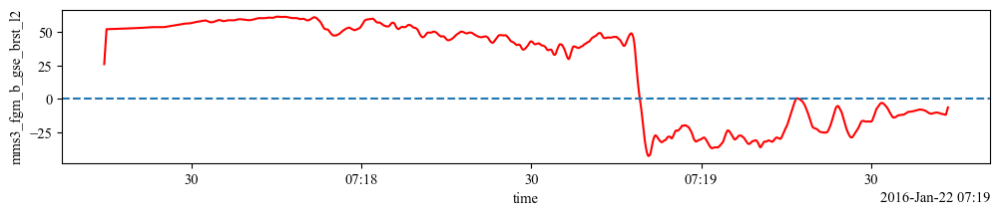

In [7]:
fgm_paths = search(f"{taistarttime}")['fgm']

b_fgm_paths =  [path for path in fgm_paths if 'fgm' in path]
num_paths_b = len(fgm_paths) # Number of elements in dis_moms_paths
paths_per_b = 4 # Number of paths to process in each iteration

# Loop through des_moms_paths and create pytplot objects
for i in range(0, num_paths_b, paths_per_b):
    paths_slice = b_fgm_paths[i:i+paths_per_b]
    bfield = pytplot.cdf_to_tplot(paths_slice)

b1 = pytplot.get_data('mms1_fgm_b_gse_brst_l2',xarray=True,dt=True)
r1 = pytplot.get_data('mms1_fgm_r_gse_brst_l2',xarray=True,dt=True).rename({'time': 'epoch'})
b2 = pytplot.get_data('mms2_fgm_b_gse_brst_l2',xarray=True,dt=True)
r2 = pytplot.get_data('mms2_fgm_r_gse_brst_l2',xarray=True,dt=True).rename({'time': 'epoch'})
b3 = pytplot.get_data('mms3_fgm_b_gse_brst_l2',xarray=True,dt=True)
r3 = pytplot.get_data('mms3_fgm_r_gse_brst_l2',xarray=True,dt=True).rename({'time': 'epoch'})
b4 = pytplot.get_data('mms4_fgm_b_gse_brst_l2',xarray=True,dt=True)
r4 = pytplot.get_data('mms4_fgm_r_gse_brst_l2',xarray=True,dt=True).rename({'time': 'epoch'})

mms1_bdataset = xr.merge([b1,r1]).sel(epoch=~xr.merge([b1,r1]).indexes['epoch'].duplicated())
mms2_bdataset = xr.merge([b2,r2]).sel(epoch=~xr.merge([b2,r2]).indexes['epoch'].duplicated())
mms3_bdataset = xr.merge([b3,r3]).sel(epoch=~xr.merge([b3,r3]).indexes['epoch'].duplicated())
mms4_bdataset = xr.merge([b4,r4]).sel(epoch=~xr.merge([b4,r4]).indexes['epoch'].duplicated())
 
xr.apply_ufunc(convolve,mms3_bdataset.mms3_fgm_b_gse_brst_l2.isel(v_dim=2),kwargs={'window_size': 100}).plot(figsize=(12,2),c='r')
plt.axhline(y=0,ls='--')
plt.show()

In [8]:
fgm_paths

['D:\\hallsim\\MMS\\pydata\\trial\\Phase1a\\mms1_fgm_brst_l2_20160122071714_v4.18.0.cdf',
 'D:\\hallsim\\MMS\\pydata\\trial\\Phase1a\\mms2_fgm_brst_l2_20160122071714_v4.18.0.cdf',
 'D:\\hallsim\\MMS\\pydata\\trial\\Phase1a\\mms3_fgm_brst_l2_20160122071714_v4.18.0.cdf',
 'D:\\hallsim\\MMS\\pydata\\trial\\Phase1a\\mms4_fgm_brst_l2_20160122071714_v4.18.0.cdf']

# For interpolation, chooes MMS3 Electron dataset

In [9]:
des_fpi_paths = search(f"{taistarttime}")['fpi']
des_moms_paths =  [path for path in des_fpi_paths if 'des-moms' in path]
num_paths_e = len(des_moms_paths) # Number of elements in dis_moms_paths
paths_per_e = 4 # Number of paths to process in each iteration

# Loop through des_moms_paths and create pytplot objects
for i in range(0, num_paths_e, paths_per_e):
    paths_slice = des_moms_paths[i:i+paths_per_e]
    plasma = pytplot.cdf_to_tplot(paths_slice)
    
EE1 = pytplot.get_data(
    'mms3_des_energyspectr_omni_brst',
    xarray=True, metadata=False, dt=True, units=True
).rename({'v_dim': 'e_dim'})

PA_low = pytplot.get_data(
    'mms3_des_pitchangdist_lowen_brst',
    xarray=True, metadata=False, dt=True, units=True
).rename({'v_dim': 'pa_low_e_dim'})

PA_mid = pytplot.get_data(
    'mms3_des_pitchangdist_miden_brst',
    xarray=True, metadata=False, dt=True, units=True
).rename({'v_dim': 'pa_mid_e_dim'})

PA_high = pytplot.get_data(
    'mms3_des_pitchangdist_highen_brst',
    xarray=True, metadata=False, dt=True, units=True
).rename({'v_dim': 'pa_high_e_dim'})

def rename_aux(da, mapping):
    present = {k: v for k, v in mapping.items() if (k in da.coords or k in da.variables)}
    if present:
        da = da.rename(present)
    return da

EE1 = rename_aux(EE1, {
    'v': 'espec_v',
    'spec_bins': 'spec_bins'
})

PA_low = rename_aux(PA_low, {
    'v': 'pa_low_v',
    'spec_bins': 'pa_low_spec_bins'
})

PA_mid = rename_aux(PA_mid, {
    'v': 'pa_mid_v',
    'spec_bins': 'pa_mid_spec_bins'
})

PA_high = rename_aux(PA_high, {
    'v': 'pa_high_v',
    'spec_bins': 'pa_high_spec_bins'
})
EN1 = pytplot.get_data('mms3_des_numberdensity_brst',xarray=True,dt=True)
EV1 = pytplot.get_data('mms3_des_bulkv_gse_brst',xarray=True,dt=True)
ET1 = pytplot.get_data('mms3_des_temppara_brst',xarray=True,dt=True)
ETP1 = pytplot.get_data('mms3_des_tempperp_brst',xarray=True,dt=True)
mms3_edataset = xr.merge([EE1,EN1,EV1,ET1,ETP1,PA_low,PA_mid,PA_high])
uniform_time_series = pd.date_range(start= mms3_edataset.time.values.min(), 
                                    end= mms3_edataset.time.values.max(), freq='30ms').tz_localize('UTC').values
electron_interp = mms3_edataset.interp(time=uniform_time_series,method="linear",kwargs={"fill_value": "extrapolate"})
mms1i_bdataset = mms1_bdataset.interp_like(electron_interp,method='linear',kwargs={"fill_value": "extrapolate"})
mms2i_bdataset = mms2_bdataset.interp_like(electron_interp,method='linear',kwargs={"fill_value": "extrapolate"})
mms3i_bdataset = mms3_bdataset.interp_like(electron_interp,method='linear',kwargs={"fill_value": "extrapolate"})
mms4i_bdataset = mms4_bdataset.interp_like(electron_interp,method='linear',kwargs={"fill_value": "extrapolate"})

mms1i_brdataset = mms1i_bdataset.interp(epoch=electron_interp.time,method="linear",kwargs={"fill_value": "extrapolate"}) 
mms2i_brdataset = mms2i_bdataset.interp(epoch=electron_interp.time,method="linear",kwargs={"fill_value": "extrapolate"}) 
mms3i_brdataset = mms3i_bdataset.interp(epoch=electron_interp.time,method="linear",kwargs={"fill_value": "extrapolate"}) 
mms4i_brdataset = mms4i_bdataset.interp(epoch=electron_interp.time,method="linear",kwargs={"fill_value": "extrapolate"})

In [10]:
vidatasets = {}          # DIS ion distributions
vedatasets = {}          # DES electron distributions

fpi_paths = search(str(taistarttime))["fpi"]

for sc in ["mms1", "mms2", "mms3", "mms4"]:

    for species, destination in [
        ("dis", vidatasets),
        ("des", vedatasets),
    ]:
        paths = [
            path
            for path in fpi_paths
            if f"{species}-dist" in os.path.basename(path)
            and sc in os.path.basename(path)
        ]

        if not paths:
            print(f"No {species.upper()} distribution files for {sc}")
            continue

        variable_name = f"{sc}_{species}_dist_brst"

        try:
            pytplot.cdf_to_tplot(paths)

            data_array = pytplot.get_data(
                variable_name,
                xarray=True,
                dt=True,
                units=True,
            )

            if data_array is None:
                print(f"{variable_name} was not loaded")
                continue

            destination[sc] = data_array.to_dataset(
                name=variable_name
            )

            print(
                f"Loaded {variable_name}: "
                f"shape={data_array.shape}"
            )

        except Exception as error:
            print(
                f"Could not load {variable_name}: {error}"
            )

Loaded mms1_dis_dist_brst: shape=(1000, 32, 16, 32)
Loaded mms1_des_dist_brst: shape=(5000, 32, 16, 32)
Loaded mms2_dis_dist_brst: shape=(1000, 32, 16, 32)
Loaded mms2_des_dist_brst: shape=(5000, 32, 16, 32)
Loaded mms3_dis_dist_brst: shape=(1000, 32, 16, 32)
Loaded mms3_des_dist_brst: shape=(4999, 32, 16, 32)
Loaded mms4_dis_dist_brst: shape=(1000, 32, 16, 32)
Loaded mms4_des_dist_brst: shape=(5000, 32, 16, 32)


In [11]:
vedatasets_interp = {}  # interpolated electrons

target_time = electron_interp.time

for sc in ["mms1", "mms2", "mms3", "mms4"]:
    if sc in vedatasets:
        vedatasets_interp[sc] = vedatasets[sc].interp(
            time=target_time,
            method="linear",
            kwargs={"fill_value": "extrapolate"},
        )

In [13]:
vedatasets_interp['mms4']

<xarray.Dataset> Size: 658MB
Dimensions:             (v2_dim: 16, time: 4999, v1_dim: 32, v3_dim: 32)
Coordinates:
  * time                (time) datetime64[ns] 40kB 2016-01-22T07:17:14.029564...
    spec_bins           (v2_dim) float32 64B 5.625 16.88 28.12 ... 163.1 174.4
    v1                  (time, v1_dim) float64 1MB 0.8676 12.12 ... 345.0 356.3
    v2                  (v2_dim) float32 64B 5.625 16.88 28.12 ... 163.1 174.4
    v3                  (time, v3_dim) float64 1MB 11.95 15.31 ... 2.661e+04
Dimensions without coordinates: v2_dim, v1_dim, v3_dim
Data variables:
    mms4_des_dist_brst  (time, v1_dim, v2_dim, v3_dim) float64 655MB 2.056e-2...

In [15]:
vidatasets_interp = {}  # interpolated ions

target_time = electron_interp.time

for sc in ["mms1", "mms2", "mms3", "mms4"]:

    if sc in vidatasets:
        vidatasets_interp[sc] = vidatasets[sc].interp(
            time=target_time,
            method="linear",
            kwargs={"fill_value": "extrapolate"},
        )

In [16]:
vidatasets_interp['mms4']

<xarray.Dataset> Size: 658MB
Dimensions:             (v2_dim: 16, time: 4999, v1_dim: 32, v3_dim: 32)
Coordinates:
  * time                (time) datetime64[ns] 40kB 2016-01-22T07:17:14.029564...
    spec_bins           (v2_dim) float32 64B 5.625 16.88 28.12 ... 163.1 174.4
    v1                  (time, v1_dim) float64 1MB 1.926 13.18 ... 349.4 360.7
    v2                  (v2_dim) float32 64B 5.625 16.88 28.12 ... 163.1 174.4
    v3                  (time, v3_dim) float64 1MB 11.97 15.37 ... 2.277e+04
Dimensions without coordinates: v2_dim, v1_dim, v3_dim
Data variables:
    mms4_dis_dist_brst  (time, v1_dim, v2_dim, v3_dim) float64 655MB 0.0 ... 0.0

In [17]:
vedatasets_interp['mms4']

<xarray.Dataset> Size: 658MB
Dimensions:             (v2_dim: 16, time: 4999, v1_dim: 32, v3_dim: 32)
Coordinates:
  * time                (time) datetime64[ns] 40kB 2016-01-22T07:17:14.029564...
    spec_bins           (v2_dim) float32 64B 5.625 16.88 28.12 ... 163.1 174.4
    v1                  (time, v1_dim) float64 1MB 0.8676 12.12 ... 345.0 356.3
    v2                  (v2_dim) float32 64B 5.625 16.88 28.12 ... 163.1 174.4
    v3                  (time, v3_dim) float64 1MB 11.95 15.31 ... 2.661e+04
Dimensions without coordinates: v2_dim, v1_dim, v3_dim
Data variables:
    mms4_des_dist_brst  (time, v1_dim, v2_dim, v3_dim) float64 655MB 2.056e-2...

In [18]:
vidatasets = {}
vidatasets_interp = {}

fpi_paths = search(str(taistarttime))["fpi"]

for sc in ["mms1", "mms2", "mms3", "mms4"]:
    paths = [
        p for p in fpi_paths
        if "dis-dist" in os.path.basename(p)
        and sc in os.path.basename(p)
    ]

    if not paths:
        continue

    try:
        pytplot.cdf_to_tplot(paths)

        name = f"{sc}_dis_dist_brst"
        da = pytplot.get_data(
            name,
            xarray=True,
            dt=True,
            units=True
        )

        if da is not None:
            vidatasets[sc] = da.to_dataset(name=name)

    except Exception:
        continue
vidatasets_interp = {}
for sc in ['mms1', 'mms2', 'mms3', 'mms4']:
    vspace_ds_interp = vidatasets[sc].interp(
            time=electron_interp.time,
            method='linear',
            kwargs={"fill_value": "extrapolate"}
        )
    vidatasets_interp[sc] = vspace_ds_interp

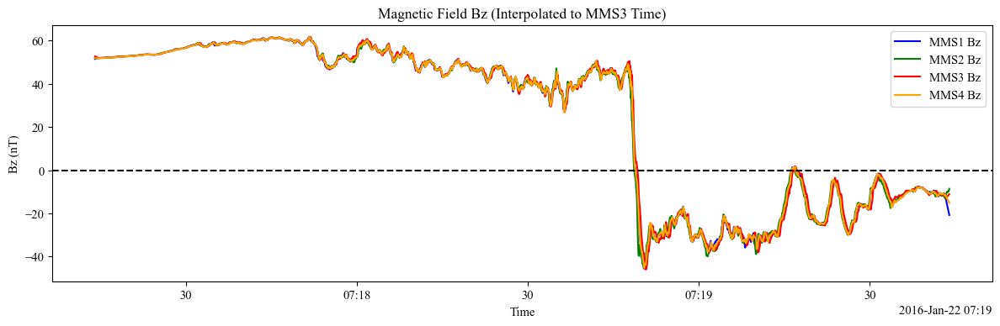

In [19]:
# Define color for each spacecraft
colors = {
    'mms1': 'blue',
    'mms2': 'green',
    'mms3': 'red',
    'mms4': 'orange'
}

# Create figure and axes
fig, ax = plt.subplots(figsize=(12, 4))

# Plot Bz for each spacecraft
for sc in ['mms1', 'mms2', 'mms3', 'mms4']:
    try:
        # Get the interpolated magnetic field dataset
        brdataset = globals()[f'{sc}i_brdataset']

        # Try to detect magnetic field variable name
        b_varname = [var for var in brdataset.data_vars if 'b_gse' in var.lower()]
        if not b_varname:
            raise ValueError(f"No magnetic field variable found in {sc} dataset.")
        b_var = b_varname[0]

        # Extract Bz (v_dim = 2)
        bz = brdataset[b_var].isel(v_dim=2)

        # Apply smoothing (moving average)
        bz_smoothed = xr.apply_ufunc(
            convolve, bz, kwargs={'window_size': 1}
        )

        # Plot Bz smoothed
        ax.plot(brdataset.time, bz_smoothed, label=f'{sc.upper()} Bz', color=colors[sc])

    except Exception as e:
        print(f"Error processing {sc}: {e}")
        continue

# Plot horizontal line at y = 0
ax.axhline(y=0, linestyle='--', color='black')

# Final plot formatting
ax.set_title("Magnetic Field Bz (Interpolated to MMS3 Time)")
ax.set_xlabel("Time")
ax.set_ylabel("Bz (nT)")
ax.legend()
plt.tight_layout()
plt.show()

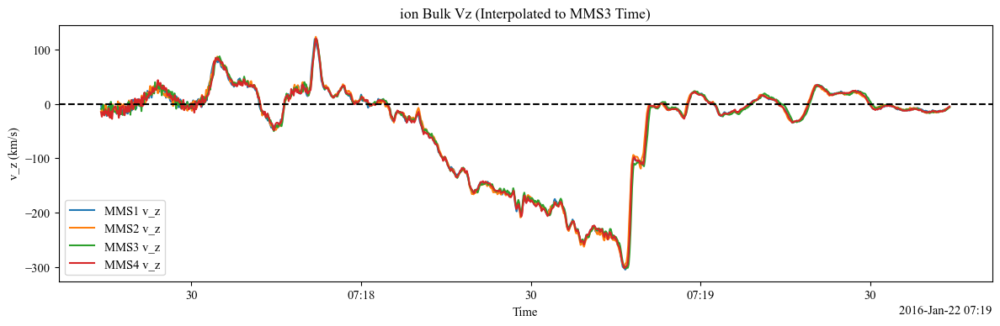

In [20]:
fig, ax = plt.subplots(figsize=(12, 4))  # One figure, shared axes
idatasets = {}         # to store raw merged datasets
idatasets_interp = {}  # to store interpolated datasets
paths_per_i = 4
dis_fpi_paths = search(f"{taistarttime}")['fpi']
dis_moms_paths =  [path for path in dis_fpi_paths if 'dis-moms' in path]
num_paths_i = len(dis_moms_paths)
paths_per_i = 4
for sc in ['mms1', 'mms2', 'mms3', 'mms4']:
   # 1. Get file paths for the current spacecraft
    # 2. Load data into pytplot
    for i in range(0, num_paths_i, paths_per_i):
        paths_slice = dis_moms_paths[i:i+paths_per_i]
        pytplot.cdf_to_tplot(paths_slice)

    # 3. Extract required variables from pytplot
    try:
        IE = pytplot.get_data(f'{sc}_dis_energyspectr_omni_brst', xarray=True, metadata=False, dt=True, units=True).rename({'v_dim': 'e_dim'})
        IN = pytplot.get_data(f'{sc}_dis_numberdensity_brst', xarray=True, metadata=False, dt=True, units=True)
        IV = pytplot.get_data(f'{sc}_dis_bulkv_gse_brst', xarray=True, metadata=False, dt=True, units=True)
        IT = pytplot.get_data(f'{sc}_dis_temppara_brst', xarray=True, metadata=False, dt=True, units=True)
        ITP = pytplot.get_data(f'{sc}_dis_tempperp_brst', xarray=True, metadata=False, dt=True, units=True)
        ITPP = pytplot.get_data(f'{sc}_dis_prestensor_gse_brst', xarray=True, metadata=False, dt=True, units=True)
    except Exception as e:
        print(f"Failed to load one or more variables for {sc}: {e}")
        continue

    # 4. Merge into one dataset
    idataset = xr.merge([IE, IN, IV, IT, ITP,ITPP])
    idatasets[sc] = idataset   # store the raw dataset
     # 5. Interpolate to edatasets_interp['mms3'].time
    try:
         idataset_interp = idataset.interp_like(electron_interp.time, method='linear', kwargs={"fill_value": "extrapolate"})
         idatasets_interp[sc] = idataset_interp  # store the interpolated dataset
    except Exception as e:
        print(f"Interpolation failed for {sc}: {e}")
        continue
         # 6. Plot v_z on the same axes
    try:
        time = electron_interp.time
        vz = idatasets_interp[sc][f'{sc}_dis_bulkv_gse_brst'].isel(v_dim=2)
        ax.plot(time, vz, label=f'{sc.upper()} v_z')
    except Exception as e:
        print(f"Failed to plot v_z for {sc}: {e}")
        continue

# 7. Finalize the plot
ax.axhline(y=0, linestyle='--', color='k')
ax.set_title("ion Bulk Vz (Interpolated to MMS3 Time)")
ax.set_ylabel("v_z (km/s)")
ax.set_xlabel("Time")
ax.legend()
plt.tight_layout()
plt.show()

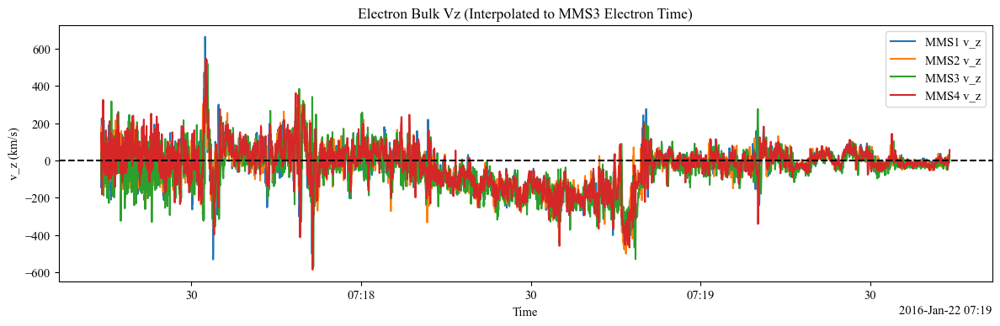

In [21]:

fig, ax = plt.subplots(figsize=(12, 4))

edatasets = {}
edatasets_interp = {}

paths_per_e = 4

def rename_aux(da, mapping):
    present = {k: v for k, v in mapping.items() if (k in da.coords or k in da.variables)}
    if present:
        da = da.rename(present)
    return da

# Search/load once
des_fpi_paths = search(f"{taistarttime}")['fpi']
des_moms_paths = [path for path in des_fpi_paths if 'des-moms' in path]
num_paths_e = len(des_moms_paths)

for i in range(0, num_paths_e, paths_per_e):
    paths_slice = des_moms_paths[i:i+paths_per_e]
    pytplot.cdf_to_tplot(paths_slice)

for sc in ['mms1', 'mms2', 'mms3', 'mms4']:
    try:
        # Main DES moments
        EE = pytplot.get_data(
            f'{sc}_des_energyspectr_omni_brst',
            xarray=True, metadata=False, dt=True, units=True
        ).rename({'v_dim': 'e_dim'})

        EN = pytplot.get_data(
            f'{sc}_des_numberdensity_brst',
            xarray=True, metadata=False, dt=True, units=True
        )

        EV = pytplot.get_data(
            f'{sc}_des_bulkv_gse_brst',
            xarray=True, metadata=False, dt=True, units=True
        )

        ET = pytplot.get_data(
            f'{sc}_des_temppara_brst',
            xarray=True, metadata=False, dt=True, units=True
        )

        ETP = pytplot.get_data(
            f'{sc}_des_tempperp_brst',
            xarray=True, metadata=False, dt=True, units=True
        )

        EPP = pytplot.get_data(
            f'{sc}_des_prestensor_gse_brst',
            xarray=True, metadata=False, dt=True, units=True
        )

        # PAD products
        PA_low = pytplot.get_data(
            f'{sc}_des_pitchangdist_lowen_brst',
            xarray=True, metadata=False, dt=True, units=True
        ).rename({'v_dim': 'pa_low_e_dim'})

        PA_mid = pytplot.get_data(
            f'{sc}_des_pitchangdist_miden_brst',
            xarray=True, metadata=False, dt=True, units=True
        ).rename({'v_dim': 'pa_mid_e_dim'})

        PA_high = pytplot.get_data(
            f'{sc}_des_pitchangdist_highen_brst',
            xarray=True, metadata=False, dt=True, units=True
        ).rename({'v_dim': 'pa_high_e_dim'})

        # Rename conflicting helper coords/vars
        EE = rename_aux(EE, {
            'v': 'espec_v',
            'spec_bins': 'spec_bins'
        })

        PA_low = rename_aux(PA_low, {
            'v': 'pa_low_v',
            'spec_bins': 'pa_low_spec_bins'
        })

        PA_mid = rename_aux(PA_mid, {
            'v': 'pa_mid_v',
            'spec_bins': 'pa_mid_spec_bins'
        })

        PA_high = rename_aux(PA_high, {
            'v': 'pa_high_v',
            'spec_bins': 'pa_high_spec_bins'
        })

    except Exception as e:
        print(f"Failed to load one or more variables for {sc}: {e}")
        continue

    try:
        edataset = xr.merge([
            EE, EN, EV, ET, ETP, EPP,
            PA_low, PA_mid, PA_high
        ])
        edatasets[sc] = edataset
    except Exception as e:
        print(f"Merge failed for {sc}: {e}")
        continue

    try:
        # Interpolate each spacecraft to MMS3 electron time grid
        edataset_interp = edataset.interp(
            time=electron_interp.time,
            method='linear',
            kwargs={"fill_value": "extrapolate"}
        )
        edatasets_interp[sc] = edataset_interp
    except Exception as e:
        print(f"Interpolation failed for {sc}: {e}")
        continue

    try:
        vz = edatasets_interp[sc][f'{sc}_des_bulkv_gse_brst'].isel(v_dim=2)
        ax.plot(electron_interp.time.values, vz.values, label=f'{sc.upper()} v_z')
    except Exception as e:
        print(f"Failed to plot v_z for {sc}: {e}")
        continue

ax.axhline(y=0, linestyle='--', color='k')
ax.set_title("Electron Bulk Vz (Interpolated to MMS3 Electron Time)")
ax.set_ylabel("v_z (km/s)")
ax.set_xlabel("Time")
ax.legend()
plt.tight_layout()
plt.show()

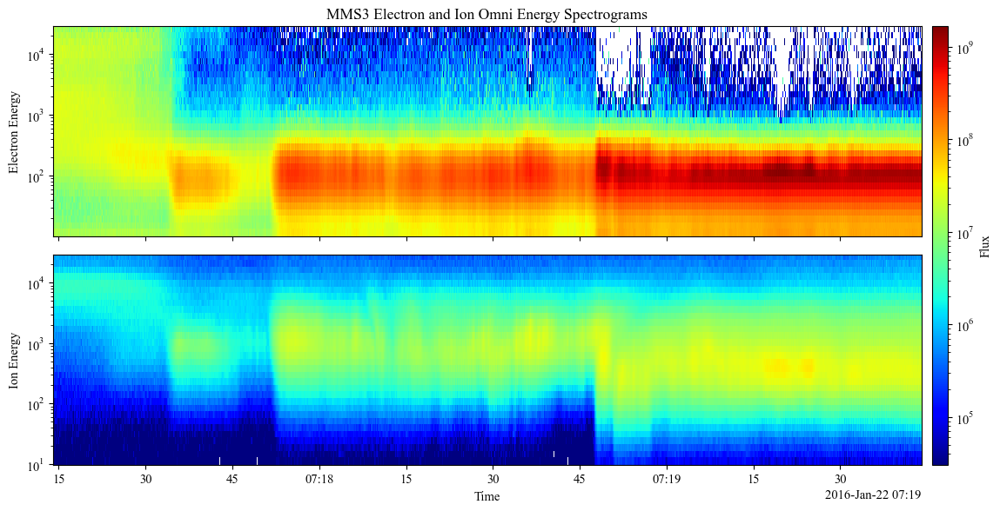

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# -----------------------------
# helper
# -----------------------------
def get_energy_spec_parts(da):
    # energy dimension
    if "espec_e_dim" in da.dims:
        e_dim = "espec_e_dim"
    elif "e_dim" in da.dims:
        e_dim = "e_dim"
    else:
        e_dim = [d for d in da.dims if d != "time"][0]

    # energy coordinate
    if "spec_bins" in da.coords:
        E = da["spec_bins"]
    elif hasattr(da, "spec_bins"):
        E = da.spec_bins
    elif "espec_v" in da.coords:
        E = da["espec_v"]
    else:
        raise ValueError("No energy coordinate found")

    if "time" in E.dims:
        E = E.mean("time", skipna=True)

    E = np.asarray(E.values, dtype=float)
    t = np.asarray(da["time"].values)
    F = np.asarray(da.transpose(e_dim, "time").values, dtype=float)

    good_E = np.isfinite(E) & (E > 0)
    E = E[good_E]
    F = F[good_E, :]
    F = np.where(np.isfinite(F) & (F > 0), F, np.nan)

    return t, E, F

# -----------------------------
# data
# -----------------------------
e_da = edatasets_interp['mms3'].mms3_des_energyspectr_omni_brst
i_da = idatasets_interp['mms3'].mms3_dis_energyspectr_omni_brst

t_e, E_e, F_e = get_energy_spec_parts(e_da)
t_i, E_i, F_i = get_energy_spec_parts(i_da)

# optional: common color scale
allvals = np.concatenate([F_e[np.isfinite(F_e)], F_i[np.isfinite(F_i)]])
vmin = np.nanpercentile(allvals, 5)
vmax = np.nanpercentile(allvals, 100)

# -----------------------------
# plot
# -----------------------------
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

m_e = ax[0].pcolormesh(
    t_e, E_e, F_e,
    shading="auto",
    cmap="jet",
    norm=mcolors.LogNorm(vmin=vmin, vmax=vmax),
    rasterized=True
)
ax[0].set_yscale("log")
ax[0].set_ylabel("Electron Energy")
ax[0].set_title("MMS3 Electron and Ion Omni Energy Spectrograms")

m_i = ax[1].pcolormesh(
    t_i, E_i, F_i,
    shading="auto",
    cmap="jet",
    norm=mcolors.LogNorm(vmin=vmin, vmax=vmax),
    rasterized=True
)
ax[1].set_yscale("log")
ax[1].set_ylabel("Ion Energy")
ax[1].set_xlabel("Time")

fig.tight_layout(rect=[0, 0, 0.90, 1])
fig.canvas.draw()

# shared colorbar
x_right = max(a.get_position().x1 for a in ax)
y0 = min(a.get_position().y0 for a in ax)
y1 = max(a.get_position().y1 for a in ax)

cax = fig.add_axes([x_right + 0.01, y0, 0.015, y1 - y0])
cbar = fig.colorbar(m_i, cax=cax)
cbar.set_label("Flux")

plt.show()

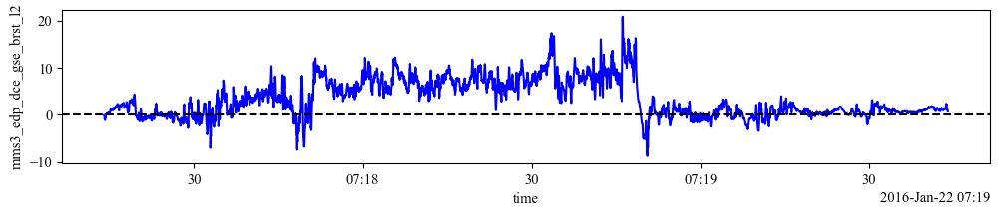

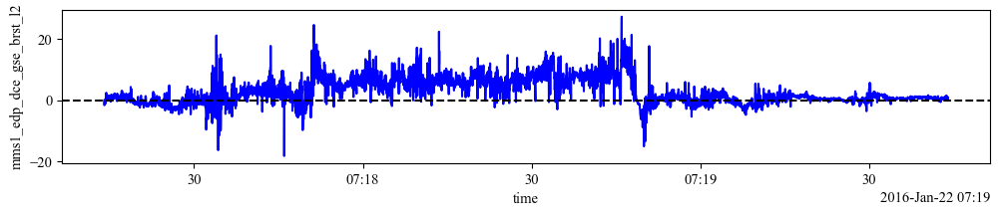

In [23]:
edp_paths = search(f"{taistarttime}")['edp']
E_edp_paths =  [path for path in edp_paths if 'edp' in path]
num_paths_E = len(edp_paths) # Number of elements in dis_moms_paths
paths_per_E = 4 # Number of paths to process in each iteration

# Loop through des_moms_paths and create pytplot objects
for i in range(0, num_paths_E, paths_per_E):
    paths_slice = E_edp_paths[i:i+paths_per_E]
    efield = pytplot.cdf_to_tplot(paths_slice)

mms1_Edataset = pytplot.get_data('mms1_edp_dce_gse_brst_l2',xarray=True,dt=True)
mms2_Edataset = pytplot.get_data('mms2_edp_dce_gse_brst_l2',xarray=True,dt=True)
mms3_Edataset = pytplot.get_data('mms3_edp_dce_gse_brst_l2',xarray=True,dt=True)
mms4_Edataset = pytplot.get_data('mms4_edp_dce_gse_brst_l2',xarray=True,dt=True)

mms1i_Edataset = mms1_Edataset.interp_like(electron_interp.time,method='linear', kwargs={"fill_value": "extrapolate"}) 
mms2i_Edataset = mms2_Edataset.interp_like(electron_interp.time,method='linear', kwargs={"fill_value": "extrapolate"}) 
mms3i_Edataset = mms3_Edataset.interp_like(electron_interp.time,method='linear', kwargs={"fill_value": "extrapolate"}) 
mms4i_Edataset = mms4_Edataset.interp_like(electron_interp.time,method='linear', kwargs={"fill_value": "extrapolate"}) 
xr.apply_ufunc(convolve, mms3i_Edataset.isel(v_dim=0), kwargs={'window_size': 5}).plot(figsize=(12, 2), color='b')
plt.axhline(y=0, ls='--',c='k')
mms1i_Edataset.isel(v_dim=0).plot(figsize=(12,2),c='b')
# Add a horizontal line at y=0
plt.axhline(y=0, ls='--',c='k')
plt.show()

In [24]:
def find(dataset,v_dim=None,LMN=None,d1=None, d2=None):
    # If d1 and d2 are not provided, use the dataset's time range
    if d1 is None:
        d1 = dataset.time.min().values  # Start from the first time entry
    if d2 is None:
        d2 = dataset.time.max().values  # End at the last time entry

    # If v_dim is provided, select based on v_dim
    if v_dim is not None:
        variable = dataset.sel(v_dim=v_dim, time=slice(d1, d2))
    # If LMN is provided, select based on LMN (assuming it's a predefined dimension in your dataset)
    elif LMN is not None:
        variable = dataset.sel(LMN=LMN, time=slice(d1, d2))
    else:
        raise ValueError("Either v_dim or LMN must be provided.")

    # Find where the variable crosses zero
    zero_crossing = np.where(np.diff(np.sign(variable)))[0]
    crossing_index = zero_crossing[0]  # Select the reversal time here
    time_before = variable.time.isel(time=crossing_index)
    time_after = variable.time.isel(time=crossing_index + 1)
    value_before = variable.isel(time=crossing_index)
    value_after = variable.isel(time=crossing_index + 1)

    # Choose the reversal time based on the absolute value comparison
    if np.abs(value_before) < np.abs(value_after):
        reversal_time = time_before
    else:
        reversal_time = time_after

    return reversal_time, crossing_index
Bz = find(mms3i_bdataset.mms3_fgm_b_gse_brst_l2,v_dim=2)
Bz[0].values,Bz[1]

(np.datetime64('2016-01-22T07:18:49.249564000'), np.int64(3174))

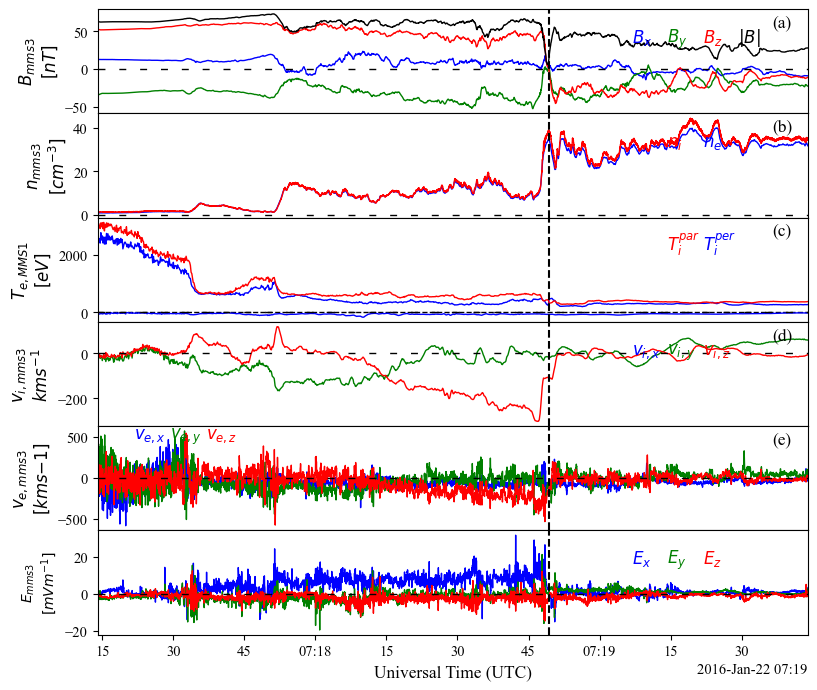

In [27]:
# Set figure size to fit A4 paper dimensions (in inches: A4 ~ 8.27 x 11.69 inches)
fig, axs = plt.subplots(6, 1, figsize=[8.27, 7], sharex=True, gridspec_kw={'hspace': 0})


# Plot data on the subplots
axs[0].text(0.95,0.95, '(a)', transform=axs[0].transAxes, fontsize=12.5, va='top') 
axs[1].text(0.95,0.95, '(b)', transform=axs[1].transAxes, fontsize=12.5, va='top') 
axs[2].text(0.95,0.95, '(c)', transform=axs[2].transAxes, fontsize=12.5, va='top') 
axs[3].text(0.95,0.95, '(d)', transform=axs[3].transAxes, fontsize=12.5, va='top') 
axs[4].text(0.95,0.95, '(e)', transform=axs[4].transAxes, fontsize=12.5, va='top') 

axs[0].plot(mms1i_bdataset.time.sel(time=slice(None)), mms1i_bdataset.mms1_fgm_b_gse_brst_l2.sel(v_dim=0), c='b', lw=1,label='Bx')
axs[0].plot(mms2i_bdataset.time.sel(time=slice(None)), mms2i_bdataset.mms2_fgm_b_gse_brst_l2.sel(v_dim=1), c='g', lw=1,label='By')
axs[0].plot(mms3i_bdataset.time.sel(time=slice(None)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(v_dim=2), c='r', lw=1,label='Bz')
axs[0].plot(mms4i_bdataset.time.sel(time=slice(None)), mms4i_bdataset.mms4_fgm_b_gse_brst_l2.sel(v_dim=3), c='k', lw=1,label='Bz')
axs[0].annotate(r'$\mathit{B_x}$', xy=(0.75, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axs[0].annotate(r'$\mathit{B_y}$', xy=(0.80, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs[0].annotate(r'$\mathit{B_z}$', xy=(0.85, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axs[0].annotate(r'$\mathit{|B|}$', xy=(0.90, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='k', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
#axs[0].axvspan(timestamps_of_sign_changes.time[0].values,timestamps_of_sign_changes.time[1].values, color='yellow', alpha=0.5)  # highlight the region 
axs[0].set_ylabel(r'$\mathbf{\mathit{B_{mms3}}}$' + '\n' + r'$\mathit{[nT]}$', fontsize=12)



axs[1].plot(electron_interp.time, idatasets_interp['mms3'].mms3_dis_numberdensity_brst, c='b', lw=1)
axs[1].plot(electron_interp.time, edatasets_interp['mms3'].mms3_des_numberdensity_brst, c='r', lw=1)
axs[1].set_ylabel(r'$\mathbf{\mathit{n_{mms3}}}$' + '\n' + r'$\mathit{[cm^{-3}]}$', fontsize=12)
axs[1].set_xlim(idatasets_interp['mms3'].time[0],idatasets_interp['mms3'].time[-1])
axs[1].annotate(r'$\mathit{n_i}$', xy=(0.80, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axs[1].annotate(r'$\mathit{n_e}$', xy=(0.85, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red


axs[2].plot(idatasets_interp['mms3'].time.sel(time=slice(None)), idatasets_interp['mms3'].mms3_dis_temppara_brst.sel(time=slice(None)), c='b', lw=1,label='Te,par')
axs[2].plot(idatasets_interp['mms3'].time.sel(time=slice(None)), idatasets_interp['mms3'].mms3_dis_tempperp_brst.sel(time=slice(None)), c='r', lw=1,label='Te,per')

axs[2].axhline(y=0, c='k', ls='--', lw=1)
axs[2].set_ylabel(r"$\mathbf{\mathit{T_{e,MMS1}}}$" + '\n' + r"$[\mathit{eV}]$", fontsize=12)
axs[2].annotate(r'$\mathit{T_{i}^{par}}$', xy=(0.80, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axs[2].annotate(r'$\mathit{T_{i}^{per}}$', xy=(0.85, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red

axs[2].plot(idatasets_interp['mms3'].time, idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(v_dim=0), c='b', lw=1,label='Vi,x')
axs[3].plot(idatasets_interp['mms3'].time, idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(v_dim=1), c='g', lw=1,label='Vi,y')
axs[3].plot(idatasets_interp['mms3'].time, idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(v_dim=2), c='r', lw=1,label='Vi,z')

axs[3].annotate(r'$\mathit{v_{i,x}}$', xy=(0.75, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axs[3].annotate(r'$\mathit{v_{i,y}}$', xy=(0.80, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs[3].annotate(r'$\mathit{v_{i,z}}$', xy=(0.85, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
#axs[2].axvspan(timestamps_of_sign_changes.time[0].values,timestamps_of_sign_changes.time[1].values, color='yellow', alpha=0.5)  # highlight the region 
axs[3].set_ylabel(r'$\mathbf{\mathit{v_{i,mms3}}}$' + '\n' + r'$\mathit{kms^{-1}}$', fontsize=12)
axs[3].set_xlim(idatasets_interp['mms3'].time[0],idatasets_interp['mms3'].time[-1])

axs[4].plot(idatasets_interp['mms3'].time.sel(time=slice(None)), edatasets_interp['mms3'].mms3_des_bulkv_gse_brst.sel(v_dim=0).sel(time=slice(None)), c='b', lw=1,label='Vi,x')
axs[4].plot(electron_interp.time.sel(time=slice(None)), edatasets_interp['mms3'].mms3_des_bulkv_gse_brst.sel(v_dim=1).sel(time=slice(None)), c='g', lw=1,label='Vi,y')
axs[4].plot(electron_interp.time.sel(time=slice(None)), edatasets_interp['mms3'].mms3_des_bulkv_gse_brst.sel(v_dim=2).sel(time=slice(None)), c='r', lw=1,label='Vi,z')
axs[4].annotate(r'$\mathit{v_{e,x}}$', xy=(0.05, 0.9), xycoords='axes fraction', style='italic',
                fontsize=12, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axs[4].annotate(r'$\mathit{v_{e,y}}$', xy=(0.10, 0.9), xycoords='axes fraction', style='italic',
                fontsize=12, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs[4].annotate(r'$\mathit{v_{e,z}}$', xy=(0.15, 0.9), xycoords='axes fraction', style='italic',
                fontsize=12, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axs[4].set_ylabel(r"$\mathbf{\mathit{v_{e,mms3}}}$" + '\n' + r"$[\mathit{kms{-1}]}$", fontsize=12)

axs[5].plot(electron_interp.time.sel(time=slice(None)), mms3i_Edataset.sel(v_dim=0), c='b', lw=1,label='Bx')
axs[5].plot(electron_interp.time.sel(time=slice(None)), mms3i_Edataset.sel(v_dim=1), c='g', lw=1,label='Ey')
axs[5].plot(electron_interp.time.sel(time=slice(None)), mms3i_Edataset.sel(v_dim=2), c='r', lw=1,label='Ez')
axs[5].annotate(r'$\mathit{E_x}$', xy=(0.75, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axs[5].annotate(r'$\mathit{E_y}$', xy=(0.80, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs[5].annotate(r'$\mathit{E_z}$', xy=(0.85, 0.7), xycoords='axes fraction', style='italic',
                fontsize=12, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axs[5].set_xlim(mms3i_bdataset.time[0],mms3i_bdataset.time[-1])

axs[5].set_ylabel(r'$\mathbf{\mathit{E_{mms3}}}$' + '\n' + r'$\mathit{[mVm^{-1}]}$', fontsize=12)
axs[5].yaxis.label.set_size(10)
axs[5].set_xlabel('Universal Time (UTC)', fontsize=12.5)

for ax in axs:
    ax.axvline(Bz[0].values,ls='--',c='k') #value obtained form below,change to MP crossing timestamp accordingly
    ax.axhline(y=0, c='k',  ls=(0, (5, 10)), lw=1)
    ax.set_xlim(mms3i_bdataset.time[0],mms3i_bdataset.time[-1])
plt.tight_layout(pad=1.0)
plt.savefig(os.path.join(output_folder, f"{taistarttime}_A.png"), dpi=1000)
plt.show()

In [28]:
mms3i_brdataset.time.isel(time=0).values,Bz[0].values,mms3i_brdataset.time.isel(time=-1).values

(np.datetime64('2016-01-22T07:17:14.029564000'),
 np.datetime64('2016-01-22T07:18:49.249564000'),
 np.datetime64('2016-01-22T07:19:43.969564000'))

In [29]:
#[del3,del4]= ['2015-09-23T16:59:14.003430000','2015-09-23T17:00:15']
[del3,del4]= ['2016-01-22T07:18:30', '2016-01-22T07:19:15']

In [30]:
Bz = find(mms3i_bdataset.mms3_fgm_b_gse_brst_l2,v_dim=2)
Bz[0].values,Bz[1]

(np.datetime64('2016-01-22T07:18:49.249564000'), np.int64(3174))

setting timestamps

In [31]:
fig, axs = plt.subplots(5, 1, figsize=[16, 12], sharex=True, gridspec_kw={'hspace': 0})

def convolve(data):
    return np.convolve(data, np.ones(5)/5, mode='same')

# ------------------------------------------------------------------
# Panel (a) – direction cosines (smoothed)
# ------------------------------------------------------------------
t = mdd(del3, del4)[5][1].time
data = mdd(del3, del4)[5][1]

axs[0].plot(t, xr.apply_ufunc(convolve, data.isel(dim2=2, dim1=0)), c='b', lw=1, label='ex')
axs[0].plot(t, xr.apply_ufunc(convolve, data.isel(dim2=2, dim1=1)), c='g', lw=1, label='ey')
axs[0].plot(t, xr.apply_ufunc(convolve, data.isel(dim2=2, dim1=2)), c='r', lw=1, label='ez')

axs[0].text(0.95, 0.95, '(a)', transform=axs[0].transAxes, fontsize=13, va='top')
axs[0].annotate(r'$\mathit{e_x}$', xy=(0.75, 0.9), xycoords='axes fraction',
                fontsize=20, color='b', style='italic')
axs[0].annotate(r'$\mathit{e_y}$', xy=(0.80, 0.9), xycoords='axes fraction',
                fontsize=20, color='g', style='italic')
axs[0].annotate(r'$\mathit{e_z}$', xy=(0.85, 0.9), xycoords='axes fraction',
                fontsize=20, color='r', style='italic')

axs[0].set_ylabel(r'$\mathbf{\mathit{MDD_{mms3}}}$' + '\n' + r'$\mathit{[nT]}$', fontsize=10)
axs[0].set_title('Direction cosines to the (GSE) axes for the maximum gradient direction (N) from MDDB',
                 fontsize=12)

# ------------------------------------------------------------------
# Panels (b)–(d) – raw components
# ------------------------------------------------------------------
axs[1].plot(t, data.isel(dim2=2, dim1=0), c='b', lw=1, label='Bl')
axs[2].plot(t, data.isel(dim2=2, dim1=1), c='g', lw=1, label='Bm')
axs[3].plot(t, data.isel(dim2=2, dim1=2), c='r', lw=1, label='Bn')

# ------------------------------------------------------------------
# Panel (e) – eigenvalue ratios
# ------------------------------------------------------------------
axs[4].set_title('eigenvalue ratios from MDDB', fontsize=12)
ev = mdd(del3, del4)[5][0]
axs[4].plot(ev.time, ev.isel(dim1=0), c='r', lw=1)
axs[4].plot(ev.time, ev.isel(dim1=1), c='g', lw=1)
axs[4].plot(ev.time, ev.isel(dim1=2), c='b', lw=1)

# ------------------------------------------------------------------
# Common x-axis limits & ticks (using your xticks helper)
# ------------------------------------------------------------------
t_start = t[0].values          # or data.time[0].values
t_end   = t[-1].values

major_ticks, minor_ticks, major_tick_labels = xticks(t_start, t_end)

for ax in axs:
    ax.set_xlim(t_start, t_end)

    # ticks
    ax.set_xticks(major_ticks)
    ax.set_xticks(minor_ticks, minor=True)
    ax.set_xticklabels(major_tick_labels, rotation=0, fontsize=9)

    # tick appearance
    ax.tick_params(axis='both', which='major', direction='in',
                   top=True, right=True, width=1, length=5, labelsize=10)
    ax.tick_params(axis='both', which='minor', direction='in',
                   top=True, right=True, width=1, length=3, labelsize=9)
    ax.tick_params(axis='x', which='major', pad=5)
    ax.tick_params(axis='x', which='minor', pad=1)

    # reference lines
    ax.axhline(y=0, c='k', ls=(0, (5, 10)), lw=1)
    ax.axvline(x=Bz[0].values, ls='--', c='r')                     # MP crossing
    ax.axvline(x=np.datetime64('2015-10-16T13:05:43.5'), ls='-', c='y')
    ax.axvline(x=np.datetime64('2015-10-16T13:05:48'),   ls='-', c='y')

# Only the bottom panel needs the x-label (optional)
axs[-1].set_xlabel('Time (UT)', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, f"{taistarttime}_mdd.png"), dpi=100, bbox_inches='tight')
plt.show()

25-Oct-26 16:36:09: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\1552415136.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=1.0,rect=[0, 0, 0.9, 1.0])



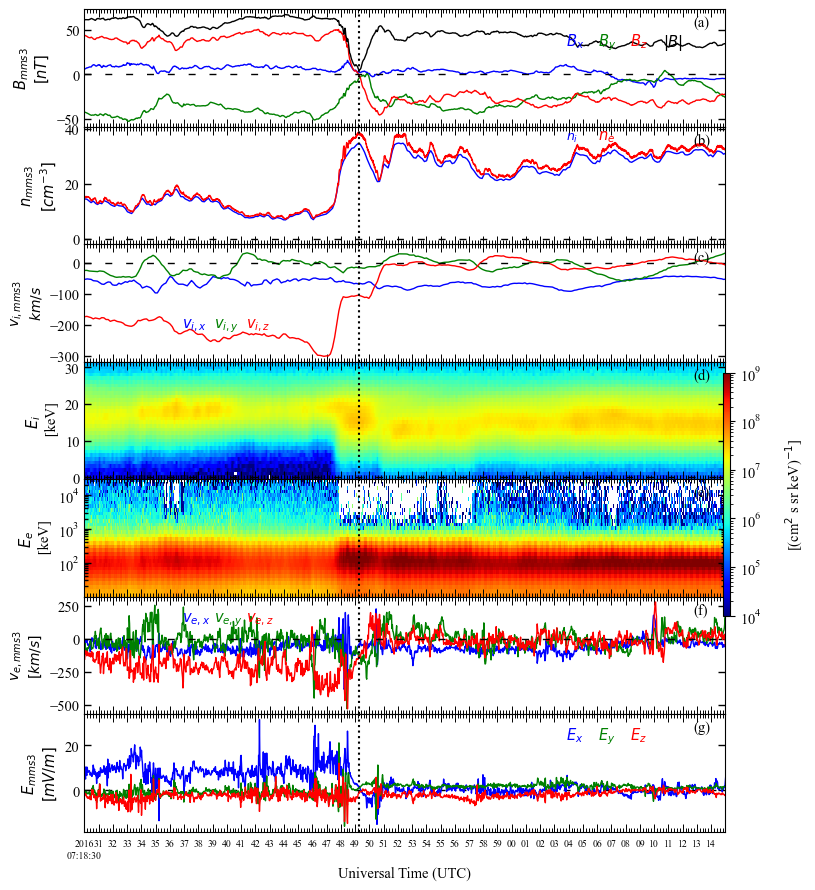

In [32]:
from matplotlib.ticker import LogLocator
figh, axsh = plt.subplots(7, 1, figsize=[8.27, 9], sharex=True, gridspec_kw={'hspace': 0,'wspace':0})
axsh[0].text(0.95,0.95, '(a)', transform=axsh[0].transAxes, fontsize=10.5, va='top') 
axsh[1].text(0.95,0.95, '(b)', transform=axsh[1].transAxes, fontsize=10.5, va='top') 
axsh[2].text(0.95,0.95, '(c)', transform=axsh[2].transAxes, fontsize=10.5, va='top') 
axsh[3].text(0.95,0.95, '(d)', transform=axsh[3].transAxes, fontsize=10.5, va='top') 
axsh[4].text(0.95,0.95, '(e)', transform=axsh[4].transAxes, fontsize=10.5, va='top') 
axsh[5].text(0.95,0.95, '(f)', transform=axsh[5].transAxes, fontsize=10.5, va='top') 
axsh[6].text(0.95,0.95, '(g)', transform=axsh[6].transAxes, fontsize=10.5, va='top') 


axsh[0].plot(mms3i_bdataset.time.sel(time=slice(del3,del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=0), c='b', lw=1,label='Bx')
axsh[0].plot(mms3i_bdataset.time.sel(time=slice(del3,del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=1), c='g', lw=1,label='By')
axsh[0].plot(mms3i_bdataset.time.sel(time=slice(del3,del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=2), c='r', lw=1,label='Bz')
axsh[0].plot(mms3i_bdataset.time.sel(time=slice(del3,del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3), c='k', lw=1,label='Bz')

axsh[0].annotate(r'$\mathit{B_x}$', xy=(0.75, 0.7), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axsh[0].annotate(r'$\mathit{B_y}$', xy=(0.80, 0.7), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axsh[0].annotate(r'$\mathit{B_z}$', xy=(0.85, 0.7), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axsh[0].annotate(r'$\mathit{|B|}$', xy=(0.9, 0.7), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='k', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axsh[0].set_ylabel(r'$\mathbf{\mathit{B_{mms3}}}$' + '\n' + r'$\mathit{[nT]}$', fontsize=10.5)


axsh[1].plot(idatasets_interp['mms3'].time.sel(time=slice(del3,del4)), 
            idatasets_interp['mms3'].mms3_dis_numberdensity_brst.sel(time=slice(del3,del4)), c='b', lw=1)
axsh[1].plot(edatasets_interp['mms3'].time.sel(time=slice(del3,del4)), 
            edatasets_interp['mms3'].mms3_des_numberdensity_brst.sel(time=slice(del3,del4)), c='r', lw=1) 
axsh[1].set_ylabel(r'$\mathbf{\mathit{n_{mms3}}}$' + '\n' + r'$\mathit{[cm^{-3}]}$', fontsize=10.5)
axsh[1].annotate(r'$\mathit{n_i}$', xy=(0.75, 0.9), xycoords='axes fraction', style='italic',
                fontsize=9, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axsh[1].annotate(r'$\mathit{n_e}$', xy=(0.80, 0.9), xycoords='axes fraction', style='italic',fontsize=10.5, color='red', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green

axsh[2].plot(idatasets_interp['mms3'].time.sel(time=slice(del3,del4)), 
            idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(time=slice(del3,del4)).sel(v_dim=0), c='b', lw=1)
axsh[2].plot(idatasets_interp['mms3'].time.sel(time=slice(del3,del4)), 
            idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(time=slice(del3,del4)).sel(v_dim=1), c='g', lw=1)
axsh[2].plot(idatasets_interp['mms3'].time.sel(time=slice(del3,del4)), 
            idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(time=slice(del3,del4)).sel(v_dim=2), c='r', lw=1)
axsh[2].set_ylabel(r'$\mathbf{\mathit{v_{i,mms3}}}$' + '\n' + r'$\mathit{km/s}$', fontsize=10)
axsh[2].annotate(r'$\mathit{v_{i,x}}$', xy=(0.15, 0.3), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axsh[2].annotate(r'$\mathit{v_{i,y}}$', xy=(0.20, 0.3), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axsh[2].annotate(r'$\mathit{v_{i,z}}$', xy=(0.25, 0.3), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
#axs[2].axvspan(timestamps_of_sign_changes.time[0].values,timestamps_of_sign_changes.time[1].values, color='yellow', alpha=0.5)  # highlight the region 
axsh[2].set_ylabel(r'$\mathbf{\mathit{v_{i,mms3}}}$' + '\n' + r'$\mathit{km/s}$', fontsize=10)



# Plot using pcolormesh with LogNorm
pcmi = axsh[3].pcolormesh(idatasets_interp['mms3'].mms3_dis_energyspectr_omni_brst.time.sel(time=slice(del3,del4)),
                     idatasets_interp['mms3'].mms3_dis_energyspectr_omni_brst.spec_bins.sel(time=slice(del3,del4)).e_dim,
                     idatasets_interp['mms3'].mms3_dis_energyspectr_omni_brst.sel(time=slice(del3,del4)).T, cmap='jet',
                     norm=mcolors.LogNorm(vmin=1e4, vmax=1e9), rasterized=True, shading="auto")

axsh[3].set_ylabel("$E_{i}$ \n [keV]",fontsize=10.5)



axsh[5].plot(edatasets_interp['mms3'].time.sel(time=slice(del3,del4)), edatasets_interp['mms3'].mms3_des_bulkv_gse_brst.sel(v_dim=0).sel(time=slice(del3,del4)), c='b', lw=1,label='Vi,x')
axsh[5].plot(edatasets_interp['mms3'].time.sel(time=slice(del3,del4)), edatasets_interp['mms3'].mms3_des_bulkv_gse_brst.sel(v_dim=1).sel(time=slice(del3,del4)), c='g', lw=1,label='Vi,y')
axsh[5].plot(edatasets_interp['mms3'].time.sel(time=slice(del3,del4)), edatasets_interp['mms3'].mms3_des_bulkv_gse_brst.sel(v_dim=2).sel(time=slice(del3,del4)), c='r', lw=1,label='Vi,z')
axsh[5].annotate(r'$\mathit{v_{e,x}}$', xy=(0.15, 0.8), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axsh[5].annotate(r'$\mathit{v_{e,y}}$', xy=(0.20, 0.8), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axsh[5].annotate(r'$\mathit{v_{e,z}}$', xy=(0.25, 0.8), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
axsh[5].set_ylabel(r"$\mathbf{\mathit{v_{e,mms3}}}$" + '\n' + r"$[\mathit{km/s}]$", fontsize=10)


# Plot using pcolormesh with LogNorm
pcme = axsh[4].pcolormesh(edatasets_interp['mms3'].mms3_des_energyspectr_omni_brst.time.sel(time=slice(del3,del4)),
                     edatasets_interp['mms3'].mms3_des_energyspectr_omni_brst.spec_bins.sel(time=slice(del3,del4)).mean(dim='time'),
                     edatasets_interp['mms3'].mms3_des_energyspectr_omni_brst.sel(time=slice(del3,del4)).T, cmap='jet',
                     norm=mcolors.LogNorm(vmin=1e4, vmax=1e9), rasterized=True, shading="auto")

axsh[4].set_ylabel("$E_{e}$ \n [keV]", fontsize=10.5)
axsh[4].set_yscale('log')

# Set y-axis ticks as powers of 10
ticks0 = [f'$10^{{{int(np.log10(value))}}}$' if value > 0 else '0' for value in
         mms3_edataset.mms3_des_energyspectr_omni_brst.spec_bins.sel(time=slice(del3,del4), e_dim=[0, 10, 20, 30])[0]]

# Create a new axis for the colorbar
cbar_ax = plt.axes([0.88, 0.31, 0.008, 0.27])  #  
# 92% of the width of the figure from the left edge.
#10% of the height of the figure from the bottom edge.
#2% of the width of the figure.
#80% of the height of the figure
cbar_ax.tick_params(labelsize=10.5, labelcolor='black')
# Add colorbar
cbar = plt.colorbar(pcmi, cax=cbar_ax)
cbar.set_label("\n" + "[(cm$^2$ s sr keV)$^{-1}$]", fontsize=10.5)
cbar.ax.yaxis.set_label_position('right')

# Set label and tick font size of the colorbar
cbar.ax.tick_params(labelsize=10.5)  # Set font size for ticks on the colorbar

for ax in axsh:
    ax.tick_params(axis='x', which='major', labelsize=10.5,size=6,width=0.7,pad=5,direction='in',top=True,bottom=True)
    ax.tick_params(axis='x', which='minor', labelsize=10.5,size=3,width=0.7,pad=1,direction='in',top=True,bottom=True)
    ax.tick_params(axis='y', which='major', direction='in',left=True,right=True,
                 width=1, length=5,labelsize=10.5)  # Adjust width and length as needed
    ax.tick_params(axis='y', which='minor', direction='in',left=True,right=True, 
                   width=1, length=3,labelsize=7)
    
    # Set major x-axis ticks
    ax.set_xticks(xticks(del3,del4)[0])

    # Set minor x-axis ticks
    ax.set_xticks(xticks(del3,del4)[1], minor=True)

   # Format x-axis tick labels using the custom function
    ax.set_xticklabels(xticks(del3,del4)[2], rotation=0, fontsize=7)
    ax.axvline(Bz[0].values,ls=':',c='k') #value obtained form below,change to MP crossing timestamp accordingly
    ax.axhline(y=0, c='k',  ls=(0, (5, 10)), lw=1)
    ax.set_xlim(mms3i_Edataset.time.sel(time=del3,method='nearest'),mms3i_Edataset.time.sel(time=del4,method='nearest'))
axsh[6].plot(mms3i_Edataset.time.sel(time=slice(del3,del4)), mms3i_Edataset.sel(v_dim=0,time=slice(del3,del4)), c='b', lw=1,label='Bx')
axsh[6].plot(mms3i_Edataset.time.sel(time=slice(del3,del4)), mms3i_Edataset.sel(v_dim=1,time=slice(del3,del4)), c='g', lw=1,label='By')
axsh[6].plot(mms3i_Edataset.time.sel(time=slice(del3,del4)), mms3i_Edataset.sel(v_dim=2,time=slice(del3,del4)), c='r', lw=1,label='Bz')
axsh[6].annotate(r'$\mathit{E_x}$', xy=(0.75, 0.8), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
axsh[6].annotate(r'$\mathit{E_y}$', xy=(0.80, 0.8), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axsh[6].annotate(r'$\mathit{E_z}$', xy=(0.85, 0.8), xycoords='axes fraction', style='italic',
                fontsize=10.5, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red

#axs[0].axvspan(timestamps_of_sign_changes.time[0].values,timestamps_of_sign_changes.time[1].values, color='yellow', alpha=0.5)  # highlight the region 
axsh[6].set_ylabel(r'$\mathbf{\mathit{E_{mms3}}}$' + '\n' + r'$\mathit{[mV/m]}$', fontsize=9)
axsh[6].yaxis.label.set_size(10.5)
axsh[6].set_xlabel('Universal Time (UTC)', fontsize=10.5)
plt.tight_layout(pad=1.0,rect=[0, 0, 0.9, 1.0])
plt.savefig(os.path.join(output_folder, f"{taistarttime}_B.png"), dpi=600)
plt.show()

0 8
2 9
-30 -21
-28 -21
-30 -21


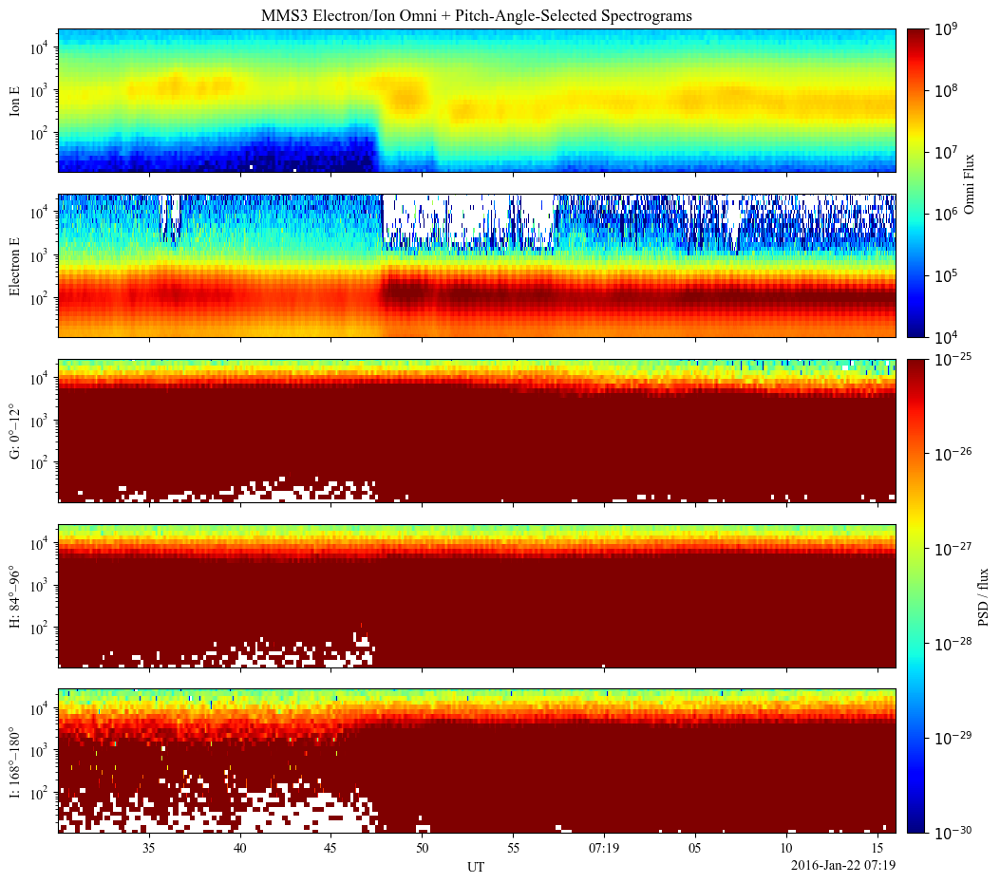

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# =========================================================
# choose exact colorbar tick range as powers of 10
# =========================================================
def set_cbar_log_ticks(cbar, start_exp, end_exp):
    ticks = 10.0 ** np.arange(start_exp, end_exp + 1)
    labels = [fr'$10^{{{k}}}$' for k in range(start_exp, end_exp + 1)]
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)
    cbar.minorticks_off()
    cbar.ax.tick_params(labelsize=10.5, labelcolor='black')


def scaled_log_limits(vals, frac=0):
    vals = vals[np.isfinite(vals) & (vals > 0)]
    log_min = int(round(np.log10(vals.min())))
    log_max = int(round(np.log10(vals.max())))
    print(log_min, log_max)

    vmin = 10 ** log_min
    vmax = 10 ** log_max
    return vmin, vmax


# =========================================================
# helpers for omni spectrograms
# =========================================================
def get_omni_parts(da):
    if "espec_e_dim" in da.dims:
        e_dim = "espec_e_dim"
    elif "e_dim" in da.dims:
        e_dim = "e_dim"
    else:
        e_dim = [d for d in da.dims if d != "time"][0]

    if "spec_bins" in da.coords:
        E = da["spec_bins"]
    elif hasattr(da, "spec_bins"):
        E = da.spec_bins
    elif "espec_v" in da.coords:
        E = da["espec_v"]
    else:
        raise ValueError("No energy coordinate found for omni spectrogram")

    if "time" in E.dims:
        E = E.mean("time", skipna=True)

    E = np.asarray(E.values, dtype=float)
    t = np.asarray(da["time"].values)
    F = np.asarray(da.transpose(e_dim, "time").values, dtype=float)

    good_E = np.isfinite(E) & (E > 0)
    E = E[good_E]
    F = F[good_E, :]
    F = np.where(np.isfinite(F) & (F > 0), F, np.nan)

    vals = F[np.isfinite(F) & (F > 0)]
    vmin, vmax = scaled_log_limits(vals)
    return t, E, F, vmin, vmax


def plot_omni(ax, da, ylabel, title=None, cmap="jet"):
    t, E, F, vmin, vmax = get_omni_parts(da)

    m = ax.pcolormesh(
        t, E, F,
        shading="auto",
        cmap=cmap,
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e9),
        rasterized=True
    )
    ax.set_yscale("log")
    ax.set_ylim(np.nanmin(E[E > 0]), np.nanmax(E))
    ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title)
    return m


# =========================================================
# helpers for G/H/I from full distribution
# =========================================================
def pa_energy_time_spec(dist, pa_min, pa_max):
    pa = dist["spec_bins"]
    pa_dim = pa.dims[0]

    mask = (pa >= pa_min) & (pa <= pa_max)
    idx = np.where(mask.values)[0]

    if len(idx) == 0:
        center = 0.5 * (pa_min + pa_max)
        idx = [int(np.argmin(np.abs(pa.values - center)))]

    out = dist.isel({pa_dim: idx}).mean(dim=pa_dim, skipna=True)

    extra_dims = [d for d in out.dims if d not in ["time", "v3_dim"]]
    for d in extra_dims:
        out = out.mean(dim=d, skipna=True)

    return out


def plot_et_spec(ax, da, ylabel, cmap="jet"):
    t = np.asarray(da["time"].values)

    E = da["v3"]
    if "time" in E.dims:
        E = E.mean("time", skipna=True)
    E = np.asarray(E.values, dtype=float)

    F = np.asarray(da.transpose("v3_dim", "time").values, dtype=float)

    good_E = np.isfinite(E) & (E > 0)
    E = E[good_E]
    F = F[good_E, :]
    F = np.where(np.isfinite(F) & (F > 0), F, np.nan)

    vals = F[np.isfinite(F) & (F > 0)]
    vmin, vmax = scaled_log_limits(vals)

    m = ax.pcolormesh(
        t, E, F,
        shading="auto",
        cmap=cmap,
        norm=mcolors.LogNorm(vmin=1e-30, vmax=1e-25),
        rasterized=True
    )
    ax.set_yscale("log")
    ax.set_ylim(np.nanmin(E[E > 0]), np.nanmax(E))
    ax.set_ylabel(ylabel)
    return m


# =========================================================
# load data
# =========================================================
i_da = idatasets_interp['mms3'].mms3_dis_energyspectr_omni_brst
e_da = edatasets_interp['mms3'].mms3_des_energyspectr_omni_brst
dist = vidatasets_interp['mms3']['mms3_dis_dist_brst']

# optional: restrict time
i_da = i_da.sel(time=slice(del3, del4))
e_da = e_da.sel(time=slice(del3, del4))
dist = dist.sel(time=slice(del3, del4))

# G/H/I
G = pa_energy_time_spec(dist, 0, 12)
H = pa_energy_time_spec(dist, 84, 96)
I = pa_energy_time_spec(dist, 168, 180)


# =========================================================
# plot
# =========================================================
fig, ax = plt.subplots(5, 1, figsize=(12, 11), sharex=True)

# corrected labels
m0 = plot_omni(
    ax[0], i_da,
    ylabel="Ion E",
    title="MMS3 Electron/Ion Omni + Pitch-Angle-Selected Spectrograms"
)

m1 = plot_omni(ax[1], e_da, ylabel="Electron E")

mG = plot_et_spec(ax[2], G, "G: 0°–12°")
mH = plot_et_spec(ax[3], H, "H: 84°–96°")
mI = plot_et_spec(ax[4], I, "I: 168°–180°")

ax[4].set_xlabel("UT")
fig.subplots_adjust(right=0.86, hspace=0.15)
# ---------------- top colorbar (for ax[0] and ax[1]) ----------------

# colorbar for top two omni panels
x_right_top = max(ax[0].get_position().x1, ax[1].get_position().x1)
y0_top = min(ax[0].get_position().y0, ax[1].get_position().y0)
y1_top = max(ax[0].get_position().y1, ax[1].get_position().y1)

cax0 = fig.add_axes([x_right_top + 0.01, y0_top, 0.015, y1_top - y0_top])
cbar0 = fig.colorbar(m1, cax=cax0)
cbar0.set_label("Omni Flux")

ticks0 = 10.0 ** np.arange(4, 9+1)
labels0 = [fr'$10^{{{k}}}$' for k in range(4, 9+1)]

cbar0.set_ticks(ticks0)
cbar0.set_ticklabels(labels0)
cbar0.minorticks_off()
cbar0.ax.tick_params(labelsize=10.5, labelcolor='black')

# colorbar for G/H/I
# colorbar for G/H/I
x_right_bot = max(ax[2].get_position().x1, ax[3].get_position().x1, ax[4].get_position().x1)
y0_bot = min(ax[2].get_position().y0, ax[3].get_position().y0, ax[4].get_position().y0)
y1_bot = max(ax[2].get_position().y1, ax[3].get_position().y1, ax[4].get_position().y1)

cax1 = fig.add_axes([x_right_bot + 0.01, y0_bot, 0.015, y1_bot - y0_bot])
cbar1 = fig.colorbar(mI, cax=cax1)
cbar1.set_label("PSD / flux")

# choose exactly where ticks start and end
ticks1 = 10.0 ** np.arange(-30, -25+1)
labels1 = [rf'$10^{{{k}}}$' for k in range(-30, -25+1)]

cbar1.set_ticks(ticks1)
cbar1.set_ticklabels(labels1)

cbar1.minorticks_off()
cbar1.ax.tick_params(labelsize=10.5, labelcolor='black')
plt.show()

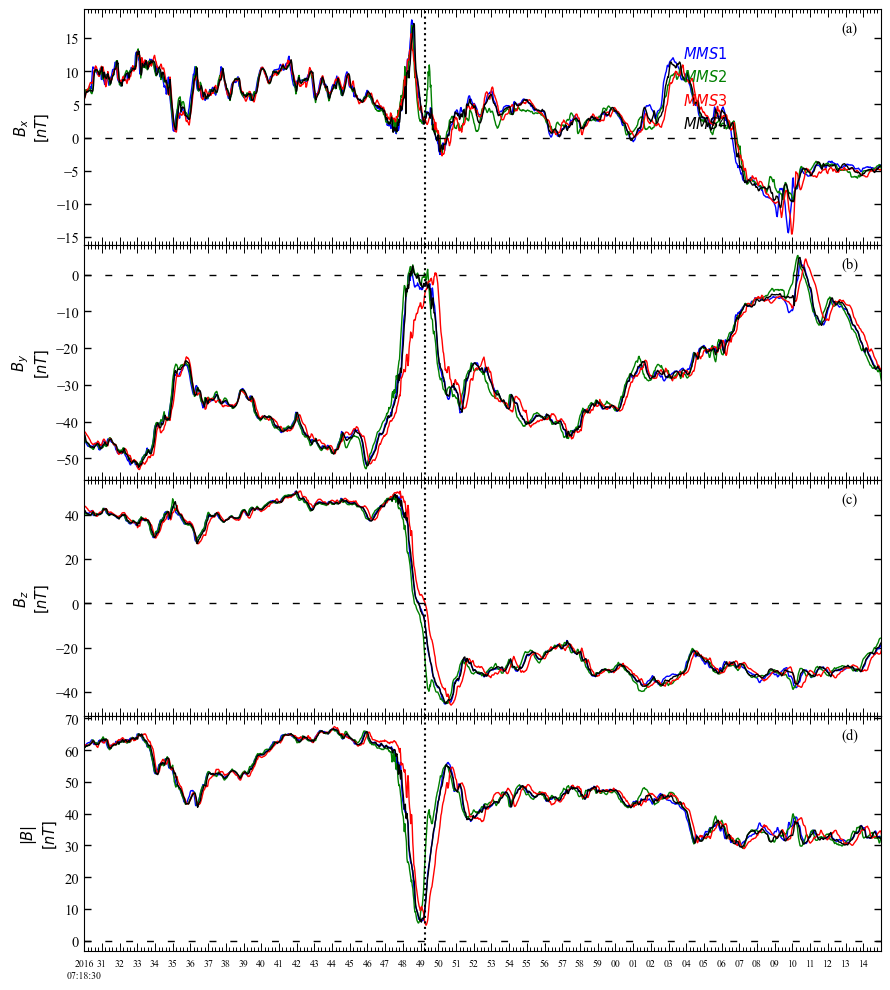

In [34]:
# Magnetic components and corresponding v_dim indices
components = ['x', 'y', 'z','mag']
v_dims = [0, 1, 2, 3]
colors = {
    'mms1': 'b',
    'mms2': 'g',
    'mms3': 'r',
    'mms4': 'k'
}
labels = {
    'x': r'$\mathbf{\mathit{B_{x}}}$' + '\n' + r'$\mathit{[nT]}$',
    'y': r'$\mathbf{\mathit{B_{y}}}$' + '\n' + r'$\mathit{[nT]}$',
    'z': r'$\mathbf{\mathit{B_{z}}}$' + '\n' + r'$\mathit{[nT]}$',
    'mag': r'$\mathbf{\mathit{|B|}}$' + '\n' + r'$\mathit{[nT]}$'
}

# Create subplots
figh, axsh = plt.subplots(4, 1, figsize=[10, 10], sharex=True, gridspec_kw={'hspace': 0, 'wspace': 0})

# Loop through components
for i, (comp, vdim) in enumerate(zip(components, v_dims)):
    ax = axsh[i]
    
    # Subplot label (a), (b), (c)
    ax.text(0.95, 0.95, f'({chr(97 + i)})', transform=ax.transAxes, fontsize=10.5, va='top')

    # Loop through spacecraft
    for sc in ['mms1', 'mms2', 'mms3', 'mms4']:
        dataset = globals()[f'{sc}i_bdataset']
        color = colors[sc]
        time_slice = dataset.time.sel(time=slice(del3, del4))
        data_slice = dataset[f'{sc}_fgm_b_gse_brst_l2'].sel(time=slice(del3, del4), v_dim=vdim)
        
        ax.plot(time_slice, data_slice, c=color, lw=1)

        # Annotate once per spacecraft on the top panel only
        if i == 0:
            ypos = 0.8 - 0.1 * list(colors.keys()).index(sc)
            ax.annotate(rf'$\mathit{{{sc.upper()}}}$', 
                        xy=(0.75, ypos), 
                        xycoords='axes fraction', 
                        style='italic',
                        fontsize=10.5, 
                        color=color, 
                        xytext=(1, -1), 
                        textcoords='offset points')

    ax.set_ylabel(labels[comp], fontsize=10.5)

for ax in axsh:
    ax.tick_params(axis='x', which='major', labelsize=10.5,size=6,width=0.7,pad=5,direction='in',top=True,bottom=True)
    ax.tick_params(axis='x', which='minor', labelsize=10.5,size=3,width=0.7,pad=1,direction='in',top=True,bottom=True)
    ax.tick_params(axis='y', which='major', direction='in',left=True,right=True,
                 width=1, length=5,labelsize=10.5)  # Adjust width and length as needed
    ax.tick_params(axis='y', which='minor', direction='in',left=True,right=True, 
                   width=1, length=3,labelsize=7)
    
    # Set major x-axis ticks
    ax.set_xticks(xticks(del3,del4)[0])

    # Set minor x-axis ticks
    ax.set_xticks(xticks(del3,del4)[1], minor=True)

   # Format x-axis tick labels using the custom function
    ax.set_xticklabels(xticks(del3,del4)[2], rotation=0, fontsize=7)
    ax.axvline(Bz[0].values,ls=':',c='k') #value obtained form below,change to MP crossing timestamp accordingly
    ax.axhline(y=0, c='k',  ls=(0, (5, 10)), lw=1)
    ax.set_xlim(edatasets_interp['mms3'].time.sel(time=del3,method='nearest'),edatasets_interp['mms3'].time.sel(time=del4,method='nearest'))
plt.tight_layout(pad=1.0,rect=[0, 0, 0.9, 1.0])
plt.savefig(os.path.join(output_folder, f"{taistarttime}_C.png"), dpi=600)
plt.show()


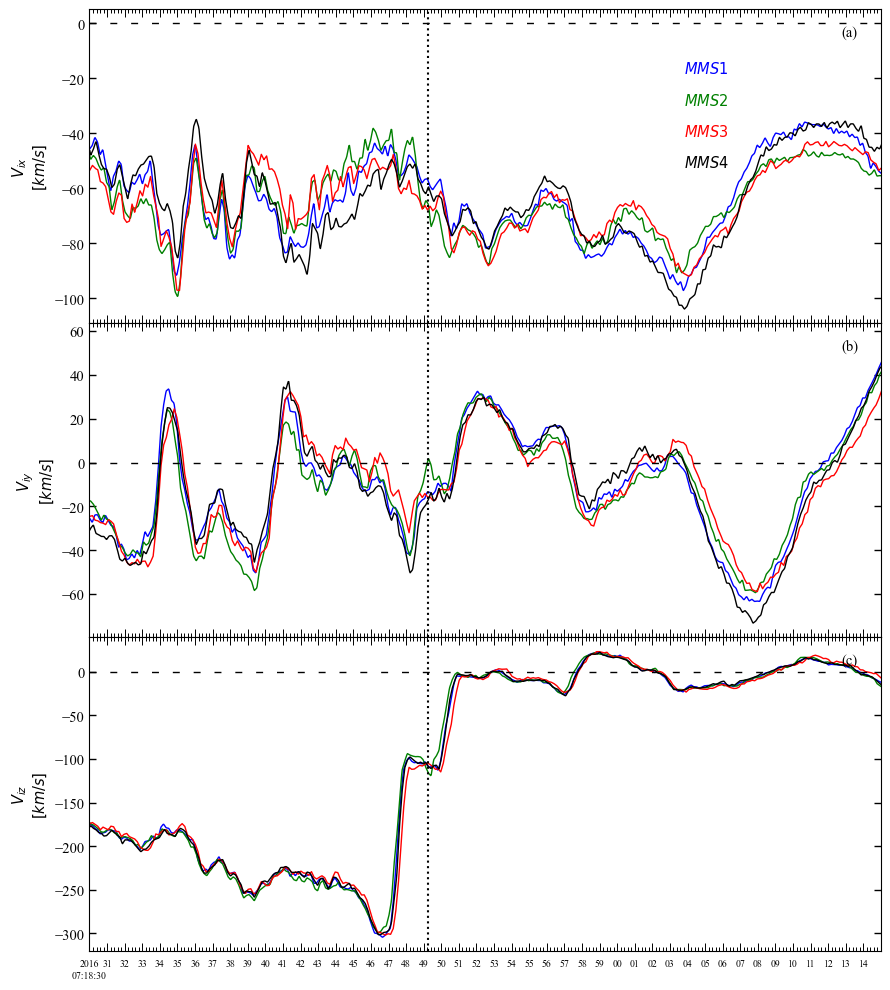

In [35]:
# Velocity components and their indices
components = ['x', 'y', 'z']
v_dims = [0, 1, 2]
colors = {
    'mms1': 'b',
    'mms2': 'g',
    'mms3': 'r',
    'mms4': 'k'
}
labels = {
    'x': r'$\mathbf{\mathit{V_{ix}}}$' + '\n' + r'$\mathit{[km/s]}$',
    'y': r'$\mathbf{\mathit{V_{iy}}}$' + '\n' + r'$\mathit{[km/s]}$',
    'z': r'$\mathbf{\mathit{V_{iz}}}$' + '\n' + r'$\mathit{[km/s]}$'
}

# Create subplots
figv, axsv = plt.subplots(3, 1, figsize=[10, 10], sharex=True, gridspec_kw={'hspace': 0, 'wspace': 0})

# Loop through components
for i, (comp, vdim) in enumerate(zip(components, v_dims)):
    ax = axsv[i]
    
    # Subplot label (a), (b), (c)
    ax.text(0.95, 0.95, f'({chr(97 + i)})', transform=ax.transAxes, fontsize=10.5, va='top')

    # Loop through spacecraft
    for sc in ['mms1', 'mms2', 'mms3', 'mms4']:
        try:
            dataset = idatasets_interp[sc]
            time_slice = dataset.time.sel(time=slice(del3, del4))
            data_slice = dataset[f'{sc}_dis_bulkv_gse_brst'].sel(time=slice(del3, del4), v_dim=vdim)

            ax.plot(time_slice, data_slice, c=colors[sc], lw=1)

            # Annotate once per spacecraft on the top panel only
            if i == 0:
                ypos = 0.8 - 0.1 * list(colors.keys()).index(sc)
                ax.annotate(rf'$\mathit{{{sc.upper()}}}$', 
                            xy=(0.75, ypos), 
                            xycoords='axes fraction',
                            style='italic',
                            fontsize=10.5, 
                            color=colors[sc], 
                            xytext=(1, -1), 
                            textcoords='offset points')
        except Exception as e:
            print(f"Failed to plot {comp} for {sc}: {e}")
            continue

    ax.set_ylabel(labels[comp], fontsize=10.5)

# Shared x-axis formatting
for ax in axsv:
    ax.tick_params(axis='x', which='major', labelsize=10.5, size=6, width=0.7, pad=5, direction='in', top=True, bottom=True)
    ax.tick_params(axis='x', which='minor', labelsize=10.5, size=3, width=0.7, pad=1, direction='in', top=True, bottom=True)
    ax.tick_params(axis='y', which='major', direction='in', left=True, right=True, width=1, length=5, labelsize=10.5)
    ax.tick_params(axis='y', which='minor', direction='in', left=True, right=True, width=1, length=3, labelsize=7)

    ax.set_xticks(xticks(del3, del4)[0])
    ax.set_xticks(xticks(del3, del4)[1], minor=True)
    ax.set_xticklabels(xticks(del3, del4)[2], rotation=0, fontsize=7)
    
    ax.axhline(y=0, c='k', ls=(0, (5, 10)), lw=1)
    ax.axvline(Bz[0].values, ls=':', c='k')  # Optional: MP crossing line
    ax.set_xlim(idatasets_interp['mms3'].time.sel(time=del3, method='nearest'),
                idatasets_interp['mms3'].time.sel(time=del4, method='nearest'))

plt.tight_layout(pad=1.0, rect=[0, 0, 0.9, 1.0])
plt.savefig(os.path.join(output_folder, f"{taistarttime}_D.png"), dpi=600)
plt.show()


In [36]:
v = idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(time=slice(del3,del4)).sel(v_dim=2).min().values
b = mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).min().values
[v,b]

[array(-302.00188564), array(4.87694418)]

In [37]:
def get_data(t1,t2):
    
    B1 = mms1i_brdataset.mms1_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    B2 = mms2i_brdataset.mms2_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    B3 = mms3i_brdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    B4 = mms4i_brdataset.mms4_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))

    R1 = mms1i_brdataset.mms1_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    R2 = mms2i_brdataset.mms2_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    R3 = mms3i_brdataset.mms3_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    R4 = mms4i_brdataset.mms4_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    
    BT_concat = xr.concat([B1,B2,B3,B4],dim='time')
    BS_concat = xr.concat([B1,B2,B3,B4],dim='spacecraft')
    RS_concat = xr.concat([R1,R2,R3,R4],dim='spacecraft')

    BS_mean = xr.apply_ufunc(np.mean,BS_concat,
                                    input_core_dims=[['spacecraft']],
                                    kwargs={"axis": -1})
    BS_cov = xr.apply_ufunc(np.cov,BS_mean,exclude_dims={'time'},
                                   input_core_dims=[['time','v_dim']],
                                   output_core_dims=[['dim1','v_dim']],
                                   kwargs={"rowvar": False})
    eigen = xr.apply_ufunc(np.linalg.eigh,BS_cov,
                           input_core_dims=[['dim1','v_dim']])
    #w = eigen.item().eigenvalues
    #v = eigen.item().eigenvectors
    
    return [BT_concat,BS_concat,RS_concat,BS_mean]

# MVA Analysis

__Single Spacecraft Analysis__: 
- MVAB is applied independently to the dataset from each individual spacecraft involved in the study. 
- Each spacecraft's dataset is analyzed separately to determine the minimum variance direction of the magnetic field.

In [38]:
def mva_b(mms):
    np_mean = np.mean(mms,axis = mms.get_axis_num("time"))
    np_mean = np.mean(mms, axis=0)
    vecavg = np.nanmean(np.nan_to_num(mms, nan=0.0), axis=0)
    xr_mean = mms.mean(dim='time')
    xr_mean = xr.apply_ufunc(
    # function to apply
    np.mean,
    # object with data to pass to function
    mms,
    # keyword arguments to pass to np.mean
    input_core_dims=[["time"]],  # core dimension for ds
    kwargs={"axis": -1})
    # Covariance Matrix Calculation
    np_cov = np.cov(mms, rowvar=False)
    np1_cov = np.cov(mms.T)
    
    
    mvamat = np.zeros((3,3))
    for i in range(3):
        for j in range(3):
            mvamat[i, j] = np.nanmean(np.nan_to_num(mms[:, i] * mms[:, j], nan=0.0)) - vecavg[i] * vecavg[j]
        
    xr_cov = xr.apply_ufunc(np.cov,mms,exclude_dims=({'time'}),input_core_dims=[['time','v_dim']],output_core_dims=[['dim1','v_dim']],kwargs={"rowvar": False})

    # Eigenvalue Decomposition
    w, v = np.linalg.eigh(mvamat, UPLO='U')
    [eigenvalues, eigenvectors] = np.linalg.eigh(np_cov)
    eigenvalues,eigenvectors = np.linalg.eigh(np.cov(mms.T))
    eigenvec = xr.apply_ufunc(np.linalg.eigh,xr_cov,input_core_dims=[['dim1','v_dim']])

    # Sorting to ensure descending order
    w_index = np.abs(w)
    idx = np.flip(np.argsort(w_index))
    w = np.sort(w)[::-1]
    v = v[:, idx]

    # Ensure maxvar direction is along +Z (for FAC system)
    if v[2, 0] < 0:
        v[:, 0] = - v[:, 0]
    if v[0,2] < 0:
        v[:,2] = - v[:, 2]

    # Rotate intermediate var direction if system is not Right Handed
    if v[0, 0] * (v[1, 1] * v[2, 2] - v[2, 1] * v[1, 2]) < 0:
        v[:,1] = -v[:,1]
    
    # Calculate ratios of sorted eigenvalues
    lambda_1_2 = w[0] / w[1]
    lambda_2_3 = w[1] / w[2]

    #if lambda_1_2 > 10 and lambda_2_3 > 2:
     #   print("Minimum variance direction (N) is adequately defined.", lambda_1_2,lambda_2_3)
        
   # else:
    #    print("Minimum variance direction (N) may not be adequately defined.", lambda_1_2,lambda_2_3)

    LMN = xr.Dataset({'eigenrat':xr.DataArray(np.array([lambda_1_2,lambda_2_3]),dims=['ratios']),
                      'eigenval':xr.DataArray(w,dims=['values']),
                      'eigenvec':xr.DataArray(v,dims=['vec','LMN'])})
    return [LMN,lambda_1_2,lambda_2_3]

In [39]:
# Run the find() function for each spacecraft
bz_findings = {
    'mms1': find(mms1i_brdataset.mms1_fgm_b_gse_brst_l2, v_dim=2, d1=del3, d2=del4),
    'mms2': find(mms2i_brdataset.mms2_fgm_b_gse_brst_l2, v_dim=2, d1=del3, d2=del4),
    'mms3': find(mms3i_brdataset.mms3_fgm_b_gse_brst_l2, v_dim=2, d1=del3, d2=del4),
    'mms4': find(mms4i_brdataset.mms4_fgm_b_gse_brst_l2, v_dim=2, d1=del3, d2=del4),
}

# Access the crossing time or index like this:
bz_crossing_times = {sc: bz_findings[sc][0] for sc in bz_findings}  # crossing time
bz_crossing_indices = {sc: bz_findings[sc][1] for sc in bz_findings}  # crossing index
Bz_index = bz_crossing_indices[sc]
bz_crossing_time = bz_crossing_times[sc]

In [40]:
bz_crossing_times['mms4']

<xarray.DataArray 'time' ()> Size: 8B
array('2016-01-22T07:18:48.889564000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 2016-01-22T07:18:48.889564
    epoch    datetime64[ns] 8B 2016-01-22T07:18:48.889564

Processing MMS1...


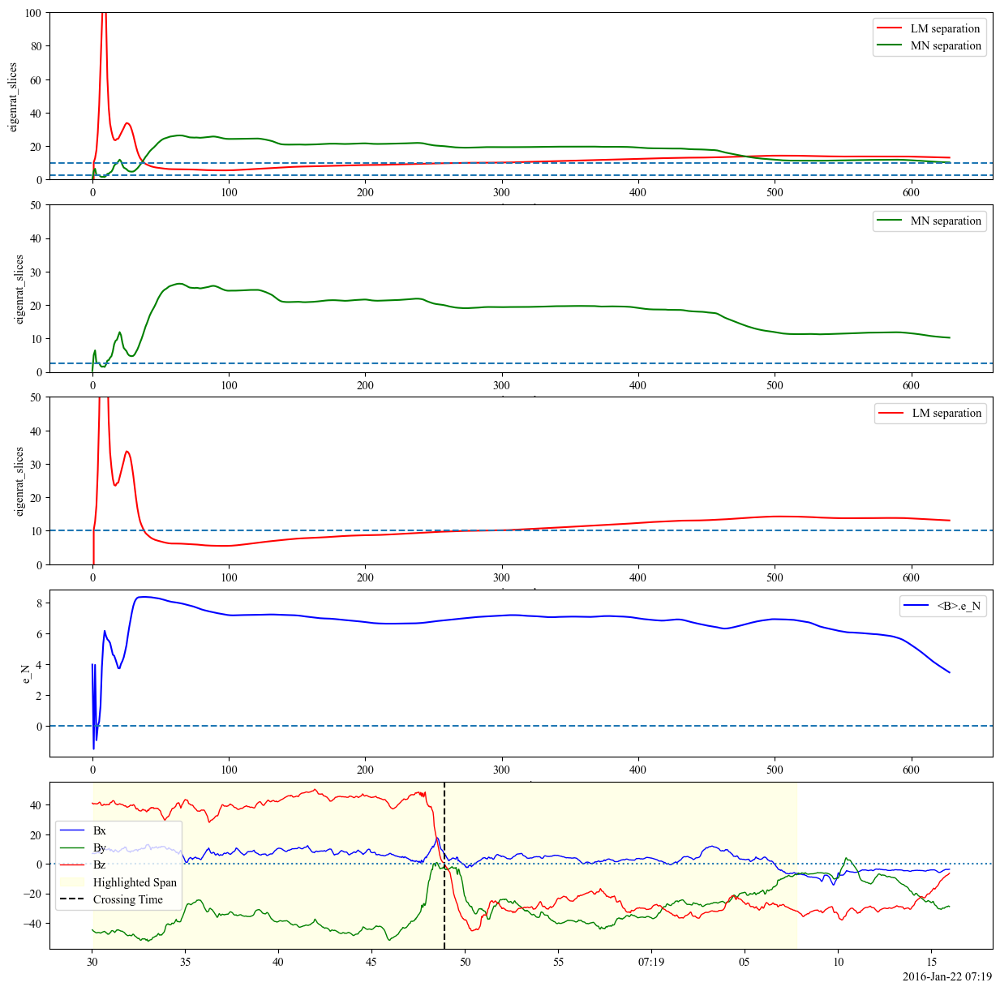

Processing MMS2...


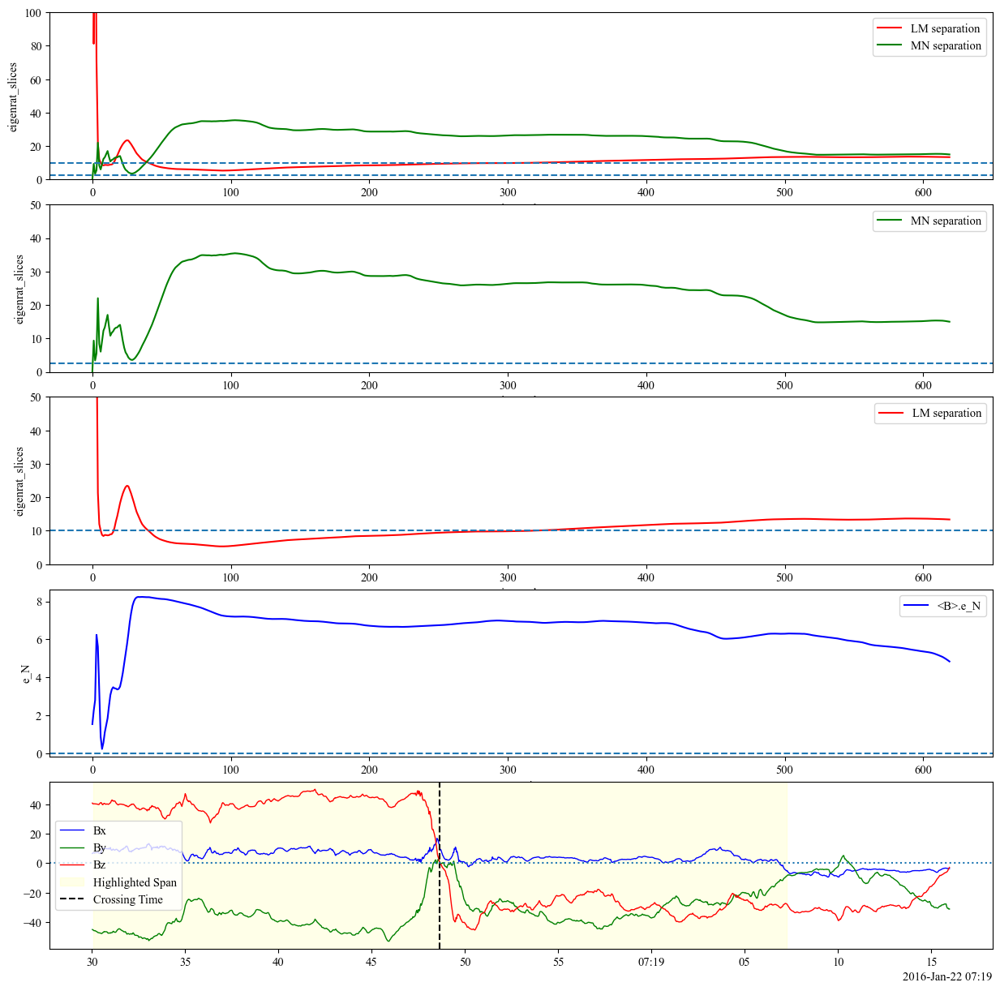

Processing MMS3...


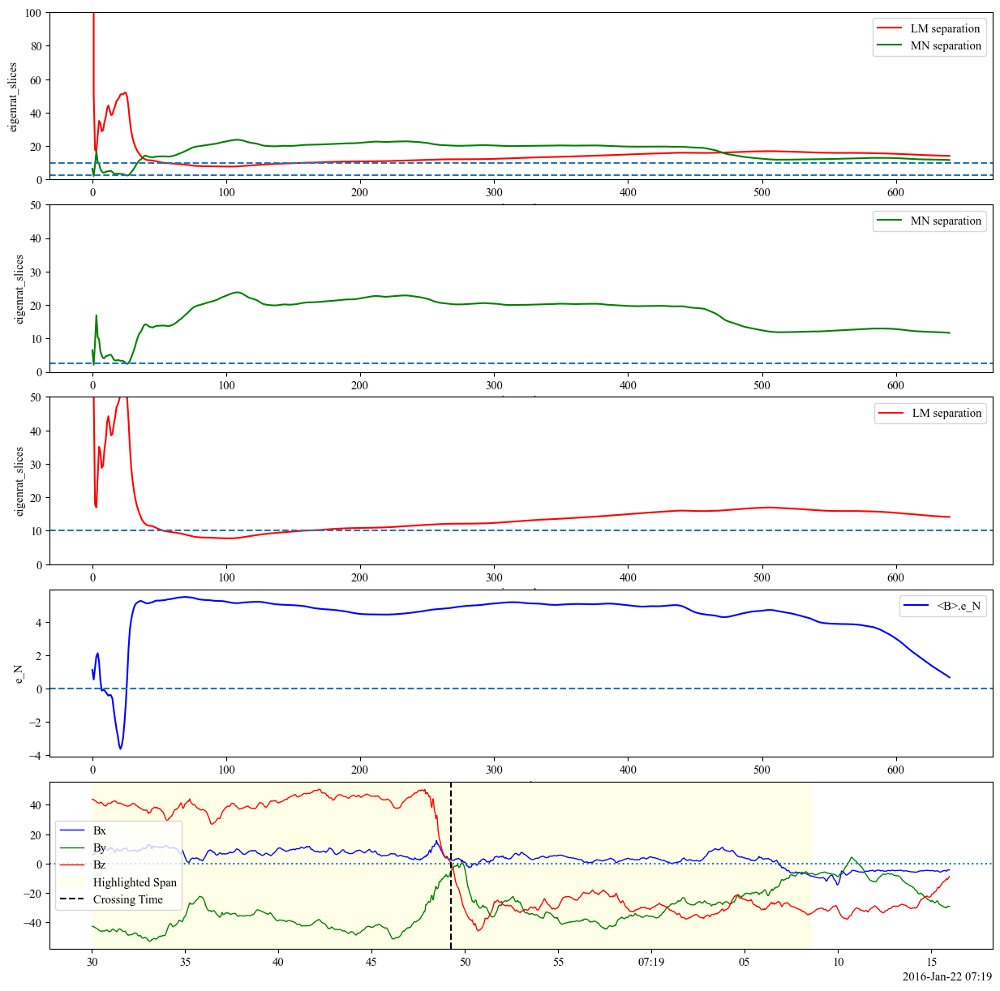

Processing MMS4...


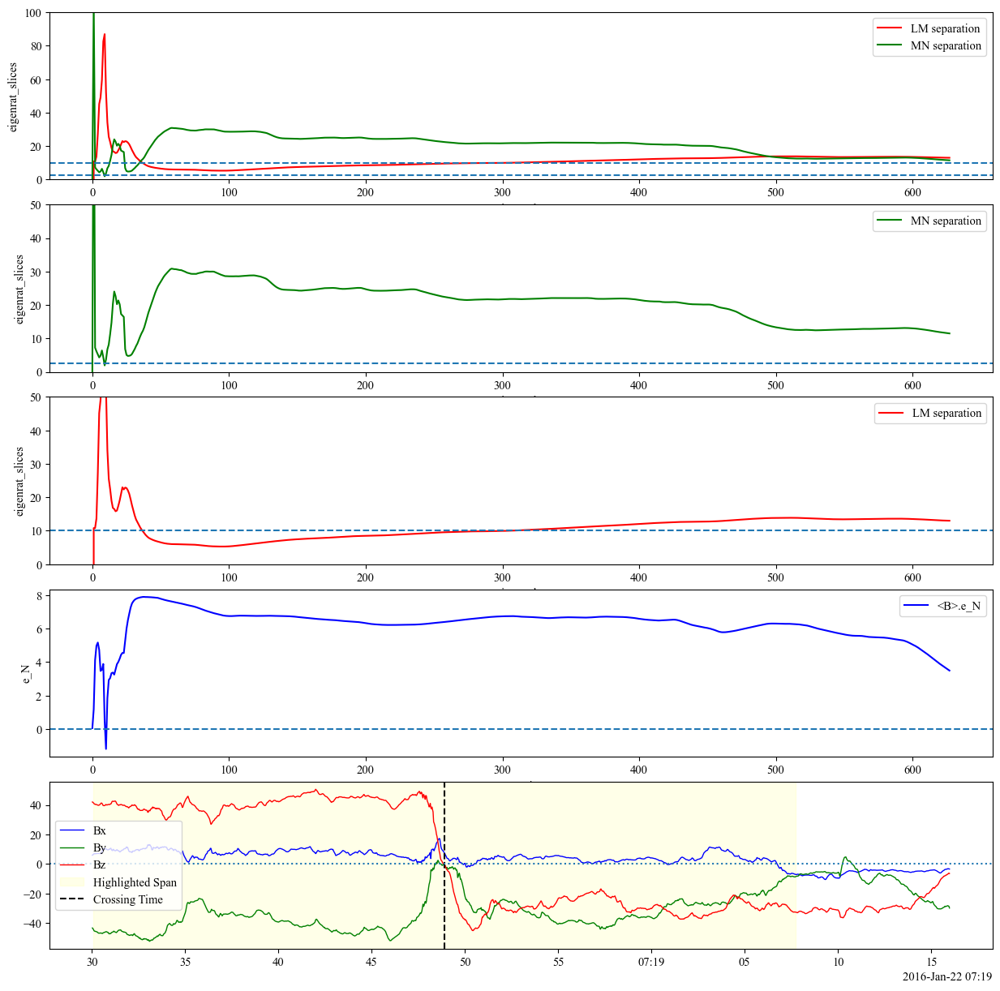

In [41]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

for sc in sc_list:
    print(f"Processing {sc.upper()}...")

    bdata = globals()[f"{sc}i_bdataset"]

    # Initialize lists for MVA results
    eigenrat_slices = []
    eigenval_slices = []
    mean_slices = []
    eigenvec_slices = []
    ndot_slices = []

    indices_data = []
    time_data = []
    index_data = []

    # Use the crossing index specific to this spacecraft
    start_index = bz_crossing_indices[sc]
    end_index = start_index + 2

    # Length of time dimension for bounds checking
    time_len = len(bdata[f"{sc}_fgm_b_gse_brst_l2"].time.sel(time=slice(del3, del4)))

    while True:
        if start_index <= 0 or end_index >= time_len:
            break

        time_slice = bdata[f"{sc}_fgm_b_gse_brst_l2"].time.sel(time=slice(del3, del4))
        start_time = time_slice.isel(time=start_index).values
        end_time = time_slice.isel(time=end_index).values

        B_sel = bdata[f"{sc}_fgm_b_gse_brst_l2"].sel(time=slice(del3, del4), v_dim=slice(0, 3)).isel(time=slice(start_index, end_index))
        mean = B_sel.mean(dim='time')
        LMN = mva_b(B_sel)[0]

        eigenrat_slices.append(LMN.eigenrat.values)
        eigenval_slices.append(LMN.eigenval.values)
        mean_slices.append(mean)
        eigenvec_slices.append(LMN.eigenvec.sel(LMN=2).values)
        indices_data.append([start_index, end_index])
        index_data.append(start_index)
        time_data.append([start_time, end_time])

        start_index -= 1
        end_index += 1

    nested_mva = xr.Dataset({
        'eigenrat_slices': (['intervals', 'ratios'], eigenrat_slices),
        'eigenval_slices': (['intervals', 'values'], eigenval_slices),
        'e_N': (['intervals', 'values'], eigenvec_slices),
        'B_av': (['intervals', 'values'], mean_slices),
    }, coords={
        'indices': (['intervals', 'range'], indices_data),
        'start_index': (['intervals'], index_data),
        'time': (['intervals', 'range'], time_data)
    })

    # Plotting
    fig, ax = plt.subplots(5, 1, figsize=(15, 15), sharex=False, gridspec_kw={'hspace': 0.15})
    
    nested_mva.eigenrat_slices.sel(ratios=0).plot(ax=ax[0], color='r', label='LM separation')
    nested_mva.eigenrat_slices.sel(ratios=1).plot(ax=ax[0], color='g', label='MN separation')
    ax[0].set_ylim(0, 100)
    ax[0].axhline(y=2.5, ls='--')
    ax[0].axhline(y=10, ls='--')
    ax[0].legend()

    nested_mva.eigenrat_slices.sel(ratios=1).plot(ax=ax[1], color='g', label='MN separation')
    ax[1].set_ylim(0, 50)
    ax[1].axhline(y=2.5, ls='--')
    ax[1].legend()

    nested_mva.eigenrat_slices.sel(ratios=0).plot(ax=ax[2], color='r', label='LM separation')
    ax[2].set_ylim(0, 50)
    ax[2].axhline(y=10, ls='--')
    ax[2].legend()

    xr.dot(nested_mva.e_N, nested_mva.B_av, dim='values').plot(ax=ax[3], color='b', label='<B>.e_N')
    ax[3].axhline(y=0, ls='--')
    ax[3].legend()
    ax[3].set_xlabel('Nest Size')

    # Plot Bx, By, Bz
    times = bdata.time.sel(time=slice(del3, del4))
    for i, color, lbl in zip(range(3), ['b', 'g', 'r'], ['Bx', 'By', 'Bz']):
        ax[4].plot(times, bdata[f"{sc}_fgm_b_gse_brst_l2"].sel(time=slice(del3, del4), v_dim=i), c=color, lw=1, label=lbl)

    ax[4].axvspan(nested_mva.time[-1][0].values, nested_mva.time[-1][1].values, color=(1, 1, 0.7), alpha=0.3, label='Highlighted Span')
     #Draw vertical line at crossing time
    crossing_time = bz_crossing_times[sc].values # This should be a numpy datetime64 or pandas Timestamp

    ax[4].axvline(x=crossing_time, color='k', linestyle='--', label='Crossing Time')

    ax[4].axhline(y=0, ls=':')
    ax[4].legend()

    # Save Figure
    fig.savefig(os.path.join(output_folder, f"{sc}_b{start_index}_{end_index}_E.png"), dpi=100)
    plt.show()


In [42]:
mms1=mva_b(mms1i_bdataset.
        mms1_fgm_b_gse_brst_l2.
        sel(time=slice(nested_mva.
                       isel(intervals=400).time[0],
                       nested_mva.isel(intervals=400).time[1])))[0]
mms2=mva_b(mms2i_bdataset.
        mms2_fgm_b_gse_brst_l2.
        sel(time=slice(nested_mva.
                       isel(intervals=400).time[0],
                       nested_mva.isel(intervals=400).time[1])))[0]
mms3=mva_b(mms3i_bdataset.
        mms3_fgm_b_gse_brst_l2.
        sel(time=slice(nested_mva.
                       isel(intervals=400).time[0],
                       nested_mva.isel(intervals=400).time[1])))[0]
mms4=mva_b(mms4i_bdataset.
        mms4_fgm_b_gse_brst_l2.
        sel(time=slice(nested_mva.
                       isel(intervals=400).time[0],
                       nested_mva.isel(intervals=400).time[1])))[0]


In [43]:
mms4

<xarray.Dataset> Size: 112B
Dimensions:   (ratios: 2, values: 3, vec: 3, LMN: 3)
Dimensions without coordinates: ratios, values, vec, LMN
Data variables:
    eigenrat  (ratios) float64 16B 12.06 21.41
    eigenval  (values) float64 24B 1.281e+03 106.2 4.96
    eigenvec  (vec, LMN) float64 72B 0.05881 -0.05699 ... -0.1032 -0.06447

In [44]:
mms2.eigenrat.values

array([11.81917923, 25.54852614])

In [45]:
mms3.eigenrat.values

array([14.82456344, 20.1033013 ])

In [46]:
mms4.eigenrat.values

array([12.06394917, 21.41025433])

25-Oct-26 16:39:07: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\1980767184.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=1.0, rect=[0, 0, 0.9, 1.0])



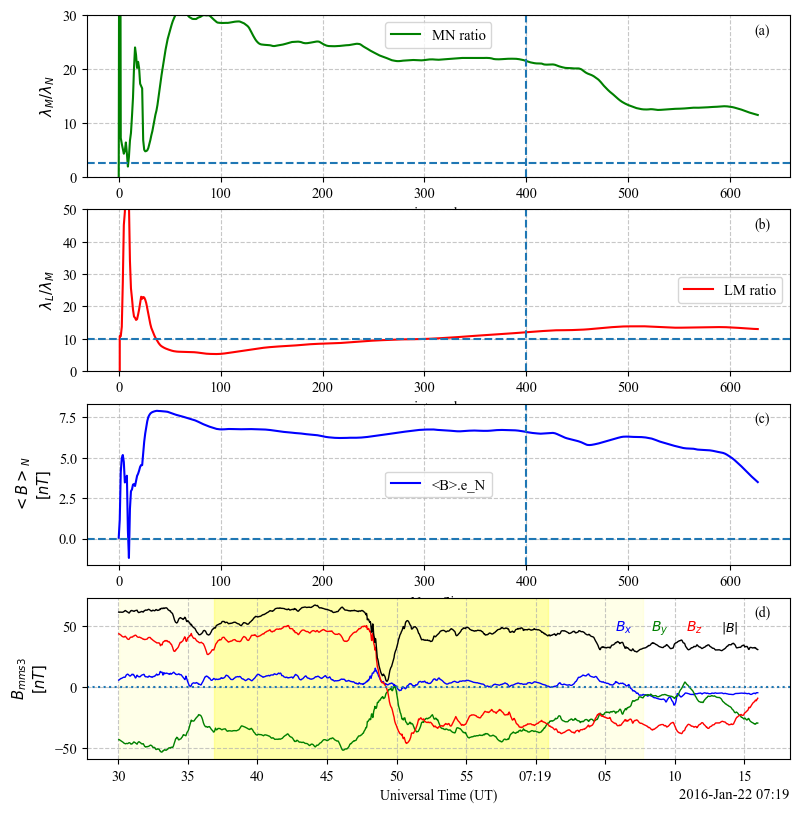

In [47]:
fig, ax = plt.subplots(4, 1, figsize=(8.27, 8.27), sharex=False, gridspec_kw={'hspace': 0.2})

# First plot (a) - MN ratio
nested_mva.eigenrat_slices.sel(ratios=1).plot(ax=ax[0], color='g', label='MN ratio')
ax[0].set_ylim(0, 30)
ax[0].axhline(y=2.5, ls='--')
ax[0].legend()
ax[0].axvline(x=400, ls='--')
ax[0].set_ylabel(r'$\lambda_M/\lambda_N$', fontsize=10.5)  # Set font size to 10.5 pt for SimSun text

# Second plot (b) - LM ratio
nested_mva.eigenrat_slices.sel(ratios=0).plot(ax=ax[1], color='r', label='LM ratio')
ax[1].set_ylim(0, 50)
ax[1].axhline(y=10, ls='--')
ax[1].legend()
ax[1].axvline(x=400, ls='--')
ax[1].set_ylabel(r'$\lambda_L/\lambda_M$', fontsize=10.5)

# Third plot (c) - <B>.e_N
xr.dot(nested_mva.e_N, nested_mva.B_av, dim=['values']).plot(ax=ax[2], color='b', label='<B>.e_N')
ax[2].set_xlabel('Nest_Size', fontsize=10)  # Font size for numbers in axis labels
ax[2].axhline(y=0, ls='--')
ax[2].legend()
ax[2].axvline(x=400, ls='--')
ax[2].set_ylabel(r'$<B>_N$' + '\n' + r'$[nT]$', fontsize=10.5)  # 10.5 pt SimSun for text

# Fourth plot (d) - Magnetic field components
ax[3].plot(mms3i_bdataset.time.sel(time=slice(del3, del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3, del4), v_dim=0), c='b', lw=1, label='Bx')
ax[3].plot(mms3i_bdataset.time.sel(time=slice(del3, del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3, del4), v_dim=1), c='g', lw=1, label='By')
ax[3].plot(mms3i_bdataset.time.sel(time=slice(del3, del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3, del4), v_dim=2), c='r', lw=1, label='Bz')
ax[3].plot(mms3i_bdataset.time.sel(time=slice(del3, del4)), mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3, del4), v_dim=3), c='k', lw=1, label='Bz')
ax[3].axvspan(nested_mva.time[-1][0].values, nested_mva.time[-1][1].values, color=(1, 1, 0.7), alpha=0.3, label='Highlighted Span')
ax[3].axvspan(nested_mva.isel(intervals=400).time[0].values, nested_mva.isel(intervals=400).time[1].values, color=(1, 1, 0.1), alpha=0.3, label='Highlighted Span')
ax[3].axhline(y=0, ls=':')
ax[3].set_xlabel('Universal Time (UT)', fontsize=10)  # 10 pt Times New Roman for UT
ax[3].set_ylabel(r'$B_{mms3}$' + '\n' + r'$[nT]$', fontsize=10.5)  # 10.5 pt SimSun for text

# Annotations
ax[3].annotate(r'$\mathit{B_x}$', xy=(0.75, 0.8), xycoords='axes fraction', fontsize=10, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for Bx in blue
ax[3].annotate(r'$\mathit{B_y}$', xy=(0.80, 0.8), xycoords='axes fraction', fontsize=10, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
ax[3].annotate(r'$\mathit{B_z}$', xy=(0.85, 0.8), xycoords='axes fraction', fontsize=10, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for Bz in red
ax[3].annotate(r'$\mathit{|B|}$', xy=(0.9, 0.8), xycoords='axes fraction',  fontsize=9, color='k', xytext=(1, -1), textcoords='offset points')  # Annotation for |B| in black

# Adjust padding around and between subplots
ax[0].text(0.95, 0.95, '(a)', transform=ax[0].transAxes, fontsize=10, va='top') 
ax[1].text(0.95, 0.95, '(b)', transform=ax[1].transAxes, fontsize=10, va='top') 
ax[2].text(0.95, 0.95, '(c)', transform=ax[2].transAxes, fontsize=10, va='top') 
ax[3].text(0.95, 0.95, '(d)', transform=ax[3].transAxes, fontsize=10, va='top') 

# Apply grid to all axes
for ax_i in ax:  # Iterate over all subplot axes
    ax_i.grid(True, linestyle='--', alpha=0.7)

# Final layout adjustments
plt.tight_layout(pad=1.0, rect=[0, 0, 0.9, 1.0])
plt.subplots_adjust(top=0.95, bottom=0.05, left=0.1, right=0.95, hspace=0.2)

# Save the figure
plt.savefig(os.path.join(output_folder, f"_{sc}.png"), dpi=300)

# Show the plot
plt.grid(True)
plt.show()


and 400th for event B chosen for LMN determination

In [48]:
hello = nested_mva.e_N.to_dataframe().reset_index()
csv_path = os.path.join(output_folder, 'e_N.csv')
hello.to_csv(csv_path, "index=False)

SyntaxError: unterminated string literal (detected at line 3) (1554565249.py, line 3)

## nested_mva

In [49]:
nested_mva

<xarray.Dataset> Size: 80kB
Dimensions:          (intervals: 628, ratios: 2, values: 3, range: 2)
Coordinates:
    indices          (intervals, range) int64 10kB 628 630 627 ... 1256 1 1257
    start_index      (intervals) int64 5kB 628 627 626 625 624 623 ... 5 4 3 2 1
    time             (intervals, range) datetime64[ns] 10kB 2016-01-22T07:18:...
Dimensions without coordinates: intervals, ratios, values, range
Data variables:
    eigenrat_slices  (intervals, ratios) float64 10kB -4.448e+15 ... 11.49
    eigenval_slices  (intervals, values) float64 15kB 0.1237 ... 8.546
    e_N              (intervals, values) float64 15kB 0.0402 0.7056 ... -0.05501
    B_av             (intervals, values) float64 15kB 7.867 -0.2283 ... 5.842

In [50]:
nested_mva.isel(intervals=400).time[0].values,nested_mva.isel(intervals=400).time[1].values

(np.datetime64('2016-01-22T07:18:36.859564000'),
 np.datetime64('2016-01-22T07:19:00.919564000'))

In [51]:
v=mva_b(mms4i_bdataset.
        mms4_fgm_b_gse_brst_l2.
        sel(time=slice(nested_mva.
                       isel(intervals=400).time[0],
                       nested_mva.isel(intervals=400).time[1])))[0]
v

<xarray.Dataset> Size: 112B
Dimensions:   (ratios: 2, values: 3, vec: 3, LMN: 3)
Dimensions without coordinates: ratios, values, vec, LMN
Data variables:
    eigenrat  (ratios) float64 16B 12.06 21.41
    eigenval  (values) float64 24B 1.281e+03 106.2 4.96
    eigenvec  (vec, LMN) float64 72B 0.05881 -0.05699 ... -0.1032 -0.06447

In [52]:
v.eigenvec.sel(LMN=0)

<xarray.DataArray 'eigenvec' (vec: 3)> Size: 24B
array([ 0.05881083, -0.10656782,  0.99256465])
Dimensions without coordinates: vec

In [53]:
def rotate_tensor(P, E):
    # P: (3,3), E: (3,3) -> return (3,3)
    # use einsum for clarity and speed
    return np.einsum('pq,ps,sr->qr', E, P, E)

P_lmn = xr.apply_ufunc(
    rotate_tensor,
    edatasets_interp['mms3'][f'{'mms3'}_des_prestensor_gse_brst'],                     # (time, 3, 3)
    v.eigenvec,                  # (3, 3) - will be broadcast over time
    input_core_dims=[['v_dim','v2_dim'], ['vec','LMN']],
    output_core_dims=[['LMN','LMN']],
    vectorize=True,            # vectorize over 'time'
    dask='allowed'             # allow dask arrays
)

25-Oct-26 16:39:15: D:\hallsim\hallsim\Lib\site-packages\xarray\namedarray\core.py:261: UserWarning: Duplicate dimension names present: dimensions {'LMN'} appear more than once in dims=('time', 'LMN', 'LMN'). We do not yet support duplicate dimension names, but we do allow initial construction of the object. We recommend you rename the dims immediately to become distinct, as most xarray functionality is likely to fail silently if you do not. To rename the dimensions you will need to set the ``.dims`` attribute of each variable, ``e.g. var.dims=('x0', 'x1')``.
  self._dims = self._parse_dimensions(dims)



# Timing Analysis

In [54]:
def get_data(t1,t2):
    
    B1 = mms1i_brdataset.mms1_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    B2 = mms2i_brdataset.mms2_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    B3 = mms3i_brdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    B4 = mms4i_brdataset.mms4_fgm_b_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))

    R1 = mms1i_brdataset.mms1_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    R2 = mms2i_brdataset.mms2_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    R3 = mms3i_brdataset.mms3_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    R4 = mms4i_brdataset.mms4_fgm_r_gse_brst_l2.sel(time=slice(t1,t2),v_dim=slice(0, 3))
    
    BT_concat = xr.concat([B1,B2,B3,B4],dim='time')
    BS_concat = xr.concat([B1,B2,B3,B4],dim='spacecraft')
    RS_concat = xr.concat([R1,R2,R3,R4],dim='spacecraft')

    BS_mean = xr.apply_ufunc(np.mean,BS_concat,
                                    input_core_dims=[['spacecraft']],
                                    kwargs={"axis": -1})
    BS_cov = xr.apply_ufunc(np.cov,BS_mean,exclude_dims={'time'},
                                   input_core_dims=[['time','v_dim']],
                                   output_core_dims=[['dim1','v_dim']],
                                   kwargs={"rowvar": False})
    eigen = xr.apply_ufunc(np.linalg.eigh,BS_cov,
                           input_core_dims=[['dim1','v_dim']])
    #w = eigen.item().eigenvalues
    #v = eigen.item().eigenvectors
    
    return [BT_concat,BS_concat,RS_concat,BS_mean]

In [56]:
TA1 = xr.apply_ufunc(np.matmul,
                       mms1i_brdataset.mms1_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms1.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')
RA1 = xr.apply_ufunc(np.matmul,
                       mms1i_brdataset.mms1_fgm_r_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms1.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')


TA2 = xr.apply_ufunc(np.matmul,
                       mms2i_brdataset.mms2_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms2.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')
RA2 = xr.apply_ufunc(np.matmul,
                       mms2i_brdataset.mms2_fgm_r_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms2.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')
TA3 = xr.apply_ufunc(np.matmul,
                       mms3i_brdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms3.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']])
RA3 = xr.apply_ufunc(np.matmul,
                       mms3i_brdataset.mms3_fgm_r_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms3.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')
TA4 = xr.apply_ufunc(np.matmul,
                       mms4i_brdataset.mms4_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms4.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']])
RA4 = xr.apply_ufunc(np.matmul,
                       mms4i_brdataset.mms4_fgm_r_gse_brst_l2.sel(time=slice(del3,del4),v_dim=slice(0,3)),
                       mms4.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')

In [57]:
B = get_data(del3,del4)[1]
R = get_data(del3,del4)[2]

delR12  = R.sel(spacecraft=1) - R.sel(spacecraft=0)
delR13  = R.sel(spacecraft=2) - R.sel(spacecraft=0)
delR14  = R.sel(spacecraft=3) - R.sel(spacecraft=0)
delR24  = R.sel(spacecraft=3) - R.sel(spacecraft=1)
delR34  = R.sel(spacecraft=3) - R.sel(spacecraft=2)
delR23  = R.sel(spacecraft=2) - R.sel(spacecraft=1)

k1 = xr.cross(delR23,delR24,dim='v_dim')
k2 = -xr.cross(delR34,delR13,dim='v_dim')
k3 = xr.cross(delR14,delR24,dim='v_dim')
k4 = xr.cross(delR12,delR13,dim='v_dim')

v1 = xr.dot(-delR12, xr.cross(delR23, delR24,dim='v_dim'),dim=['v_dim'])
v2 = xr.dot(delR23, xr.cross(delR34, delR13,dim='v_dim'),dim=['v_dim'])
v3 = xr.dot(-delR34, xr.cross(delR14, delR24,dim='v_dim'),dim=['v_dim'])
v4 = xr.dot(delR14, xr.cross(delR12, delR13,dim='v_dim'),dim=['v_dim'])
rec = xr.concat([k1/v1,k2/v2,k3/v3,k4/v4], dim='spacecraft').transpose('time','spacecraft','v_dim') # reciprocal vectors"

m1 = find(TA1,LMN=0,d1=del3,d2=del4)
m2 = find(TA2,LMN=0,d1=del3,d2=del4 )
m3 = find(TA3,LMN=0,d1=del3,d2=del4)    
m4 = find(TA4,LMN=0,d1=del3,d2=del4)


m1 = [mms1i_bdataset.time.sel(time=slice(del3,del4)).isel(time=mms1i_bdataset.mms1_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()).values,
      mms1i_bdataset.mms1_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()]
m2 = [mms2i_bdataset.time.sel(time=slice(del3,del4)).isel(time=mms2i_bdataset.mms2_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()).values,
      mms2i_bdataset.mms2_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()]
m3 = [mms3i_bdataset.time.sel(time=slice(del3,del4)).isel(time=mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()).values,
      mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()]
m4 = [mms4i_bdataset.time.sel(time=slice(del3,del4)).isel(time=mms4i_bdataset.mms4_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()).values,
      mms4i_bdataset.mms4_fgm_b_gse_brst_l2.sel(time=slice(del3,del4),v_dim=3).argmin()]

# Assuming mms3, mms2, mms3, and mms4 are in numpy datetime64 format
mms_dates = np.array([m1[0],m2[0],m3[0],m4[0]], dtype='datetime64[ns]')
# Find the smallest date
min_date = np.min(mms_dates)
# Subtract the smallest date from all dates
mms = np.array((mms_dates - min_date),dtype='float')*1e-9
values = [('mms1', mms[0]), ('mms2', mms[1]), ('mms3', mms[2]), ('mms4', mms[3])]

# Sort the list based on the values in ascending order
sorted_values = sorted(values, key=lambda x: x[1])

# Identify the smallest value
smallest_value = sorted_values[0][1]

# Subtract the smallest value from each of the other values
differences = [(identifier, value - smallest_value) for identifier, value in values]

a = rec.sel(time=m1[0],spacecraft=0)*differences[0][1] 
b = rec.sel(time=m2[0],spacecraft=1)*differences[1][1]
c = rec.sel(time=m3[0],spacecraft=2)*differences[2][1]
d = rec.sel(time=m4[0],spacecraft=3)*differences[3][1]

m=a.values+b.values+c.values+d.values
m.ravel()
n=m/np.linalg.norm(m)
V=1/np.linalg.norm(m)
if n[0]<0:
   n[:]=-n[:]
n,V

25-Oct-26 16:39:22: D:\hallsim\hallsim\Lib\site-packages\xarray\core\dataarray.py:6260: DeprecationWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmin(dim, axis, keep_attrs, skipna)

25-Oct-26 16:39:22: D:\hallsim\hallsim\Lib\site-packages\xarray\core\dataarray.py:6260: DeprecationWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmin(dim, axis, keep_attrs, skipna)

25-Oct-26 16:39:22: D:\hallsim\hallsim\Lib\site-packages\xarray\core\dataarray.py:6260: DeprecationWarning: Behaviour of argmin/argmax with neither dim nor axis argument will

(array([ 0.993916  ,  0.02008615, -0.10829371]),
 np.float64(46.760327402428054))

In [58]:
n

array([ 0.993916  ,  0.02008615, -0.10829371])

In [59]:
L = mms4.eigenvec.sel(LMN=0).values
M = np.cross(n,L)
N = np.cross(L,M)

v1 = xr.Dataset({'eigenvec':xr.DataArray(np.array([L,M,N]).T,dims=['vec','LMN'])})
v1.eigenvec

<xarray.DataArray 'eigenvec' (vec: 3, LMN: 3)> Size: 72B
array([[ 0.05881083,  0.00839618,  0.99692571],
       [-0.10656782, -0.99289473,  0.01463244],
       [ 0.99256465, -0.10710074, -0.0574982 ]])
Dimensions without coordinates: vec, LMN

In [60]:
m1[0]

np.datetime64('2016-01-22T07:18:49.039564000')

In [61]:
values,sorted_values,m1[0],m2[0],m3[0],m4[0]

([('mms1', np.float64(0.15000000000000002)),
  ('mms2', np.float64(0.0)),
  ('mms3', np.float64(0.42000000000000004)),
  ('mms4', np.float64(0.15000000000000002))],
 [('mms2', np.float64(0.0)),
  ('mms1', np.float64(0.15000000000000002)),
  ('mms4', np.float64(0.15000000000000002)),
  ('mms3', np.float64(0.42000000000000004))],
 np.datetime64('2016-01-22T07:18:49.039564000'),
 np.datetime64('2016-01-22T07:18:48.889564000'),
 np.datetime64('2016-01-22T07:18:49.309564000'),
 np.datetime64('2016-01-22T07:18:49.039564000'))

In [62]:
pgse1 = R.sel(spacecraft=0,time=bz_crossing_times['mms1'])/Re
pgse2 = R.sel(spacecraft=1,time=bz_crossing_times['mms2'])/Re
pgse3 = R.sel(spacecraft=2,time=bz_crossing_times['mms3'])/Re
pgse4 = R.sel(spacecraft=3,time=bz_crossing_times['mms4'])/Re

NameError: name 'Re' is not defined

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# -----------------------------
# 1. Select spacecraft positions
# -----------------------------
# These are in km
pgse1 = R.sel(spacecraft=0, time=bz_crossing_times['mms1'])
pgse2 = R.sel(spacecraft=1, time=bz_crossing_times['mms2'])
pgse3 = R.sel(spacecraft=2, time=bz_crossing_times['mms3'])
pgse4 = R.sel(spacecraft=3, time=bz_crossing_times['mms4'])

def to_vector(p):
    """Convert xarray/numpy position into clean 3-element numpy vector."""
    arr = p.values if hasattr(p, "values") else p
    arr = np.asarray(arr, dtype=float).squeeze()
    return arr

positions = {
    "MMS1": to_vector(pgse1),
    "MMS2": to_vector(pgse2),
    "MMS3": to_vector(pgse3),
    "MMS4": to_vector(pgse4),
}
names = list(positions.keys())
pos = np.vstack([positions[name] for name in names])

print("Spacecraft GSE positions in km:")
for name in names:
    print(f"{name}: {positions[name]}")

Spacecraft GSE positions in km:
MMS1: [ 53557.07568035 -29010.8983336   -5489.86218862]
MMS2: [ 53564.80116013 -29033.47290625  -5489.36913922]
MMS3: [ 53544.49396047 -29022.99823793  -5488.81192392]
MMS4: [ 53556.35959312 -29025.01829812  -5499.05430548]


In [64]:
distance_rows = []
for i, j in combinations(range(4), 2):
    r_i = pos[i]
    r_j = pos[j]

    relative_vector = r_j - r_i
    distance_km = np.linalg.norm(relative_vector)

    distance_rows.append({
        "Pair": f"{names[i]}-{names[j]}",
        "dx_km": relative_vector[0],
        "dy_km": relative_vector[1],
        "dz_km": relative_vector[2],
        "Distance_km": distance_km
    })

df_distances = pd.DataFrame(distance_rows)
# Optional distance matrix
distance_matrix = pd.DataFrame(index=names, columns=names, dtype=float)

for i in range(4):
    for j in range(4):
        distance_matrix.iloc[i, j] = np.linalg.norm(pos[j] - pos[i])

print("\nDistance matrix in km:")
print(distance_matrix.round(3))


Distance matrix in km:
        MMS1    MMS2    MMS3    MMS4
MMS1   0.000  23.865  17.487  16.864
MMS2  23.865   0.000  22.856  15.380
MMS3  17.487  22.856   0.000  15.804
MMS4  16.864  15.380  15.804   0.000


In [65]:
RA1.sel(time=(m1[0])).values,RA2.sel(time=(m2[0])).values,RA3.sel(time=(m3[0])).values,RA4.sel(time=(m4[0])).values

(array([  755.80406103, 25790.39260098, 55447.17494439]),
 array([ 1071.95379863, 25698.31597316, 55503.77406241]),
 array([ 1090.70987742, 28633.43582191, 54022.22201418]),
 array([  784.65127787, 26337.59053341, 55196.59605983]))

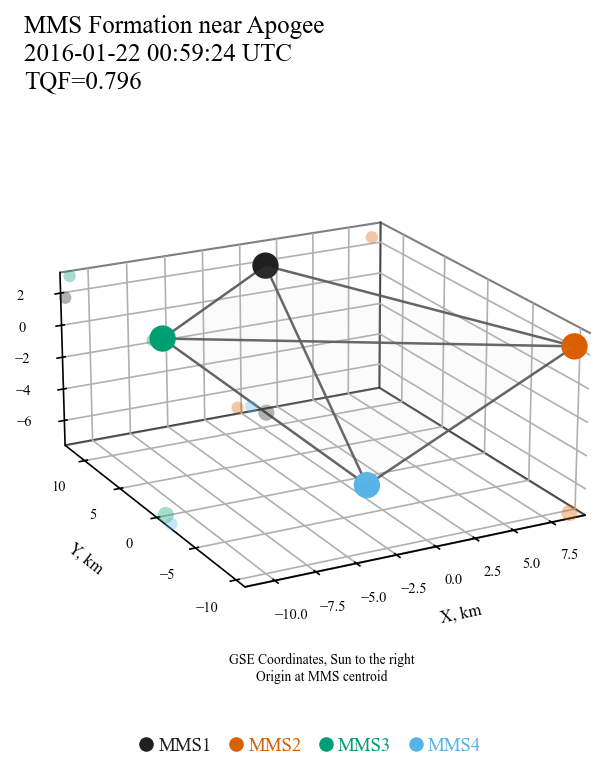

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ==================================================
# 1. Select MMS position vectors in km
# ==================================================
pgse1 = R.sel(spacecraft=0, time=bz_crossing_times['mms1'])
pgse2 = R.sel(spacecraft=1, time=bz_crossing_times['mms2'])
pgse3 = R.sel(spacecraft=2, time=bz_crossing_times['mms3'])
pgse4 = R.sel(spacecraft=3, time=bz_crossing_times['mms4'])

def to_vector(p):
    """
    Convert xarray DataArray or numpy array to clean 3-element vector.
    """
    if hasattr(p, "values"):
        p = p.values
    return np.asarray(p, dtype=float).squeeze().reshape(-1)[:3]

positions_abs = np.vstack([
    to_vector(pgse1),
    to_vector(pgse2),
    to_vector(pgse3),
    to_vector(pgse4)
])

names = ["MMS1", "MMS2", "MMS3", "MMS4"]

# ==================================================
# 2. Put origin at MMS centroid, same as uploaded figure
# ==================================================
centroid = positions_abs.mean(axis=0)
positions = positions_abs - centroid

# If you want MMS1 at origin instead, use this line:
# positions = positions_abs - positions_abs[0]

# ==================================================
# 3. Tetrahedron quality factor
# ==================================================
def tetrahedron_volume(p):
    r1, r2, r3, r4 = p
    return abs(np.dot(r2 - r1, np.cross(r3 - r1, r4 - r1))) / 6.0

def tetrahedron_quality_factor(p):
    edges = []
    for i, j in combinations(range(4), 2):
        edges.append(np.linalg.norm(p[i] - p[j]))

    edges = np.asarray(edges)
    mean_edge = edges.mean()
    V = tetrahedron_volume(p)

    V_regular = mean_edge**3 / (6.0 * np.sqrt(2.0))
    return V / V_regular

TQF = tetrahedron_quality_factor(positions)

# Use computed TQF
TQF_text = f"{TQF:.3f}"

# If you want exactly the uploaded value, uncomment:
# TQF_text = "0.940"

# ==================================================
# 4. Tight axis limits: cut off unused axis length
# ==================================================
x = positions[:, 0]
y = positions[:, 1]
z = positions[:, 2]

pad_fraction = 0.03
min_pad = 0.20

x_pad = max((x.max() - x.min()) * pad_fraction, min_pad)
y_pad = max((y.max() - y.min()) * pad_fraction, min_pad)
z_pad = max((z.max() - z.min()) * pad_fraction, min_pad)

xmin, xmax = x.min() - x_pad, x.max() + x_pad
ymin, ymax = y.min() - y_pad, y.max() + y_pad
zmin, zmax = z.min() - z_pad, z.max() + z_pad

# ==================================================
# 5. Colors
# ==================================================
colors = {
    "MMS1": "#202020",
    "MMS2": "#d95f02",
    "MMS3": "#009e73",
    "MMS4": "#56b4e9"
}

# ==================================================
# 6. Start figure
# ==================================================
fig = plt.figure(figsize=(7.0, 5.3), dpi=150)
ax = fig.add_subplot(111, projection="3d")

# ==================================================
# 7. Tetrahedron edges
# ==================================================
for i, j in combinations(range(4), 2):
    ax.plot(
        [positions[i, 0], positions[j, 0]],
        [positions[i, 1], positions[j, 1]],
        [positions[i, 2], positions[j, 2]],
        color="0.35",
        linewidth=1.2,
        alpha=0.95
    )

# ==================================================
# 8. Very light tetrahedron faces
# ==================================================
tetra_faces = [
    [positions[0], positions[1], positions[2]],
    [positions[0], positions[1], positions[3]],
    [positions[0], positions[2], positions[3]],
    [positions[1], positions[2], positions[3]]
]

tetra_poly = Poly3DCollection(
    tetra_faces,
    facecolor="lightgray",
    edgecolor="none",
    alpha=0.03
)

ax.add_collection3d(tetra_poly)

# ==================================================
# 9. Plot spacecraft vertices
# ==================================================
for i, name in enumerate(names):
    ax.scatter(
        positions[i, 0],
        positions[i, 1],
        positions[i, 2],
        s=160,
        color=colors[name],
        edgecolor="none",
        depthshade=True
    )

# ==================================================
# 10. Shaded projections on shortened cube walls/floor
# ==================================================
for i, name in enumerate(names):
    c = colors[name]

    # Projection on bottom XY plane
    ax.scatter(
        positions[i, 0],
        positions[i, 1],
        zmin,
        s=60,
        color=c,
        alpha=0.35,
        edgecolor="none"
    )

    # Projection on back XZ plane
    ax.scatter(
        positions[i, 0],
        ymax,
        positions[i, 2],
        s=35,
        color=c,
        alpha=0.35,
        edgecolor="none"
    )

    # Projection on side YZ plane
    ax.scatter(
        xmin,
        positions[i, 1],
        positions[i, 2],
        s=35,
        color=c,
        alpha=0.35,
        edgecolor="none"
    )

# ==================================================
# 11. Apply tight axis limits
# ==================================================
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_zlim(zmin, zmax)

ax.set_box_aspect([
    xmax - xmin,
    ymax - ymin,
    zmax - zmin
])

# ==================================================
# 12. Axis labels and ticks
# ==================================================
ax.set_xlabel("X, km", labelpad=6, fontsize=8)
ax.set_ylabel("Y, km", labelpad=6, fontsize=8)
ax.set_zlabel("Z, km", labelpad=6, fontsize=8)

ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7)
ax.tick_params(axis="z", labelsize=7)

# ==================================================
# 13. View angle similar to uploaded figure
# ==================================================
ax.view_init(elev=20, azim=-118)

# ==================================================
# 14. Title
# ==================================================
ax.set_title(
    "MMS Formation near Apogee\n"
    "2016-01-22 00:59:24 UTC\n"
    f"TQF={TQF_text}",
    loc="left",
    fontsize=12,
    pad=12
)

# ==================================================
# 15. White background and box style
# ==================================================
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True)

for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis.pane.set_facecolor((1, 1, 1, 0))
    axis.pane.set_edgecolor("black")

# ==================================================
# 16. Bottom note
# ==================================================
ax.text2D(
    0.52,
    0.03,
    "GSE Coordinates, Sun to the right\nOrigin at MMS centroid",
    transform=ax.transAxes,
    fontsize=6.5,
    ha="center",
    va="center"
)

# ==================================================
# 17. Bottom legend
# ==================================================
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="MMS1",
        markerfacecolor=colors["MMS1"],
        markersize=8
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="MMS2",
        markerfacecolor=colors["MMS2"],
        markersize=8
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="MMS3",
        markerfacecolor=colors["MMS3"],
        markersize=8
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="MMS4",
        markerfacecolor=colors["MMS4"],
        markersize=8
    ),
]

leg = ax.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=4,
    frameon=False,
    fontsize=9,
    handlelength=0.8,
    handletextpad=0.25,
    columnspacing=0.9
)

for text, name in zip(leg.get_texts(), names):
    text.set_color(colors[name])

# ==================================================
# 18. Remove unnecessary outside figure whitespace
# ==================================================
plt.subplots_adjust(
    left=0.03,
    right=0.98,
    bottom=0.16,
    top=0.88
)

# ==================================================
# 19. Save and show
# ==================================================
plt.savefig(
    "mms_formation_tight_axis.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Uniform arc used for 19 -> 07: forward
19 -> 07 arc length: 9.881311932066323
Uniform spacing per interval: 0.8234426610055269


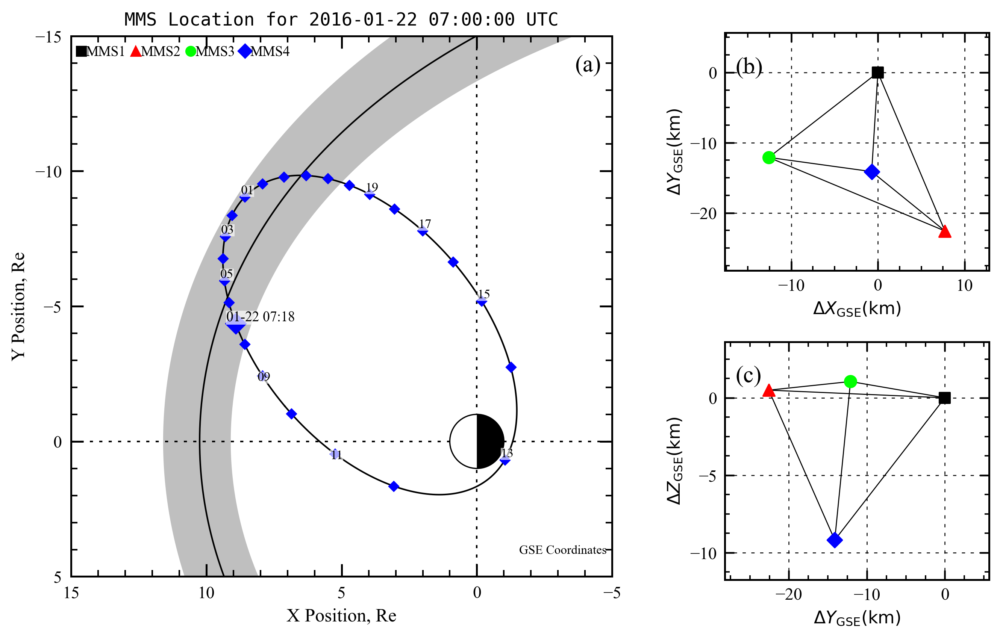

In [67]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations
from matplotlib.patches import Circle, Wedge
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from matplotlib.gridspec import GridSpec


# ============================================================
# MMS4 ORBIT + TWO TETRAHEDRON PROJECTIONS
# Panel (a): regular ellipse with diamonds on curve
# Panel (b): ΔY vs ΔX tetrahedron
# Panel (c): ΔZ vs ΔY tetrahedron
# ============================================================

Re_km = 6371.2

if "output_folder" not in globals():
    output_folder = "."

if "taistarttime" not in globals():
    taistarttime = "MMS_event"


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def clean_time(t):
    if hasattr(t, "values"):
        t = t.values
    return pd.to_datetime(np.ravel(t)[0])


def get_mms_position_da(sc_number):
    """
    Return MMS position DataArray for MMS1, MMS2, MMS3, or MMS4.
    First checks individual MMS datasets, then falls back to R.
    """
    dataset_var_map = {
        1: ("mms1i_brdataset", "mms1_fgm_r_gse_brst_l2"),
        2: ("mms2i_brdataset", "mms2_fgm_r_gse_brst_l2"),
        3: ("mms3i_brdataset", "mms3_fgm_r_gse_brst_l2"),
        4: ("mms4i_brdataset", "mms4_fgm_r_gse_brst_l2"),
    }

    ds_name, var_name = dataset_var_map[sc_number]

    if ds_name in globals():
        ds = globals()[ds_name]

        if hasattr(ds, "data_vars") and var_name in ds.data_vars:
            return ds[var_name]

        if hasattr(ds, var_name):
            return getattr(ds, var_name)

    if "R" in globals():
        return R.sel(spacecraft=sc_number - 1)

    raise NameError(
        f"MMS{sc_number} position data not found. "
        f"Expected {ds_name}.{var_name} or R.sel(spacecraft={sc_number - 1})."
    )


def select_xyz_at_time(da, t):
    """
    Select nearest spacecraft position at time t and return X, Y, Z only.
    Handles arrays shaped as [X, Y, Z, |R|].
    """
    t = clean_time(t)

    p = da.sel(time=t, method="nearest")
    arr = np.asarray(p.values, dtype=float).squeeze()

    if arr.ndim == 2:
        arr = arr[0, :3]
    else:
        arr = arr.reshape(-1)[:3]

    return arr


def convert_vector_to_re_if_needed(vec):
    vec = np.asarray(vec, dtype=float).copy()
    if np.nanmax(np.abs(vec)) > 100:
        vec = vec / Re_km
    return vec


def convert_positions_to_km_if_needed(pos):
    pos = np.asarray(pos, dtype=float).copy()
    if np.nanmax(np.abs(pos)) < 100:
        pos = pos * Re_km
    return pos


def style_tetra_axis(ax):
    ax.set_facecolor("white")

    ax.grid(
        True,
        which="major",
        linestyle=(0, (3, 5)),
        color="black",
        linewidth=0.7,
        alpha=0.85
    )

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color("black")

    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=6,
        width=1.1,
        labelsize=11,
        top=True,
        right=True,
        pad=5
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="in",
        length=3,
        width=0.9,
        top=True,
        right=True
    )

    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))


# ============================================================
# 1. EVENT TIME AND MMS4 CROSSING POSITION
# ============================================================

event_time = clean_time(bz_crossing_times["mms4"])
plot_time = event_time.floor("h")

da1 = get_mms_position_da(1)
da2 = get_mms_position_da(2)
da3 = get_mms_position_da(3)
da4 = get_mms_position_da(4)

event_vec = select_xyz_at_time(da4, bz_crossing_times["mms4"])
event_vec_re = convert_vector_to_re_if_needed(event_vec)

x_event = float(event_vec_re[0])
y_event = float(event_vec_re[1])
z_event = float(event_vec_re[2])


# ============================================================
# 2. TETRAHEDRON POSITIONS AT CROSSING TIMES
# ============================================================

pgse1 = select_xyz_at_time(da1, bz_crossing_times["mms1"])
pgse2 = select_xyz_at_time(da2, bz_crossing_times["mms2"])
pgse3 = select_xyz_at_time(da3, bz_crossing_times["mms3"])
pgse4 = select_xyz_at_time(da4, bz_crossing_times["mms4"])

positions_abs = np.vstack([pgse1, pgse2, pgse3, pgse4])
positions_abs = convert_positions_to_km_if_needed(positions_abs)

# MMS1 as origin
positions = positions_abs - positions_abs[0]

dx_tet = positions[:, 0]
dy_tet = positions[:, 1]
dz_tet = positions[:, 2]

names = ["MMS1", "MMS2", "MMS3", "MMS4"]

marker_style = {
    "MMS1": dict(marker="s", color="black", s=45),
    "MMS2": dict(marker="^", color="red", s=55),
    "MMS3": dict(marker="o", color="lime", s=55),
    "MMS4": dict(marker="D", color="blue", s=45),
}


# ============================================================
# 3. MAGNETOPAUSE MODEL
# ============================================================

mp_theta = np.linspace(-2.25, 2.25, 1000)

def shue_mp(r0, alpha=0.55):
    r = r0 * (2 / (1 + np.cos(mp_theta))) ** alpha
    x_mp = r * np.cos(mp_theta)
    y_mp = r * np.sin(mp_theta)
    return x_mp, y_mp

x_mp_inner, y_mp_inner = shue_mp(9.1)
x_mp_outer, y_mp_outer = shue_mp(11.6)
x_mp_mid, y_mp_mid = shue_mp(10.25)


# ============================================================
# 4. ORBIT COORDINATE REFERENCES
# ============================================================

coords_main = {
    "07": (8.45, -4.62),
    "08": (8.02, -3.95),
    "09": (7.42, -2.85),
    "10": (6.50, -1.45),
    "11": (5.12,  0.18),
    "12": (2.95,  1.10),
    "13": (-1.05, 0.65),
    "14": (-1.35, -2.85),
    "15": (-0.18, -5.30),
    "16": (0.95, -6.68),
    "17": (2.12, -7.78),
    "18": (3.22, -8.47),
    "19": (4.08, -9.08),
}

# Shift reference geometry so 07 matches real MMS4 crossing
x07_nom, y07_nom = coords_main["07"]
shift_x = x_event - x07_nom
shift_y = y_event - y07_nom

coords_main = {
    k: (v[0] + shift_x, v[1] + shift_y)
    for k, v in coords_main.items()
}


# Closure reference arc 20 -> 06
P0 = np.array(coords_main["19"])
P3 = np.array(coords_main["07"])

C1 = np.array([5.70 + shift_x, -9.55 + shift_y])
C2 = np.array([10.15 + shift_x, -7.10 + shift_y])

def cubic_bezier(p0, p1, p2, p3, t):
    return (
        (1 - t) ** 3 * p0
        + 3 * (1 - t) ** 2 * t * p1
        + 3 * (1 - t) * t ** 2 * p2
        + t ** 3 * p3
    )

closure_hours = ["20", "21", "22", "23", "00", "01", "02", "03", "04", "05", "06"]
tvals = np.linspace(1 / 12, 11 / 12, len(closure_hours))

coords_closure = {}
for hh, tt in zip(closure_hours, tvals):
    xy = cubic_bezier(P0, C1, C2, P3, tt)
    coords_closure[hh] = (float(xy[0]), float(xy[1]))


hour_order = [
    "07", "08", "09", "10", "11", "12", "13",
    "14", "15", "16", "17", "18", "19",
    "20", "21", "22", "23", "00", "01", "02", "03", "04", "05", "06"
]

coords_all = {}
coords_all.update(coords_main)
coords_all.update(coords_closure)


# ============================================================
# 5. REGULAR ELLIPSE CURVE
# ============================================================

def regular_ellipse_curve(cx, cy, a, b, phi_deg, n=9000):
    theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
    phi = np.deg2rad(phi_deg)

    x = (
        cx
        + a * np.cos(theta) * np.cos(phi)
        - b * np.sin(theta) * np.sin(phi)
    )

    y = (
        cy
        + a * np.cos(theta) * np.sin(phi)
        + b * np.sin(theta) * np.cos(phi)
    )

    return x, y


# ============================================================
# Manual ellipse controls
# ============================================================
# Change only these values to tune the ellipse trajectory.

cx = 4.00 + shift_x
cy = -4.00 + shift_y
a  = 4.10
b  = 6.90
phi_deg = 40

x_curve, y_curve = regular_ellipse_curve(
    cx=cx,
    cy=cy,
    a=a,
    b=b,
    phi_deg=phi_deg,
    n=9000
)


# ============================================================
# 6. SNAP DIAMONDS TO ELLIPSE
#    AND MAKE 19 -> 07 UNIFORMLY DISTRIBUTED
# ============================================================

def nearest_idx_on_curve(x_target, y_target, x_curve, y_curve):
    return int(np.argmin((x_curve - x_target) ** 2 + (y_curve - y_target) ** 2))


def nearest_point_on_curve(x_target, y_target, x_curve, y_curve):
    idx = nearest_idx_on_curve(x_target, y_target, x_curve, y_curve)
    return float(x_curve[idx]), float(y_curve[idx]), idx


def get_arc_between_indices(x_curve, y_curve, i_start, i_end, direction=1):
    n = len(x_curve)

    if direction == 1:
        if i_end >= i_start:
            idx = np.arange(i_start, i_end + 1)
        else:
            idx = np.r_[np.arange(i_start, n), np.arange(0, i_end + 1)]
    else:
        if i_end <= i_start:
            idx = np.arange(i_start, i_end - 1, -1)
        else:
            idx = np.r_[np.arange(i_start, -1, -1), np.arange(n - 1, i_end - 1, -1)]

    return idx, x_curve[idx], y_curve[idx]


def sample_uniform_arc_length(x_arc, y_arc, n_points):
    ds = np.sqrt(np.diff(x_arc) ** 2 + np.diff(y_arc) ** 2)
    s = np.r_[0.0, np.cumsum(ds)]
    total_length = s[-1]

    target_s = np.linspace(0.0, total_length, n_points)

    x_out = np.interp(target_s, s, x_arc)
    y_out = np.interp(target_s, s, y_arc)

    return x_out, y_out, total_length


# First snap all hours to ellipse
coords_all_on_curve = {}

for hh in hour_order:
    xh, yh = coords_all[hh]
    xp, yp, idxp = nearest_point_on_curve(xh, yh, x_curve, y_curve)
    coords_all_on_curve[hh] = (xp, yp)


# Override 19 -> 07 with uniform spacing along selected ellipse arc
uniform_arc_hours = [
    "19", "20", "21", "22", "23", "00",
    "01", "02", "03", "04", "05", "06", "07"
]

i19 = nearest_idx_on_curve(coords_all["19"][0], coords_all["19"][1], x_curve, y_curve)
i07 = nearest_idx_on_curve(coords_all["07"][0], coords_all["07"][1], x_curve, y_curve)

idx_f, x_f, y_f = get_arc_between_indices(x_curve, y_curve, i19, i07, direction=1)
idx_b, x_b, y_b = get_arc_between_indices(x_curve, y_curve, i19, i07, direction=-1)

closure_ref_hours = ["20", "21", "22", "23", "00", "01", "02", "03", "04", "05", "06"]

def mean_distance_to_reference(x_arc, y_arc, ref_hours):
    total = 0.0
    for hh in ref_hours:
        xr, yr = coords_all[hh]
        total += np.min((x_arc - xr) ** 2 + (y_arc - yr) ** 2)
    return total / len(ref_hours)

score_f = mean_distance_to_reference(x_f, y_f, closure_ref_hours)
score_b = mean_distance_to_reference(x_b, y_b, closure_ref_hours)

if score_f <= score_b:
    x_arc_use, y_arc_use = x_f, y_f
    arc_direction_used = "forward"
else:
    x_arc_use, y_arc_use = x_b, y_b
    arc_direction_used = "backward"

x_uniform, y_uniform, arc_length = sample_uniform_arc_length(
    x_arc_use,
    y_arc_use,
    n_points=len(uniform_arc_hours)
)

for hh, xu, yu in zip(uniform_arc_hours, x_uniform, y_uniform):
    coords_all_on_curve[hh] = (float(xu), float(yu))

x_07_plot, y_07_plot = coords_all_on_curve["07"]

print("Uniform arc used for 19 -> 07:", arc_direction_used)
print("19 -> 07 arc length:", arc_length)
print("Uniform spacing per interval:", arc_length / (len(uniform_arc_hours) - 1))


# ============================================================
# 7. LABEL SETTINGS
# ============================================================

show_labels = {"01", "03", "05", "09", "11", "13", "15", "17", "19"}

label_offsets = {
    "01": (0.15, -0.10),
    "03": (0.15, -0.10),
    "05": (0.15, -0.10),
    "09": (0.18,  0.18),
    "11": (0.18,  0.18),
    "13": (0.15, -0.10),
    "15": (0.15, -0.10),
    "17": (0.15, -0.10),
    "19": (0.15, -0.10),
}


# ============================================================
# 8. CREATE COMBINED FIGURE
# ============================================================

fig = plt.figure(figsize=(10.5, 6.3), dpi=300)

gs = GridSpec(
    2, 2,
    width_ratios=[2.15, 1.05],
    height_ratios=[1, 1],
    wspace=0.28,
    hspace=0.30
)

ax_a = fig.add_subplot(gs[:, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, 1])


# ============================================================
# 9. PANEL (a): ORBIT + MAGNETOPAUSE
# ============================================================

ax_a.fill(
    np.r_[x_mp_outer, x_mp_inner[::-1]],
    np.r_[y_mp_outer, y_mp_inner[::-1]],
    color="0.75",
    linewidth=0,
    zorder=0
)

ax_a.plot(
    x_mp_mid,
    y_mp_mid,
    color="black",
    linewidth=1.0,
    zorder=1
)

ax_a.plot(
    x_curve,
    y_curve,
    color="black",
    linewidth=1.0,
    zorder=2
)


# Hour diamonds on ellipse
for hh in hour_order:
    if hh == "07":
        continue

    xh, yh = coords_all_on_curve[hh]

    ax_a.scatter(
        xh,
        yh,
        s=24,
        marker="D",
        color="blue",
        edgecolor="blue",
        linewidth=0.3,
        zorder=3
    )


# Big 07 crossing diamond
ax_a.scatter(
    x_07_plot,
    y_07_plot,
    s=90,
    marker="D",
    color="blue",
    edgecolor="blue",
    linewidth=0.5,
    zorder=6
)

ax_a.text(
    x_07_plot + 0.35,
    y_07_plot - 0.08,
    event_time.strftime("%m-%d %H:%M"),
    fontsize=9,
    color="black",
    zorder=7,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.70, pad=0.15)
)


# Hour labels
for hh in hour_order:
    if hh not in show_labels:
        continue

    xh, yh = coords_all_on_curve[hh]
    xoff, yoff = label_offsets.get(hh, (0.15, -0.10))

    label_text = "24" if hh == "00" else hh

    ax_a.text(
        xh + xoff,
        yh + yoff,
        label_text,
        fontsize=8.5,
        color="black",
        zorder=6,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.65, pad=0.10)
    )


# Earth
earth_radius = 1.0

earth_circle = Circle(
    (0, 0),
    earth_radius,
    facecolor="white",
    edgecolor="black",
    linewidth=0.8,
    zorder=4
)
ax_a.add_patch(earth_circle)

earth_black = Wedge(
    (0, 0),
    earth_radius,
    90,
    270,
    facecolor="black",
    edgecolor="none",
    zorder=5
)
ax_a.add_patch(earth_black)


# GSE reference lines
ax_a.axhline(
    0,
    color="black",
    linestyle=(0, (2, 4)),
    linewidth=1.0,
    zorder=0
)

ax_a.axvline(
    0,
    color="black",
    linestyle=(0, (2, 4)),
    linewidth=1.0,
    zorder=0
)


# Legend
legend_handles = [
    Line2D([0], [0], marker="s", color="black", linestyle="None",
           markersize=6, label="MMS1"),
    Line2D([0], [0], marker="^", color="red", linestyle="None",
           markersize=6, label="MMS2"),
    Line2D([0], [0], marker="o", color="lime", linestyle="None",
           markersize=6, label="MMS3"),
    Line2D([0], [0], marker="D", color="blue", linestyle="None",
           markersize=6, label="MMS4"),
]

ax_a.legend(
    handles=legend_handles,
    loc="upper left",
    frameon=False,
    ncol=4,
    fontsize=9,
    handlelength=0,
    handletextpad=0.35,
    columnspacing=0.7,
    borderpad=0.2
)


# Axis style
ax_a.set_xlim(15, -5)
ax_a.set_ylim(5, -15)

ax_a.set_xticks([15, 10, 5, 0, -5])
ax_a.set_yticks([-15, -10, -5, 0, 5])

ax_a.xaxis.set_minor_locator(MultipleLocator(1))
ax_a.yaxis.set_minor_locator(MultipleLocator(1))

ax_a.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=8,
    width=1.2,
    labelsize=11,
    top=True,
    right=True,
    pad=6
)

ax_a.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=4,
    width=1.0,
    top=True,
    right=True
)

for spine in ax_a.spines.values():
    spine.set_linewidth(1.2)

ax_a.set_aspect("equal", adjustable="box")

ax_a.set_xlabel("X Position, Re", fontsize=12)
ax_a.set_ylabel("Y Position, Re", fontsize=12)

ax_a.set_title(
    f"MMS Location for {plot_time.strftime('%Y-%m-%d %H:%M:%S')} UTC",
    fontsize=11.5,
    fontfamily="monospace",
    pad=7
)

ax_a.text(
    -4.8,
    4.25,
    "GSE Coordinates",
    fontsize=8,
    ha="right",
    va="bottom"
)

ax_a.text(
    -4.6,
    -14.3,
    "(a)",
    fontsize=15,
    ha="right",
    va="top"
)


# ============================================================
# 10. PANEL (b): ΔY vs ΔX TETRAHEDRON
# ============================================================

for i, j in combinations(range(4), 2):
    ax_b.plot(
        [dx_tet[i], dx_tet[j]],
        [dy_tet[i], dy_tet[j]],
        color="black",
        linewidth=0.65,
        zorder=1
    )

for i, name in enumerate(names):
    ax_b.scatter(
        dx_tet[i],
        dy_tet[i],
        **marker_style[name],
        zorder=3
    )

ax_b.set_xlabel(r'$\Delta X_{\mathrm{GSE}}(\mathrm{km})$', fontsize=11)
ax_b.set_ylabel(r'$\Delta Y_{\mathrm{GSE}}(\mathrm{km})$', fontsize=11)

ax_b.text(
    0.04,
    0.9,
    "(b)",
    transform=ax_b.transAxes,
    fontsize=15,
    va="top"
)

style_tetra_axis(ax_b)

xpad = max((dx_tet.max() - dx_tet.min()) * 0.25, 1.5)
ypad = max((dy_tet.max() - dy_tet.min()) * 0.25, 1.5)

ax_b.set_xlim(dx_tet.min() - xpad, dx_tet.max() + xpad)
ax_b.set_ylim(dy_tet.min() - ypad, dy_tet.max() + ypad)


# ============================================================
# 11. PANEL (c): ΔZ vs ΔY TETRAHEDRON
# ============================================================

for i, j in combinations(range(4), 2):
    ax_c.plot(
        [dy_tet[i], dy_tet[j]],
        [dz_tet[i], dz_tet[j]],
        color="black",
        linewidth=0.65,
        zorder=1
    )

for i, name in enumerate(names):
    ax_c.scatter(
        dy_tet[i],
        dz_tet[i],
        **marker_style[name],
        zorder=3
    )

ax_c.set_xlabel(r'$\Delta Y_{\mathrm{GSE}}(\mathrm{km})$', fontsize=11)
ax_c.set_ylabel(r'$\Delta Z_{\mathrm{GSE}}(\mathrm{km})$', fontsize=11)

ax_c.text(
    0.04,
    0.90,
    "(c)",
    transform=ax_c.transAxes,
    fontsize=15,
    va="top"
)

style_tetra_axis(ax_c)

xpad = max((dy_tet.max() - dy_tet.min()) * 0.25, 1.5)
ypad = max((dz_tet.max() - dz_tet.min()) * 0.25, 1.5)

ax_c.set_xlim(dy_tet.min() - xpad, dy_tet.max() + xpad)
ax_c.set_ylim(dz_tet.min() - ypad, dz_tet.max() + ypad)


# ============================================================
# 12. SAVE AND SHOW
# ============================================================

plt.savefig(
    os.path.join(output_folder, f"{taistarttime}_orbit_uniform_arc_with_two_tetrahedron.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [68]:
mms4i_brdataset.mms4_fgm_r_gse_brst_l2.time

<xarray.DataArray 'time' (time: 4999)> Size: 40kB
array(['2016-01-22T07:17:14.029564000', '2016-01-22T07:17:14.059564000',
       '2016-01-22T07:17:14.089564000', ..., '2016-01-22T07:19:43.909564000',
       '2016-01-22T07:19:43.939564000', '2016-01-22T07:19:43.969564000'],
      shape=(4999,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 40kB 2016-01-22T07:17:14.029564 ... 2016-0...
    epoch    (time) datetime64[ns] 40kB 2016-01-22T07:17:14.029564 ... 2016-0...

In [69]:
Distance matrix in km:
        MMS1    MMS2    MMS3    MMS4
MMS1   0.000  23.865  17.487  16.864
MMS2  23.865   0.000  22.856  15.380
MMS3  17.487  22.856   0.000  15.804
MMS4  16.864  15.380  15.804   0.000

SyntaxError: invalid syntax (4281835432.py, line 1)

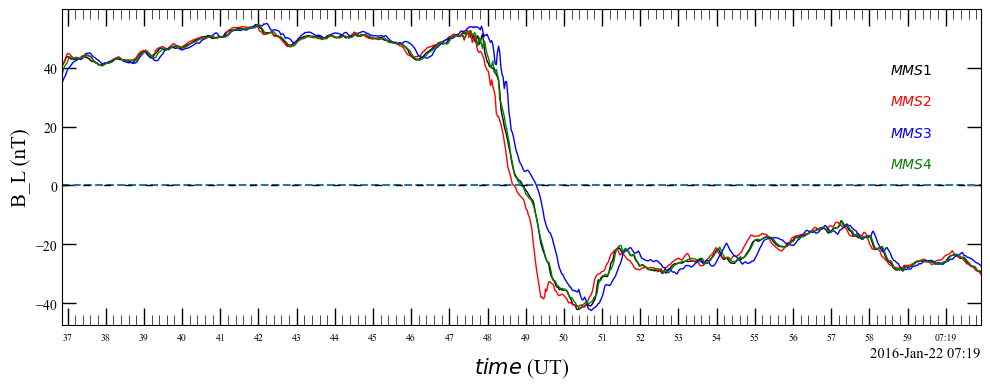

In [73]:

fig, axs = plt.subplots(1, 1, figsize=[10, 4], sharex=True)
axs.plot(TA3.time.sel(time=slice(del3,del4)),TA1.isel(LMN=0),c='k',lw=1, label='B_L')
axs.plot(TA3.time.sel(time=slice(del3,del4)),TA2.isel(LMN=0),c='r',lw=1, label='B_L')
axs.plot(TA3.time.sel(time=slice(del3,del4)),TA3.isel(LMN=0),c='b',lw=1, label='B_L')
axs.plot(TA3.time.sel(time=slice(del3,del4)),TA4.isel(LMN=0),c='g',lw=1, label='B_L')


#axs.plot(mms1i_bdataset.time.sel(time=slice(del3,del4)),mms1i_bdataset.mms1_fgm_b_gse_brst_l2.sel(v_dim=2,time=slice(del3,del4)) , c='k', lw=1,label='Bx')
#axs.plot(mms2i_bdataset.time.sel(time=slice(del3,del4)),mms2i_bdataset.mms2_fgm_b_gse_brst_l2.sel(v_dim=2,time=slice(del3,del4)) , c='r', lw=1,label='Bx')
#axs.plot(mms3i_bdataset.time.sel(time=slice(del3,del4)),mms3i_bdataset.mms3_fgm_b_gse_brst_l2.sel(v_dim=2,time=slice(del3,del4)), c='b', lw=1,label='Bx')
#axs.plot(mms4i_bdataset.time.sel(time=slice(del3,del4)),mms4i_bdataset.mms4_fgm_b_gse_brst_l2.sel(v_dim=2,time=slice(del3,del4)), c='g', lw=1,label='Bx')
axs.annotate(r'$\mathit{MMS1}$', xy=(0.9,0.8), xycoords='axes fraction', style='italic',
             fontsize=10, color='k', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs.annotate(r'$\mathit{MMS2}$', xy=(0.9, 0.7), xycoords='axes fraction', style='italic',
             fontsize=10, color='r', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs.annotate(r'$\mathit{MMS3}$', xy=(0.9, 0.6), xycoords='axes fraction', style='italic',
             fontsize=10, color='b', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs.annotate(r'$\mathit{MMS4}$', xy=(0.9, 0.5), xycoords='axes fraction', style='italic',
             fontsize=10, color='g', xytext=(1, -1), textcoords='offset points')  # Annotation for By in green
axs.set_ylabel(r'$\mathbf{\mathit{B_{L}}}$' + '\n' + r'$\mathit{[nT]}$', fontsize=10)
plt.grid(False)
plt.axhline(y=0, linestyle='--')


# Plot the data

#plt.yticks(np.arange(np.round(np.min(TA3.sel(LMN=0)), -B) - 10**B, 
 #                    np.round(np.max(TA3), -B)+ 10**B, 
#                     10 * B))
#plt.yticks(np.arange(np.round(np.min(TA3.sel(LMN=0)), -B) - 10**B, 
#                     np.round(np.max(TA3), -B)+ 10**B, 
#                     2*B), 
#           minor=True)

plt.xticks(xticks(del3,del4)[0])

    # Set minor x-axis ticks
plt.xticks(xticks(del3,del4)[1], minor=True)

#plt.axvline(Bz[0].values,ls='--',c='r') #value obtained form below,change to MP crossing timestamp accordingly
plt.axhline(y=0, c='k',  ls=(0, (5, 10)), lw=1)
# Axis labels
plt.xlabel(r'$\mathit{time}$ (UT)', fontsize=15, labelpad=10)
plt.ylabel('B_L (nT)', fontsize=15)

# Adjust tick parameters
plt.tick_params(axis='x', which='major', labelsize=7, size=12, width=1, length=15, pad=5, direction='in', top=True, bottom=True)
plt.tick_params(axis='x', which='minor', labelsize=7, size=7, width=0.5, length=9, pad=1, direction='in', top=True, bottom=True)
plt.tick_params(axis='y', which='major', direction='in', left=True, right=True, width=1, length=10, labelsize=10)
plt.tick_params(axis='y', which='minor', direction='in', left=True, right=True, width=0.5, length=6, labelsize=10)
plt.xlim(TA3.time.sel(time=nested_mva.isel(intervals=400).time[0], method="nearest"), TA3.time.sel(time=nested_mva.isel(intervals=400).time[1],method='nearest'))
plt.tight_layout(pad=1.0)
plt.savefig(os.path.join(output_folder, f"{taistarttime}_f.png"), dpi=300)
plt.show()                            

# DeHoffman Teller Anlysis

In [74]:
vi = idatasets_interp['mms4'].mms4_dis_bulkv_gse_brst.sel(time=slice(del3,del4),v_dim=slice(0,3))
ve = edatasets_interp['mms4'].mms4_des_bulkv_gse_brst.sel(time=slice(del3,del4),v_dim=slice(0,3))
ni = idatasets_interp['mms4'].mms4_dis_numberdensity_brst.sel(time=slice(del3,del4))
mi = 1.67262192369e-27  # kg
me = 9.1093837015e-31  # kg
mu_0 = 4*np.pi * 1e-7*1e3
v_bulk = (mi*vi+me*ve)/(mi+me)
b  = get_data(del3,del4)[1].sel(spacecraft=2)

# Basic checks
if v_bulk.dims != b.dims:
     raise ValueError(f"Dimension mismatch: {v_bulk.dims} vs {b.dims}")
if "time" not in v_bulk.dims or "v_dim" not in v_bulk.dims:
       raise ValueError("Expected dims ('time', 'v_dim')")

 # Convert to numpy for linear algebra
vb = v_bulk.values   # shape (M, 3)
B = b.values        # shape (M, 3)

M = vb.shape[0]
I = np.eye(3)

K_sum = np.zeros((3, 3))
rhs_sum = np.zeros(3)

for vm, Bm in zip(vb, B):
    B2 = np.dot(Bm, Bm)
    Km = B2 * I - np.outer(Bm, Bm)
    K_sum += Km
    rhs_sum += Km @ vm

K0_np = K_sum / M
rhs_np = rhs_sum / M

V_ht_np = np.linalg.solve(K0_np, rhs_np)
# Wrap back into xarray"
V_ht = xr.DataArray( V_ht_np,
        dims=["v_dim"],
        coords={"v_dim": v_bulk.coords["v_dim"]},
        name="V_HT"
    )
V_ht.values,np.dot(V_ht,n),vb # it should be -ve: 

(array([ -54.09698548, -103.93311473, -123.78627171]),
 np.float64(-42.450201702362236),
 array([[ -46.36954804,  -30.77553821, -177.68732471],
        [ -47.32470233,  -30.30640137, -176.86282899],
        [ -47.85293873,  -29.89102851, -176.48389883],
        ...,
        [ -47.88869737,   56.34252817,  -30.78543788],
        [ -47.84489393,   56.65504715,  -31.29631447],
        [ -47.98938577,   56.99329116,  -31.8536832 ]], shape=(1533, 3)))

In [75]:
np.dot(V_ht,mms4.eigenvec.sel(LMN=0)),np.dot(V_ht,mms4.eigenvec.sel(LMN=1)),np.dot(V_ht,mms4.eigenvec.sel(LMN=2))

(np.float64(-114.97144079658045),
 np.float64(119.07077083828243),
 np.float64(-40.685827689284835))

In [76]:
v

<xarray.Dataset> Size: 112B
Dimensions:   (ratios: 2, values: 3, vec: 3, LMN: 3)
Dimensions without coordinates: ratios, values, vec, LMN
Data variables:
    eigenrat  (ratios) float64 16B 12.06 21.41
    eigenval  (values) float64 24B 1.281e+03 106.2 4.96
    eigenvec  (vec, LMN) float64 72B 0.05881 -0.05699 ... -0.1032 -0.06447

In [77]:
vi = idatasets_interp['mms3'].mms3_dis_bulkv_gse_brst.sel(time=slice(del3,del4),v_dim=slice(0,3))
ve = edatasets_interp['mms3'].mms3_des_bulkv_gse_brst.sel(time=slice(del3,del4),v_dim=slice(0,3))
ni = idatasets_interp['mms3'].mms3_dis_numberdensity_brst.sel(time=slice(del3,del4))
mi = 1.67262192369e-27  # kg
me = 9.1093837015e-31  # kg
mu_0 = 4*np.pi * 1e-7*1e3
v_bulk = (mi*vi+me*ve)/(mi+me)
B  = get_data(del3,del4)[1].sel(spacecraft=2)

def compute_K_matrix(B_m):
    B_squared = np.dot(B_m, B_m)  # B^2 = B_x^2 + B_y^2 + B_z^2
    delta = np.eye(3)             # Kronecker delta, identity matrix of shape 3x3
    outer_product = np.outer(B_m, B_m)  # B_mu * B_nu

    # K(m) = B^2 * (delta - (B_mu * B_nu) / B^2)
    K_m = B_squared * (delta - outer_product / B_squared)
    return K_m

# Apply the function to all time steps
K_matrices = np.array([compute_K_matrix(B_m) for B_m in B])

from numpy.linalg import inv
# Number of measurements (time steps)
M = v_bulk.shape[0]

# Compute K_0 and the averaged term K(m) v(m)
K_0 = np.mean(K_matrices, axis=0)  # Averaged K(m)

# Compute K(m) v(m) for each time step and average
Kv_sum = np.zeros(3)
for m in range(M):
    Kv_sum += np.dot(K_matrices[m], v_bulk[m])

TA = Kv_sum / M
# Solve for V_HT
V_HT = np.dot(inv(K_0), TA)
V_ht = np.linalg.norm(V_HT)
V_HT,V_ht,np.dot(V_HT,n),V


(array([ -52.91671704, -102.9768738 , -121.16058966]),
 np.float64(167.58372226173037),
 np.float64(-41.5422516524604),
 np.float64(46.760327402428054))

# MDD Analsysis


In [78]:
def mdd(t1,t2):
    B = get_data(t1,t2)[1].transpose('time','spacecraft','v_dim')
    R = get_data(t1,t2)[2].transpose('time','spacecraft','v_dim')

    delR12  = R.sel(spacecraft=1) - R.sel(spacecraft=0)
    delR13  = R.sel(spacecraft=2) - R.sel(spacecraft=0)
    delR14  = R.sel(spacecraft=3) - R.sel(spacecraft=0)
    delR24  = R.sel(spacecraft=3) - R.sel(spacecraft=1)
    delR34  = R.sel(spacecraft=3) - R.sel(spacecraft=2)
    delR23  = R.sel(spacecraft=2) - R.sel(spacecraft=1)

    unitb = B / np.sqrt(np.sum(B**2, axis=-1))
    #Bsqb = unitb*np.su
    
    Bsqb = B*np.sqrt(np.sum(B**2, axis=-1))

    k1 = xr.cross(delR23,delR24,dim='v_dim')
    k2 = -xr.cross(delR34,delR13,dim='v_dim')
    k3 = xr.cross(delR14,delR24,dim='v_dim')
    k4 = xr.cross(delR12,delR13,dim='v_dim')

    v1 = xr.dot(-delR12, xr.cross(delR23, delR24,dim='v_dim'),dim=['v_dim'])
    v2 = xr.dot(delR23, xr.cross(delR34, delR13,dim='v_dim'),dim=['v_dim'])
    v3 = xr.dot(-delR34, xr.cross(delR14, delR24,dim='v_dim'),dim=['v_dim'])
    v4 = xr.dot(delR14, xr.cross(delR12, delR13,dim='v_dim'),dim=['v_dim'])
    
    rec = xr.concat([k1/v1,k2/v2,k3/v3,k4/v4], dim='spacecraft').transpose('time','spacecraft','v_dim') # reciprocal vectors"

    divB = xr.dot(B,rec,dim='v_dim').sum(dim='spacecraft')
    curlB = xr.cross(rec,B,dim='v_dim').sum(dim='spacecraft')
    gradB = xr.apply_ufunc(np.matmul, B.transpose('time','v_dim','spacecraft'), rec, 
                       input_core_dims=[['v_dim', 'spacecraft'],['spacecraft','v_dim']], 
                       output_core_dims=[['dim1','dim2']],dask='parallelized', vectorize=True)
    gradb = xr.apply_ufunc(np.matmul, unitb.transpose('time','v_dim','spacecraft'), rec, 
                       input_core_dims=[['v_dim', 'spacecraft'],['spacecraft','v_dim']], 
                       output_core_dims=[['dim1','dim2']],dask='parallelized', vectorize=True)
    curvB = xr.apply_ufunc(np.matmul, Bsqb,gradb, 
                       input_core_dims=[['spacecraft','v_dim'],['dim1','dim2']], 
                       output_core_dims=[['spacecraft','curvature']],dask='parallelized', vectorize=True)

    # Construting symmetric matrix
    graBT_gradB = xr.apply_ufunc(np.matmul, gradB.transpose('time','dim2','dim1'), gradB.transpose('time','dim1','dim2'), 
                       input_core_dims=[['dim2', 'dim1'],['dim1','dim2']], 
                       output_core_dims=[['dim1','dim2']],dask='parallelized', vectorize=True)
    single_eigen_mdd = xr.apply_ufunc(np.linalg.eigh, graBT_gradB.mean(dim='time'), 
                       input_core_dims=[['dim1', 'dim2']], 
                       output_core_dims=[['dim1'],['dim1','dim2']],dask='parallelized', vectorize=True)
    multiple_eigen_mdd = xr.apply_ufunc(np.linalg.eigh, graBT_gradB, 
                       input_core_dims=[['dim1', 'dim2']], 
                       output_core_dims=[['dim1'],['dim1','dim2']],dask='parallelized', vectorize=True)
    w_single = single_eigen_mdd[0].values
    v_single = single_eigen_mdd[1].values
    
    w_index = np.abs(w_single)
    idx = np.flip(np.argsort(w_index))
    w = np.sort(w_single)[::-1]  # max(N),mid(M),min(L)
    v = v_single[:, idx]  # NML
    
    if v[0, 0] < 0:# Ensure maxgrad direction is along +x (for FAC system)
        v[:, 0] = - v[:, 0]
        
    if v[2,2] < 0:# Ensure mingrad direction is along +Z (for FAC system)
        v[:,2] = - v[:, 2]
       
    # Rotate intermediate var direction if system is not Right Handed
    if v[0, 0] * (v[1, 1] * v[2, 2] - v[2, 1] * v[1, 2]) > 0:
        v[:,1] = -v[:,1]
    # Calculate ratios of sorted eigenvalues
    lambda_n_m = w[0] / w[1]
    lambda_m_l = w[1] / w[2]
    v[:, [0, 2]] = v[:, [2, 0]]
    LMN = xr.Dataset({'eigenrat':xr.DataArray(np.array([lambda_m_l,lambda_n_m]),dims=['ratios']),
                      'eigenval':xr.DataArray(w,dims=['values']),
                      'eigenvec':xr.DataArray(v,dims=['vec','LMN'])})
    
    return [w,v,LMN,lambda_n_m,lambda_m_l,multiple_eigen_mdd,curlB]

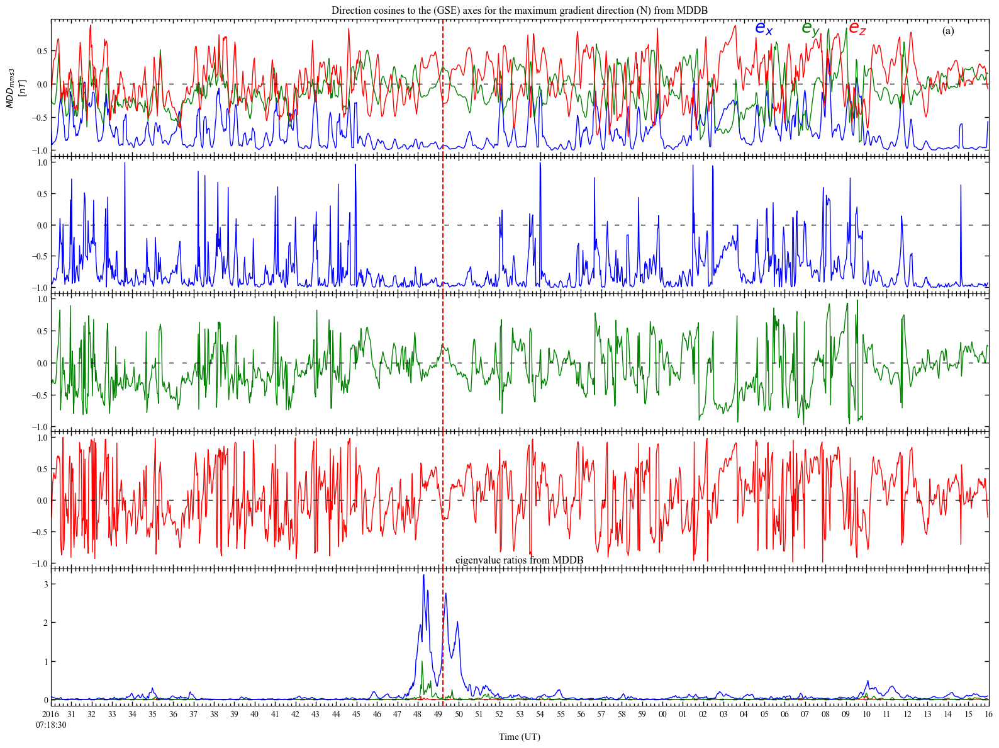

In [82]:
fig, axs = plt.subplots(5, 1, figsize=[16, 12], sharex=True, gridspec_kw={'hspace': 0})

def convolve(data):
    return np.convolve(data, np.ones(5)/5, mode='same')

# ------------------------------------------------------------------
# Panel (a) – direction cosines (smoothed)
# ------------------------------------------------------------------
t = mdd(del3, del4)[5][1].time
data = mdd(del3, del4)[5][1]

axs[0].plot(t, xr.apply_ufunc(convolve, data.isel(dim2=2, dim1=0)), c='b', lw=1, label='ex')
axs[0].plot(t, xr.apply_ufunc(convolve, data.isel(dim2=2, dim1=1)), c='g', lw=1, label='ey')
axs[0].plot(t, xr.apply_ufunc(convolve, data.isel(dim2=2, dim1=2)), c='r', lw=1, label='ez')

axs[0].text(0.95, 0.95, '(a)', transform=axs[0].transAxes, fontsize=13, va='top')
axs[0].annotate(r'$\mathit{e_x}$', xy=(0.75, 0.9), xycoords='axes fraction',
                fontsize=20, color='b', style='italic')
axs[0].annotate(r'$\mathit{e_y}$', xy=(0.80, 0.9), xycoords='axes fraction',
                fontsize=20, color='g', style='italic')
axs[0].annotate(r'$\mathit{e_z}$', xy=(0.85, 0.9), xycoords='axes fraction',
                fontsize=20, color='r', style='italic')

axs[0].set_ylabel(r'$\mathbf{\mathit{MDD_{mms3}}}$' + '\n' + r'$\mathit{[nT]}$', fontsize=10)
axs[0].set_title('Direction cosines to the (GSE) axes for the maximum gradient direction (N) from MDDB',
                 fontsize=12)

# ------------------------------------------------------------------
# Panels (b)–(d) – raw components
# ------------------------------------------------------------------
axs[1].plot(t, data.isel(dim2=2, dim1=0), c='b', lw=1, label='Bl')
axs[2].plot(t, data.isel(dim2=2, dim1=1), c='g', lw=1, label='Bm')
axs[3].plot(t, data.isel(dim2=2, dim1=2), c='r', lw=1, label='Bn')

# ------------------------------------------------------------------
# Panel (e) – eigenvalue ratios
# ------------------------------------------------------------------
axs[4].set_title('eigenvalue ratios from MDDB', fontsize=12)
ev = mdd(del3, del4)[5][0]
axs[4].plot(ev.time, ev.isel(dim1=0), c='r', lw=1)
axs[4].plot(ev.time, ev.isel(dim1=1), c='g', lw=1)
axs[4].plot(ev.time, ev.isel(dim1=2), c='b', lw=1)

# ------------------------------------------------------------------
# Common x-axis limits & ticks (using your xticks helper)
# ------------------------------------------------------------------
t_start = t[0].values          # or data.time[0].values
t_end   = t[-1].values

major_ticks, minor_ticks, major_tick_labels = xticks(t_start, t_end)

for ax in axs:
    ax.set_xlim(t_start, t_end)

    # ticks
    ax.set_xticks(major_ticks)
    ax.set_xticks(minor_ticks, minor=True)
    ax.set_xticklabels(major_tick_labels, rotation=0, fontsize=9)

    # tick appearance
    ax.tick_params(axis='both', which='major', direction='in',
                   top=True, right=True, width=1, length=5, labelsize=10)
    ax.tick_params(axis='both', which='minor', direction='in',
                   top=True, right=True, width=1, length=3, labelsize=9)
    ax.tick_params(axis='x', which='major', pad=5)
    ax.tick_params(axis='x', which='minor', pad=1)

    # reference lines
    ax.axhline(y=0, c='k', ls=(0, (5, 10)), lw=1)
    ax.axvline(x=Bz[0].values, ls='--', c='r')                     # MP crossing
    ax.axvline(x=np.datetime64('2015-10-16T13:05:43.5'), ls='-', c='y')
    ax.axvline(x=np.datetime64('2015-10-16T13:05:48'),   ls='-', c='y')

# Only the bottom panel needs the x-label (optional)
axs[-1].set_xlabel('Time (UT)', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, f"{taistarttime}_mdd.png"), dpi=100, bbox_inches='tight')
plt.show()

In [83]:
v1=mdd(del3,del4)[2]
v1

<xarray.Dataset> Size: 112B
Dimensions:   (ratios: 2, values: 3, vec: 3, LMN: 3)
Dimensions without coordinates: ratios, values, vec, LMN
Data variables:
    eigenrat  (ratios) float64 16B 3.377 3.879
    eigenval  (values) float64 24B 0.1166 0.03007 0.008904
    eigenvec  (vec, LMN) float64 72B -0.02426 0.1211 0.9923 ... 0.885 -0.09691

In [84]:
curlB = xr.apply_ufunc(np.matmul,
                       mdd(del3,del4)[6],
                       mms4.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')
mu_0 = (4*np.pi * 1e-7)
fgm_j=curlB/mu_0*1e-12*1e9

In [85]:
    """
    Compute divergence of a 3x3 pressure tensor field sampled by 4 spacecraft.

    P: xarray DataArray with dims ('time', 'spacecraft', 'v_dim', 'v2_dim')
       e.g. P_{ij} where v_dim=i, v2_dim=j
    R: spacecraft positions ('time', 'spacecraft', 'v_dim')
    Returns: DataArray ('time', 'v2_dim') — divergence vector
    """
    R = get_data(del3,del4)[2].transpose('time','spacecraft','v_dim')
    
    # Compute reciprocal vectors rec (same as your mdd)
    delR12 = R.sel(spacecraft=1) - R.sel(spacecraft=0)
    delR13 = R.sel(spacecraft=2) - R.sel(spacecraft=0)
    delR14 = R.sel(spacecraft=3) - R.sel(spacecraft=0)
    delR24 = R.sel(spacecraft=3) - R.sel(spacecraft=1)
    delR34 = R.sel(spacecraft=3) - R.sel(spacecraft=2)
    delR23 = R.sel(spacecraft=2) - R.sel(spacecraft=1)

    k1 = xr.cross(delR23, delR24, dim='v_dim')
    k2 = -xr.cross(delR34, delR13, dim='v_dim')
    k3 = xr.cross(delR14, delR24, dim='v_dim')
    k4 = xr.cross(delR12, delR13, dim='v_dim')

    v1 = xr.dot(-delR12, xr.cross(delR23, delR24, dim='v_dim'), dim='v_dim')
    v2 = xr.dot(delR23, xr.cross(delR34, delR13, dim='v_dim'), dim='v_dim')
    v3 = xr.dot(-delR34, xr.cross(delR14, delR24, dim='v_dim'), dim='v_dim')
    v4 = xr.dot(delR14, xr.cross(delR12, delR13, dim='v_dim'), dim='v_dim')

    rec = xr.concat([k1/v1, k2/v2, k3/v3, k4/v4],
                    dim='spacecraft').transpose('time','spacecraft','v_dim')
    eP1 = edatasets_interp['mms1'][f'{'mms1'}_des_prestensor_gse_brst'].sel(time=slice(del3,del4))
    eP2 = edatasets_interp['mms2'][f'{'mms2'}_des_prestensor_gse_brst'].sel(time=slice(del3,del4))
    eP3 = edatasets_interp['mms3'][f'{'mms3'}_des_prestensor_gse_brst'].sel(time=slice(del3,del4))
    eP4 = edatasets_interp['mms4'][f'{'mms4'}_des_prestensor_gse_brst'].sel(time=slice(del3,del4))

    eP_concat = xr.concat([eP1,eP2,eP3,eP4],dim='spacecraft')
    eP_concat = eP_concat.rename({'v2_dim': 'v2', 'v_dim': 'v1'}).transpose('time','spacecraft','v1','v2')
    rec = rec.rename({'v_dim': 'v2'})  # (time, spacecraft, v1)
       
    edot_P_rec = xr.dot(eP_concat, rec, dims=['v2']).sum(dim='spacecraft')

    # Optional: rename v2 → v_dim for clarity
    edivP = edot_P_rec.rename({'v1': 'v_dim'})

    # Add metadata
    edivP.name = 'divPe'
    edivP.attrs['description'] = 'Divergence of electron pressure tensor (scalar product with reciprocal vectors)'
    edivP.attrs['units'] = 'nPa/km'

25-Oct-26 18:10:13: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\3370023559.py:40: PendingDeprecationWarning: The `dims` argument has been renamed to `dim`, and will be removed in the future. This renaming is taking place throughout xarray over the next few releases.
  edot_P_rec = xr.dot(eP_concat, rec, dims=['v2']).sum(dim='spacecraft')



In [86]:
    """
    Compute divergence of a 3x3 pressure tensor field sampled by 4 spacecraft.

    P: xarray DataArray with dims ('time', 'spacecraft', 'v_dim', 'v2_dim')
       e.g. P_{ij} where v_dim=i, v2_dim=j
    R: spacecraft positions ('time', 'spacecraft', 'v_dim')
    Returns: DataArray ('time', 'v2_dim') — divergence vector
    """
    R = get_data(del3,del4)[2].transpose('time','spacecraft','v_dim')
    
    # Compute reciprocal vectors rec (same as your mdd)
    delR12 = R.sel(spacecraft=1) - R.sel(spacecraft=0)
    delR13 = R.sel(spacecraft=2) - R.sel(spacecraft=0)
    delR14 = R.sel(spacecraft=3) - R.sel(spacecraft=0)
    delR24 = R.sel(spacecraft=3) - R.sel(spacecraft=1)
    delR34 = R.sel(spacecraft=3) - R.sel(spacecraft=2)
    delR23 = R.sel(spacecraft=2) - R.sel(spacecraft=1)

    k1 = xr.cross(delR23, delR24, dim='v_dim')
    k2 = -xr.cross(delR34, delR13, dim='v_dim')
    k3 = xr.cross(delR14, delR24, dim='v_dim')
    k4 = xr.cross(delR12, delR13, dim='v_dim')

    v1 = xr.dot(-delR12, xr.cross(delR23, delR24, dim='v_dim'), dim='v_dim')
    v2 = xr.dot(delR23, xr.cross(delR34, delR13, dim='v_dim'), dim='v_dim')
    v3 = xr.dot(-delR34, xr.cross(delR14, delR24, dim='v_dim'), dim='v_dim')
    v4 = xr.dot(delR14, xr.cross(delR12, delR13, dim='v_dim'), dim='v_dim')

    rec = xr.concat([k1/v1, k2/v2, k3/v3, k4/v4],
                    dim='spacecraft').transpose('time','spacecraft','v_dim')
    iP1 = idatasets_interp['mms1'][f'{'mms1'}_dis_prestensor_gse_brst'].sel(time=slice(del3,del4))
    iP2 = idatasets_interp['mms2'][f'{'mms2'}_dis_prestensor_gse_brst'].sel(time=slice(del3,del4))
    iP3 = idatasets_interp['mms3'][f'{'mms3'}_dis_prestensor_gse_brst'].sel(time=slice(del3,del4))
    iP4 = idatasets_interp['mms4'][f'{'mms4'}_dis_prestensor_gse_brst'].sel(time=slice(del3,del4))

    iP_concat = xr.concat([iP1,iP2,iP3,iP4],dim='spacecraft')
    iP_concat = iP_concat.rename({'v2_dim': 'v2', 'v_dim': 'v1'}).transpose('time','spacecraft','v1','v2')
    rec = rec.rename({'v_dim': 'v2'})  # (time, spacecraft, v1)
       
    idot_P_rec = xr.dot(iP_concat, rec, dims=['v2']).sum(dim='spacecraft')

    # Optional: rename v2 → v_dim for clarity
    idivP = idot_P_rec.rename({'v1': 'v_dim'})

    # Add metadata
    idivP.name = 'idivP'
    idivP.attrs['description'] = 'Divergence of ion pressure tensor (scalar product with reciprocal vectors)'
    idivP.attrs['units'] = 'nPa/km'

25-Oct-26 18:10:15: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\2793349522.py:40: PendingDeprecationWarning: The `dims` argument has been renamed to `dim`, and will be removed in the future. This renaming is taking place throughout xarray over the next few releases.
  idot_P_rec = xr.dot(iP_concat, rec, dims=['v2']).sum(dim='spacecraft')



# Plasma Calculations

In [95]:
def transform_tensor(P):
    return xr.apply_ufunc(
        lambda p, r: np.matmul(np.swapaxes(r, -1, -2), np.matmul(p, r)),
        P, eigvec,
        input_core_dims=[['v1', 'v2'], ['vec', 'LMN']],
        output_core_dims=[['LMN1', 'LMN2']],
        vectorize=True,
        dask='allowed',
        output_dtypes=[P.dtype]
    )


In [96]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
mu_0 = 4 * np.pi * 1e-7 * 1e3  # nT·km/A
m_p = 1.67e-27
m_e = 9.10938356e-31
q_e = 1.602176634e-19
def alfven_speed(B, n, m):
    return 1e-3 * np.abs(1e-9 * B) / np.sqrt(mu_0 * 1e6 * n * m)
    
def hall_current(vi, ve):
    return 1e6 * 1e3 * 1e9 * q_e * (vi - ve) #cm-3 to m-3, A-nA, km-s = nA/m-2

datasets = {}
hall={}
for sc in sc_list:
    print(f"Processing {sc.upper()}...")

    # Load data
    ni = idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"].sel(time=slice(del3, del4)) #cm-3
    ne = edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4))
    vi = idatasets_interp[sc][f"{sc}_dis_bulkv_gse_brst"].sel(time=slice(del3, del4), v_dim=slice(0, 3)) #kms-1
    ve = edatasets_interp[sc][f"{sc}_des_bulkv_gse_brst"].sel(time=slice(del3, del4), v_dim=slice(0, 3))
    B  = globals()[f"{sc}i_brdataset"][f"{sc}_fgm_b_gse_brst_l2"].sel(time=slice(del3, del4), v_dim=slice(0, 3)) #nT-1
    E  = globals()[f"{sc}i_Edataset"].sel(time=slice(del3, del4), v_dim=slice(0, 3)) #mV/m
    eigvec = globals()[sc].eigenvec

    # Transform from GSE to LMN using eivenvec
    def transform(vec):
        return xr.apply_ufunc(
            np.matmul, vec, eigvec,
            input_core_dims=[['time', 'v_dim'], ['vec', 'LMN']],
            output_core_dims=[['time', 'LMN']], dask='allowed'
        )

    lmn_b = transform(B)
    lmn_e = transform(E)
    
    mag_lmn_b = np.sqrt((lmn_b ** 2).sum(dim='LMN'))

    # Transform tensor from GSE to LMN using eigvec
    def transform_tensor(P):
        return xr.apply_ufunc(lambda p, r: np.matmul(np.swapaxes(r, -1, -2), np.matmul(p, r)),
        P, eigvec,
        input_core_dims=[['v_dim', 'v2_dim'], ['vec', 'LMN']],
        output_core_dims=[['LMN1', 'LMN2']],
        vectorize=True,
        dask='allowed',
        output_dtypes=[P.dtype])
        
    iP_lmn = transform_tensor(idatasets_interp[sc][f'{sc}_dis_prestensor_gse_brst'].sel(time=slice(del3,del4)))
    eP_lmn = transform_tensor(edatasets_interp[sc][f'{sc}_des_prestensor_gse_brst'].sel(time=slice(del3,del4)))

    eDivP = transform(edivP)*(1e-3)*(1e-9)*(1e3)    # km-m, nPa-Pa,V-mV
    
    iDivP = transform(idivP)*(1e-3)*(1e-9)*(1e3)
    lmn_vi = transform(vi)
    lmn_ve = transform(ve)

    def gradient_time(arr, time):
        return np.gradient(arr, time, axis=0) 

    time_seconds = ve['time'].astype('datetime64[ns]').astype(float) * 1e-9  # convert ns to s

    dvedt = xr.apply_ufunc(
    gradient_time,
    lmn_ve,
    time_seconds,
    input_core_dims=[['time', 'LMN'], ['time']],
    output_core_dims=[['time', 'LMN']],
    vectorize=True)*(-1e6)*(9.10938356e-31/q_e)

    dvidt = xr.apply_ufunc(
    gradient_time,
    lmn_vi,
    time_seconds,
    input_core_dims=[['time', 'LMN'], ['time']],
    output_core_dims=[['time', 'LMN']],
    vectorize=True)*(-1e6)*(m_p/q_e)

    V_a = xr.apply_ufunc(alfven_speed, lmn_b.sel(LMN=0), ni,m_p)

    j_fpi = xr.apply_ufunc(
        hall_current, ne * vi, ne * ve,
        input_core_dims=[['v_dim'], ['v_dim']],
        output_core_dims=[['v_dim']],
        vectorize=True
    )
    
    lmn_j = xr.apply_ufunc(
        np.matmul, j_fpi, eigvec,
        input_core_dims=[['time', 'v_dim'], ['vec', 'LMN']],
        output_core_dims=[['time', 'LMN']], dask='allowed'
    )
    
    jxb = xr.apply_ufunc(
    np.cross, lmn_j, lmn_b,
    input_core_dims=[['LMN'], ['LMN']],  # last dim of each array is the vector
    output_core_dims=[['LMN']],          # cross product is also a 3-component vector
    vectorize=True,                      # vectorizes over other dimensions like 'time'
    dask='allowed')*(1e3)*(1e-9)**2

    

    vib = -xr.cross(lmn_vi, lmn_b, dim='LMN') *(1e3)*(1e-9)*(1e3)
    veb = -xr.cross(lmn_ve, lmn_b, dim='LMN') *(1e3)*(1e-9)*(1e3)
    ExB = xr.cross(lmn_e, lmn_b, dim='LMN')*(1e3)/ (mag_lmn_b**2)


    #LMN to LN plane
    # Rename to avoid LMN dimension conflict for 2D (LN) calculations
    ln_b = lmn_b.sel(LMN=[0, 2]).rename({'LMN': 'LN'})
    ln_j = lmn_j.sel(LMN=[0, 2]).rename({'LMN': 'LN'})
    ln_e = lmn_e.sel(LMN=[0, 2]).rename({'LMN': 'LN'})

    ln_b_unit = ln_b / np.linalg.norm(ln_b, axis=1, keepdims=True)

    def project_ln(vec, ln_b_unit):
        return xr.dot(ln_b_unit, vec, dim='LN') * ln_b_unit

    proj_ln_j = project_ln(ln_j, ln_b_unit)
    proj_ln_e = project_ln(ln_e, ln_b_unit)

    par_ln_j = xr.dot(proj_ln_j, ln_b_unit, dim='LN')
    per_ln_j = xr.apply_ufunc(np.linalg.norm, ln_j - proj_ln_j,
                              input_core_dims=[['LN']], output_core_dims=[[]], vectorize=True)

    par_ln_e = xr.dot(proj_ln_e, ln_b_unit, dim='LN')
    per_ln_e = xr.apply_ufunc(np.linalg.norm, ln_e - proj_ln_e,
                              input_core_dims=[['LN']], output_core_dims=[[]], vectorize=True)

    jdote0 = xr.dot(lmn_j, lmn_e-veb, dim='LMN')*1e-3
    jdotepa0 = xr.dot(lmn_j, par_ln_e, dim='LMN')*1e-3
    jdotepe0 = xr.dot(lmn_j, per_ln_e, dim='LMN')*1e-3
    
    #lmn plane
    
    bhat = lmn_b / np.sqrt((lmn_b**2).sum('LMN'))
    jdote1 = xr.dot(lmn_j, lmn_e, dim='LMN')*1e-3
    
    jdote_para1 = xr.dot(xr.dot(lmn_j, bhat, dim='LMN')*bhat, lmn_e, dim='LMN')*1e-3
    jdote_perp1 = xr.dot(lmn_j - xr.dot(lmn_j, bhat, dim='LMN')*bhat, lmn_e, dim='LMN')*1e-3

    jdote2= xr.dot(lmn_j, lmn_e+veb, dim='LMN')*1e-3
    jdote_para2 = xr.dot(xr.dot(lmn_j, bhat, dim='LMN')*bhat, lmn_e+veb, dim='LMN')*1e-3
    jdote_perp2 = xr.dot(lmn_j - xr.dot(lmn_j, bhat, dim='LMN')*bhat, lmn_e+veb, dim='LMN')*1e-3

    
    curlB = xr.apply_ufunc(np.matmul,
                       mdd(del3,del4)[6],
                       mms3.eigenvec,
                       input_core_dims=[['time','v_dim'],['vec','LMN']],
                       output_core_dims=[['time','LMN']],
                       dask='allowed')
    mu_0 = (4*np.pi * 1e-7)
    fgm_j=curlB/mu_0*1e-12*1e9
    # Store all in xarray.Dataset
    ds = xr.Dataset({
        'ni': ni,
        'ne': ne,
        'V_a': V_a,
        'j_fpi': j_fpi,
        'lmn_b': lmn_b,
        'mag_lmn_b': mag_lmn_b,
        'lmn_e': lmn_e,
        'lmn_vi': lmn_vi,
        'lmn_ve': lmn_ve,
        'lmn_j': lmn_j,
        'vib': vib,
        'veb': veb,
        'ExB': ExB,
        'ln_b_unit': ln_b_unit,
        'ln_j': ln_j,
        'par_ln_j': par_ln_j,
        'per_ln_j': per_ln_j,
        'ln_e': ln_e,
        'par_ln_e': par_ln_e,
        'jdote1':jdote1,
        'jdote_para1': jdote_para1,
        'jdote_perp1': jdote_perp1,
        'jdote2':jdote2,
        'jdote_para2': jdote_para2,
        'jdote_perp2': jdote_perp2,
        'per_ln_e': per_ln_e,
        'fgm_j': fgm_j,
        'jxb':jxb/(ni*(1e6)*q_e),
        'dvedt':dvedt,
        'dvidt':dvidt,
        'eDivP':eDivP/(ne*(1e6)*q_e),
        'iDivP':iDivP/(ni*(1e6)*q_e),
        'iPlmn': iP_lmn,
        'ePlmn': eP_lmn
    })

    hall[sc] = ds

Processing MMS1...
Processing MMS2...
Processing MMS3...
Processing MMS4...


In [97]:
import pandas as pd
import xarray as xr

# ============================================================
# Extract B (bl, bm, bn, |B|) + E (el, em, en) for ALL spacecraft
# and save to Excel (one sheet per spacecraft)
# ============================================================

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

# Dictionary to hold DataFrames for each spacecraft
excel_data = {}

for sc in sc_list:
    print(f"Extracting B & E for {sc.upper()}...")
    
    ds = hall[sc]
    
    # ----- Magnetic field (nT) -----
    bl    = ds['lmn_b'].sel(LMN=0)
    bm    = ds['lmn_b'].sel(LMN=1)
    bn    = ds['lmn_b'].sel(LMN=2)
    b_mag = ds['mag_lmn_b']
    
    # ----- Electric field (mV/m) -----
    el = ds['lmn_e'].sel(LMN=0)
    em = ds['lmn_e'].sel(LMN=1)
    en = ds['lmn_e'].sel(LMN=2)
    
    # Convert to pandas DataFrame (time as index)
    df = pd.DataFrame({
        'bl (nT)'  : bl.values,
        'bm (nT)'  : bm.values,
        'bn (nT)'  : bn.values,
        '|B| (nT)' : b_mag.values,
        'el (mV/m)': el.values,
        'em (mV/m)': em.values,
        'en (mV/m)': en.values,
    }, index=pd.to_datetime(bl['time'].values))
    
    df.index.name = 'time'
    
    excel_data[sc] = df

# ------------------------------------------------------------
# Save all spacecraft into one Excel file (separate sheets)
# ------------------------------------------------------------
output_file = 'MMS_B_E_LMN_all_spacecraft.xlsx'

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for sc, df in excel_data.items():
        df.to_excel(writer, sheet_name=sc.upper(), float_format='%.6f')

print(f"\n✅ Saved successfully → {output_file}")
print("Sheets:", list(excel_data.keys()))

Extracting B & E for MMS1...
Extracting B & E for MMS2...
Extracting B & E for MMS3...
Extracting B & E for MMS4...

✅ Saved successfully → MMS_B_E_LMN_all_spacecraft.xlsx
Sheets: ['mms1', 'mms2', 'mms3', 'mms4']


In [98]:
minD = ds['lmn_vi']
minD.sel(LMN=0).argmin('time')
print(minD.isel(time=minD.sel(LMN=0).argmin('time')))

<xarray.DataArray 'lmn_vi' (LMN: 3)> Size: 24B
array([-301.30578365,   45.2586745 ,  -39.38162495])
Coordinates:
    time     datetime64[ns] 8B 2016-01-22T07:18:46.549564
    epoch    datetime64[ns] 8B 2016-01-22T07:18:46.549564
Dimensions without coordinates: LMN
Attributes:
    CDF:           {'VATT': {'CATDESC': 'MMS4 FPI/DIS ion bulk-velocity vecto...
    data_att:      {'coord_sys': 'GSE', 'units': 'km/s', 'depend_1_units': 'k...
    plot_options:  {'xaxis_opt': {'axis_label': 'Time', 'crosshair': 'X', 'x_...


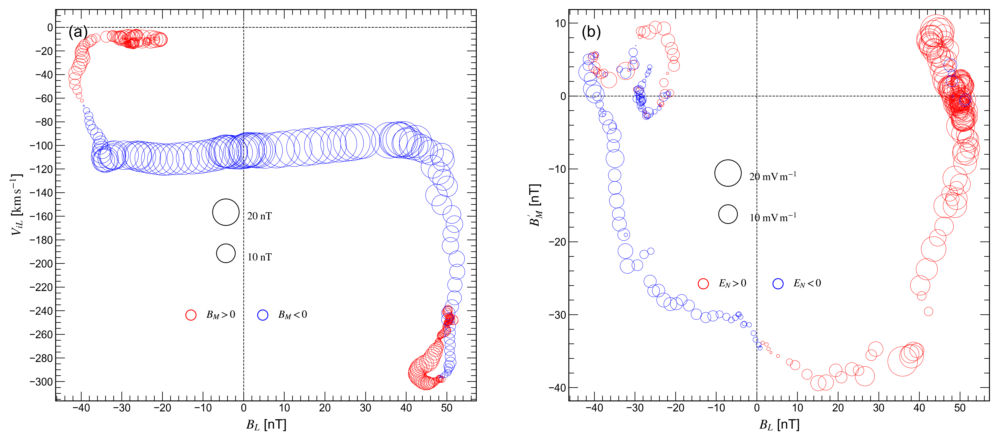

In [189]:
import logging
logging.getLogger("fontTools").setLevel(logging.WARNING)
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)
logging.getLogger("matplotlib.font_manager").setLevel(logging.WARNING)

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from matplotlib.transforms import blended_transform_factory

# ============================================================
# Bubble-scatter helper
# ============================================================
def bubble_scatter(
    ax,
    x,
    y,
    q,
    color,
    q_ref=20.0,
    s_ref=400.0,
    lw=0.25,
    alpha=1.0,
):
    """
    Draw hollow bubbles with area proportional to |q|.
    q = q_ref produces marker area s_ref.
    """
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()
    q = np.abs(np.asarray(q).ravel())
    good = (
        np.isfinite(x)
        & np.isfinite(y)
        & np.isfinite(q)
    )
    x = x[good]
    y = y[good]
    q = q[good]
    # Linear bubble-area scaling
    sizes = s_ref * (q / q_ref)
    sizes = np.clip(sizes, 0, None)
    return ax.scatter(
        x,
        y,
        s=sizes,
        facecolors="none",
        edgecolors=color,
        linewidths=lw,
        alpha=alpha,
        zorder=4,  # Data remain above legends
    )

# ============================================================
# Background-subtracted magnetic field
# ============================================================
B_g = df_all.loc[sc, "$B_g$"]
B_G = (
    hall[sc].lmn_b.sel(time=slice(del3, del4))
    - res_all[sc]["Bg_linear"]
)

# ============================================================
# Determine the central interval for panel (a)
# ============================================================
Bl_time = find(
    hall[sc].lmn_b,
    LMN=0,
    d1=del3,
    d2=del4,
)[0]

# Left B_M' maximum
BM_left = B_G.sel(
    LMN=1,
    time=slice(t1, Bl_time),
)
th_maxl = BM_left.time.isel(
    time=int(np.nanargmax(BM_left.values))
)

# Central B_M' minimum
BM_center = B_G.sel(
    LMN=1,
    time=slice(t1, t2),
)
th_min = BM_center.time.isel(
    time=int(np.nanargmin(BM_center.values))
)

# Right B_M' maximum
BM_right = B_G.sel(
    LMN=1,
    time=slice(Bl_time, t2),
)
th_maxr = BM_right.time.isel(
    time=int(np.nanargmax(BM_right.values))
)

# B_M' zero crossings
th_0 = find(
    B_G,
    LMN=1,
    d1=th_maxl,
    d2=Bl_time,
)[0]
th_1 = find(
    B_G,
    LMN=1,
    d1=th_min,
    d2=th_maxr,
)[0]
tmin = min(th_0, th_1)
tmax = max(th_0, th_1)

# ============================================================
# PANEL (a): B_L versus V_iL
# Bubble area = |B_M'|
# ============================================================
# Ion-velocity time grid
ViL = hall[sc].lmn_vi.sel(
    LMN=0,
    time=slice(del3, del4),
)

# Interpolate magnetic data to ion-velocity times
BL_ViL = hall[sc].lmn_b.sel(
    LMN=0,
    time=slice(del3, del4),
).interp(time=ViL.time)
BM_ViL = np.abs(
    B_G.sel(LMN=1).interp(time=ViL.time)
)

# Central-interval masks
mask_inside = (
    (ViL.time >= tmin)
    & (ViL.time <= tmax)
)
mask_outside = ~mask_inside

# ============================================================
# PANEL (b): B_L versus B_M'
# Bubble area = |E_N|
# ============================================================
# Electric-field time grid
EN = hall[sc].lmn_e.sel(
    LMN=2,
    time=slice(del3, del4),
)

# Interpolate magnetic data to electric-field times
BL_EN = hall[sc].lmn_b.sel(
    LMN=0,
    time=slice(del3, del4),
).interp(time=EN.time)
BMp_EN = B_G.sel(
    LMN=1
).interp(time=EN.time)

# Electric-field sign masks
mask_pos = EN > 0
mask_neg = EN < 0

# ============================================================
# Figure settings  (side-by-side)
# ============================================================
FIG_WIDTH  = 11.0      # wider
FIG_HEIGHT = 5.0       # shorter
DPI = 600
BUBBLE_LINEWIDTH = 0.25
GUIDE_LINEWIDTH  = 0.5
SPINE_LINEWIDTH  = 0.7
AXIS_LABEL_SIZE  = 10
TICK_LABEL_SIZE  = 8
PANEL_LABEL_SIZE = 12
LEGEND_SIZE      = 8

# ============================================================
# Create figure – side by side
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    dpi=DPI,
    sharex=True,                     # still share B_L axis
    gridspec_kw={"wspace": 0.22},    # horizontal spacing
)

# ============================================================
# PANEL (a)
# ============================================================
# Outside interval: red
bubble_scatter(
    ax=ax1,
    x=BL_ViL.where(mask_outside),
    y=ViL.where(mask_outside),
    q=BM_ViL.where(mask_outside),
    color="red",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)
# Inside interval: blue
bubble_scatter(
    ax=ax1,
    x=BL_ViL.where(mask_inside),
    y=ViL.where(mask_inside),
    q=BM_ViL.where(mask_inside),
    color="blue",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)

ax1.set_ylabel(
    r"$V_{iL}$ [$\mathrm{km\,s^{-1}}$]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax1.set_xlabel(
    r"$B_L$ [nT]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax1.text(
    0.03, 0.96, "(a)",
    transform=ax1.transAxes,
    fontsize=PANEL_LABEL_SIZE,
    fontweight="normal",
    ha="left", va="top",
)

# ============================================================
# PANEL (b)
# ============================================================
# Positive E_N: red
bubble_scatter(
    ax=ax2,
    x=BL_EN.where(mask_pos),
    y=BMp_EN.where(mask_pos),
    q=EN.where(mask_pos),
    color="red",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)
# Negative E_N: blue
bubble_scatter(
    ax=ax2,
    x=BL_EN.where(mask_neg),
    y=BMp_EN.where(mask_neg),
    q=EN.where(mask_neg),
    color="blue",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)

ax2.set_xlabel(
    r"$B_L$ [nT]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax2.set_ylabel(
    r"$B_M^{\prime}$ [nT]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax2.text(
    0.03, 0.96, "(b)",
    transform=ax2.transAxes,
    fontsize=PANEL_LABEL_SIZE,
    fontweight="normal",
    ha="left", va="top",
)

# ============================================================
# Common axis formatting
# ============================================================
for ax in (ax1, ax2):
    ax.axvline(x=0, linestyle="--", linewidth=GUIDE_LINEWIDTH, color="black", zorder=1)
    ax.axhline(y=0, linestyle="--", linewidth=GUIDE_LINEWIDTH, color="black", zorder=1)

    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.xaxis.set_minor_locator(MultipleLocator(2))

    ax.tick_params(
        axis="both", which="major",
        direction="in", length=7, width=0.5,
        labelsize=TICK_LABEL_SIZE,
        top=True, right=True, bottom=True, left=True, pad=2,
    )
    ax.tick_params(
        axis="both", which="minor",
        direction="in", length=4, width=0.5,
        top=True, right=True, bottom=True, left=True,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_LINEWIDTH)
        spine.set_color("black")

# Panel-specific y ticks
ax1.yaxis.set_major_locator(MultipleLocator(20))
ax1.yaxis.set_minor_locator(MultipleLocator(5))
ax2.yaxis.set_major_locator(MultipleLocator(10))
ax2.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend coordinate systems (x=0 still centres on B_L=0)
# ============================================================
legend_transform_1 = blended_transform_factory(ax1.transData, ax1.transAxes)
legend_transform_2 = blended_transform_factory(ax2.transData, ax2.transAxes)

# ============================================================
# PANEL (a): |B_M'| size legend
# ============================================================
size_handles_a = [
    ax1.scatter([], [], s=400, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$20\ \mathrm{nT}$"),
    ax1.scatter([], [], s=200, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$10\ \mathrm{nT}$"),
]
size_legend_a = ax1.legend(
    handles=size_handles_a,
    loc="center",
    bbox_to_anchor=(0, 0.42),
    bbox_transform=legend_transform_1,
    frameon=False,
    fontsize=LEGEND_SIZE,
    labelspacing=2.2,
    handleheight=2.2,
    handlelength=2.0,
    handletextpad=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.40],
    borderaxespad=0,
)
size_legend_a.set_zorder(2)
ax1.add_artist(size_legend_a)

# ============================================================
# PANEL (a): interval legend
# ============================================================
inside_handle_a  = ax1.scatter([], [], s=60, facecolors="none", edgecolors="red",
                               linewidths=0.6, label=r"$B_M>0$")
outside_handle_a = ax1.scatter([], [], s=60, facecolors="none", edgecolors="blue",
                               linewidths=0.6, label=r"$B_M<0$")
interval_legend_a = ax1.legend(
    handles=[inside_handle_a, outside_handle_a],
    loc="center",
    bbox_to_anchor=(0, 0.22),
    bbox_transform=legend_transform_1,
    ncol=2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    columnspacing=1.6,
    handletextpad=0.45,
    labelspacing=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.35],
    borderaxespad=0,
)
interval_legend_a.set_zorder(2)
ax1.add_artist(interval_legend_a)

# ============================================================
# PANEL (b): |E_N| size legend
# ============================================================
size_handles_b = [
    ax2.scatter([], [], s=400, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$20\ \mathrm{mV\,m^{-1}}$"),
    ax2.scatter([], [], s=200, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$10\ \mathrm{mV\,m^{-1}}$"),
]
size_legend_b = ax2.legend(
    handles=size_handles_b,
    loc="center",
    bbox_to_anchor=(0, 0.52),
    bbox_transform=legend_transform_2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    labelspacing=2.2,
    handleheight=2.2,
    handlelength=2.0,
    handletextpad=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.40],
    borderaxespad=0,
)
size_legend_b.set_zorder(2)
ax2.add_artist(size_legend_b)

# ============================================================
# PANEL (b): E_N sign legend
# ============================================================
positive_handle_b = ax2.scatter([], [], s=60, facecolors="none", edgecolors="red",
                                linewidths=0.6, label=r"$E_N>0$")
negative_handle_b = ax2.scatter([], [], s=60, facecolors="none", edgecolors="blue",
                                linewidths=0.6, label=r"$E_N<0$")
sign_legend_b = ax2.legend(
    handles=[positive_handle_b, negative_handle_b],
    loc="center",
    bbox_to_anchor=(0, 0.30),
    bbox_transform=legend_transform_2,
    ncol=2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    columnspacing=2.0,
    handletextpad=0.45,
    labelspacing=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.35],
    borderaxespad=0,
)
sign_legend_b.set_zorder(2)
ax2.add_artist(sign_legend_b)

# ============================================================
# Figure layout
# ============================================================
fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.14,
    top=0.96,
    wspace=0.22,
)

# ============================================================
# Save figure
# ============================================================
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"]  = 42

base_output_path = os.path.join(
    output_folder,
    f"{taistarttime}_combined_{sc}_sidebyside",
)

fig.savefig(
    base_output_path + ".pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.01,
    facecolor="white",
)
fig.savefig(
    base_output_path + ".tif",
    format="tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.01,
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"},
)
fig.savefig(
    base_output_path + ".png",
    format="png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.01,
    facecolor="white",
)

plt.show()


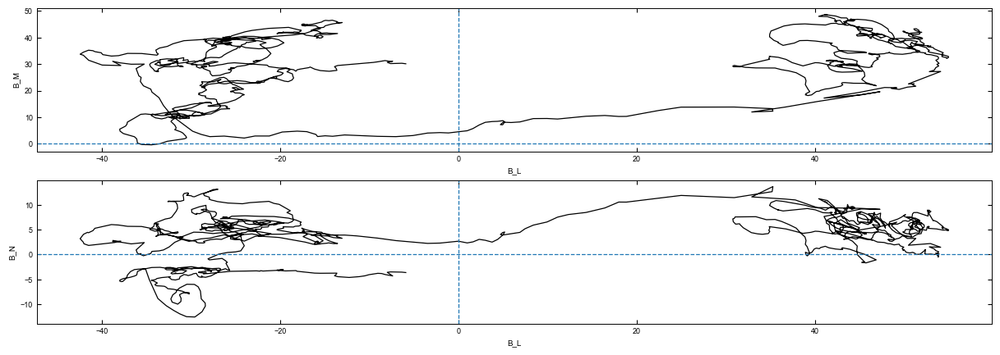

In [194]:
# Create subplots with 1 row and 2 columns
fig, ax = plt.subplots(2, 1, figsize=(15, 5), gridspec_kw={'wspace': 0.5})


# Plot for the first subplot (left column)
ax[0].plot(hall['mms3'].lmn_b.sel(LMN=0),hall['mms3'].lmn_b.sel(LMN=1),c='k')
ax[0].set_ylabel('B_M')
ax[0].set_xlabel('B_L')
ax[0].axhline(y=0,ls='--')
ax[0].axvline(x=0,ls='--')
# Plot for the second subplot (right column)
ax[1].plot(hall['mms3'].lmn_b.sel(LMN=0),hall['mms3'].lmn_b.sel(LMN=2),c='k')
ax[1].set_xlabel('B_L')  # Correctly set the x-axis label for the second plot
ax[1].set_ylabel('B_N')
ax[1].axhline(y=0,ls='--')
ax[1].axvline(x=0,ls='--')
plt.savefig(os.path.join(output_folder, f"{taistarttime}_b1.png"), dpi=600)
# Adjust the layout and display the plots
plt.show()

In [86]:
#np.round(np.min(hall['mms3'].lmn_b[:,0]),-1)

In [110]:
del3,del4

('2016-01-22T07:18:30', '2016-01-22T07:19:15')

In [196]:
#[t1,del4]=['2016-01-22T07:18:40','2016-01-22T07:18:56']

In [199]:
del3 = np.datetime64("2016-01-22T07:18:44.000")
del4 = np.datetime64("2016-01-22T07:18:53")

In [200]:
Bz = find(mms3i_bdataset.mms3_fgm_b_gse_brst_l2,v_dim=2)
Bz[0].values,Bz[1]

(np.datetime64('2016-01-22T07:18:49.249564000'), np.int64(3174))

In [201]:
find(hall['mms2'].lmn_b, LMN=0, d1=del3, d2=del4)[0]

<xarray.DataArray 'time' ()> Size: 8B
array('2016-01-22T07:18:48.679564000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 2016-01-22T07:18:48.679564
    epoch    datetime64[ns] 8B 2016-01-22T07:18:48.679564

#constant bg

## Magnetic/topological event parameters

In [202]:
# Spacecraft list
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
# Guide Field function
def GF(BM_SH, BM_SP):
    if BM_SH > 0 and BM_SP > 0:
        return (abs(BM_SH) + abs(BM_SP)) / 2
    elif BM_SH < 0 and BM_SP < 0:
        return -(abs(BM_SH) + abs(BM_SP)) / 2
    else:
        return BM_SH + BM_SP

# Main computation function for a spacecraft
def compute_B_G_for_sc(sc, t1, t2, Bl):
    b = hall[sc].lmn_b
    va = hall[sc].V_a
    vi = hall[sc].lmn_vi
    ni = idatasets_interp[sc][f'{sc}_dis_numberdensity_brst']
    ne = edatasets_interp[sc][f'{sc}_des_numberdensity_brst']

    if b.sel(LMN=0, time=slice(del3, Bl)).values[0] > 0:
        # Outbound: SP → SH
        b_sp = b.sel(time=slice(del3, t1)).mean(dim='time').values
        b_sh = b.sel(time=slice(t2, del4)).mean(dim='time').values
        BL_SP, BM_SP, BN_SP = [b.sel(LMN=i, time=slice(del3, t1)).mean().values for i in range(3)]
        BL_SH, BM_SH, BN_SH = [b.sel(LMN=i, time=slice(t2, del4)).mean().values for i in range(3)]
        N_SP = ni.sel(time=slice(del3, t1)).mean().values 
        N_SH = ni.sel(time=slice(t2, del4)).mean().values 
        BM_G = BM_SH
        alf_sh = va.sel(time=slice(t2, del4)).mean().values
        vl_spmin = vi.sel(LMN=0,time=slice(del3,Bl)).min()
    else:
        # Inbound: SH → SP
        b_sp = b.sel(time=slice(t2, del4)).mean(dim='time').values
        b_sh = b.sel(time=slice(del3, t1)).mean(dim='time').values
        BL_SP, BM_SP, BN_SP = [b.sel(LMN=i, time=slice(t2, del4)).mean().values for i in range(3)]
        BL_SH, BM_SH, BN_SH = [b.sel(LMN=i, time=slice(del3, t1)).mean().values for i in range(3)]
        N_SP = ni.sel(time=slice(t2, del4)).mean().values 
        N_SH = ni.sel(time=slice(del3, t1)).mean().values 
        BM_G = BM_SH
        alf_sh = va.sel(time=slice(del3, t1)).mean().values
        vl_spmin = vi.sel(LMN=0,time=slice(Bl,del4)).min()

    # Shear angle
    b_sh_mag = np.linalg.norm(b_sh)
    b_sp_mag = np.linalg.norm(b_sp)
    cos_theta = np.dot(b_sp, b_sh) / (b_sh_mag * b_sp_mag)
    theta_shear = np.degrees(np.arccos(cos_theta))

    # Guide field magnitude
    B_SP = np.array([BL_SP, BM_SP, BN_SP])
    B_SH = np.array([BL_SH, BM_SH, BN_SH])
    B_G = GF(BM_SH, BM_SP)

    # BM relative to guide field
    B_M_min = b.sel(LMN=1, time=slice(t1, t2)).min().values - B_G
    B_M_maxl = b.sel(LMN=1, time=slice(t1, Bl)).max().values - B_G
    B_M_maxr = b.sel(LMN=1, time=slice(Bl, t2)).max().values - B_G

    return [
        B_G / BL_SH,B_G, np.linalg.norm(B_SP) / np.linalg.norm(B_SH), N_SH / N_SP,
         theta_shear, B_M_maxl, B_M_min, B_M_maxr,
        BL_SP, BM_SP, BL_SH, BM_SH, BN_SP, BN_SH,
        N_SP, N_SH, alf_sh, vl_spmin
    ]

# Define time window (example)
del3 = np.datetime64("2016-01-22T07:18:44.000")
del4 = np.datetime64("2016-01-22T07:18:53")

 #Define per-spacecraft time ranges
times_dict = {
    'mms1': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
    'mms2': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
    'mms3': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
    'mms4': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
}
# Compute Bl values per spacecraft
Bl_dict = {
    sc: find(hall[sc].lmn_b, LMN=0, d1=del3, d2=del4)[0]
    for sc in sc_list
}

# Compute results
results = []
for sc in sc_list:
    t1, t2 = times_dict[sc]
    Bl = Bl_dict[sc]
    res = compute_B_G_for_sc(sc, t1, t2, Bl)
    results.append(np.round(res, 2))

# Column labels
columns = [
    '$\\frac{B_{G}}{B_{L-SH}}$','$B_g$', '$\\frac{B_{SP}}{B_{SH}}$', '$\\frac{N_{SH}}{N_{SP}}$',
     'shear', '$B_{Ml}$', '$B_{Mc}$', '$B_{Mr}$',
    '$B_{LSP}$', '$B_{MSP}$', '$B_{LSH}$', '$B_{MSH}$',
    '$B_{NSP}$', '$B_{NSH}$', '$N_{SP}$', '$N_{SH}$',
    '$Alfv_{sh}$', '$Vl_{spmax}$'
]

# Create final DataFrame
df_all = pd.DataFrame(results, index=sc_list, columns=columns)
df_all

,$\frac{B_{G}}{B_{L-SH}}$,$B_g$,$\frac{B_{SP}}{B_{SH}}$,$\frac{N_{SH}}{N_{SP}}$,shear,$B_{Ml}$,$B_{Mc}$,$B_{Mr}$,$B_{LSP}$,$B_{MSP}$,$B_{LSH}$,$B_{MSH}$,$B_{NSP}$,$B_{NSH}$,$N_{SP}$,$N_{SH}$,$Alfv_{sh}$,$Vl_{spmax}$
mms1,-1.22,34.28,1.58,3.87,94.64,12.70,-38.34,5.97,50.67,39.87,-28.17,28.70,7.90,8.52,8.38,32.45,3.42,-303.99
mms2,-1.29,35.63,1.56,4.05,91.97,12.25,-40.46,3.03,50.58,40.47,-27.54,30.78,7.60,6.96,8.06,32.70,105.12,-298.85
mms3,-1.27,34.25,1.65,4.15,94.54,12.63,-32.12,5.54,51.43,40.15,-26.93,28.35,5.80,7.05,8.04,33.35,102.04,-302.77
mms4,-1.23,34.65,1.59,3.83,94.33,12.61,-39.47,5.35,50.63,40.44,-28.16,28.87,7.37,7.66,8.35,31.97,108.76,-301.31


In [203]:
del3, del4,del3 + np.timedelta64(1000, 'ms'),  del4 - np.timedelta64(1000, 'ms')

(np.datetime64('2016-01-22T07:18:44.000'),
 np.datetime64('2016-01-22T07:18:53'),
 np.datetime64('2016-01-22T07:18:45.000'),
 np.datetime64('2016-01-22T07:18:52.000'))

#linear Bg

In [204]:
# Spacecraft list
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
def compute_B_G_for_sc_linear(sc, t1, t2, Bl):
    b = hall[sc].lmn_b
    va = hall[sc].V_a
    vi = hall[sc].lmn_vi
    ni = idatasets_interp[sc][f'{sc}_dis_numberdensity_brst']
    ne = edatasets_interp[sc][f'{sc}_des_numberdensity_brst']

    if b.sel(LMN=0, time=slice(del3, Bl)).values[0] > 0:
        # Outbound: SP to SH
        b_sp = b.sel(time=slice(del3, t1)).mean(dim='time').values
        b_sh = b.sel(time=slice(t2, del4)).mean(dim='time').values

        BL_SP, BM_SP, BN_SP = [b.sel(LMN=i, time=slice(del3, t1)).mean().values for i in range(3)]
        BL_SH, BM_SH, BN_SH = [b.sel(LMN=i, time=slice(t2, del4)).mean().values for i in range(3)]

        N_SP = ni.sel(time=slice(del3, t1)).mean().values
        N_SH = ni.sel(time=slice(t2, del4)).mean().values

        alf_sh = va.sel(time=slice(t2, del4)).mean().values
        vl_spmax = vi.sel(LMN=0,time=slice(del3, Bl)).min().values

        t_left_mid = del3 + (t1 - del3) / 2
        t_right_mid = t2 + (del4 - t2) / 2

        BM_left = BM_SP
        BM_right = BM_SH

    else:
        # Inbound: SH -> SP
        b_sp = b.sel(time=slice(t2, del4)).mean(dim='time').values
        b_sh = b.sel(time=slice(del3, t1)).mean(dim='time').values

        BL_SP, BM_SP, BN_SP = [b.sel(LMN=i, time=slice(t2, del4)).mean().values for i in range(3)]
        BL_SH, BM_SH, BN_SH = [b.sel(LMN=i, time=slice(del3, t1)).mean().values for i in range(3)]

        N_SP = ni.sel(time=slice(t2, del4)).mean().values
        N_SH = ni.sel(time=slice(del3, t1)).mean().values

        alf_sh = va.sel(time=slice(del3, t1)).mean().values
        vl_spmax = vi.sel(LMN=0,time=slice(Bl, del4)).min().values

        t_left_mid = del3 + (t1 - del3) / 2
        t_right_mid = t2 + (del4 - t2) / 2

        BM_left = BM_SH
        BM_right = BM_SP

    # Shear angle
    b_sh_mag = np.linalg.norm(b_sh)
    b_sp_mag = np.linalg.norm(b_sp)
    cos_theta = np.dot(b_sp, b_sh) / (b_sh_mag * b_sp_mag)
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    theta_shear = np.degrees(np.arccos(cos_theta))

    B_SP = np.array([BL_SP, BM_SP, BN_SP])
    B_SH = np.array([BL_SH, BM_SH, BN_SH])

    # --- Linear guide field over event interval ---
    bm_event = b.sel(LMN=1, time=slice(del3, del4))
    times_event = bm_event.time.values

    # convert times to seconds relative to left midpoint
    t0 = t_left_mid
    t_left_sec = 0.0
    t_right_sec = (t_right_mid - t0) / np.timedelta64(1, 's')
    t_event_sec = (times_event - t0) / np.timedelta64(1, 's')

    # linear guide field: BM_left -> BM_right
    Bg_linear = BM_left + (BM_right - BM_left) * (t_event_sec - t_left_sec) / (t_right_sec - t_left_sec)

    # Hall perturbation
    Hall_BM = bm_event.values - Bg_linear

    # split by Bl
    bm_left_part = b.sel(LMN=1, time=slice(t1, Bl))
    bm_right_part = b.sel(LMN=1, time=slice(Bl, t2))

    times_left = bm_left_part.time.values
    times_right = bm_right_part.time.values

    t_left_part_sec = (times_left - t0) / np.timedelta64(1, 's')
    t_right_part_sec = (times_right - t0) / np.timedelta64(1, 's')

    Bg_left_part = BM_left + (BM_right - BM_left) * (t_left_part_sec - t_left_sec) / (t_right_sec - t_left_sec)
    Bg_right_part = BM_left + (BM_right - BM_left) * (t_right_part_sec - t_left_sec) / (t_right_sec - t_left_sec)

    Hall_left = bm_left_part.values - Bg_left_part
    Hall_right = bm_right_part.values - Bg_right_part

    B_M_maxl = np.max(Hall_left)
    B_M_min = np.min(Hall_BM)
    B_M_maxr = np.max(Hall_right)

    # optional: representative constant guide field for table
    B_G_mean = 0.5 * (BM_left + BM_right)

    Bg_linear_da = xr.DataArray(
    Bg_linear,
    coords={"time": bm_event.time.values},
    dims=["time"],
    name="Bg_linear"
    )

    Hall_BM_da = xr.DataArray(
    Hall_BM,
    coords={"time": bm_event.time.values},
    dims=["time"],
    name="Hall_BM"
    )
    columns = [ '$\\frac{B_{G}}{B_{L-SP}}$', '$\\frac{B_{SP}}{B_{SH}}$', '$\\frac{N_{SH}}{N_{SP}}$', 'B_g', 'shear', '$B_M_maxl$', '$B_M_min$', '$B_M_maxr$', '$B_{LSP}$', '$B_{MSP}$', '$B_{LSH}$', '$B_{MSH}$', '$B_{NSP}$', '$B_{NSH}$', '$N_{SP}$', '$N_{SH}$', '$v_{ash}$', 'Vl_shmax' ]
# Create final DataFrame 
    return {  
        "summary": [
        B_G_mean / BL_SH,
        np.linalg.norm(B_SP) / np.linalg.norm(B_SH),
        N_SH / N_SP,
        B_G_mean,
        theta_shear,
        B_M_maxl,
        B_M_min,
        B_M_maxr,
        BL_SP, BM_SP, BL_SH, BM_SH, BN_SP, BN_SH,
        N_SP, N_SH, alf_sh, vl_spmax
    ],
    "Bg_linear": Bg_linear_da,
    "Hall_BM": Hall_BM_da
    }

    
res_all = {}
 #Define per-spacecraft time ranges
times_dict = {
    'mms1': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
    'mms2': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
    'mms3': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
    'mms4': (del3 + np.timedelta64(1000, 'ms'), del4 - np.timedelta64(1000, 'ms')),
}

for sc in sc_list:
    t1, t2 = times_dict[sc]
    Bl = Bl_dict[sc]
    res_all[sc] = compute_B_G_for_sc_linear(sc, t1, t2, Bl)
    df_all = pd.DataFrame(results, index=sc_list, columns=columns)
results = []
# Compute results

for sc in sc_list:
    t1, t2 = times_dict[sc]
    Bl = Bl_dict[sc]
    res = compute_B_G_for_sc_linear(sc, t1, t2, Bl)['summary']
    results.append(np.round(res, 2))
    
# Column labels
columns = [
    '$\\frac{B_{G}}{B_{L-SH}}$', '$\\frac{B_{SP}}{B_{SH}}$', '$\\frac{N_{SH}}{N_{SP}}$',
    '$B_g$', 'shear', '$B_M_maxl$', '$B_M_min$', '$B_M_maxr$',
    '$B_{LSP}$', '$B_{MSP}$', '$B_{LSH}$', '$B_{MSH}$',
    '$B_{NSP}$', '$B_{NSH}$', '$N_{SP}$', '$N_{SH}$',
    '$v_{ash}$', 'Vl_spmax'
]

# Create final DataFrame
df_all = pd.DataFrame(results, index=sc_list, columns=columns)
df_all

,$\frac{B_{G}}{B_{L-SH}}$,$\frac{B_{SP}}{B_{SH}}$,$\frac{N_{SH}}{N_{SP}}$,$B_g$,shear,$B_M_maxl$,$B_M_min$,$B_M_maxr$,$B_{LSP}$,$B_{MSP}$,$B_{LSH}$,$B_{MSH}$,$B_{NSP}$,$B_{NSH}$,$N_{SP}$,$N_{SH}$,$v_{ash}$,Vl_spmax
mms1,-1.22,1.58,3.87,34.28,94.64,9.19,-38.59,9.78,50.67,39.87,-28.17,28.70,7.90,8.52,8.38,32.45,3.42,-303.99
mms2,-1.29,1.56,4.05,35.63,91.97,9.13,-40.57,6.30,50.58,40.47,-27.54,30.78,7.60,6.96,8.06,32.70,105.12,-298.85
mms3,-1.27,1.65,4.15,34.25,94.54,9.18,-30.21,9.87,51.43,40.15,-26.93,28.35,5.80,7.05,8.04,33.35,102.04,-302.77
mms4,-1.23,1.59,3.83,34.65,94.33,9.01,-39.39,9.43,50.63,40.44,-28.16,28.87,7.37,7.66,8.35,31.97,108.76,-301.31


In [205]:
del3,t1,t2,del4

(np.datetime64('2016-01-22T07:18:44.000'),
 np.datetime64('2016-01-22T07:18:45.000'),
 np.datetime64('2016-01-22T07:18:52.000'),
 np.datetime64('2016-01-22T07:18:53'))

In [206]:
df_all['Vl_spmax']

mms1   -303.99
mms2   -298.85
mms3   -302.77
mms4   -301.31
Name: Vl_spmax, dtype: float64

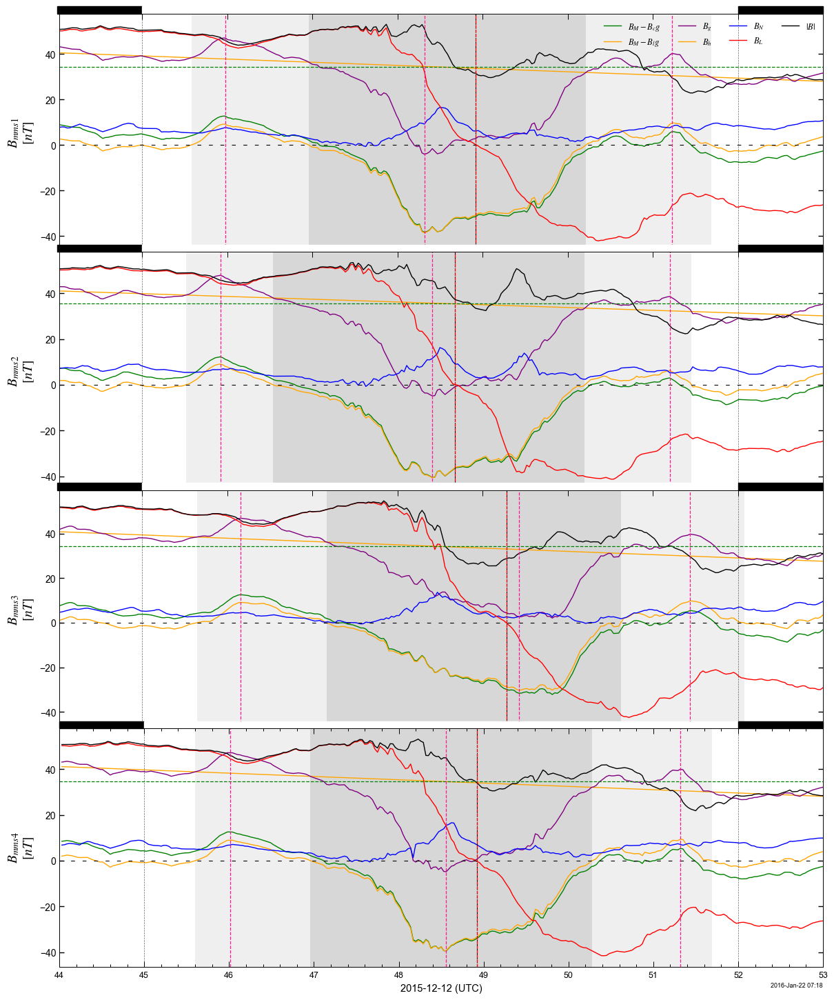

In [217]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
fig, axs = plt.subplots(len(sc_list), 1, figsize=(12, 15), sharex=False, gridspec_kw={"hspace": 0})

Bl_dict = {sc: find(hall[sc].lmn_b, LMN=0, d1=del3, d2=del4)[0] for sc in sc_list}

for i, sc in enumerate(sc_list):
    ax = axs[i]
    t1, t2 = times_dict[sc]
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, "$B_g$"]

    B = hall[sc].lmn_b.sel(time=slice(del3, del4))
    B_hm = B - res_all[sc]['Bg_linear']
    BG=B.sel(LMN=1)
    bg = B.sel(LMN=1) - B_g
    bl = B.sel(LMN=0)
    bm = B_hm.sel(LMN=1)          # B_M - B_g
    bn = B.sel(LMN=2)
    Bmag = np.sqrt(bl**2 + res_all[sc]['Hall_BM']**2 + bn**2)
    Bmag = np.sqrt(bl**2 + bm**2 + bn**2)
    # features
    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
    th_min  = B_hm.time.sel(time=slice(t1, t2)).isel(time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
    #th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
   # th_1 = find(B_hm, LMN=1, d1=th_min,  d2=th_maxr)[0]

    # plots (same axis)
    ax.plot(B.time, bg, c="g", lw=1.0, label=r"$B_M-B_cg$")
    ax.plot(res_all[sc]['Bg_linear'].time, res_all[sc]['Bg_linear'], c="orange", lw=1.0, label=r"$B_M-B_lg$")
    ax.plot(B.time, B.sel(LMN=1), c="purple", lw=1.0, label=r"$B_g$")
  
    ax.plot(res_all[sc]['Hall_BM'].time, res_all[sc]['Hall_BM'], c="orange", lw=1.0, label=r"$B_h$")
    ax.plot(B.time, bn, c="b", lw=1.0, label=r"$B_N$")
    ax.plot(B.time, bl, c="r", lw=1.0, label=r"$B_L$")
    ax.plot(B.time, Bmag, c="k", lw=1, label=r"$|B|$")
    ax.set_ylabel(r"$\mathbf{\mathit{B_{%s}}}$" % sc + '\n' + r"$[\mathit{nT}]$",
                      fontsize=14)

    ax.axhline(0, c="k", ls=(0, (5, 10)), lw=0.8)

    # event lines + shading
    ax.axvline(Bl.values, ls="--", c="k", lw=0.8)
    #for x in [th_maxl, th_min.values, th_maxr.values]:
    #    ax.axvline(x, ls="--", c="g", lw=0.7)
    #ax.axvspan(th_0, th_1.values, color=(1, 1, 0.7), alpha=0.7)
    ax.set_xlim(B.time.sel(time=del3, method="nearest"), B.time.sel(time=del4,method='nearest'))
    # top bars
    t = sorted([del3, t1, t2, del4]); tr = ax.get_xaxis_transform()
    
    for j, c in enumerate("kwk"):
        ax.axvspan(t[j], t[j+1], 1.00, 1.03, transform=tr, color=c, clip_on=False)
    for x in t:
        ax.axvline(x, ls="--", c="k", lw=0.5, alpha=0.6)
    ax.tick_params(axis='x', which='major', labelsize=9,size=6,width=0.7,pad=5,direction='in',top=True,bottom=True)
    ax.tick_params(axis='x', which='minor', labelsize=9,size=3,width=0.7,pad=1,direction='in',top=True,bottom=True)
    ax.tick_params(axis='y', which='major', direction='in',left=True,right=True,
                 width=1, length=5,labelsize=10)  # Adjust width and length as needed
    ax.tick_params(axis='y', which='minor', direction='in',left=True,right=True, 
                   width=1, length=3,labelsize=10)
    ax.axhline(y=B_g, ls='--', c='g')
    ax.axvline(x=Bl.values, ls='--', c='r')
    ax.axvline(x=th_maxl.values, ls='--', c='#FF1493')
    #ax.axvline(x=th_min.values, ls='--', c='#FF1493')
    ax.axvline(x=th_min.values, ls='--', c='#FF1493')
    ax.axvline(x=th_maxr.values, ls='--', c='#FF1493')
    
    x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
    x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
    x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
    x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

    ax.axvspan(x1, x2, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)
    ax.axvspan(x2, x3, color='#BDBDBD', alpha=0.6, lw=0, zorder=0)
    ax.axvspan(x3, x4, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)

    #for xc in [x1, x2, x3, x4]:
    #    ax.axvline(xc, color="0.5", ls="--", lw=0.8, zorder=1)
    
axs[-1].set_xlabel("2015-12-12 (UTC)", fontsize=10.5)

axs[0].legend(ncol=4, frameon=False, fontsize=9, loc="upper right")
plt.xticks(xticks(del3,del4)[0])

    # Set minor x-axis ticks
plt.xticks(xticks(del3,del4)[1], minor=True)

plt.tight_layout(pad=0.5)
plt.subplots_adjust(top=0.95)
plt.savefig(os.path.join(output_folder, f"{taistarttime}_h.png"),
            dpi=600, bbox_inches="tight")
plt.show()


In [218]:
import numpy as np
import pandas as pd
# Spacecraft list
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
def four_zero_crossings_around_thmin(B_hm, t1, t2):
    # 1D Hall trace in the event interval
    da = hallb.sel(time=slice(del3, del4))

    # time of minimum
    th_min = da.time.isel(time=np.argmin(da.values)).values

    y = da.values
    t = da.time.values

    # all sign changes
    idx = np.where(np.sign(y[:-1]) != np.sign(y[1:]))[0]

    rows = []
    for i in idx:
        y0, y1 = y[i], y[i + 1]
        t0, t1_ = t[i], t[i + 1]

        if y1 == y0:
            continue

        # linear interpolation to y=0
        frac = -y0 / (y1 - y0)
        tcross = t0 + (t1_ - t0) * frac

        rows.append({
            "i_left": i,
            "time_left": t0,
            "time_right": t1_,
            "Hall_left": y0,
            "Hall_right": y1,
            "zero_crossing_time": tcross,
            "dt_from_thmin_s": (tcross - th_min) / np.timedelta64(1, "s")
        })

    cross_df = pd.DataFrame(rows)

    if len(cross_df) == 0:
        return th_min, pd.DataFrame(), pd.DataFrame(), cross_df

    # two nearest on the left
    left_two = (
        cross_df[cross_df["dt_from_thmin_s"] < 0]
        .sort_values("dt_from_thmin_s", ascending=False)
        .head(2)
        .sort_values("dt_from_thmin_s")
        .reset_index(drop=True)
    )

    # two nearest on the right
    right_two = (
        cross_df[cross_df["dt_from_thmin_s"] > 0]
        .sort_values("dt_from_thmin_s", ascending=True)
        .head(2)
        .reset_index(drop=True)
    )

    return th_min, left_two, right_two, cross_df


bm_cross = {}

for sc in sc_list:
    hallb = res_all[sc]["Hall_BM"]
    t1, t2 = times_dict[sc]

    th_min, left_two, right_two, cross_df = four_zero_crossings_around_thmin(hallb, t1, t2)

    bm_cross[sc] = {
        "th_min": th_min,
        "left_two": left_two,
        "right_two": right_two,
        "all": cross_df
    }

In [219]:
bm_cross['mms4']['all']

,i_left,time_left,time_right,Hall_left,Hall_right,zero_crossing_time,dt_from_thmin_s
0,13,2016-01-22 07:18:44.419564,2016-01-22 07:18:44.449564,0.1330,-0.1933,2016-01-22 07:18:44.431790378,-4.1278
1,52,2016-01-22 07:18:45.589564,2016-01-22 07:18:45.619564,-0.0586,0.1792,2016-01-22 07:18:45.596956846,-2.9626
2,97,2016-01-22 07:18:46.939564,2016-01-22 07:18:46.969564,0.2537,-0.1854,2016-01-22 07:18:46.956898006,-1.6027
3,208,2016-01-22 07:18:50.269564,2016-01-22 07:18:50.299564,-0.0672,0.2742,2016-01-22 07:18:50.275472694,1.7159
4,255,2016-01-22 07:18:51.679564,2016-01-22 07:18:51.709564,0.1209,-0.1469,2016-01-22 07:18:51.693104753,3.1335
5,282,2016-01-22 07:18:52.489564,2016-01-22 07:18:52.519564,-0.4942,0.1946,2016-01-22 07:18:52.511089286,3.9515
6,287,2016-01-22 07:18:52.639564,2016-01-22 07:18:52.669564,0.6508,-0.0417,2016-01-22 07:18:52.667755701,4.1082
7,290,2016-01-22 07:18:52.729564,2016-01-22 07:18:52.759564,-0.3798,0.3297,2016-01-22 07:18:52.745624618,4.1861


In [209]:
import numpy as np

for sc in sc_list:
    hallb = res_all[sc]["Hall_BM"]
    left_two = bm_cross[sc]["left_two"]
    right_two = bm_cross[sc]["right_two"]

    # default outputs
    bm_cross[sc]["left_max"] = {
        "time": None,
        "value": None,
        "t_start": None,
        "t_end": None
    }
    bm_cross[sc]["right_max"] = {
        "time": None,
        "value": None,
        "t_start": None,
        "t_end": None
    }
    bm_cross[sc]["middle_min"] = {
        "time": None,
        "value": None,
        "t_start": None,
        "t_end": None
    }

    # -----------------------------
    # 1) maximum between left crossings
    # -----------------------------
    if len(left_two) == 2:
        tL1 = left_two["zero_crossing_time"].iloc[0]
        tL2 = left_two["zero_crossing_time"].iloc[1]

        da_left = hallb.sel(time=slice(tL1, tL2))

        if da_left.time.size > 0:
            i_max_left = np.argmax(da_left.values)
            bm_cross[sc]["left_max"] = {
                "time": da_left.time.isel(time=i_max_left).values,
                "value": da_left.isel(time=i_max_left).values,
                "t_start": tL1,
                "t_end": tL2
            }

    # -----------------------------
    # 2) maximum between right crossings
    # -----------------------------
    if len(right_two) == 2:
        tR1 = right_two["zero_crossing_time"].iloc[0]
        tR2 = right_two["zero_crossing_time"].iloc[1]

        da_right = hallb.sel(time=slice(tR1, tR2))

        if da_right.time.size > 0:
            i_max_right = np.argmax(da_right.values)
            bm_cross[sc]["right_max"] = {
                "time": da_right.time.isel(time=i_max_right).values,
                "value": da_right.isel(time=i_max_right).values,
                "t_start": tR1,
                "t_end": tR2
            }

    # -----------------------------
    # 3) minimum between nearest left and nearest right crossings
    # -----------------------------
    if len(left_two) >= 1 and len(right_two) >= 1:
        t_mid_left = left_two["zero_crossing_time"].iloc[-1]   # nearest left
        t_mid_right = right_two["zero_crossing_time"].iloc[0]  # nearest right

        da_mid = hallb.sel(time=slice(t_mid_left, t_mid_right))

        if da_mid.time.size > 0:
            i_min_mid = np.argmin(da_mid.values)
            bm_cross[sc]["middle_min"] = {
                "time": da_mid.time.isel(time=i_min_mid).values,
                "value": da_mid.isel(time=i_min_mid).values,
                "t_start": t_mid_left,
                "t_end": t_mid_right
            }
hall_maxtim = pd.DataFrame([
    {
        "sc": sc,
        "left_max_time": bm_cross[sc]["left_max"]["time"],
        "left_max_value": bm_cross[sc]["left_max"]["value"].item(),
        "left_t_start": bm_cross[sc]["left_max"]["t_start"],
        "left_t_end": bm_cross[sc]["left_max"]["t_end"],

        "right_max_time": bm_cross[sc]["right_max"]["time"],
        "right_max_value": bm_cross[sc]["right_max"]["value"].item(),
        "right_t_start": bm_cross[sc]["right_max"]["t_start"],
        "right_t_end": bm_cross[sc]["right_max"]["t_end"],

        "mid_min_time": bm_cross[sc]["middle_min"]["time"],
        "mid_min_value": bm_cross[sc]["middle_min"]["value"].item(),
        "mid_t_start": bm_cross[sc]["middle_min"]["t_start"],
        "mid_t_end": bm_cross[sc]["middle_min"]["t_end"],
    }
    for sc in sc_list
]).set_index("sc")

In [210]:
summary_df = pd.DataFrame([
    {
        "sc": sc,
        "left_max_time": bm_cross[sc]["left_max"]["time"],
        "left_max_value": bm_cross[sc]["left_max"]["value"].item(),
        "right_max_time": bm_cross[sc]["right_max"]["time"],
        "right_max_value": bm_cross[sc]["right_max"]["value"].item(),
        "mid_min_time": bm_cross[sc]["middle_min"]["time"],
        "mid_min_value": bm_cross[sc]["middle_min"]["value"].item(),
    }
    for sc in sc_list
]).set_index("sc")
summary_df.loc["mms1"]['left_max_time']

Timestamp('2016-01-22 07:18:45.979564')

In [211]:
# Physical constants
m_p = 1.6726219e-27  # Proton mass in kg
mu_0 = 4 * np.pi * 1e-7  # Vacuum permeability in T·m/A
e = 1.60217662e-19  # Elementary charge in C
n = df_all['$N_{SH}$'].values  # Example number density in m^-3

# Calculate lambda_i
lambda_i = np.sqrt(m_p / (mu_0 * e**2 * n*1e6))*1e-3
lambda_e = np.sqrt(m_e / (mu_0 * e**2 * n * 1e6)) * 1e-3
# Print the result

lambda_i_s = pd.Series(lambda_i, index=sc_list, name='lambda_i_SH_km')
lambda_e_s = pd.Series(lambda_e, index=sc_list, name='lambda_e_SH_km')
lambda_df = pd.DataFrame({
    'lambda_i_SH_km': lambda_i,
    'lambda_e_SH_km': lambda_e
}, index=sc_list)

lambda_df['lambda_i_SH_km']['mms4'].item(),lambda_df['lambda_e_SH_km']['mms3'].item()


(40.272839315291314, 0.9201979329323642)

In [212]:


crossing_times = np.array([
    (bm_cross[sc]['right_two']['zero_crossing_time'][1] - 
     bm_cross[sc]['left_two']['zero_crossing_time'][0]) / np.timedelta64(1, 's')
    for sc in times_dict.keys()
])
thickness = crossing_times * V                  # km (if V in km/s)
delta = thickness / lambda_i                 # width(delta) in units of d_i thickness = L 

aspect_ratio = 10

width = thickness * aspect_ratio/2           # since aspect_ratio = width/thickness
Delta = width / lambda_i               # thickness (L) in units of d_i
[thickness,delta],[width/2,Delta]

([array([285.52243532, 277.54157996, 300.50401468, 285.05787202]),
  array([7.14272652, 6.96976869, 7.62104683, 7.07816675])],
 [array([713.80608829, 693.85394991, 751.26003669, 712.64468006]),
  array([35.71363261, 34.84884345, 38.10523414, 35.39083373])])

# complete diamagnetic-suppression calculation

Reviewer 2 comment 6 What physical mechanism allows reconnection under strong guide field and low shear? With a magnetic shear of 94.3o and B_g/B_sh=1.23, the event lies in a regime where diamagnetic suppression may be important. The authors attribute reconnection to asymmetric ion beta, but a quantitative discussion of reconnection rate, diffusion-region scale, inflow/outflow balance, and the Swisdak-Drake suppression criterion is missing.

In [214]:
import numpy as np
import pandas as pd
import xarray as xr

# ============================================================
# FOUR-SPACECRAFT DIAMAGNETIC SUPPRESSION ANALYSIS
# Reuses upstream values already stored in df_all
# ============================================================

mu0 = 4.0 * np.pi * 1e-7
mp  = 1.67262192369e-27
qe  = 1.602176634e-19

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

# Use your manuscript/common HT velocity
VHT_N = -41.0   # km/s

# ============================================================
# 1. HELPER: determine outbound/inbound intervals
# exactly following your compute_B_G_for_sc_linear logic
# ============================================================

def get_side_intervals(sc, t1, t2, Bl):

    b = hall[sc].lmn_b

    test_value = (
        b.sel(
            LMN=0,
            time=slice(del3, Bl)
        ).values[0]
    )

    if test_value > 0:
        # outbound: SP -> Hall -> SH
        t_sp = slice(del3, t1)
        t_sh = slice(t2, del4)
        direction = 'outbound'

    else:
        # inbound: SH -> Hall -> SP
        t_sh = slice(del3, t1)
        t_sp = slice(t2, del4)
        direction = 'inbound'

    t_hall = slice(t1, t2)

    return t_sp, t_sh, t_hall, direction


# ============================================================
# 2. Scalar pressure from LMN pressure tensor
# ============================================================

def scalar_pressure(P):

    return (
        P.sel(LMN1=0, LMN2=0)
        + P.sel(LMN1=1, LMN2=1)
        + P.sel(LMN1=2, LMN2=2)
    ) / 3.0


# ============================================================
# 3. Plasma beta
#
# p = nPa
# B = nT
# ============================================================

def beta_from_mean_pressure(p_nPa, B_nT):

    p_si = p_nPa * 1e-9
    B_si = B_nT * 1e-9

    return (
        2.0 * mu0 * p_si
        / B_si**2
    )


# ============================================================
# 4. Pressure scale length
#
# Lp = |p / (dp/dN)|
# dp/dN = (dp/dt)/V_HT,N
#
# Returns Lp in km
# ============================================================

def pressure_scale_length(p, Vn_kms):

    p = p.dropna(dim='time')

    time_sec = (
        p.time.values
        .astype('datetime64[ns]')
        .astype(np.int64)
        * 1e-9
    )

    pval = np.asarray(
        p.values,
        dtype=float
    )

    dpdt = np.gradient(
        pval,
        time_sec
    )                         # nPa/s

    dpdN = dpdt / Vn_kms      # nPa/km

    with np.errstate(
        divide='ignore',
        invalid='ignore'
    ):

        Lp = np.abs(
            pval / dpdN
        )

    return xr.DataArray(
        Lp,
        coords={'time': p.time},
        dims=['time']
    )


# ============================================================
# 5. Diamagnetic velocity
#
# v* = B x grad(P)/(q n B^2)
#
# Assume dominant pressure gradient along N
# ============================================================

def diamagnetic_velocity(
    pressure,
    density,
    B_lmn,
    Vn_kms,
    charge_sign
):

    p = pressure.dropna(dim='time')

    n = density.interp(
        time=p.time
    )

    B = B_lmn.interp(
        time=p.time
    )

    time_sec = (
        p.time.values
        .astype('datetime64[ns]')
        .astype(np.int64)
        * 1e-9
    )

    pval = np.asarray(
        p.values,
        dtype=float
    )

    dpdt = np.gradient(
        pval,
        time_sec
    )                           # nPa/s

    dpdN_nPa_km = (
        dpdt / Vn_kms
    )

    # 1 nPa/km = 1e-12 Pa/m
    dpdN_si = (
        dpdN_nPa_km *
        1e-12
    )

    gradP = np.zeros(
        (len(p), 3)
    )

    # LMN:
    # L = 0
    # M = 1
    # N = 2
    gradP[:, 2] = dpdN_si

    B_si = (
        np.asarray(B.values)
        * 1e-9
    )

    n_si = (
        np.asarray(n.values)
        * 1e6
    )

    B2 = np.sum(
        B_si**2,
        axis=1
    )

    numerator = np.cross(
        B_si,
        gradP
    )

    denominator = (
        charge_sign
        * qe
        * n_si[:, None]
        * B2[:, None]
    )

    with np.errstate(
        divide='ignore',
        invalid='ignore'
    ):

        vstar = (
            numerator /
            denominator
        )

    # m/s -> km/s
    vstar = (
        vstar / 1e3
    )

    return xr.DataArray(
        vstar,
        coords={
            'time': p.time,
            'LMN': [0, 1, 2]
        },
        dims=[
            'time',
            'LMN'
        ]
    )


# ============================================================
# 6. Cassak-Shay asymmetric outflow
#
# Uses values already stored in df_all
# ============================================================

def asymmetric_outflow_speed(
    BL_SP,
    BL_SH,
    N_SP,
    N_SH
):

    Bsp = (
        abs(BL_SP)
        * 1e-9
    )

    Bsh = (
        abs(BL_SH)
        * 1e-9
    )

    nsp = (
        N_SP
        * 1e6
    )

    nsh = (
        N_SH
        * 1e6
    )

    rho_sp = (
        nsp * mp
    )

    rho_sh = (
        nsh * mp
    )

    numerator = (
        Bsp
        * Bsh
        * (Bsp + Bsh)
    )

    denominator = (
        mu0
        *
        (
            rho_sp * Bsh
            +
            rho_sh * Bsp
        )
    )

    with np.errstate(
        divide='ignore',
        invalid='ignore'
    ):

        vout = np.sqrt(
            numerator /
            denominator
        )

    return (
        vout / 1e3
    )


# ============================================================
# 7. MAIN ANALYSIS
# ============================================================

def analyze_diamagnetic_suppression(sc):

    print(
        f"\n{'='*70}"
    )

    print(
        f"DIAMAGNETIC ANALYSIS: {sc.upper()}"
    )

    print(
        f"{'='*70}"
    )

    ds = hall[sc]

    # --------------------------------------------------------
    # Hall limits already defined by you
    # --------------------------------------------------------

    t1, t2 = times_dict[sc]
    Bl = Bl_dict[sc]

    t_sp, t_sh, t_hall, direction = (
        get_side_intervals(
            sc,
            t1,
            t2,
            Bl
        )
    )

    # ========================================================
    # READ EXISTING VALUES DIRECTLY FROM df_all
    # ========================================================

    row = df_all.loc[sc]

    Bg = float(
        row['$B_g$']
    )

    shear = float(
        row['shear']
    )

    BL_SP = float(
        row['$B_{LSP}$']
    )

    BM_SP = float(
        row['$B_{MSP}$']
    )

    BN_SP = float(
        row['$B_{NSP}$']
    )

    BL_SH = float(
        row['$B_{LSH}$']
    )

    BM_SH = float(
        row['$B_{MSH}$']
    )

    BN_SH = float(
        row['$B_{NSH}$']
    )

    N_SP = float(
        row['$N_{SP}$']
    )

    N_SH = float(
        row['$N_{SH}$']
    )

    VA_SH = float(
        row['$v_{ash}$']
    )

    VL_peak_existing = float(
        row['Vl_spmax']
    )

    Bg_over_BLsh = float(
        row[
            '$\\frac{B_{G}}{B_{L-SH}}$'
        ]
    )

    B_ratio = float(
        row[
            '$\\frac{B_{SP}}{B_{SH}}$'
        ]
    )

    density_ratio = float(
        row[
            '$\\frac{N_{SH}}{N_{SP}}$'
        ]
    )

    # --------------------------------------------------------
    # Magnitudes from stored components
    # --------------------------------------------------------

    B_SP_mag = np.sqrt(
        BL_SP**2
        + BM_SP**2
        + BN_SP**2
    )

    B_SH_mag = np.sqrt(
        BL_SH**2
        + BM_SH**2
        + BN_SH**2
    )

    # ========================================================
    # PRESSURE
    # ========================================================

    pi = scalar_pressure(
        ds['iPlmn']
    )

    pe_raw = scalar_pressure(
        ds['ePlmn']
    )

    # Common pressure time base
    pe = pe_raw.interp(
        time=pi.time
    )

    ptot = (
        pi + pe
    )

    # ========================================================
    # UPSTREAM PRESSURES
    # ========================================================

    Pi_SP = float(
        pi.sel(
            time=t_sp
        ).mean(
            skipna=True
        )
    )

    Pi_SH = float(
        pi.sel(
            time=t_sh
        ).mean(
            skipna=True
        )
    )

    Pe_SP = float(
        pe.sel(
            time=t_sp
        ).mean(
            skipna=True
        )
    )

    Pe_SH = float(
        pe.sel(
            time=t_sh
        ).mean(
            skipna=True
        )
    )

    Ptot_SP = (
        Pi_SP +
        Pe_SP
    )

    Ptot_SH = (
        Pi_SH +
        Pe_SH
    )

    # ========================================================
    # BETA USING STORED UPSTREAM B VALUES
    # ========================================================

    beta_i_SP = beta_from_mean_pressure(
        Pi_SP,
        B_SP_mag
    )

    beta_i_SH = beta_from_mean_pressure(
        Pi_SH,
        B_SH_mag
    )

    beta_e_SP = beta_from_mean_pressure(
        Pe_SP,
        B_SP_mag
    )

    beta_e_SH = beta_from_mean_pressure(
        Pe_SH,
        B_SH_mag
    )

    beta_total_SP = (
        beta_i_SP +
        beta_e_SP
    )

    beta_total_SH = (
        beta_i_SH +
        beta_e_SH
    )

    delta_beta_i = abs(
        beta_i_SH -
        beta_i_SP
    )

    delta_beta_total = abs(
        beta_total_SH -
        beta_total_SP
    )

    # ========================================================
    # ION INERTIAL LENGTH
    # use stored upstream densities
    # ========================================================

    di_SP = (
        228.0 /
        np.sqrt(N_SP)
    )

    di_SH = (
        228.0 /
        np.sqrt(N_SH)
    )

    # For local Hall-region calculation,
    # use instantaneous density
    di_time = (
        228.0 /
        np.sqrt(
            ds['ni']
        )
    )

    # ========================================================
    # PRESSURE SCALE LENGTH
    # ========================================================

    p_hall = (
        ptot
        .sel(
            time=t_hall
        )
    )

    Lp = pressure_scale_length(
        p_hall,
        VHT_N
    )

    di_hall = (
        di_time
        .interp(
            time=Lp.time
        )
    )

    Lp_di = (
        Lp /
        di_hall
    )

    # Remove mathematically unstable flat-gradient points
    Lp_di_valid = (
        Lp_di
        .where(
            np.isfinite(Lp_di)
            &
            (Lp_di > 0.01)
            &
            (Lp_di < 100)
        )
    )

    Lp_di_median = float(
        Lp_di_valid
        .median(
            skipna=True
        )
    )

    Lp_di_q25 = float(
        Lp_di_valid
        .quantile(
            0.25,
            skipna=True
        )
    )

    Lp_di_q75 = float(
        Lp_di_valid
        .quantile(
            0.75,
            skipna=True
        )
    )

    # ========================================================
    # DELTA-BETA/SHEAR CRITERION
    #
    # use spacecraft-specific shear already stored in df_all
    # ========================================================

    shear_rad = np.deg2rad(
        shear
    )

    beta_threshold = (
        2.0
        *
        Lp_di_median
        *
        np.tan(
            shear_rad / 2.0
        )
    )

    beta_criterion_ratio = (
        delta_beta_total /
        beta_threshold
    )

    # ========================================================
    # DIAMAGNETIC DRIFTS
    # ========================================================

    vi_star = diamagnetic_velocity(
        pressure=pi,
        density=ds['ni'],
        B_lmn=ds['lmn_b'],
        Vn_kms=VHT_N,
        charge_sign=+1
    )

    ve_star = diamagnetic_velocity(
        pressure=pe_raw,
        density=ds['ne'],
        B_lmn=ds['lmn_b'],
        Vn_kms=VHT_N,
        charge_sign=-1
    )

    ve_star = (
        ve_star
        .interp(
            time=vi_star.time
        )
    )

    vi_star_L = (
        vi_star
        .sel(
            LMN=0
        )
    )

    ve_star_L = (
        ve_star
        .sel(
            LMN=0
        )
    )

    relative_vstar_L = np.abs(
        ve_star_L -
        vi_star_L
    )

    relative_vstar_hall = (
        relative_vstar_L
        .sel(
            time=t_hall
        )
        .where(
            np.isfinite(
                relative_vstar_L
            )
        )
    )

    Vstar_median = float(
        relative_vstar_hall
        .median(
            skipna=True
        )
    )

    Vstar_q25 = float(
        relative_vstar_hall
        .quantile(
            0.25,
            skipna=True
        )
    )

    Vstar_q75 = float(
        relative_vstar_hall
        .quantile(
            0.75,
            skipna=True
        )
    )

    Vstar_peak = float(
        relative_vstar_hall
        .max(
            skipna=True
        )
    )

    # ========================================================
    # ASYMMETRIC OUTFLOW SPEED
    # entirely from df_all values
    # ========================================================

    Vout_asym = (
        asymmetric_outflow_speed(
            BL_SP,
            BL_SH,
            N_SP,
            N_SH
        )
    )

    # ========================================================
    # SWISDAK RATIO
    # ========================================================

    Swisdak_median = (
        Vstar_median /
        Vout_asym
    )

    Swisdak_peak = (
        Vstar_peak /
        Vout_asym
    )

    # ========================================================
    # OBSERVED FLOW
    # ========================================================

    vi = ds[
        'lmn_vi'
    ]

    VL_hall = (
        vi
        .sel(
            LMN=0,
            time=t_hall
        )
    )

    VN_SP = float(
        vi.sel(
            LMN=2,
            time=t_sp
        ).mean(
            skipna=True
        )
    )

    VN_SH = float(
        vi.sel(
            LMN=2,
            time=t_sh
        ).mean(
            skipna=True
        )
    )

    observed_VL_mean = float(
        np.abs(
            VL_hall
        ).mean(
            skipna=True
        )
    )

    observed_VL_peak = float(
        np.abs(
            VL_hall
        ).max(
            skipna=True
        )
    )

    # ========================================================
    # HT-frame normal velocities
    # ========================================================

    VN_SP_HT = (
        VN_SP -
        VHT_N
    )

    VN_SH_HT = (
        VN_SH -
        VHT_N
    )

    # ========================================================
    # E_M diagnostic
    # ========================================================

    EM = (
        ds['lmn_e']
        .sel(
            LMN=1,
            time=t_hall
        )
    )

    EM_mean = float(
        EM.mean(
            skipna=True
        )
    )

    EM_abs_mean = float(
        np.abs(
            EM
        ).mean(
            skipna=True
        )
    )

    # ========================================================
    # RETURN EVERYTHING
    # ========================================================

    return {

        # ---------------------------------
        # identity / intervals
        # ---------------------------------

        'Spacecraft':
            sc.upper(),

        'Direction':
            direction,

        'Hall_start':
            str(t1),

        'Hall_end':
            str(t2),

        # ---------------------------------
        # values already in df_all
        # ---------------------------------

        'Bg_nT':
            Bg,

        'Bg_over_BLsh':
            Bg_over_BLsh,

        'Shear_deg':
            shear,

        'BSP_over_BSH':
            B_ratio,

        'NSH_over_NSP':
            density_ratio,

        'BL_SP_nT':
            BL_SP,

        'BM_SP_nT':
            BM_SP,

        'BN_SP_nT':
            BN_SP,

        'BL_SH_nT':
            BL_SH,

        'BM_SH_nT':
            BM_SH,

        'BN_SH_nT':
            BN_SH,

        'B_SP_mag_nT':
            B_SP_mag,

        'B_SH_mag_nT':
            B_SH_mag,

        'N_SP_cm-3':
            N_SP,

        'N_SH_cm-3':
            N_SH,

        'VA_SH_km_s':
            VA_SH,

        'VL_existing_km_s':
            VL_peak_existing,

        # ---------------------------------
        # pressure
        # ---------------------------------

        'Pi_SP_nPa':
            Pi_SP,

        'Pi_SH_nPa':
            Pi_SH,

        'Pe_SP_nPa':
            Pe_SP,

        'Pe_SH_nPa':
            Pe_SH,

        'Ptotal_SP_nPa':
            Ptot_SP,

        'Ptotal_SH_nPa':
            Ptot_SH,

        # ---------------------------------
        # beta
        # ---------------------------------

        'beta_i_SP':
            beta_i_SP,

        'beta_i_SH':
            beta_i_SH,

        'beta_e_SP':
            beta_e_SP,

        'beta_e_SH':
            beta_e_SH,

        'beta_total_SP':
            beta_total_SP,

        'beta_total_SH':
            beta_total_SH,

        'Delta_beta_i':
            delta_beta_i,

        'Delta_beta_total':
            delta_beta_total,

        # ---------------------------------
        # ion scale
        # ---------------------------------

        'di_SP_km':
            di_SP,

        'di_SH_km':
            di_SH,

        # ---------------------------------
        # pressure gradient
        # ---------------------------------

        'Lp_di_median':
            Lp_di_median,

        'Lp_di_Q25':
            Lp_di_q25,

        'Lp_di_Q75':
            Lp_di_q75,

        # ---------------------------------
        # beta/shear criterion
        # ---------------------------------

        'Beta_threshold':
            beta_threshold,

        'Beta_criterion_ratio':
            beta_criterion_ratio,

        # ---------------------------------
        # diamagnetic drift
        # ---------------------------------

        'Vstar_rel_median_km_s':
            Vstar_median,

        'Vstar_rel_Q25_km_s':
            Vstar_q25,

        'Vstar_rel_Q75_km_s':
            Vstar_q75,

        'Vstar_rel_peak_km_s':
            Vstar_peak,

        # ---------------------------------
        # asymmetric outflow
        # ---------------------------------

        'Vout_asym_km_s':
            Vout_asym,

        # ---------------------------------
        # Swisdak
        # ---------------------------------

        'Swisdak_ratio_median':
            Swisdak_median,

        'Swisdak_ratio_peak':
            Swisdak_peak,

        # ---------------------------------
        # observed flows
        # ---------------------------------

        'Observed_VL_mean_km_s':
            observed_VL_mean,

        'Observed_VL_peak_km_s':
            observed_VL_peak,

        'VN_SP_spacecraft_km_s':
            VN_SP,

        'VN_SH_spacecraft_km_s':
            VN_SH,

        'VN_SP_HT_km_s':
            VN_SP_HT,

        'VN_SH_HT_km_s':
            VN_SH_HT,

        # ---------------------------------
        # electric field
        # ---------------------------------

        'EM_mean_mV_m':
            EM_mean,

        'EM_abs_mean_mV_m':
            EM_abs_mean
    }


# ============================================================
# 8. RUN ALL FOUR SPACECRAFT
# ============================================================

suppression_results = []

for sc in sc_list:

    try:

        result = (
            analyze_diamagnetic_suppression(
                sc
            )
        )

        suppression_results.append(
            result
        )

        print(
            f"\n{sc.upper()}:"
        )

        print(
            "  Δβ_total       = "
            f"{result['Delta_beta_total']:.3f}"
        )

        print(
            "  Lp/di           = "
            f"{result['Lp_di_median']:.3f}"
        )

        print(
            "  V*out asym      = "
            f"{result['Vout_asym_km_s']:.2f} km/s"
        )

        print(
            "  |v*e-v*i| med   = "
            f"{result['Vstar_rel_median_km_s']:.2f} km/s"
        )

        print(
            "  Swisdak ratio   = "
            f"{result['Swisdak_ratio_median']:.3f}"
        )

        print(
            "  β/shear ratio   = "
            f"{result['Beta_criterion_ratio']:.3f}"
        )

    except Exception as e:

        print(
            f"\nERROR: {sc.upper()}"
        )

        print(
            repr(e)
        )


# ============================================================
# 9. COMPLETE STORED DATAFRAME
# ============================================================

suppression_df = pd.DataFrame(
    suppression_results
)

suppression_df = (
    suppression_df
    .set_index(
        'Spacecraft'
    )
)

pd.set_option(
    'display.max_columns',
    None
)

pd.set_option(
    'display.max_rows',
    None
)

pd.set_option(
    'display.width',
    240
)

pd.set_option(
    'display.precision',
    4
)

print(
    "\nFULL SUPPRESSION DATAFRAME"
)

display(
    suppression_df
)


DIAMAGNETIC ANALYSIS: MMS1

MMS1:
  Δβ_total       = 2.037
  Lp/di           = 2.269
  V*out asym      = 168.74 km/s
  |v*e-v*i| med   = 47.49 km/s
  Swisdak ratio   = 0.281
  β/shear ratio   = 0.414

DIAMAGNETIC ANALYSIS: MMS2

MMS2:
  Δβ_total       = 1.941
  Lp/di           = 2.435
  V*out asym      = 166.13 km/s
  |v*e-v*i| med   = 37.07 km/s
  Swisdak ratio   = 0.223
  β/shear ratio   = 0.385

DIAMAGNETIC ANALYSIS: MMS3

MMS3:
  Δβ_total       = 2.295
  Lp/di           = 2.862
  V*out asym      = 163.49 km/s
  |v*e-v*i| med   = 44.24 km/s
  Swisdak ratio   = 0.271
  β/shear ratio   = 0.370

DIAMAGNETIC ANALYSIS: MMS4

MMS4:
  Δβ_total       = 2.038
  Lp/di           = 2.727
  V*out asym      = 169.79 km/s
  |v*e-v*i| med   = 41.40 km/s
  Swisdak ratio   = 0.244
  β/shear ratio   = 0.346

FULL SUPPRESSION DATAFRAME


,Direction,Hall_start,Hall_end,Bg_nT,Bg_over_BLsh,Shear_deg,BSP_over_BSH,NSH_over_NSP,BL_SP_nT,BM_SP_nT,BN_SP_nT,BL_SH_nT,BM_SH_nT,BN_SH_nT,B_SP_mag_nT,B_SH_mag_nT,N_SP_cm-3,N_SH_cm-3,VA_SH_km_s,VL_existing_km_s,Pi_SP_nPa,Pi_SH_nPa,Pe_SP_nPa,Pe_SH_nPa,Ptotal_SP_nPa,Ptotal_SH_nPa,beta_i_SP,beta_i_SH,beta_e_SP,beta_e_SH,beta_total_SP,beta_total_SH,Delta_beta_i,Delta_beta_total,di_SP_km,di_SH_km,Lp_di_median,Lp_di_Q25,Lp_di_Q75,Beta_threshold,Beta_criterion_ratio,Vstar_rel_median_km_s,Vstar_rel_Q25_km_s,Vstar_rel_Q75_km_s,Vstar_rel_peak_km_s,Vout_asym_km_s,Swisdak_ratio_median,Swisdak_ratio_peak,Observed_VL_mean_km_s,Observed_VL_peak_km_s,VN_SP_spacecraft_km_s,VN_SH_spacecraft_km_s,VN_SP_HT_km_s,VN_SH_HT_km_s,EM_mean_mV_m,EM_abs_mean_mV_m
Spacecraft,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
MMS1,outbound,2016-01-22T07:18:45.000,2016-01-22T07:18:52.000,34.28,-1.22,94.64,1.58,3.87,50.67,39.87,7.90,-28.17,28.70,8.52,64.9575,41.1075,8.38,32.45,3.42,-303.99,0.7528,1.3843,0.0772,0.3176,0.8300,1.7018,0.4484,2.0588,0.0460,0.4723,0.4944,2.5312,1.6104,2.0368,78.7613,40.0246,2.2692,1.3419,5.6394,4.9216,0.4138,47.4935,15.6367,79.5479,255.8556,168.7423,0.2815,1.5163,147.1118,303.9869,-45.4994,-79.6117,-4.4994,-38.6117,-0.4579,2.1312
MMS2,outbound,2016-01-22T07:18:45.000,2016-01-22T07:18:52.000,35.63,-1.29,91.97,1.56,4.05,50.58,40.47,7.60,-27.54,30.78,6.96,65.2221,41.8844,8.06,32.70,105.12,-298.85,0.7368,1.3731,0.0772,0.3176,0.8140,1.6907,0.4353,1.9671,0.0456,0.4550,0.4809,2.4221,1.5318,1.9412,80.3096,39.8714,2.4353,1.4321,5.7068,5.0410,0.3851,37.0663,13.4488,72.6403,167.8800,166.1267,0.2231,1.0106,140.4228,298.8484,-34.6401,-84.4901,6.3599,-43.4901,-0.8043,2.3029
MMS3,outbound,2016-01-22T07:18:45.000,2016-01-22T07:18:52.000,34.25,-1.27,94.54,1.65,4.15,51.43,40.15,5.80,-26.93,28.35,7.05,65.5035,39.7322,8.04,33.35,102.04,-302.77,0.7326,1.4095,0.0741,0.3289,0.8067,1.7385,0.4291,2.2440,0.0434,0.5237,0.4725,2.7677,1.8149,2.2952,80.4094,39.4809,2.8623,1.3773,6.7262,6.1971,0.3704,44.2447,18.3642,75.8800,300.7198,163.4930,0.2706,1.8393,156.3103,302.7713,-40.9986,-83.6879,0.0014,-42.6879,-0.0799,2.8724
MMS4,outbound,2016-01-22T07:18:45.000,2016-01-22T07:18:52.000,34.65,-1.23,94.33,1.59,3.83,50.63,40.44,7.37,-28.16,28.87,7.66,65.2159,41.0504,8.35,31.97,108.76,-301.31,0.7427,1.3773,0.0743,0.3131,0.8170,1.6905,0.4389,2.0542,0.0439,0.4670,0.4828,2.5212,1.6153,2.0384,78.9027,40.3240,2.7272,1.3754,5.1819,5.8829,0.3465,41.4003,19.1962,78.6797,166.3730,169.7944,0.2438,0.9799,147.1892,301.3058,-56.2830,-79.4907,-15.2830,-38.4907,-1.1114,2.5684


In [110]:
# ============================================================
# 10. TABLE TO SEND TO CHATGPT
# ============================================================

report_columns = [

    'Direction',

    'Bg_nT',
    'Bg_over_BLsh',
    'Shear_deg',

    'BL_SP_nT',
    'BL_SH_nT',

    'N_SP_cm-3',
    'N_SH_cm-3',

    'beta_i_SP',
    'beta_i_SH',

    'beta_e_SP',
    'beta_e_SH',

    'beta_total_SP',
    'beta_total_SH',

    'Delta_beta_total',

    'di_SH_km',

    'Lp_di_median',

    'Beta_threshold',
    'Beta_criterion_ratio',

    'Vstar_rel_median_km_s',
    'Vstar_rel_peak_km_s',

    'Vout_asym_km_s',

    'Swisdak_ratio_median',
    'Swisdak_ratio_peak',

    'VA_SH_km_s',

    'Observed_VL_peak_km_s',

    'VN_SP_HT_km_s',
    'VN_SH_HT_km_s'
]

report_df = (
    suppression_df[
        report_columns
    ]
    .copy()
)

display(
    report_df.round(3)
)

,Direction,Bg_nT,Bg_over_BLsh,Shear_deg,BL_SP_nT,BL_SH_nT,N_SP_cm-3,N_SH_cm-3,beta_i_SP,beta_i_SH,beta_e_SP,beta_e_SH,beta_total_SP,beta_total_SH,Delta_beta_total,di_SH_km,Lp_di_median,Beta_threshold,Beta_criterion_ratio,Vstar_rel_median_km_s,Vstar_rel_peak_km_s,Vout_asym_km_s,Swisdak_ratio_median,Swisdak_ratio_peak,VA_SH_km_s,Observed_VL_peak_km_s,VN_SP_HT_km_s,VN_SH_HT_km_s
Spacecraft,,,,,,,,,,,,,,,,,,,,,,,,,,,,
MMS1,outbound,34.28,-1.22,94.64,50.67,-28.17,8.38,32.45,0.448,2.059,0.046,0.472,0.494,2.531,2.037,40.025,2.269,4.922,0.414,47.493,255.856,168.742,0.281,1.516,3.42,303.987,-4.499,-38.612
MMS2,outbound,35.63,-1.29,91.97,50.58,-27.54,8.06,32.70,0.435,1.967,0.046,0.455,0.481,2.422,1.941,39.871,2.435,5.041,0.385,37.066,167.880,166.127,0.223,1.011,105.12,298.848,6.360,-43.490
MMS3,outbound,34.25,-1.27,94.54,51.43,-26.93,8.04,33.35,0.429,2.244,0.043,0.524,0.473,2.768,2.295,39.481,2.862,6.197,0.370,44.245,300.720,163.493,0.271,1.839,102.04,302.771,0.001,-42.688
MMS4,outbound,34.65,-1.23,94.33,50.63,-28.16,8.35,31.97,0.439,2.054,0.044,0.467,0.483,2.521,2.038,40.324,2.727,5.883,0.346,41.400,166.373,169.794,0.244,0.980,108.76,301.306,-15.283,-38.491


In [216]:
# ============================================================
# 11. STORE TIME-SERIES DIAGNOSTICS FOR EACH SPACECRAFT
# ============================================================

suppression_timeseries = {}

for sc in sc_list:

    t1, t2 = times_dict[sc]

    ds = hall[sc]

    pi = scalar_pressure(
        ds['iPlmn']
    )

    pe = scalar_pressure(
        ds['ePlmn']
    )

    vi_star = diamagnetic_velocity(
        pi,
        ds['ni'],
        ds['lmn_b'],
        VHT_N,
        +1
    )

    ve_star = diamagnetic_velocity(
        pe,
        ds['ne'],
        ds['lmn_b'],
        VHT_N,
        -1
    )

    ve_star = ve_star.interp(
        time=vi_star.time
    )

    vstar_rel = np.abs(
        ve_star.sel(LMN=0)
        -
        vi_star.sel(LMN=0)
    )

    suppression_timeseries[sc] = xr.Dataset({

        'vi_star_L':
            vi_star.sel(LMN=0),

        've_star_L':
            ve_star.sel(LMN=0),

        'vstar_relative_L':
            vstar_rel,

        'BL':
            ds.lmn_b.sel(LMN=0),

        'BM':
            ds.lmn_b.sel(LMN=1),

        'BN':
            ds.lmn_b.sel(LMN=2),

        'VL':
            ds.lmn_vi.sel(LMN=0),

        'VN':
            ds.lmn_vi.sel(LMN=2)
    })

In [131]:
df_all['$B_M_maxr$']['mms4']

np.float64(9.43)

In [132]:
x3-x1

Timedelta('0 days 00:00:04.678515848')

In [133]:
(t2-th_maxr.values)/np.timedelta64(1, 's')

np.float64(0.680436)

In [134]:
t2/np.timedelta64(1, 's')/np.timedelta64(1, 's')

UFuncTypeError: ufunc 'divide' cannot use operands with types dtype('<M8[ms]') and dtype('<m8[s]')

In [135]:
Dtr = 46.8*((t2-th_maxr).values


_IncompleteInputError: incomplete input (3853203583.py, line 1)

In [136]:
Dtr = 46.8*((t2-th_maxr.values)/np.timedelta64(1, 's'))/lambda_df['lambda_i_SH_km']['mms4'].item()

Dtl = 46.8*((th_maxl.values-t1)/np.timedelta64(1, 's'))/lambda_df['lambda_i_SH_km']['mms4'].item()
Dtr,Dtl

(np.float64(0.7907166552299406), np.float64(1.1731875875476308))

In [137]:
df_all['$B_M_maxr$']['mms4']

np.float64(9.43)

In [138]:
B_magnitude.sel(time=th_maxr).values

NameError: name 'B_magnitude' is not defined

In [139]:
B_hm = B - res_all[sc]['Bg_linear']
th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
th_min  = B_hm.time.sel(time=slice(t1, t2)).isel(time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
bn = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=2)
bl = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=0)
B_magnitude = np.sqrt(bl**2 + res_all[sc]['Hall_BM']**2 + bn**2)

x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

Dtr = 46.8*((t2-th_maxr.values)/np.timedelta64(1, 's'))/lambda_df['lambda_i_SH_km']['mms4'].item()

Dtl = 46.8*((th_maxl.values-t1)/np.timedelta64(1, 's'))/lambda_df['lambda_i_SH_km']['mms4'].item()
Dbmr = df_all['$B_M_maxr$']['mms4']/B_magnitude.sel(time=th_maxr).values
Dbml = df_all['$B_M_maxl$']['mms4']/B_magnitude.sel(time=th_maxl).values
Dbmr/Dtr,Dbml/Dtl

(np.float64(0.4320850503827046), np.float64(0.16691163939229606))

In [140]:
46.8*((th_maxl.values-x1).total_seconds())

19.3100076

In [141]:
(x4-x1).total_seconds()*V

np.float64(285.0578296133296)

In [139]:
Dtr

np.float64(0.7907166552299406)

In [140]:
Dbmr/B_magnitude.sel(time=th_maxl).values

np.float64(0.007425392557233902)

In [142]:
plot_data = {}
event_data = []

for i, sc in enumerate(sc_list):
    ax = axs[i]

    t1, t2 = times_dict[sc]
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, "$B_g$"]

    B = hall[sc].lmn_b.sel(time=slice(del3, del4))
    B_hm = B - res_all[sc]["Bg_linear"]

    bg = B.sel(LMN=1) - B_g
    bl = B.sel(LMN=0)
    bm = B_hm.sel(LMN=1)
    bn = B.sel(LMN=2)

    Bmag = np.sqrt(
        bl**2
        + res_all[sc]["Hall_BM"]**2
        + bn**2
    )

    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values)
    )

    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values)
    )

    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values)
    )

    x1 = bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[0]
    x2 = bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[1]
    x3 = bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[0]
    x4 = bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[1]

    # ----------------------------
    # Record all data here
    # ----------------------------
    plot_data[sc] = {
        "time": B.time.values,

        "B_L": bl.values,
        "B_M": B.sel(LMN=1).values,
        "B_N": bn.values,
        "B_M_minus_Bg": bg.values,
        "B_M_hall": bm.values,
        "B_mag": Bmag.values,

        "Bg_constant": B_g,
        "Bg_linear_time": res_all[sc]["Bg_linear"].time.values,
        "Bg_linear": res_all[sc]["Bg_linear"].values,

        "Hall_BM_time": res_all[sc]["Hall_BM"].time.values,
        "Hall_BM": res_all[sc]["Hall_BM"].values,

        "times": {
            "del3": del3,
            "t1": t1,
            "Bl": Bl.values,
            "t2": t2,
            "del4": del4,
            "th_maxl": th_maxl.values,
            "th_min": th_min.values,
            "th_maxr": th_maxr.values,
            "x1": x1,
            "x2": x2,
            "x3": x3,
            "x4": x4,
        },
    }

    event_data.append({
        "sc": sc,
        "del3": del3,
        "t1": t1,
        "Bl": Bl.values,
        "t2": t2,
        "del4": del4,
        "B_g": B_g,
        "th_maxl": th_maxl.values,
        "th_min": th_min.values,
        "th_maxr": th_maxr.values,
        "x1": x1,
        "x2": x2,
        "x3": x3,
        "x4": x4,
    })
event_df = pd.DataFrame(event_data)
    # then keep your plotting commans below...
event_df.to_csv(os.path.join(output_folder, f"{taistarttime}_event_times.csv"),index=False)

In [143]:
event_df

,sc,del3,t1,Bl,t2,del4,B_g,th_maxl,th_min,th_maxr,x1,x2,x3,x4
0,mms1,2016-01-22 07:18:44,2016-01-22 07:18:45,2016-01-22 07:18:48.919564,2016-01-22 07:18:52,2016-01-22 07:18:53,34.28,2016-01-22 07:18:45.979564,2016-01-22 07:18:48.319564,2016-01-22 07:18:51.229564,2016-01-22 07:18:45.578976314,2016-01-22 07:18:46.958918636,2016-01-22 07:18:50.211191938,2016-01-22 07:18:51.685059209
1,mms2,2016-01-22 07:18:44,2016-01-22 07:18:45,2016-01-22 07:18:48.679564,2016-01-22 07:18:52,2016-01-22 07:18:53,35.63,2016-01-22 07:18:45.919564,2016-01-22 07:18:48.409564,2016-01-22 07:18:51.199564,2016-01-22 07:18:45.518805131,2016-01-22 07:18:46.540364918,2016-01-22 07:18:50.201375902,2016-01-22 07:18:51.454212246
2,mms3,2016-01-22 07:18:44,2016-01-22 07:18:45,2016-01-22 07:18:49.279564,2016-01-22 07:18:52,2016-01-22 07:18:53,34.25,2016-01-22 07:18:46.159564,2016-01-22 07:18:49.429564,2016-01-22 07:18:51.439564,2016-01-22 07:18:45.649396100,2016-01-22 07:18:47.169953894,2016-01-22 07:18:50.623794221,2016-01-22 07:18:52.075869809
3,mms4,2016-01-22 07:18:44,2016-01-22 07:18:45,2016-01-22 07:18:48.919564,2016-01-22 07:18:52,2016-01-22 07:18:53,34.65,2016-01-22 07:18:46.009564,2016-01-22 07:18:48.559564,2016-01-22 07:18:51.319564,2016-01-22 07:18:45.596956846,2016-01-22 07:18:46.956898006,2016-01-22 07:18:50.275472694,2016-01-22 07:18:51.693104753


In [144]:
pos1 = RA1.sel(time=event_df.Bl[3])
pos2 =RA2.sel(time=event_df.Bl[3])
pos3 =RA3.sel(time=event_df.Bl[3])
pos4 =RA4.sel(time=event_df.Bl[3])

In [145]:
vals = hall['mms4'].lmn_b.sel(LMN=[0, 1, 2], time=slice(del3, del4))

df = vals.to_pandas()              # time index, LMN values as columns
df.columns = ["L", "M", "N"]       # rename 1,2,3 to L,M,N
df = df.reset_index()              # make time a normal column

df.to_csv("lmn_values.csv", index=False)
print(df.head())

                        time        L        M       N
0 2016-01-22 07:18:44.029564  50.2881  43.1145  6.8317
1 2016-01-22 07:18:44.059564  50.2645  43.2750  6.9507
2 2016-01-22 07:18:44.089564  50.1970  43.4554  7.3523
3 2016-01-22 07:18:44.119564  50.0276  43.2591  7.5351
4 2016-01-22 07:18:44.149564  50.1885  43.1148  7.4727


In [146]:
V

np.float64(46.760327402428054)

In [147]:
 Bl_dict['mms3']

<xarray.DataArray 'time' ()> Size: 8B
array('2016-01-22T07:18:49.279564000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 2016-01-22T07:18:49.279564
    epoch    datetime64[ns] 8B 2016-01-22T07:18:49.279564

In [148]:
V_ht

np.float64(167.58372226173037)

In [151]:
iP= idatasets_interp['mms3'][f"{'mms3'}_dis_prestensor_gse_brst"].sel(time=slice(del3, del4))
pi_scalar = np.trace(iP)/3
pi_scalar

array([0.23983599, 0.24759586, 0.22377823])

In [152]:
sc

'mms4'

In [153]:
sc='mms4'

In [154]:
import numpy as np
import xarray as xr

# ---------------------------------------------------------
# Constants
# ---------------------------------------------------------
nPa_to_Pa = 1e-9

# ---------------------------------------------------------
# A. Magnetic-field magnitude
# Bmag is assumed to be in nT
# ---------------------------------------------------------
Bmag = hall[sc].mag_lmn_b.sel(
    time=slice(del3, del4)
)

# Bsq is B^2 in nT^2
Bsq = Bmag**2

# ---------------------------------------------------------
# B. Ion pressure tensor
# iPlmn is assumed to be in nPa
# ---------------------------------------------------------
iPlmn = hall[sc]["iPlmn"].sel(
    time=slice(del3, del4)
)

P_LL = iPlmn.isel(LMN1=0, LMN2=0)
P_MM = iPlmn.isel(LMN1=1, LMN2=1)
P_NN = iPlmn.isel(LMN1=2, LMN2=2)

# Scalar ion pressure from one-third of tensor trace
# Result remains in nPa
Pi_tensor_scalar = (
    P_LL + P_MM + P_NN
) / 3.0

# ---------------------------------------------------------
# C. Ion density and temperature
# ---------------------------------------------------------
ni = idatasets_interp[sc][
    f"{sc}_dis_numberdensity_brst"
].sel(time=slice(del3, del4))  # cm^-3

tipara = idatasets_interp[sc][
    f"{sc}_dis_temppara_brst"
].sel(time=slice(del3, del4))  # eV

tiperp = idatasets_interp[sc][
    f"{sc}_dis_tempperp_brst"
].sel(time=slice(del3, del4))  # eV

# Scalar-equivalent ion temperature
Ti_scalar = (
    tipara + 2.0 * tiperp
) / 3.0

# Pressure from density and temperature
# n_i [cm^-3] × T_i [eV] gives pressure in nPa
Pi_nt_scalar = (
    1.602176634e-4 * ni * Ti_scalar
)

# ---------------------------------------------------------
# D. Align all quantities
# ---------------------------------------------------------
Pi_tensor_scalar, Pi_nt_scalar, Bsq = xr.align(
    Pi_tensor_scalar,
    Pi_nt_scalar,
    Bsq,
    join="inner"
)

# ---------------------------------------------------------
# E. Calculate beta using both methods
# Pressure is in nPa and Bsq is in nT^2
# ---------------------------------------------------------
beta_tensor = (
    2513.27 * Pi_tensor_scalar / Bsq
)

beta_nt = (
    2513.27 * Pi_nt_scalar / Bsq
)

# Explanation:
# beta = Pthermal / Pmagnetic
# Pmagnetic = B^2/(2 mu0)
# Therefore:
# beta = 2513.27 × P[nPa] / B^2[nT^2]

# ---------------------------------------------------------
# F. Remove invalid values
# ---------------------------------------------------------
valid = (
    np.isfinite(beta_tensor)
    & np.isfinite(beta_nt)
    & (Pi_tensor_scalar > 0)
    & (Pi_nt_scalar > 0)
    & (Bsq > 0)
)

beta_tensor = beta_tensor.where(valid)
beta_nt = beta_nt.where(valid)

# ---------------------------------------------------------
# G. Point-by-point comparison
# ---------------------------------------------------------
relative_difference = (
    100.0 * (beta_tensor - beta_nt) / beta_nt
)

absolute_difference = np.abs(relative_difference)

relative_difference = relative_difference.where(valid)
absolute_difference = absolute_difference.where(valid)

# ---------------------------------------------------------
# H. Region averages
# ---------------------------------------------------------
beta_tensor_sp = beta_tensor.sel(
    time=slice(del3, t1)
).mean("time")

beta_tensor_sh = beta_tensor.sel(
    time=slice(t2, del4)
).mean("time")

beta_nt_sp = beta_nt.sel(
    time=slice(del3, t1)
).mean("time")

beta_nt_sh = beta_nt.sel(
    time=slice(t2, del4)
).mean("time")

# Sheath/sphere beta ratios
beta_tensor_sh_sp = beta_tensor_sh / beta_tensor_sp
beta_nt_sh_sp = beta_nt_sh / beta_nt_sp

# ---------------------------------------------------------
# I. Print results
# ---------------------------------------------------------
print(
    "Tensor-derived median beta_i =",
    float(beta_tensor.median())
)

print(
    "Density-temperature median beta_i =",
    float(beta_nt.median())
)

print(
    "Tensor-derived mean beta_i =",
    float(beta_tensor.mean())
)

print(
    "Density-temperature mean beta_i =",
    float(beta_nt.mean())
)

print(
    "Median relative difference [%] =",
    float(relative_difference.median())
)

print(
    "Median absolute difference [%] =",
    float(absolute_difference.median())
)

print(
    "Tensor beta_i: sphere side, sheath side =",
    float(beta_tensor_sp),
    float(beta_tensor_sh)
)

print(
    "Density-temperature beta_i: sphere side, sheath side =",
    float(beta_nt_sp),
    float(beta_nt_sh)
)

print(
    "Tensor beta_i sheath/sphere ratio =",
    float(beta_tensor_sh_sp)
)

print(
    "Density-temperature beta_i sheath/sphere ratio =",
    float(beta_nt_sh_sp)
)

Tensor-derived median beta_i = 1.3672399221210956
Density-temperature median beta_i = 1.368473488548982
Tensor-derived mean beta_i = 7.9132736596672775
Density-temperature mean beta_i = 7.914102363065446
Median relative difference [%] = -0.005194637513854946
Median absolute difference [%] = 0.0075891453124090295
Tensor beta_i: sphere side, sheath side = 0.4395826595325159 2.0582918314738383
Density-temperature beta_i: sphere side, sheath side = 0.439690289137324 2.058410216579356
Tensor beta_i sheath/sphere ratio = 4.682377220390757
Density-temperature beta_i sheath/sphere ratio = 4.681500291075279


In [155]:
import numpy as np
import xarray as xr

# ---------------------------------------------------------
# Constants
# ---------------------------------------------------------
qe = 1.602176634e-19       # J/eV
mu_0 = 4.0 * np.pi * 1e-7  # H/m
nT_to_T = 1e-9
cm3_to_m3 = 1e6
nPa_to_Pa = 1e-9

beta_results = {}
T_asym = {}

for sc in times_dict.keys():

    # -----------------------------------------------------
    # Time limits
    # -----------------------------------------------------
    t1, t2 = times_dict[sc]

    # -----------------------------------------------------
    # Magnetic field
    # Bmag is assumed to be in nT
    # -----------------------------------------------------
    Bmag = hall['mms3'].mag_lmn_b.sel(
        time=slice(del3, del4)
    )

    B_T = Bmag * nT_to_T
    B2 = B_T**2                    # T^2
    pB = B2 / (2.0 * mu_0)         # Pa

    # -----------------------------------------------------
    # Ion temperatures in eV
    # -----------------------------------------------------
    tipara = idatasets_interp[sc][
        f"{sc}_dis_temppara_brst"
    ].sel(time=slice(del3, del4))

    tiperp = idatasets_interp[sc][
        f"{sc}_dis_tempperp_brst"
    ].sel(time=slice(del3, del4))

    # -----------------------------------------------------
    # Electron temperatures in eV
    # -----------------------------------------------------
    tepara = edatasets_interp[sc][
        f"{sc}_des_temppara_brst"
    ].sel(time=slice(del3, del4))

    teperp = edatasets_interp[sc][
        f"{sc}_des_tempperp_brst"
    ].sel(time=slice(del3, del4))

    # Scalar-equivalent temperatures
    Ti = (tipara + 2.0 * tiperp) / 3.0
    Te = (tepara + 2.0 * teperp) / 3.0

    # -----------------------------------------------------
    # Densities in cm^-3
    # -----------------------------------------------------
    ni = idatasets_interp[sc][
        f"{sc}_dis_numberdensity_brst"
    ].sel(time=slice(del3, del4))

    ne = edatasets_interp[sc][
        f"{sc}_des_numberdensity_brst"
    ].sel(time=slice(del3, del4))

    # -----------------------------------------------------
    # Align physical quantities in time
    # -----------------------------------------------------
    (
        Bmag, B2, pB,
        tipara, tiperp,
        tepara, teperp,
        ni, ne
    ) = xr.align(
        Bmag, B2, pB,
        tipara, tiperp,
        tepara, teperp,
        ni, ne,
        join="inner"
    )

    # -----------------------------------------------------
    # Region temperature averages
    # -----------------------------------------------------
    Ti_sp = Ti.sel(time=slice(del3, t1)).mean("time")
    Ti_sh = Ti.sel(time=slice(t2, del4)).mean("time")

    Te_sp = Te.sel(time=slice(del3, t1)).mean("time")
    Te_sh = Te.sel(time=slice(t2, del4)).mean("time")

    Ti_asm = (Ti_sp / Ti_sh).item()
    Te_asm = (Te_sp / Te_sh).item()

    # -----------------------------------------------------
    # Region density averages
    # -----------------------------------------------------
    ni_sp = ni.sel(time=slice(del3, t1)).mean("time")
    ni_sh = ni.sel(time=slice(t2, del4)).mean("time")

    ne_sp = ne.sel(time=slice(del3, t1)).mean("time")
    ne_sh = ne.sel(time=slice(t2, del4)).mean("time")

    ni_asm = ni_sh / ni_sp
    ne_asm = ne_sh / ne_sp

    # -----------------------------------------------------
    # Convert density to m^-3
    # -----------------------------------------------------
    ni_m3 = ni * cm3_to_m3
    ne_m3 = ne * cm3_to_m3

    # -----------------------------------------------------
    # Pressures from density and temperature
    # T is in eV, so qe*T gives energy in joules.
    # Resulting pressure is in Pa.
    # -----------------------------------------------------
    pi_parallel = ni_m3 * qe * tipara
    pi_perpendicular = ni_m3 * qe * tiperp

    pe_parallel = ne_m3 * qe * tepara
    pe_perpendicular = ne_m3 * qe * teperp

    # Total parallel and perpendicular thermal pressures
    p_parallel = pi_parallel + pe_parallel
    p_perpendicular = pi_perpendicular + pe_perpendicular

    # Scalar thermal pressures
    pi_scalar = (
        pi_parallel + 2.0 * pi_perpendicular
    ) / 3.0

    pe_scalar = (
        pe_parallel + 2.0 * pe_perpendicular
    ) / 3.0



    # -----------------------------------------------------
    # Optional pressure tensor calculation
    # Pressure tensors assumed to be in nPa
    # -----------------------------------------------------
    iPlmn = hall[sc]["iPlmn"].sel(
        time=slice(del3, del4)
    )

    ePlmn = hall[sc]["ePlmn"].sel(
        time=slice(del3, del4)
    )

    P_LL = iPlmn.isel(LMN1=0, LMN2=0)
    P_MM = iPlmn.isel(LMN1=1, LMN2=1)
    P_NN = iPlmn.isel(LMN1=2, LMN2=2)

    E_LL = ePlmn.isel(LMN1=0, LMN2=0)
    E_MM = ePlmn.isel(LMN1=1, LMN2=1)
    E_NN = ePlmn.isel(LMN1=2, LMN2=2)

    # Scalar pressure from tensor trace, converted to Pa
    pi_tensor_scalar = (
        (P_LL + P_MM + P_NN) / 3.0
    ) * nPa_to_Pa

    pe_tensor_scalar = (
        (E_LL + E_MM + E_NN) / 3.0
    ) * nPa_to_Pa

    # Tensor-derived total thermal pressure
    pth_tensor = pi_tensor_scalar + pe_tensor_scalar

    
    # Total scalar thermal pressure
    pth = pi_scalar + pe_scalar

    # -----------------------------------------------------
    # Total pressure
    # -----------------------------------------------------
    ptot = pth + pB

    # -----------------------------------------------------
    # Plasma beta
    # -----------------------------------------------------
    # Total beta
    beta_scalar = pth / pB
    
    # Ion-only scalar beta
    # This is the quantity most appropriate for comparison
    # with Newman et al. (2022).
    beta_i_scalar = pi_scalar / pB
    beta_i_scalar = pi_tensor_scalar / pB
    # Parallel and perpendicular beta
    beta_par = p_parallel / pB
    beta_perp = p_perpendicular / pB

    

    # -----------------------------------------------------
    # Region averages
    # -----------------------------------------------------
    beta_scalar_sp = beta_scalar.sel(
        time=slice(del3, t1)
    ).mean("time")

    beta_scalar_sh = beta_scalar.sel(
        time=slice(t2, del4)
    ).mean("time")

    beta_scalar_asm = beta_scalar_sh / beta_scalar_sp

    beta_i_sp = beta_i_scalar.sel(
        time=slice(del3, t1)
    ).mean("time")

    beta_i_sh = beta_i_scalar.sel(
        time=slice(t2, del4)
    ).mean("time")

    pth_sp = pth.sel(
        time=slice(del3, t1)
    ).mean("time")

    pth_sh = pth.sel(
        time=slice(t2, del4)
    ).mean("time")

    pth_asm = pth_sh / pth_sp

    pB_sp = pB.sel(
        time=slice(del3, t1)
    ).mean("time")

    pB_sh = pB.sel(
        time=slice(t2, del4)
    ).mean("time")

    ptot_sp = ptot.sel(
        time=slice(del3, t1)
    ).mean("time")

    ptot_sh = ptot.sel(
        time=slice(t2, del4)
    ).mean("time")

    # -----------------------------------------------------
    # Store time-dependent results
    # -----------------------------------------------------
    beta_results[sc] = {
        "beta_scalar_total": beta_scalar,
        "beta_i_scalar": beta_i_scalar,
        "beta_parallel": beta_par,
        "beta_perpendicular": beta_perp,

        "pi_scalar_Pa": pi_scalar,
        "pe_scalar_Pa": pe_scalar,
        "pth_Pa": pth,
        "pB_Pa": pB,
        "ptot_Pa": ptot,

        "pi_tensor_scalar_Pa": pi_tensor_scalar,
        "pe_tensor_scalar_Pa": pe_tensor_scalar,
        "pth_tensor_Pa": pth_tensor,
    }

    # -----------------------------------------------------
    # Store event-level results
    # -----------------------------------------------------
    T_asym[sc] = {
        "Ti_sp_eV": Ti_sp.item(),
        "Ti_sh_eV": Ti_sh.item(),
        "Ti_sp/sh_asm": Ti_asm,

        "Te_sp_eV": Te_sp.item(),
        "Te_sh_eV": Te_sh.item(),
        "Te_sp/sh_asm": Te_asm,

        "ni_sp_cm-3": ni_sp.item(),
        "ni_sh_cm-3": ni_sh.item(),
        "ni_sh/sp_asm": ni_asm.item(),

        "ne_sp_cm-3": ne_sp.item(),
        "ne_sh_cm-3": ne_sh.item(),
        "ne_sh/sp_asm": ne_asm.item(),

        "pth_sp_Pa": pth_sp.item(),
        "pth_sh_Pa": pth_sh.item(),
        "pth_sh/sp_asm": pth_asm.item(),

        "pB_sp_Pa": pB_sp.item(),
        "pB_sh_Pa": pB_sh.item(),

        "ptot_sp_Pa": ptot_sp.item(),
        "ptot_sh_Pa": ptot_sh.item(),

        "beta_total_sp": beta_scalar_sp.item(),
        "beta_total_sh": beta_scalar_sh.item(),
        "beta_total_sh/sp_asm": beta_scalar_asm.item(),

        "beta_i_sp": beta_i_sp.item(),
        "beta_i_sh": beta_i_sh.item(),
    }

print(
    "Completed SI-consistent calculation of thermal pressure, "
    "magnetic pressure, total pressure, and plasma beta."
)

Completed SI-consistent calculation of thermal pressure, magnetic pressure, total pressure, and plasma beta.


In [156]:
T_asym['mms4']['beta_i_sp'],T_asym['mms4']['beta_i_sh']

(0.43617557683045177, 2.207042901601909)

In [157]:
T_asym['mms4']['beta_total_sp'],T_asym['mms4']['beta_total_sh']

(0.4799066387965581, 2.7094055750190753)

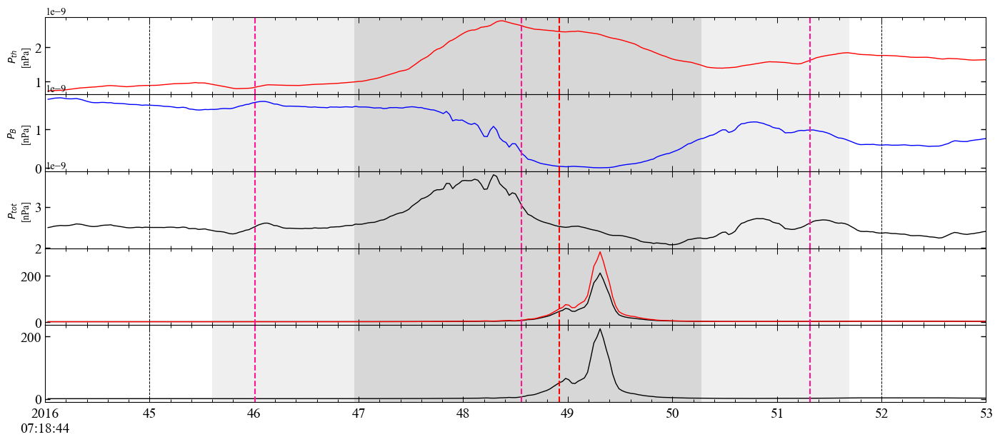

In [158]:
# separate pressure figure
pthl = beta_results[sc]["pth_Pa"].sel(time=slice(del3, del4))    # nPa
pB = beta_results[sc]["pB_Pa"].sel(time=slice(del3, del4))      # nPa
ptot = beta_results[sc]["ptot_Pa"].sel(time=slice(del3, del4))  # nPa

fig_p, axp = plt.subplots(5, 1, figsize=(17, 7), sharex=True,
                          gridspec_kw={'hspace': 0})

axp[0].plot(pthl.time, pthl, c='r', lw=1)
axp[0].set_ylabel(r'$P_{th}$' + '\n[nPa]', fontsize=10)

axp[1].plot(pB.time, pB, c='b', lw=1)
axp[1].set_ylabel(r'$P_B$' + '\n[nPa]', fontsize=10)

axp[2].plot(ptot.time, ptot, c='k', lw=1)
axp[2].set_ylabel(r'$P_{tot}$' + '\n[nPa]', fontsize=10)
axp[3].plot(ptot.time,  beta_results[sc]["beta_i_scalar"], c='k', lw=1)
axp[4].plot(ptot.time,   beta_results[sc]["beta_perpendicular"], c='k', lw=1)
axp[3].plot(ptot.time,  beta_results[sc]["beta_parallel"], c='r', lw=1)

for ax in axp:
    ax.set_xlim(
        hall[sc].lmn_b.time.sel(time=del3, method="nearest"),
        hall[sc].lmn_b.time.sel(time=del4, method="nearest")
    )
    ax.axvline(x=Bl.values, ls='--', c='r')
    ax.axvline(x=th_maxl.values, ls='--', c='#FF1493')
    ax.axvline(x=th_min.values, ls='--', c='#FF1493')
    ax.axvline(x=th_maxr.values, ls='--', c='#FF1493')

    ax.set_xticks(xticks(del3, del4)[0])
    ax.set_xticks(xticks(del3, del4)[1], minor=True)
    ax.set_xticklabels(xticks(del3, del4)[2], rotation=0, fontsize=14)

    ax.tick_params(axis='x', which='major', labelsize=14, size=6, width=0.7,
                   pad=5, direction='in', top=True, bottom=True)
    ax.tick_params(axis='x', which='minor', labelsize=14, size=3, width=0.7,
                   direction='in', top=True, bottom=True)
    ax.tick_params(axis='y', which='major', direction='in', left=True, right=True,
                   width=1, length=5, labelsize=14)
    ax.tick_params(axis='y', which='minor', direction='in', left=True, right=True,
                   width=1, length=3, labelsize=14)
    ax.grid(False)

    t = sorted([del3, t1, t2, del4])
    [ax.axvline(x, ls="--", c="k", lw=0.7) for x in t]

    x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
    x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
    x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
    x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

    ax.axvspan(x1, x2, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)
    ax.axvspan(x2, x3, color='#BDBDBD', alpha=0.6, lw=0, zorder=0)
    ax.axvspan(x3, x4, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)

fig_p.savefig(
    os.path.join(output_folder, f"{taistarttime}_pressure_{sc}.png"),
    dpi=600, format='png', bbox_inches='tight'
)
plt.show()

In [159]:
T_asym['mms4']["beta_i_sp"],T_asym['mms4']["beta_i_sh"]


(0.43617557683045177, 2.207042901601909)

In [160]:
beta_export = {}
beta_export['mms4'] = (
    beta_scalar
    .rename("beta_i_scalar")
    .to_dataframe()
    .reset_index()
)
output_file = "beta_scalar_results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    # One worksheet for each spacecraft
    for sc, df_beta in beta_export.items():

        # Excel worksheet names cannot exceed 31 characters
        sheet_name = str(sc)[:31]

        df_beta.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

    # Summary worksheet
    summary_rows = []

    for sc, df_beta in beta_export.items():

        beta_values = df_beta["beta_i_scalar"].dropna()

        summary_rows.append({
            "Spacecraft": sc,
            "Mean_beta_scalar": beta_values.mean(),
            "Median_beta_scalar": beta_values.median(),
            "Std_beta_scalar": beta_values.std(),
            "Minimum_beta_scalar": beta_values.min(),
            "Maximum_beta_scalar": beta_values.max(),
            "Number_of_points": beta_values.size
        })

    summary_df = pd.DataFrame(summary_rows)

    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

print(f"Export completed: {output_file}")

Export completed: beta_scalar_results.xlsx


In [161]:
t1,t2,del3,del4

(np.datetime64('2016-01-22T07:18:45.000'),
 np.datetime64('2016-01-22T07:18:52.000'),
 np.datetime64('2016-01-22T07:18:44.000'),
 np.datetime64('2016-01-22T07:18:53'))

In [162]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

for sc in sc_list:

    Bl_dict = {
    sc: find(hall[sc].lmn_b, LMN=0, d1=t1, d2=del4)[0]
    for sc in sc_list}
    Bl = Bl_dict[sc]
    print(f"Plotting for {Bl.values}...")

Plotting for 2016-01-22T07:18:48.919564000...
Plotting for 2016-01-22T07:18:48.679564000...
Plotting for 2016-01-22T07:18:49.279564000...
Plotting for 2016-01-22T07:18:48.919564000...


In [163]:
(x4-x1)

Timedelta('0 days 00:00:06.096147907')

IDF CHECK 2


REVIEWER 2 COMMENT 4 I Figure 3 shows only three time slices over about a 3 s window. Please provide ion moments, field-aligned and perpendicular temperatures, heat fluxes, and reduced 1D distributions along L, M, and N across the entire Hall region. A quantitative criterion is needed for "no persistent counterstreaming beams," such as whether the reduced distribution is single-peaked, D-shaped, or contains separated beams

Computing moments from 2016-01-22T07:18:45.019564000 → 2016-01-22T07:18:51.979564000
(233 samples, step=2)


25-Oct-26 18:59:44: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\847801878.py:328: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



<xarray.Dataset> Size: 9kB
Dimensions:  (time: 117)
Coordinates:
  * time     (time) datetime64[ns] 936B 2016-01-22T07:18:45.019564 ... 2016-0...
Data variables:
    n        (time) float64 936B 9.18 9.187 9.438 9.633 ... 34.97 34.9 34.6
    T_par    (time) float64 936B 393.3 389.8 392.0 389.8 ... 208.1 209.6 209.2
    T_perp   (time) float64 936B 608.5 604.1 607.2 603.9 ... 282.0 280.5 278.2
    q_L      (time) float64 936B 0.07649 0.07511 0.0816 ... -0.1099 -0.1079
    q_M      (time) float64 936B 0.0223 0.02317 0.02544 ... 0.03043 0.03036
    q_N      (time) float64 936B 0.004138 0.00529 -3.699e-06 ... 0.01461 0.01839
    u_L      (time) float64 936B -255.1 -254.5 -256.8 ... -15.3 -15.35 -15.48
    u_M      (time) float64 936B 26.84 26.61 28.28 ... -19.48 -20.94 -22.52
    u_N      (time) float64 936B -42.32 -42.62 -40.89 ... -72.6 -72.41 -72.08
Attributes:
    spacecraft:  mms4
    source:      computed from DIS distributions
    t_start:     2016-01-22T07:18:45.000
    t_end:     

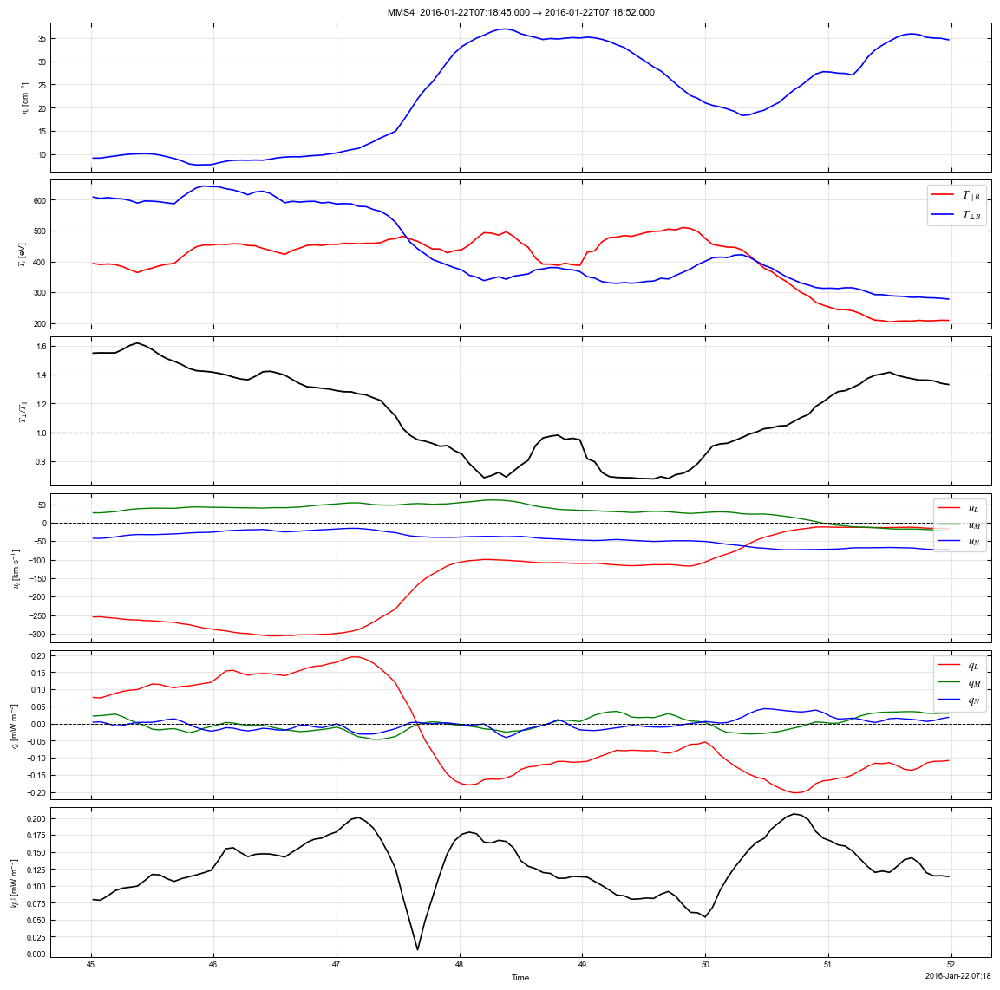

In [221]:
# FULL CODE: ion moments (n, T∥/T⊥ w.r.t. B, u, q) from DIS distributions
# ==============================================================================
import os
import warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
# ---------------------------------------------------------------------------
# 0. Physical constants (already in your file, repeated for completeness)
# ---------------------------------------------------------------------------
QE = 1.602176634e-19
MP = 1.67262192595e-27
# ---------------------------------------------------------------------------
# 1. Helper that was already in your script
# ---------------------------------------------------------------------------
def _energy_to_speed_kms(energy_ev, ion_mass=MP):
    energy_ev = np.asarray(energy_ev, dtype=float)
    return np.sqrt(2.0 * energy_ev * QE / ion_mass) / 1000.0
def _matrix_at_time(matrix, snapshot_time, name="matrix"):
    if matrix is None:
        return None
    selected = matrix
    if hasattr(selected, "dims") and "time" in selected.dims:
        selected = selected.sel(time=snapshot_time, method="nearest")
    values = np.asarray(selected.values if hasattr(selected, "values") else selected, dtype=float).squeeze()
    if values.shape != (3, 3):
        raise ValueError(f"{name} must resolve to a 3x3 matrix; received {values.shape}")
    if not np.all(np.isfinite(values)):
        raise ValueError(f"{name} contains non-finite values.")
    return values
def _lmn_vector_at_time(data_array, sample_time, name):
    selected = data_array.sel(time=sample_time, method="nearest")
    values = np.asarray(selected.values, dtype=float).squeeze()
    if values.ndim != 1 or values.size < 3:
        raise ValueError(f"{name} must resolve to at least three LMN components; received {values.shape}.")
    vector = values[:3]
    if not np.all(np.isfinite(vector)):
        raise ValueError(f"{name} contains non-finite LMN values at {sample_time}.")
    return vector
def make_velocity_grid_lmn(
    vds, time_index, eigvec, instrument_to_base=None,
    reverse_look_direction=True, theta_mode="polar", ion_mass=MP,
    eigvec_layout="columns", instrument_matrix_layout="columns",
):
    snapshot_time = vds.time.isel(time=time_index)
    phi = np.deg2rad(np.asarray(vds["v1"].isel(time=time_index).values, dtype=float))
    theta = np.deg2rad(np.asarray(vds["v2"].values, dtype=float))
    energy_ev = np.asarray(vds["v3"].isel(time=time_index).values, dtype=float)
    speed = _energy_to_speed_kms(energy_ev, ion_mass=ion_mass)
    PHI, THETA, SPEED = np.meshgrid(phi, theta, speed, indexing="ij")
    if theta_mode == "polar":
        vx = SPEED * np.sin(THETA) * np.cos(PHI)
        vy = SPEED * np.sin(THETA) * np.sin(PHI)
        vz = SPEED * np.cos(THETA)
    elif theta_mode == "elevation":
        vx = SPEED * np.cos(THETA) * np.cos(PHI)
        vy = SPEED * np.cos(THETA) * np.sin(PHI)
        vz = SPEED * np.sin(THETA)
    else:
        raise ValueError("theta_mode must be 'polar' or 'elevation'.")
    velocity_instrument = np.stack((vx, vy, vz), axis=-1)
    if reverse_look_direction:
        velocity_instrument = -velocity_instrument
    instrument_matrix = _matrix_at_time(instrument_to_base, snapshot_time, name="instrument_to_base")
    if instrument_matrix is None:
        velocity_base = velocity_instrument
    else:
        if instrument_matrix_layout == "rows":
            instrument_matrix = instrument_matrix.T
        velocity_base = np.einsum("...i,ij->...j", velocity_instrument, instrument_matrix, optimize=True)
    rotation = _matrix_at_time(eigvec, snapshot_time, name="eigvec")
    if eigvec_layout == "rows":
        rotation = rotation.T
    velocity_lmn = np.einsum("...i,ij->...j", velocity_base, rotation, optimize=True)
    return xr.DataArray(
        velocity_lmn,
        dims=("v1_dim", "v2_dim", "v3_dim", "LMN"),
        coords={
            "v1_dim": np.arange(phi.size),
            "v2_dim": np.arange(theta.size),
            "v3_dim": np.arange(energy_ev.size),
            "LMN": ["L", "M", "N"],
        },
        attrs={"units": "km/s"},
        name="ion_velocity_grid_lmn",
    )
def _velocity_bin_volumes_kms3(vds, time_index, ion_mass=MP):
    phi = np.deg2rad(vds["v1"].isel(time=time_index).values)
    theta = np.deg2rad(vds["v2"].values)
    energy_ev = vds["v3"].isel(time=time_index).values
    dphi = np.gradient(phi)
    dtheta = np.gradient(theta)
    dE = np.gradient(energy_ev)
    speed = _energy_to_speed_kms(energy_ev, ion_mass=ion_mass)
    dv = (dE * QE) / (ion_mass * (speed * 1e3)) / 1e3
    dOmega = np.abs(np.sin(theta)[None, :, None] * dtheta[None, :, None] * dphi[:, None, None])
    d3v = (speed[None, None, :] ** 2) * dv[None, None, :] * dOmega
    return d3v
# ---------------------------------------------------------------------------
# 2. Moment calculation with TRUE T∥ / T⊥ relative to B
# ---------------------------------------------------------------------------
def compute_ion_moments_lmn(
    vds,
    time_index,
    sc,
    eigvec,
    b_da,                               # magnetic field in LMN
    instrument_to_base=None,
    structure_speed_l=0.0,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
):
    dist_name = f"{sc}_dis_dist_brst"
    f = np.asarray(vds[dist_name].isel(time=time_index).values, dtype=float)
    vel = make_velocity_grid_lmn(
        vds=vds,
        time_index=time_index,
        eigvec=eigvec,
        instrument_to_base=instrument_to_base,
        reverse_look_direction=reverse_look_direction,
        theta_mode=theta_mode,
        ion_mass=ion_mass,
        eigvec_layout=eigvec_layout,
        instrument_matrix_layout=instrument_matrix_layout,
    ).values
    structure_vel = np.array([structure_speed_l, 0.0, 0.0])
    w = vel - structure_vel
    d3v = _velocity_bin_volumes_kms3(vds, time_index, ion_mass=ion_mass)
    good = np.isfinite(f) & (f > 0) & np.isfinite(d3v) & (d3v > 0)
    f_g   = f[good]
    d3v_g = d3v[good]
    w_g   = w[good]
    # ------------------------------------------------------------------
# Density (cm⁻³) – already correct
# ------------------------------------------------------------------
    n = np.sum(f_g * d3v_g) * 1e15          # cm⁻³
    if n <= 0:
        raise ValueError("Non-positive density")
# Bulk velocity (km s⁻¹)
    u = np.sum((f_g * d3v_g)[:, None] * w_g, axis=0) * 1e15 / n
# Thermal velocities in km s⁻¹
    c = w_g - u                              # (N, 3) km s⁻¹
# ------------------------------------------------------------------
# Pressure tensor in nPa
# ------------------------------------------------------------------
# Conversion chain:
#   m * (km/s)² * (cm⁻³)  →  need  (1000 m/km)² * (1e6 m⁻³/cm⁻³)
#   = factor 1e12
#   then *1e9 to nPa
# ------------------------------------------------------------------
    P = (ion_mass * 1e12 * 1e9) * np.einsum(
        "ni,nj,n->ij", c, c, f_g * d3v_g
    ) * 1e15                                 # nPa
# ------------------------------------------------------------------
# Temperature tensor in eV
# ------------------------------------------------------------------
    n_m3 = n * 1e6                           # m⁻³
# P (nPa) → Pa = *1e-9
    T = (P * 1e-9) / (n_m3 * QE)             # eV  (3×3)
# TRUE parallel / perpendicular temperatures w.r.t. B
    B_vec = _lmn_vector_at_time(b_da, vds.time.isel(time=time_index), name="B")
    B_mag = np.linalg.norm(B_vec)
    b_hat = B_vec / B_mag if B_mag > 1e-6 else np.array([1.0, 0.0, 0.0])
    T_par  = float(b_hat @ T @ b_hat)
    T_perp = 0.5 * (np.trace(T) - T_par)
# Thermal velocity already in km s⁻¹
    c = w_g - u                         # (N,3) km s⁻¹
# |c|² in (km s⁻¹)²
    c2 = np.sum(c**2, axis=1)
# Raw moment  Σ |c|² c_i f d³v
    S = np.einsum("n,ni,n->i", c2, c, f_g * d3v_g)   # (km/s)³ / cm³
# Convert to SI (W m⁻²) then to mW m⁻²
# factor = ½ m * 10³ (→ m/s)³ * 10¹⁵ (density) * 10⁶ (cm⁻³→m⁻³) * 10³ (→ mW)
    factor = 0.5 * ion_mass * 1e9 * 1e15 * 1e6 * 1e3
    q = factor * S                                   # mW m⁻²
    return {
        "n": float(n),
        "u_lmn": u,
        "T_lmn": T,
        "T_par": T_par,
        "T_perp": T_perp,
        "P_lmn": P,
        "q_lmn": q,
        "time": vds.time.isel(time=time_index).values,
        "b_hat": b_hat,
    }
# ==============================================================================
# 3. USER SETTINGS – change these
# ==============================================================================
sc = "mms4"
# --- time window (choose ONE of the three options) ----------------------------
# Option A – explicit start / end
t_start = t1
t_end   = t2
# Option B – start + duration
# t_start = np.datetime64("2016-01-22T07:20:00")
# t_end   = t_start + np.timedelta64(5, "m")
# Option C – same interval as your overview plot
# t_start = del3
# t_end   = del4
# ------------------------------------------------------------------------------
step = 2                    # 1 = every sample (slower)
structure_speed_l = 0.0     # same value you use for the VDF plots
output_folder = output_folder   # already defined in your notebook
taistarttime  = taistarttime    # already defined
# magnetic field and distribution
vds  = vidatasets_interp[sc]
b_da = hall[sc]["lmn_b"]        # change key if necessary
# ==============================================================================
# 4. Compute moments inside the chosen window
# ==============================================================================
vds_sel = vds.sel(time=slice(t_start, t_end))
print(f"Computing moments from {vds_sel.time.values[0]} → {vds_sel.time.values[-1]}")
print(f"({len(vds_sel.time)} samples, step={step})")
times, n_vals, Tpar, Tperp = [], [], [], []
qL, qM, qN = [], [], []
uL, uM, uN = [], [], []
for it in range(0, len(vds_sel.time), step):
    global_idx = int(np.argmin(np.abs(vds.time.values - vds_sel.time.values[it])))
    try:
        mom = compute_ion_moments_lmn(
            vds=vds,
            time_index=global_idx,
            sc=sc,
            eigvec=eigvec,
            b_da=b_da,
            instrument_to_base=None,
            structure_speed_l=structure_speed_l,
            reverse_look_direction=True,
            theta_mode="polar",
            eigvec_layout="columns",
        )
        times.append(np.datetime64(mom["time"], "ns"))
        n_vals.append(mom["n"])
        Tpar.append(mom["T_par"])
        Tperp.append(mom["T_perp"])
        qL.append(mom["q_lmn"][0])
        qM.append(mom["q_lmn"][1])
        qN.append(mom["q_lmn"][2])
        uL.append(mom["u_lmn"][0])
        uM.append(mom["u_lmn"][1])
        uN.append(mom["u_lmn"][2])
    except Exception as e:
        print(f"skipping index {global_idx}: {e}")
        continue
moments_ds = xr.Dataset(
    data_vars={
        "n":      (["time"], np.asarray(n_vals, dtype=float)),
        "T_par":  (["time"], np.asarray(Tpar,   dtype=float)),
        "T_perp": (["time"], np.asarray(Tperp,  dtype=float)),
        "q_L":    (["time"], np.asarray(qL,     dtype=float)),
        "q_M":    (["time"], np.asarray(qM,     dtype=float)),
        "q_N":    (["time"], np.asarray(qN,     dtype=float)),
        "u_L":    (["time"], np.asarray(uL,     dtype=float)),
        "u_M":    (["time"], np.asarray(uM,     dtype=float)),
        "u_N":    (["time"], np.asarray(uN,     dtype=float)),
    },
    coords={"time": np.asarray(times, dtype="datetime64[ns]")},
    attrs={
        "spacecraft": sc,
        "source": "computed from DIS distributions",
        "t_start": str(t_start),
        "t_end":   str(t_end),
        "n_units": "cm^-3",
        "T_units": "eV",
        "q_units": "mW m^-2",
        "u_units": "km s^-1",
        "note": "T_par / T_perp are with respect to the instantaneous magnetic field",
    },
)
print(moments_ds)
# ==============================================================================

# 5. Save NetCDF + CSV
# ==============================================================================
out_nc  = os.path.join(output_folder, f"{taistarttime}_{sc}_ion_moments.nc")
out_csv = os.path.join(output_folder, f"{taistarttime}_{sc}_ion_moments.csv")
moments_ds.to_netcdf(out_nc)
df = moments_ds.to_dataframe().reset_index()
df.to_csv(out_csv, index=False)
print(f"NetCDF → {out_nc}")
print(f"CSV    → {out_csv}")
# ==============================================================================
# Multi-panel plot  (anisotropy placed BELOW T∥ / T⊥)
# ==============================================================================
fig, axs = plt.subplots(6, 1, figsize=(14, 14), sharex=True,
                        gridspec_kw={"hspace": 0.05})
# ---------- 0. Density ----------
axs[0].plot(moments_ds.time, moments_ds.n, "b", lw=1.2)
axs[0].set_ylabel(r"$n_i$ [cm$^{-3}$]")
axs[0].set_title(f"{sc.upper()}  {t_start} → {t_end}")
# ---------- 1. Temperatures (∥ and ⊥ to B) ----------
axs[1].plot(moments_ds.time, moments_ds.T_par,  "r", lw=1.2, label=r"$T_{\parallel B}$")
axs[1].plot(moments_ds.time, moments_ds.T_perp, "b", lw=1.2, label=r"$T_{\perp B}$")
axs[1].set_ylabel(r"$T_i$ [eV]")
axs[1].legend(loc="upper right", fontsize=9)
# ---------- 2. Temperature anisotropy (directly below T∥/T⊥) ----------
anisotropy = moments_ds.T_perp / moments_ds.T_par
axs[2].plot(moments_ds.time, anisotropy, "k", lw=1.3)
axs[2].axhline(1.0, c="0.5", ls="--", lw=0.9)          # isotropic line
axs[2].set_ylabel(r"$T_{\perp}/T_{\parallel}$")
# ---------- 3. Bulk velocity ----------
axs[3].plot(moments_ds.time, moments_ds.u_L, "r", lw=1.0, label=r"$u_L$")
axs[3].plot(moments_ds.time, moments_ds.u_M, "g", lw=1.0, label=r"$u_M$")
axs[3].plot(moments_ds.time, moments_ds.u_N, "b", lw=1.0, label=r"$u_N$")
axs[3].axhline(0, c="k", ls="--", lw=0.7)
axs[3].set_ylabel(r"$u_i$ [km s$^{-1}$]")
axs[3].legend(loc="upper right", fontsize=9)
# ---------- 4. Heat-flux components ----------
axs[4].plot(moments_ds.time, moments_ds.q_L, "r", lw=1.0, label=r"$q_L$")
axs[4].plot(moments_ds.time, moments_ds.q_M, "g", lw=1.0, label=r"$q_M$")
axs[4].plot(moments_ds.time, moments_ds.q_N, "b", lw=1.0, label=r"$q_N$")
axs[4].axhline(0, c="k", ls="--", lw=0.7)
axs[4].set_ylabel(r"$q_i$ [mW m$^{-2}$]")
axs[4].legend(loc="upper right", fontsize=9)
# ---------- 5. |q| ----------
q_mag = np.sqrt(moments_ds.q_L**2 + moments_ds.q_M**2 + moments_ds.q_N**2)
axs[5].plot(moments_ds.time, q_mag, "k", lw=1.2)
axs[5].set_ylabel(r"$|q_i|$ [mW m$^{-2}$]")
axs[5].set_xlabel("Time")
for ax in axs:
    ax.grid(True, alpha=0.3)
    ax.tick_params(direction="in", top=True, right=True)
fig.tight_layout()
fig.savefig(
    os.path.join(output_folder, f"{taistarttime}_{sc}_ion_moments.png"),
    dpi=300, bbox_inches="tight",
)
plt.show() 

Reviewer 2 comment 4 II A single unipolar B_N, a monotonic B_L reversal, and the absence of counterstreaming beams do not by themselves exclude multiple X-lines or islands, especially if the spacecraft does not cross an island core. Can the four-spacecraft MMS configuration be used to test for a second X-line along L? Please show the other three spacecraft's B_L, B_M, B_N, |B|, and ion spectrograms, or at least explain whether they observed the same single crossing.

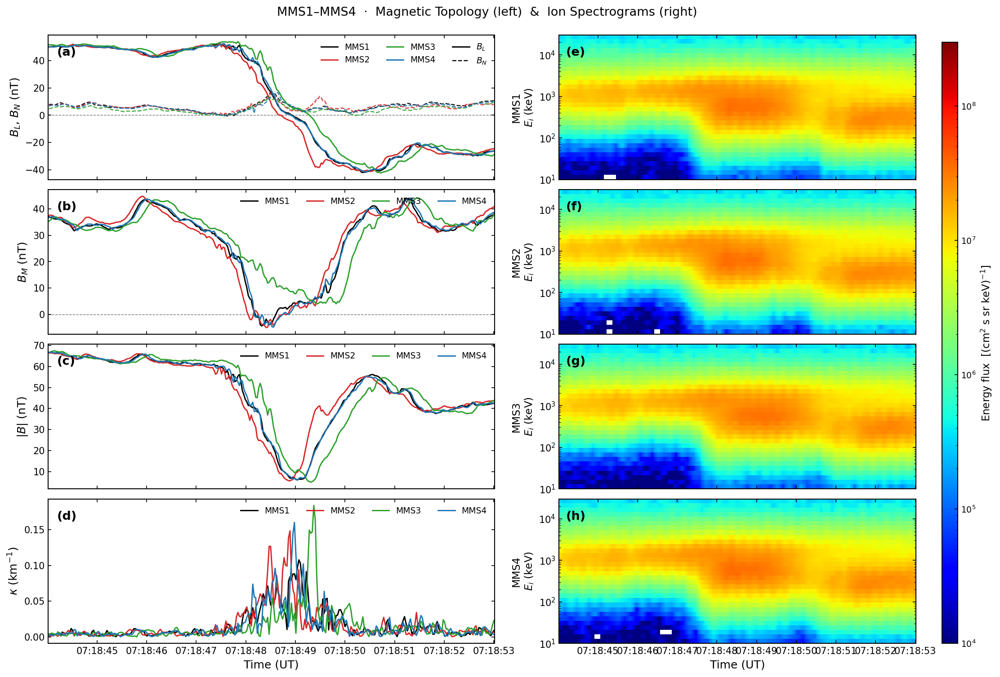

In [167]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import matplotlib.dates as mdates

# -------------------------------------------------
# Style settings (GRL-friendly)
# -------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.linewidth": 1.0,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

sc_list = ["mms1", "mms2", "mms3", "mms4"]
colors  = {"mms1": "#000000", "mms2": "#D62728", "mms3": "#2CA02C", "mms4": "#1F77B4"}
labels  = {"mms1": "MMS1", "mms2": "MMS2", "mms3": "MMS3", "mms4": "MMS4"}
V_cross = -46.8   # km/s

# -------------------------------------------------
# Prepare magnetic + curvature data
# -------------------------------------------------
data = {}

for sc in sc_list:
    B = hall[sc]["lmn_b"].sel(time=slice(del3, del4))
    
    BL = B.sel(LMN=0)
    BM = B.sel(LMN=1)
    BN = B.sel(LMN=2)
    Bmag = np.sqrt(BL**2 + BM**2 + BN**2)

    # Guide-field corrected B_M (safe)
    try:
        BM_corr = BM - res_all[sc]["Bg_linear"] + df_all.loc[sc, "$B_g$"]
    except Exception:
        BM_corr = BM

    bL = BL / Bmag
    bM = BM / Bmag
    bN = BN / Bmag

    t_sec = (B.time.values.astype("datetime64[ns]").astype(np.int64) * 1e-9)
    dbLdt = np.gradient(bL.values, t_sec)
    dbMdt = np.gradient(bM.values, t_sec)
    dbNdt = np.gradient(bN.values, t_sec)
    kappa = np.sqrt(dbLdt**2 + dbMdt**2 + dbNdt**2) / np.abs(V_cross)

    data[sc] = dict(
        time = B.time,
        BL   = BL,
        BM   = BM_corr,
        BN   = BN,
        Bmag = Bmag,
        kappa= kappa
    )

# -------------------------------------------------
# Figure layout
# -------------------------------------------------
fig = plt.figure(figsize=(15.5, 10.5), dpi=150)

gs = GridSpec(4, 2, figure=fig,
              width_ratios=[1.25, 1.0],
              height_ratios=[1, 1, 1, 1],
              hspace=0.07, wspace=0.16,
              left=0.08, right=0.91, top=0.93, bottom=0.07)

# Left column
ax0 = fig.add_subplot(gs[0, 0])               # B_L + B_N
ax1 = fig.add_subplot(gs[1, 0], sharex=ax0)   # B_M
ax2 = fig.add_subplot(gs[2, 0], sharex=ax0)   # |B|
ax3 = fig.add_subplot(gs[3, 0], sharex=ax0)   # kappa

# Right column – ion spectrograms
ax_s = [fig.add_subplot(gs[i, 1], sharex=ax0) for i in range(4)]

# -------------------------------------------------
# Left column – magnetic topology
# -------------------------------------------------
for sc in sc_list:
    d = data[sc]
    c = colors[sc]
    lw = 1.4

    # Panel 0: B_L (solid) + B_N (dashed)
    ax0.plot(d["time"], d["BL"], color=c, lw=lw, label=labels[sc])
    ax0.plot(d["time"], d["BN"], color=c, lw=1.15, ls="--", alpha=0.9)

    # Panel 1: B_M
    ax1.plot(d["time"], d["BM"], color=c, lw=lw, label=labels[sc])

    # Panel 2: |B|
    ax2.plot(d["time"], d["Bmag"], color=c, lw=lw, label=labels[sc])

    # Panel 3: curvature
    ax3.plot(d["time"], d["kappa"], color=c, lw=lw, label=labels[sc])

# Zero lines
for ax in [ax0, ax1]:
    ax.axhline(0, color="0.45", ls="--", lw=0.7, zorder=0)

# Labels & legends
ax0.set_ylabel(r"$B_L$, $B_N$ (nT)", fontsize=12)
ax0.plot([], [], color="k", ls="-",  lw=1.4,  label=r"$B_L$")
ax0.plot([], [], color="k", ls="--", lw=1.15, label=r"$B_N$")
ax0.legend(loc="upper right", ncol=3, frameon=False, fontsize=9)

ax1.set_ylabel(r"$B_M$ (nT)", fontsize=12)
ax1.legend(loc="upper right", ncol=4, frameon=False, fontsize=9)

ax2.set_ylabel(r"$|B|$ (nT)", fontsize=12)
ax2.legend(loc="upper right", ncol=4, frameon=False, fontsize=9)

ax3.set_ylabel(r"$\kappa$ (km$^{-1}$)", fontsize=12)
ax3.set_xlabel("Time (UT)", fontsize=12)
ax3.legend(loc="upper right", ncol=4, frameon=False, fontsize=9)

# Hide x-tick labels on upper left panels
for ax in [ax0, ax1, ax2]:
    plt.setp(ax.get_xticklabels(), visible=False)

# -------------------------------------------------
# Right column – ion spectrograms
# -------------------------------------------------
pcm = None
for i, sc in enumerate(sc_list):
    ax = ax_s[i]

    i_da = idatasets_interp[sc][f"{sc}_dis_energyspectr_omni_brst"].sel(
        time=slice(del3, del4)
    )
    i_time   = i_da.time.values
    i_energy = i_da.spec_bins.mean("time", skipna=True).values
    i_flux   = i_da.transpose("e_dim", "time").values
    i_flux   = np.where(np.isfinite(i_flux) & (i_flux > 0), i_flux, np.nan)

    pcm = ax.pcolormesh(
        i_time, i_energy, i_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=3e8),
        shading="auto",
        rasterized=True
    )

    ax.set_yscale("log")
    ax.set_ylabel(f"{labels[sc]}\n$E_i$ (keV)", fontsize=11)
    ax.set_ylim(1e1, 3e4)

    if i < 3:
        plt.setp(ax.get_xticklabels(), visible=False)
    else:
        ax.set_xlabel("Time (UT)", fontsize=12)

# Colorbar
cax = fig.add_axes([0.935, 0.07, 0.015, 0.85])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Energy flux  [(cm$^{2}$ s sr keV)$^{-1}$]", fontsize=11)
cbar.ax.tick_params(labelsize=9)

# -------------------------------------------------
# Panel labels (a), (b), (c) ...
# -------------------------------------------------
panel_labels = ["a", "b", "c", "d", "e", "f", "g", "h"]
all_axes = [ax0, ax1, ax2, ax3] + ax_s

for ax, lab in zip(all_axes, panel_labels):
    ax.text(
        0.02, 0.92, f"({lab})",
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="top", ha="left",
        zorder=20
    )

# -------------------------------------------------
# Final formatting
# -------------------------------------------------
for ax in all_axes:
    ax.tick_params(labelsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))

fig.suptitle("MMS1–MMS4  ·  Magnetic Topology (left)  &  Ion Spectrograms (right)",
             fontsize=13, fontweight="medium", y=0.97)

# Save
fig.savefig(os.path.join(output_folder, f"{taistarttime}_topology_spectrograms.png"),
            dpi=600, bbox_inches="tight")
fig.savefig(os.path.join(output_folder, f"{taistarttime}_topology_spectrograms.pdf"),
            bbox_inches="tight")

plt.show()

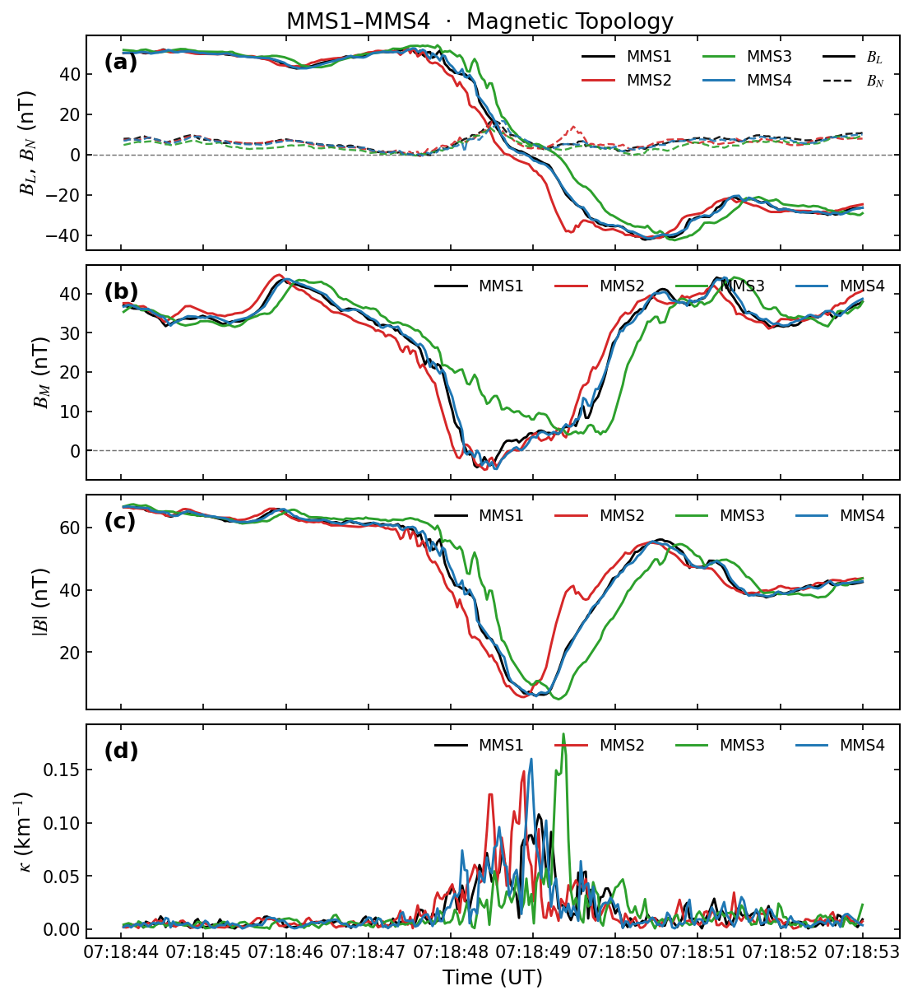

In [136]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# -------------------------------------------------
# Style settings (GRL-friendly)
# -------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.linewidth": 1.0,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

sc_list = ["mms1", "mms2", "mms3", "mms4"]
colors  = {"mms1": "#000000", "mms2": "#D62728", "mms3": "#2CA02C", "mms4": "#1F77B4"}
labels  = {"mms1": "MMS1", "mms2": "MMS2", "mms3": "MMS3", "mms4": "MMS4"}
V_cross = -46.8   # km/s

# -------------------------------------------------
# Prepare magnetic + curvature data
# -------------------------------------------------
data = {}
for sc in sc_list:
    B = hall[sc]["lmn_b"].sel(time=slice(del3, del4))

    BL = B.sel(LMN=0)
    BM = B.sel(LMN=1)
    BN = B.sel(LMN=2)
    Bmag = np.sqrt(BL**2 + BM**2 + BN**2)

    # Guide-field corrected B_M (safe)
    try:
        BM_corr = BM - res_all[sc]["Bg_linear"] + df_all.loc[sc, "$B_g$"]
    except Exception:
        BM_corr = BM

    bL = BL / Bmag
    bM = BM / Bmag
    bN = BN / Bmag

    t_sec = (B.time.values.astype("datetime64[ns]").astype(np.int64) * 1e-9)
    dbLdt = np.gradient(bL.values, t_sec)
    dbMdt = np.gradient(bM.values, t_sec)
    dbNdt = np.gradient(bN.values, t_sec)

    kappa = np.sqrt(dbLdt**2 + dbMdt**2 + dbNdt**2) / np.abs(V_cross)

    data[sc] = dict(
        time = B.time,
        BL   = BL,
        BM   = BM_corr,
        BN   = BN,
        Bmag = Bmag,
        kappa= kappa
    )

# -------------------------------------------------
# Figure layout – single column only
# -------------------------------------------------
fig, axs = plt.subplots(
    4, 1,
    figsize=(8.5, 9.5),
    sharex=True,
    gridspec_kw={"hspace": 0.07},
    dpi=150,
)

ax0, ax1, ax2, ax3 = axs

# -------------------------------------------------
# Magnetic topology panels
# -------------------------------------------------
for sc in sc_list:
    d = data[sc]
    c = colors[sc]
    lw = 1.4

    # Panel 0: B_L (solid) + B_N (dashed)
    ax0.plot(d["time"], d["BL"], color=c, lw=lw, label=labels[sc])
    ax0.plot(d["time"], d["BN"], color=c, lw=1.15, ls="--", alpha=0.9)

    # Panel 1: B_M
    ax1.plot(d["time"], d["BM"], color=c, lw=lw, label=labels[sc])

    # Panel 2: |B|
    ax2.plot(d["time"], d["Bmag"], color=c, lw=lw, label=labels[sc])

    # Panel 3: curvature
    ax3.plot(d["time"], d["kappa"], color=c, lw=lw, label=labels[sc])

# Zero lines
for ax in [ax0, ax1]:
    ax.axhline(0, color="0.45", ls="--", lw=0.7, zorder=0)

# Labels & legends
ax0.set_ylabel(r"$B_L$, $B_N$ (nT)", fontsize=12)
ax0.plot([], [], color="k", ls="-",  lw=1.4,  label=r"$B_L$")
ax0.plot([], [], color="k", ls="--", lw=1.15, label=r"$B_N$")
ax0.legend(loc="upper right", ncol=3, frameon=False, fontsize=9)

ax1.set_ylabel(r"$B_M$ (nT)", fontsize=12)
ax1.legend(loc="upper right", ncol=4, frameon=False, fontsize=9)

ax2.set_ylabel(r"$|B|$ (nT)", fontsize=12)
ax2.legend(loc="upper right", ncol=4, frameon=False, fontsize=9)

ax3.set_ylabel(r"$\kappa$ (km$^{-1}$)", fontsize=12)
ax3.set_xlabel("Time (UT)", fontsize=12)
ax3.legend(loc="upper right", ncol=4, frameon=False, fontsize=9)

# Hide x-tick labels on upper panels
for ax in [ax0, ax1, ax2]:
    plt.setp(ax.get_xticklabels(), visible=False)

# -------------------------------------------------
# Panel labels (a)–(d)
# -------------------------------------------------
panel_labels = ["a", "b", "c", "d"]
for ax, lab in zip(axs, panel_labels):
    ax.text(
        0.02, 0.92, f"({lab})",
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="top", ha="left",
        zorder=20
    )

# -------------------------------------------------
# Final formatting
# -------------------------------------------------
for ax in axs:
    ax.tick_params(labelsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))

fig.suptitle("MMS1–MMS4  ·  Magnetic Topology",
             fontsize=13, fontweight="medium", y=0.90)

# Save
fig.savefig(os.path.join(output_folder, f"{taistarttime}_topology.png"),
            dpi=600, bbox_inches="tight")
fig.savefig(os.path.join(output_folder, f"{taistarttime}_topology.pdf"),
            bbox_inches="tight")
plt.show()


Three-panel DIS selection (extremes removed)

1.                     requested=2016-01-22T07:18:47.108918000  actual=2016-01-22T07:18:47.119564000  delta=+10.6 ms
2. B_M minimum         requested=2016-01-22T07:18:48.559564000  actual=2016-01-22T07:18:48.559564000  delta=+0.0 ms
3.                     requested=2016-01-22T07:18:50.061191000  actual=2016-01-22T07:18:50.059564000  delta=-1.6 ms

Native plotted PSD ranges [s^3 cm^-6]

Column 1: 2016-01-22T07:18:47.119
  M-L: min=1.743e-27, max=2.439e-22
  N-L: min=1.854e-27, max=2.449e-22
  N-M: min=7.676e-28, max=1.394e-22
Column 2: 2016-01-22T07:18:48.559
  M-L: min=3.646e-27, max=8.057e-22
  N-L: min=3.747e-27, max=8.475e-22
  N-M: min=2.707e-27, max=5.017e-22
Column 3: 2016-01-22T07:18:50.059
  M-L: min=3.966e-27, max=6.885e-22
  N-L: min=8.085e-27, max=6.719e-22
  N-M: min=5.326e-27, max=4.171e-22


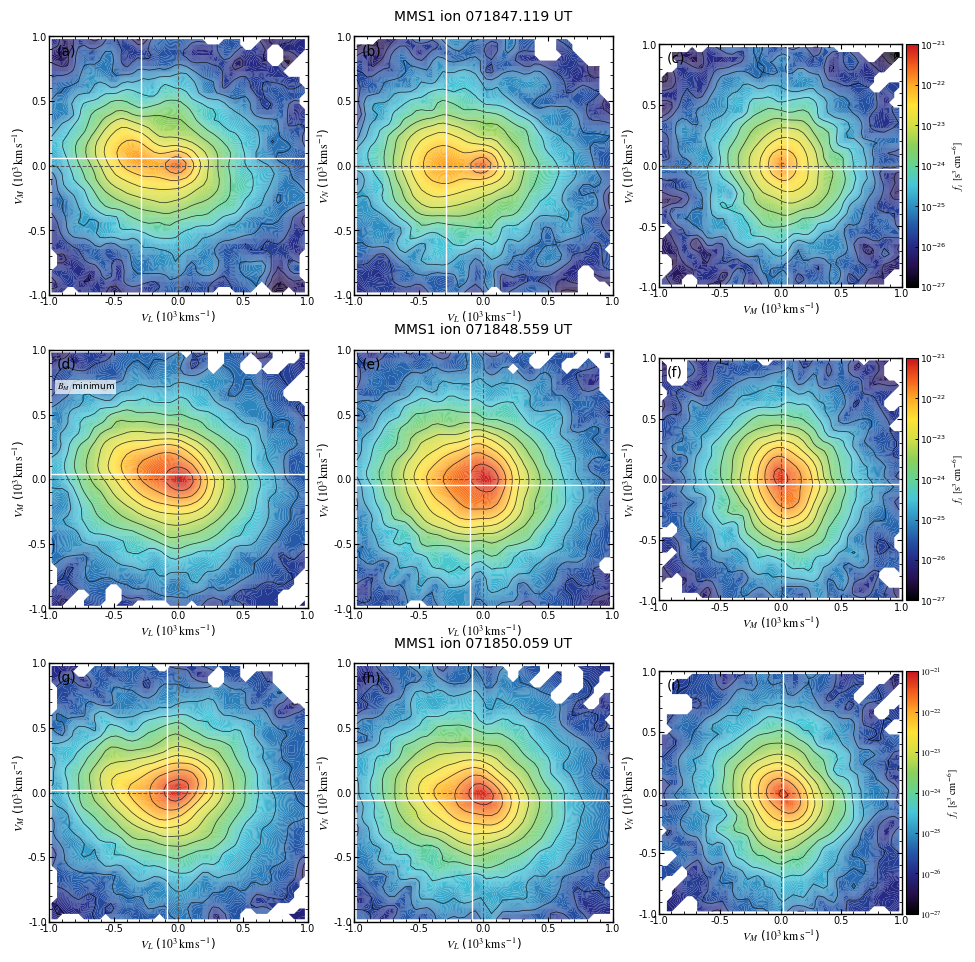

In [174]:
import os
import string
import warnings

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter, zoom
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MultipleLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable


# ============================================================
# Physical constants
# ============================================================
QE = 1.602176634e-19
MP = 1.67262192595e-27

# Native MMS/FPI DIS phase-space-density units:
#     s^3 cm^-6


# ============================================================
# Paper-style colormap
# ============================================================
def make_paper_vdf_colormap():
    """
    Approximate the black-purple-blue-cyan-green-yellow-red scale
    used in the reference ion-VDF figure.
    """
    colors = [
        "black",
        "#26104f",
        "#252a86",
        "#2457a7",
        "#2f91c2",
        "#47c6d8",
        "#63d394",
        "#8bd05b",
        "#d3df45",
        "#ffe234",
        "#ffab26",
        "#f35b1d",
        "#c9151e",
    ]

    cmap = LinearSegmentedColormap.from_list(
        "paper_ion_vdf",
        colors,
        N=256,
    )

    cmap.set_under("black")
    cmap.set_over("#8b0000")
    cmap.set_bad("white")

    return cmap


PAPER_CMAP = make_paper_vdf_colormap()


# ============================================================
# Small helpers
# ============================================================
def _energy_to_speed_kms(energy_ev, ion_mass=MP):
    """Convert ion energy in eV to speed in km/s."""
    energy_ev = np.asarray(energy_ev, dtype=float)

    if np.any(energy_ev < 0):
        raise ValueError("Energy values must be non-negative.")

    return np.sqrt(
        2.0 * energy_ev * QE / ion_mass
    ) / 1000.0


def _matrix_at_time(matrix, snapshot_time, name="matrix"):
    """
    Select a fixed or time-dependent 3x3 matrix.
    """
    if matrix is None:
        return None

    selected = matrix

    if hasattr(selected, "dims") and "time" in selected.dims:
        selected = selected.sel(
            time=snapshot_time,
            method="nearest",
        )

    values = np.asarray(
        selected.values if hasattr(selected, "values") else selected,
        dtype=float,
    ).squeeze()

    if values.shape != (3, 3):
        raise ValueError(
            f"{name} must resolve to a 3x3 matrix; "
            f"received {values.shape}"
        )

    if not np.all(np.isfinite(values)):
        raise ValueError(
            f"{name} contains non-finite values."
        )

    return values


def _paper_decade_formatter(value, position):
    """
    Format logarithmic ticks as 1x10^n, matching the reference style.
    """
    if not np.isfinite(value) or value <= 0:
        return ""

    exponent = int(np.round(np.log10(value)))

    return rf"$10^{{{exponent}}}$"


# ============================================================
# Transform the complete FPI velocity-bin grid into LMN
# ============================================================
def make_velocity_grid_lmn(
    vds,
    time_index,
    eigvec,
    instrument_to_base=None,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
):
    """
    Construct every MMS/FPI DIS velocity bin in LMN.

    Default matrix convention
    -------------------------
        vector_lmn = vector_original @ eigvec

    Therefore, with eigvec_layout="columns", the columns of eigvec
    are L, M, and N expressed in the input coordinate system.
    """
    snapshot_time = vds.time.isel(time=time_index)

    phi = np.deg2rad(
        np.asarray(
            vds["v1"].isel(time=time_index).values,
            dtype=float,
        )
    )

    theta = np.deg2rad(
        np.asarray(
            vds["v2"].values,
            dtype=float,
        )
    )

    energy_ev = np.asarray(
        vds["v3"].isel(time=time_index).values,
        dtype=float,
    )

    speed = _energy_to_speed_kms(
        energy_ev,
        ion_mass=ion_mass,
    )

    PHI, THETA, SPEED = np.meshgrid(
        phi,
        theta,
        speed,
        indexing="ij",
    )

    if theta_mode == "polar":
        vx = SPEED * np.sin(THETA) * np.cos(PHI)
        vy = SPEED * np.sin(THETA) * np.sin(PHI)
        vz = SPEED * np.cos(THETA)

    elif theta_mode == "elevation":
        vx = SPEED * np.cos(THETA) * np.cos(PHI)
        vy = SPEED * np.cos(THETA) * np.sin(PHI)
        vz = SPEED * np.sin(THETA)

    else:
        raise ValueError(
            "theta_mode must be 'polar' or 'elevation'."
        )

    # Raw detector look-direction vectors
    velocity_instrument = np.stack(
        (vx, vy, vz),
        axis=-1,
    )

    # Convert detector look direction to particle velocity
    if reverse_look_direction:
        velocity_instrument = -velocity_instrument

    # Instrument frame -> base frame
    instrument_matrix = _matrix_at_time(
        instrument_to_base,
        snapshot_time,
        name="instrument_to_base",
    )

    if instrument_matrix is None:
        velocity_base = velocity_instrument

    else:
        if instrument_matrix_layout == "rows":
            instrument_matrix = instrument_matrix.T

        elif instrument_matrix_layout != "columns":
            raise ValueError(
                "instrument_matrix_layout must be "
                "'columns' or 'rows'."
            )

        velocity_base = np.einsum(
            "...i,ij->...j",
            velocity_instrument,
            instrument_matrix,
            optimize=True,
        )

    # Base frame -> LMN
    rotation = _matrix_at_time(
        eigvec,
        snapshot_time,
        name="eigvec",
    )

    if eigvec_layout == "rows":
        rotation = rotation.T

    elif eigvec_layout != "columns":
        raise ValueError(
            "eigvec_layout must be 'columns' or 'rows'."
        )

    velocity_lmn = np.einsum(
        "...i,ij->...j",
        velocity_base,
        rotation,
        optimize=True,
    )

    return xr.DataArray(
        velocity_lmn,
        dims=(
            "v1_dim",
            "v2_dim",
            "v3_dim",
            "LMN",
        ),
        coords={
            "v1_dim": np.arange(phi.size),
            "v2_dim": np.arange(theta.size),
            "v3_dim": np.arange(energy_ev.size),
            "LMN": ["L", "M", "N"],
        },
        attrs={"units": "km/s"},
        name="ion_velocity_grid_lmn",
    )


# ============================================================
# Time and LMN-moment helpers
# ============================================================
def _to_datetime64_ns(value, name="time"):
    """
    Convert an xarray, pandas, NumPy, or scalar timestamp to
    one datetime64[ns] value.
    """
    if hasattr(value, "values"):
        value = value.values

    array = np.asarray(value)

    if array.size != 1:
        raise ValueError(
            f"{name} must contain exactly one timestamp; "
            f"received shape {array.shape}."
        )

    return np.datetime64(array.reshape(-1)[0], "ns")


def _nearest_dis_sample(vds, requested_time):
    """
    Find the nearest available DIS distribution to a requested time.

    Returns
    -------
    actual_time : numpy.datetime64
    index : int
    difference_ms : float
        actual_time - requested_time, in milliseconds.
    """
    requested_time = _to_datetime64_ns(
        requested_time,
        name="requested_time",
    )

    available_times = vds.time.values.astype("datetime64[ns]")

    if available_times.size == 0:
        raise ValueError("The DIS dataset contains no time samples.")

    index = int(
        np.argmin(
            np.abs(available_times - requested_time)
        )
    )

    actual_time = available_times[index]

    difference_ms = float(
        (actual_time - requested_time)
        / np.timedelta64(1, "ms")
    )

    return actual_time, index, difference_ms


def _lmn_vector_at_time(data_array, sample_time, name):
    """
    Select the nearest LMN vector and return its first three components.

    Expected component order:
        [L, M, N]
    """
    selected = data_array.sel(
        time=sample_time,
        method="nearest",
    )

    values = np.asarray(
        selected.values,
        dtype=float,
    ).squeeze()

    if values.ndim != 1 or values.size < 3:
        raise ValueError(
            f"{name} must resolve to at least three LMN components; "
            f"received shape {values.shape}."
        )

    vector = values[:3]

    if not np.all(np.isfinite(vector)):
        raise ValueError(
            f"{name} contains non-finite LMN values at {sample_time}."
        )

    return vector


# ============================================================
# Select exactly THREE VDFs (drop extreme left & extreme right)
# ============================================================
def build_three_vdf_selection(
    vidatasets_interp,
    bm_cross,
    sc,
    th_min,
    time_offset_ms=150,
):
    """
    Select the three central locations (drop extreme left & right):

        1. x2 + time_offset
        2. B_M minimum
        3. x3 - time_offset

    (Original five were: x2-off, x2+off, BMmin, x3-off, x3+off)
    """
    if sc not in vidatasets_interp:
        raise KeyError(
            f"{sc!r} is absent from vidatasets_interp."
        )

    vds = vidatasets_interp[sc]
    offset = np.timedelta64(int(time_offset_ms), "ms")

    x2 = _to_datetime64_ns(
        bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[1],
        name="x2",
    )

    x3 = _to_datetime64_ns(
        bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[0],
        name="x3",
    )

    bm_minimum_time = _to_datetime64_ns(
        th_min,
        name="th_min",
    )

    # Keep only the three central times
    requested_times = [
        x2 + offset,          # right of x2
        bm_minimum_time,      # B_M minimum
        x3 - offset,          # left of x3
    ]

    location_labels = [
        r"",
        r"$B_M$ minimum",
        r"",
    ]

    actual_times = []
    indices = []
    differences_ms = []

    for requested_time in requested_times:
        actual_time, index, difference_ms = _nearest_dis_sample(
            vds,
            requested_time,
        )

        actual_times.append(actual_time)
        indices.append(index)
        differences_ms.append(difference_ms)

    if len(set(indices)) != 3:
        duplicate_indices = sorted({
            index
            for index in indices
            if indices.count(index) > 1
        })

        warnings.warn(
            "Some requested locations selected the same DIS distribution. "
            f"Duplicate DIS indices: {duplicate_indices}. "
            "Increase time_offset_ms if three distinct distributions are needed.",
            RuntimeWarning,
            stacklevel=2,
        )

    selection = {
        "x2": x2,
        "x3": x3,
        "bm_minimum_time": bm_minimum_time,
        "requested_times": requested_times,
        "actual_times": actual_times,
        "indices": indices,
        "differences_ms": differences_ms,
        "location_labels": location_labels,
    }

    print("\nThree-panel DIS selection (extremes removed)\n")

    for panel_number, (
        label,
        requested_time,
        actual_time,
        difference_ms,
    ) in enumerate(
        zip(
            location_labels,
            requested_times,
            actual_times,
            differences_ms,
        ),
        start=1,
    ):
        printable_label = (
            label
            .replace("$", "")
            .replace("\\", "")
            .replace("{", "")
            .replace("}", "")
        )

        print(
            f"{panel_number}. {printable_label:<18s}  "
            f"requested={requested_time}  "
            f"actual={actual_time}  "
            f"delta={difference_ms:+.1f} ms"
        )

    return selection


# ============================================================
# One LMN-plane snapshot
# ============================================================
def make_lmn_plane_snapshot(
    vds,
    vi_da,
    eigvec,
    time_index,
    sc,
    x_component,
    y_component,
    instrument_to_base=None,
    structure_speed_l=0.0,
    velocity_range=(-1200.0, 1200.0),
    bins=48,
    sigma=0.9,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
):
    """Create one reduced VDF in any two-component LMN plane."""
    component_index = {"L": 0, "M": 1, "N": 2}
    x_component = x_component.upper()
    y_component = y_component.upper()

    if x_component not in component_index or y_component not in component_index:
        raise ValueError("x_component and y_component must be L, M, or N.")
    if x_component == y_component:
        raise ValueError("x_component and y_component must be different.")

    snapshot_time = vds.time.isel(time=time_index)
    dist_name = f"{sc}_dis_dist_brst"
    distribution_da = vds[dist_name].isel(time=time_index)
    native_dims = ("v1_dim", "v2_dim", "v3_dim")
    if set(native_dims).issubset(distribution_da.dims):
        distribution_da = distribution_da.transpose(*native_dims)
    distribution = np.asarray(distribution_da.values, dtype=float)

    velocity_lmn = make_velocity_grid_lmn(
        vds=vds,
        time_index=time_index,
        eigvec=eigvec,
        instrument_to_base=instrument_to_base,
        reverse_look_direction=reverse_look_direction,
        theta_mode=theta_mode,
        ion_mass=ion_mass,
        eigvec_layout=eigvec_layout,
        instrument_matrix_layout=instrument_matrix_layout,
    ).values

    if distribution.shape != velocity_lmn.shape[:-1]:
        raise ValueError(
            "Distribution and velocity-grid shapes do not agree: "
            f"{distribution.shape} versus {velocity_lmn.shape[:-1]}."
        )

    # The supplied structure speed is L-directed, matching the original code.
    structure_velocity = np.array(
        [float(structure_speed_l), 0.0, 0.0], dtype=float
    )
    shifted_velocity = velocity_lmn - structure_velocity

    x_values = shifted_velocity[..., component_index[x_component]].ravel()
    y_values = shifted_velocity[..., component_index[y_component]].ravel()
    weights = distribution.ravel()
    good = (
        np.isfinite(weights)
        & (weights > 0)
        & np.isfinite(x_values)
        & np.isfinite(y_values)
    )
    if not np.any(good):
        raise ValueError(
            f"No positive finite ion PSD at {snapshot_time.values} "
            f"for the {y_component}-{x_component} plane."
        )

    value_sum, x_edges, y_edges = np.histogram2d(
        x_values[good],
        y_values[good],
        bins=bins,
        range=[velocity_range, velocity_range],
        weights=weights[good],
    )
    sample_count, _, _ = np.histogram2d(
        x_values[good],
        y_values[good],
        bins=bins,
        range=[velocity_range, velocity_range],
    )

    field = np.full_like(value_sum, np.nan, dtype=float)
    np.divide(value_sum, sample_count, out=field, where=sample_count > 0)
    field = field.T
    field[field <= 0] = np.nan

    # Preserve the original log-space smoothing and support threshold.
    if sigma is not None and sigma > 0:
        valid = np.isfinite(field) & (field > 0)
        log_values = np.zeros_like(field, dtype=float)
        log_values[valid] = np.log10(field[valid])
        support = valid.astype(float)
        numerator = gaussian_filter(
            log_values * support, sigma=sigma, mode="nearest"
        )
        denominator = gaussian_filter(support, sigma=sigma, mode="nearest")
        supported = denominator >= 0.12
        smoothed_log = np.full_like(field, np.nan, dtype=float)
        np.divide(
            numerator,
            denominator,
            out=smoothed_log,
            where=supported,
        )
        field = np.full_like(field, np.nan, dtype=float)
        field[supported] = 10.0 ** smoothed_log[supported]
        field[field <= 0] = np.nan

    vi_lmn = np.asarray(
        vi_da.sel(time=snapshot_time, method="nearest").values,
        dtype=float,
    ).squeeze()
    if vi_lmn.shape != (3,):
        raise ValueError(f"lmn_vi must resolve to shape (3,), got {vi_lmn.shape}")
    vi_shifted = vi_lmn - structure_velocity

    positive = field[np.isfinite(field) & (field > 0)]
    return {
        "time": np.datetime64(snapshot_time.values, "ns"),
        "field": field,
        "x_edges": x_edges,
        "y_edges": y_edges,
        "x_component": x_component,
        "y_component": y_component,
        "Vi_x": float(vi_shifted[component_index[x_component]]),
        "Vi_y": float(vi_shifted[component_index[y_component]]),
        "minimum_positive_psd": (
            float(np.nanmin(positive)) if positive.size else np.nan
        ),
        "maximum_positive_psd": (
            float(np.nanmax(positive)) if positive.size else np.nan
        ),
        "psd_units": "s^3 cm^-6",
    }


# ============================================================
# COMPACT 3×3 plot
# ============================================================
def plot_three_plane_three_vdfs(
    vidatasets_interp,
    hall,
    eigvec,
    bm_cross,
    sc,
    th_min,
    time_offset_ms=150,
    b_key="lmn_b",
    vi_key="lmn_vi",
    instrument_to_base=None,
    structure_speed_l=0.0,
    velocity_range=(-1000.0, 1000.0),
    bins=48,
    sigma=0.9,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
    vmin_exp=-27,
    vmax_exp=-21,
    contour_count=15,
    filled_level_count=256,
    display_upsample=1,
    cmap=PAPER_CMAP,
    figure_size=(11.0, 10.5),
    report_ranges=True,
    save_path=None,
    dpi=600,
):
    """
    Compact 3×3 ion-VDF figure (three times × three LMN planes).

    Layout goals
    ------------
    - Minimal white space between panels
    - Colorbar glued to the right edge of each row
    - y-labels only on the left column
    - x-labels only on the bottom row
    - Shared axes limits + equal aspect without wasted cell padding
    """
    if sc not in vidatasets_interp:
        raise KeyError(f"{sc!r} is absent from vidatasets_interp.")
    if sc not in hall:
        raise KeyError(f"{sc!r} is absent from hall.")
    if b_key not in hall[sc] or vi_key not in hall[sc]:
        raise KeyError(f"{b_key!r} or {vi_key!r} is absent from hall[{sc!r}].")
    if vmax_exp <= vmin_exp:
        raise ValueError("vmax_exp must be greater than vmin_exp.")

    vds = vidatasets_interp[sc]
    b_da = hall[sc][b_key]
    vi_da = hall[sc][vi_key]

    selection = build_three_vdf_selection(
        vidatasets_interp=vidatasets_interp,
        bm_cross=bm_cross,
        sc=sc,
        th_min=th_min,
        time_offset_ms=time_offset_ms,
    )

    # Plane order matching the reference figure (left → right)
    plane_cols = [
        ("L", "M", "vl_vm"),
        ("L", "N", "vl_vn"),
        ("M", "N", "vm_vn"),
    ]

    snapshots = []
    for time_index, actual_time in zip(
        selection["indices"], selection["actual_times"]
    ):
        b_lmn = _lmn_vector_at_time(b_da, actual_time, name=b_key)
        vi_lmn = _lmn_vector_at_time(vi_da, actual_time, name=vi_key)

        snapshot = {
            "time": np.datetime64(actual_time, "ns"),
            "B_L": float(b_lmn[0]),
            "B_M": float(b_lmn[1]),
            "B_N": float(b_lmn[2]),
            "Vi_L": float(vi_lmn[0]),
            "Vi_M": float(vi_lmn[1]),
            "Vi_N": float(vi_lmn[2]),
            "planes": {},
        }

        for x_comp, y_comp, plane_name in plane_cols:
            snapshot["planes"][plane_name] = make_lmn_plane_snapshot(
                vds=vds,
                vi_da=vi_da,
                eigvec=eigvec,
                time_index=time_index,
                sc=sc,
                x_component=x_comp,
                y_component=y_comp,
                instrument_to_base=instrument_to_base,
                structure_speed_l=structure_speed_l,
                velocity_range=velocity_range,
                bins=bins,
                sigma=sigma,
                reverse_look_direction=reverse_look_direction,
                theta_mode=theta_mode,
                ion_mass=ion_mass,
                eigvec_layout=eigvec_layout,
                instrument_matrix_layout=instrument_matrix_layout,
            )
        snapshots.append(snapshot)

    if report_ranges:
        print("\nNative plotted PSD ranges [s^3 cm^-6]\n")
        for col_idx, snapshot in enumerate(snapshots, start=1):
            print(
                f"Column {col_idx}: "
                f"{np.datetime_as_string(snapshot['time'], unit='ms')}"
            )
            for x_comp, y_comp, plane_name in plane_cols:
                plane = snapshot["planes"][plane_name]
                print(
                    f"  {y_comp}-{x_comp}: "
                    f"min={plane['minimum_positive_psd']:.3e}, "
                    f"max={plane['maximum_positive_psd']:.3e}"
                )

    color_minimum = 10.0 ** vmin_exp
    color_maximum = 10.0 ** vmax_exp
    norm = LogNorm(vmin=color_minimum, vmax=color_maximum, clip=True)
    filled_levels = np.logspace(vmin_exp, vmax_exp, filled_level_count)
    contour_levels = np.logspace(vmin_exp, vmax_exp, contour_count)
    colorbar_ticks = 10.0 ** np.arange(
        int(vmin_exp), int(vmax_exp) + 1, 1, dtype=float
    )

    # --------------------------------------------------------
    # COMPACT layout
    #   - 3×3 data panels only
    #   - colorbar attached to right panel of each row
    #   - x/y labels and tick labels on EVERY panel
    #   - panel letters (a)–(i)
    # --------------------------------------------------------
    fig = plt.figure(figsize=figure_size, facecolor="white")

    # Leave room on the right for the three attached colorbars.
    # Slightly larger hspace/wspace so axis labels of neighbouring
    # panels do not overlap.
    outer_grid = fig.add_gridspec(
        nrows=3,
        ncols=3,
        left=0.09,
        right=0.88,
        bottom=0.07,
        top=0.92,
        hspace=0.18,   # room for x-labels between rows
        wspace=0.18,   # room for y-labels between columns
    )

    axes = np.empty((3, 3), dtype=object)
    first_ax = None

    for row_index in range(3):
        for col_index in range(3):
            if first_ax is None:
                axes[row_index, col_index] = fig.add_subplot(
                    outer_grid[row_index, col_index]
                )
                first_ax = axes[row_index, col_index]
            else:
                # Share limits so all panels stay aligned
                axes[row_index, col_index] = fig.add_subplot(
                    outer_grid[row_index, col_index],
                    sharex=first_ax,
                    sharey=first_ax,
                )

    velocity_ticks = np.arange(
        int(velocity_range[0]), int(velocity_range[1]) + 1, 500
    )
    velocity_formatter = FuncFormatter(
        lambda value, pos: f"{value / 1.0e3:.1f}"
    )

    # rows = times, columns = planes
    for row_index, snapshot in enumerate(snapshots):
        for col_index, (x_comp, y_comp, plane_name) in enumerate(plane_cols):
            ax = axes[row_index, col_index]
            plane = snapshot["planes"][plane_name]

            x_centers = 0.5 * (plane["x_edges"][:-1] + plane["x_edges"][1:])
            y_centers = 0.5 * (plane["y_edges"][:-1] + plane["y_edges"][1:])
            field_native = plane["field"]

            if display_upsample is not None and display_upsample > 1:
                valid_native = np.isfinite(field_native) & (field_native > 0)
                log_native = np.zeros_like(field_native, dtype=float)
                log_native[valid_native] = np.log10(field_native[valid_native])
                log_fine = zoom(
                    log_native, zoom=display_upsample, order=3, mode="nearest"
                )
                support_fine = zoom(
                    valid_native.astype(float),
                    zoom=display_upsample,
                    order=1,
                    mode="nearest",
                )
                field_plot = np.full_like(log_fine, np.nan, dtype=float)
                supported_fine = support_fine >= 0.20
                field_plot[supported_fine] = 10.0 ** log_fine[supported_fine]
                x_plot = np.linspace(
                    x_centers[0], x_centers[-1], field_plot.shape[1]
                )
                y_plot = np.linspace(
                    y_centers[0], y_centers[-1], field_plot.shape[0]
                )
            else:
                field_plot = field_native
                x_plot = x_centers
                y_plot = y_centers

            field_plot = np.where(
                np.isfinite(field_plot),
                np.clip(field_plot, color_minimum, color_maximum),
                np.nan,
            )
            X, Y = np.meshgrid(x_plot, y_plot)

            filled_contours = ax.contourf(
                X,
                Y,
                field_plot,
                levels=filled_levels,
                norm=norm,
                cmap=cmap,
                extend="neither",
                antialiased=True,
            )

            positive_values = field_plot[
                np.isfinite(field_plot) & (field_plot > 0)
            ]
            if positive_values.size:
                usable_contours = contour_levels[
                    (contour_levels >= np.nanmin(positive_values))
                    & (contour_levels <= np.nanmax(positive_values))
                ]
                if usable_contours.size:
                    ax.contour(
                        X,
                        Y,
                        field_plot,
                        levels=usable_contours,
                        colors="black",
                        linewidths=0.55,
                        alpha=0.75,
                    )

            ax.axhline(0.0, color="0.35", linestyle="--", linewidth=0.75)
            ax.axvline(0.0, color="0.35", linestyle="--", linewidth=0.75)
            ax.axhline(plane["Vi_y"], color="white", linewidth=1.0)
            ax.axvline(plane["Vi_x"], color="white", linewidth=1.0)

            ax.set_xlim(velocity_range)
            ax.set_ylim(velocity_range)
            ax.set_aspect("equal", adjustable="box")

            ax.set_xticks(velocity_ticks)
            ax.set_yticks(velocity_ticks)
            ax.xaxis.set_major_formatter(velocity_formatter)
            ax.yaxis.set_major_formatter(velocity_formatter)
            ax.xaxis.set_minor_locator(MultipleLocator(100))
            ax.yaxis.set_minor_locator(MultipleLocator(100))

            ax.tick_params(
                axis="both",
                which="major",
                direction="in",
                top=True,
                right=True,
                bottom=True,
                left=True,
                labeltop=False,
                labelright=False,
                labelbottom=True,   # tick labels on every panel
                labelleft=True,    # tick labels on every panel
                labelsize=7.0,
                length=3.5,
                width=0.8,
                pad=1.5,
            )
            ax.tick_params(
                axis="both",
                which="minor",
                direction="in",
                top=True,
                right=True,
                bottom=True,
                left=True,
                length=2.0,
                width=0.6,
            )

            # Force tick labels visible even with sharex/sharey
            for label in ax.get_xticklabels(which="major"):
                label.set_visible(True)
            for label in ax.get_yticklabels(which="major"):
                label.set_visible(True)

            # Axis labels on EVERY panel
            ax.set_xlabel(
                rf"$V_{{{x_comp}}}$ ($10^3\,\mathrm{{km\,s^{{-1}}}}$)",
                fontsize=8.5,
                labelpad=1.0,
            )
            ax.set_ylabel(
                rf"$V_{{{y_comp}}}$ ($10^3\,\mathrm{{km\,s^{{-1}}}}$)",
                fontsize=8.5,
                labelpad=1.0,
            )

            # Panel letter (a)–(i)
            panel_letter = string.ascii_lowercase[row_index * 3 + col_index]
            ax.text(
                0.03,
                0.97,
                f"({panel_letter})",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=10,
                fontweight="normal",
                zorder=42,
            )

            for spine in ax.spines.values():
                spine.set_linewidth(1.0)
                spine.set_color("black")

            # Optional location label (B_M minimum) – placed below panel letter
            if selection["location_labels"][row_index] and col_index == 0:
                ax.text(
                    0.03,
                    0.88,
                    selection["location_labels"][row_index],
                    transform=ax.transAxes,
                    ha="left",
                    va="top",
                    fontsize=6.5,
                    bbox={
                        "facecolor": "white",
                        "edgecolor": "none",
                        "alpha": 0.70,
                        "pad": 1.0,
                    },
                    zorder=40,
                )

            # Colorbar glued to the right-most panel of each row
            if col_index == 2:
                divider = make_axes_locatable(ax)
                cax = divider.append_axes(
                    "right",
                    size="5%",   # colorbar width relative to panel
                    pad=0.04,   # gap between panel and colorbar (tight)
                )
                colorbar = fig.colorbar(
                    filled_contours,
                    cax=cax,
                    ticks=colorbar_ticks,
                    extend="neither",
                )
                colorbar.ax.yaxis.set_major_formatter(
                    FuncFormatter(_paper_decade_formatter)
                )
                colorbar.ax.minorticks_off()
                colorbar.ax.tick_params(
                    which="major",
                    direction="in",
                    labelsize=6.5,
                    length=2.5,
                    width=0.7,
                    pad=1.2,
                )
                colorbar.set_label(
                    r"$f_i$ $[\mathrm{s^3\,cm^{-6}}]$",
                    fontsize=7.5,
                    labelpad=3,
                )
                colorbar.outline.set_linewidth(0.8)

        # One title per row, centred above the middle panel
        timestamp = np.datetime_as_string(snapshot["time"], unit="ms")
        date_text, time_text = timestamp.split("T")
        compact_time = time_text.replace(":", "")
        mid_ax = axes[row_index, 1]
        bbox = mid_ax.get_position()
        fig.text(
            (bbox.x0 + bbox.x1) / 2.0,
            bbox.y1 + 0.012,
            f"{sc.upper()} ion {compact_time} UT",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="normal",
        )

    if save_path is not None:
        output_directory = os.path.dirname(os.path.abspath(save_path))
        os.makedirs(output_directory, exist_ok=True)
        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
            pad_inches=0.02,
            facecolor="white",
        )

    plt.show()
    return fig, axes, snapshots, selection


# ============================================================
# READY-TO-RUN EXAMPLE  (compact 3×3)
# ============================================================
# sc = "mms4"   # or "mms3"

fig_3x3, axes_3x3, snapshots_3x3, selection_3x3 = (
    plot_three_plane_three_vdfs(
        vidatasets_interp=vidatasets_interp,
        hall=hall,
        eigvec=eigvec,
        bm_cross=bm_cross,
        sc=sc,
        th_min=th_min,

        time_offset_ms=150,

        b_key="lmn_b",
        vi_key="lmn_vi",

        instrument_to_base=None,
        structure_speed_l=0,

        velocity_range=(-1000.0, 1000.0),
        bins=48,
        sigma=1.2,
        display_upsample=1,

        reverse_look_direction=True,
        theta_mode="polar",
        eigvec_layout="columns",
        instrument_matrix_layout="columns",

        vmin_exp=-27,
        vmax_exp=-21,

        contour_count=15,
        filled_level_count=256,

        cmap=PAPER_CMAP,
        figure_size=(11.0, 10.5),
        report_ranges=True,

        save_path=os.path.join(
            output_folder,
            f"{taistarttime}_{sc}_vdf_3x3_compact.png",
        ),
        dpi=600,
    )
)


Reviewer 2 Comment 4 Figure 3 shows only three time slices over about a 3 s window. Please provide ion moments, field-aligned and perpendicular temperatures, heat fluxes, and reduced 1D distributions along L, M, and N across the entire Hall region. A quantitative criterion is needed for "no persistent counterstreaming beams," such as whether the reduced distribution is single-peaked, D-shaped, or contains separated beams.

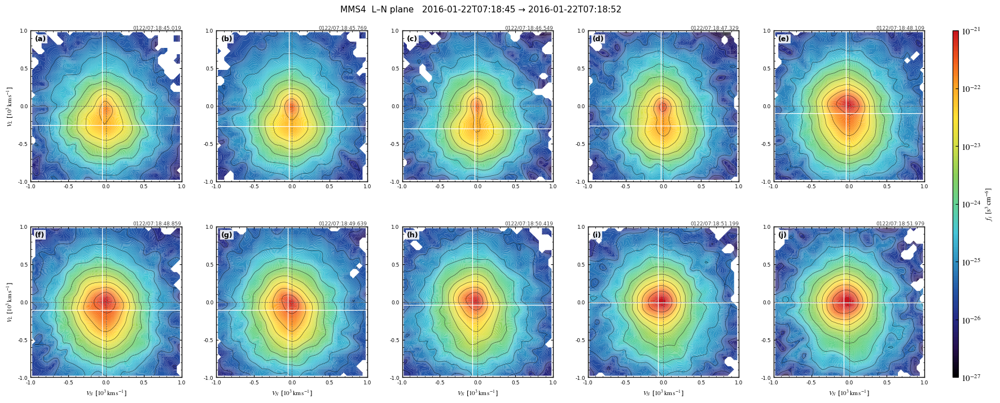

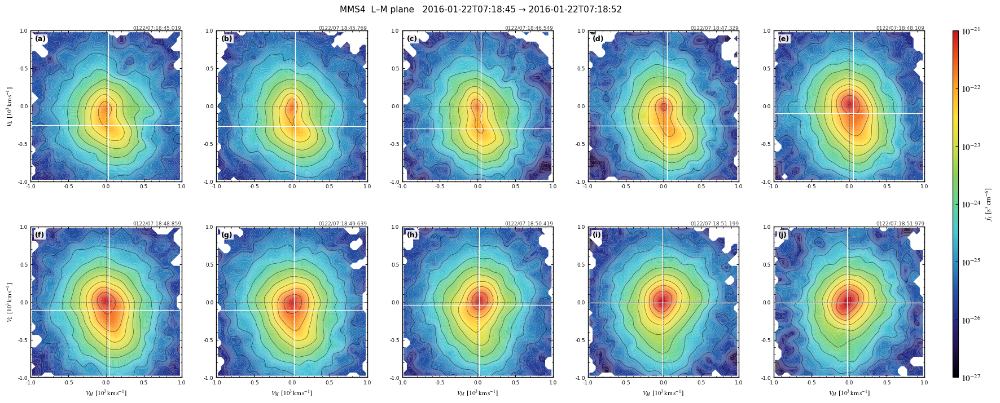

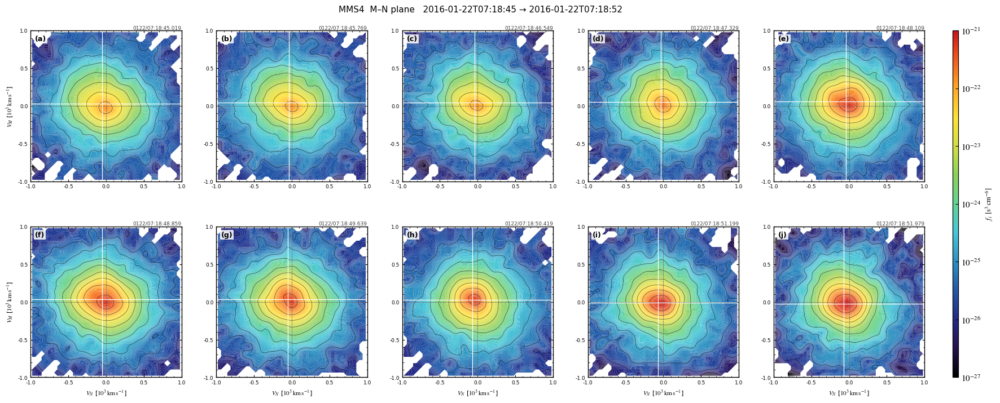

In [175]:
# ============================================================
# 10 evenly-spaced cuts between t1 and t2  – one figure per plane
# ============================================================
def build_n_vdf_selection(vidatasets_interp, sc, t1, t2, n_panels=10):
    """Return n_panels evenly-spaced DIS indices between t1 and t2."""
    vds = vidatasets_interp[sc]
    t1 = np.datetime64(t1, "ns")
    t2 = np.datetime64(t2, "ns")

    times = vds.time.values.astype("datetime64[ns]")
    mask = (times >= t1) & (times <= t2)
    available = times[mask]
    available_idx = np.where(mask)[0]

    if available.size < n_panels:
        raise ValueError(
            f"Only {available.size} DIS samples in [t1, t2]; need ≥ {n_panels}."
        )

    sel = np.linspace(0, available.size - 1, n_panels, dtype=int)
    sel = np.unique(sel)
    while sel.size < n_panels:
        extra = np.setdiff1d(np.arange(available.size), sel)
        sel = np.sort(np.append(sel, extra[:n_panels - sel.size]))

    return {
        "actual_times": available[sel],
        "indices": available_idx[sel],
        "location_labels": [f"cut {i+1}" for i in range(n_panels)],
    }


def plot_10_one_plane(
    vidatasets_interp,
    hall,
    eigvec,
    sc,
    t1,
    t2,
    x_component,
    y_component,
    b_key="lmn_b",
    vi_key="lmn_vi",
    instrument_to_base=None,
    structure_speed_l=0.0,
    velocity_range=(-1000.0, 1000.0),
    bins=48,
    sigma=1.2,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
    vmin_exp=-27,
    vmax_exp=-21,
    contour_count=12,
    filled_level_count=200,
    display_upsample=1,
    cmap=PAPER_CMAP,
    nrows=2,                  # 2 rows × 5 columns
    figure_size=(18.0, 7.5),
    save_path=None,
    dpi=500,
):
    """One 2×5 figure for a single LMN plane (10 times between t1 and t2)."""
    x_component = x_component.upper()
    y_component = y_component.upper()
    n_panels = 10
    ncols = n_panels // nrows

    vds = vidatasets_interp[sc]
    b_da = hall[sc][b_key]
    vi_da = hall[sc][vi_key]

    selection = build_n_vdf_selection(
        vidatasets_interp, sc, t1, t2, n_panels=n_panels
    )

    # ---- build the 10 snapshots ---------------------------------------------
    snapshots = []
    for idx, t in zip(selection["indices"], selection["actual_times"]):
        plane = make_lmn_plane_snapshot(
            vds=vds,
            vi_da=vi_da,
            eigvec=eigvec,
            time_index=idx,
            sc=sc,
            x_component=x_component,
            y_component=y_component,
            instrument_to_base=instrument_to_base,
            structure_speed_l=structure_speed_l,
            velocity_range=velocity_range,
            bins=bins,
            sigma=sigma,
            reverse_look_direction=reverse_look_direction,
            theta_mode=theta_mode,
            ion_mass=ion_mass,
            eigvec_layout=eigvec_layout,
            instrument_matrix_layout=instrument_matrix_layout,
        )
        snapshots.append(plane)

    # ---- colour scale -------------------------------------------------------
    cmin = 10.0 ** vmin_exp
    cmax = 10.0 ** vmax_exp
    norm = LogNorm(vmin=cmin, vmax=cmax, clip=True)
    filled   = np.logspace(vmin_exp, vmax_exp, filled_level_count)
    contours = np.logspace(vmin_exp, vmax_exp, contour_count)
    cb_ticks = 10.0 ** np.arange(int(vmin_exp), int(vmax_exp) + 1)

    # ---- figure layout ------------------------------------------------------
    fig = plt.figure(figsize=figure_size, facecolor="white")
    gs = fig.add_gridspec(
        nrows=nrows,
        ncols=ncols + 1,
        width_ratios=[1.0] * ncols + [0.035],
        left=0.05, right=0.97, bottom=0.08, top=0.90,
        hspace=0.30, wspace=0.15,
    )

    axes = np.empty((nrows, ncols), dtype=object)
    for r in range(nrows):
        for c in range(ncols):
            axes[r, c] = fig.add_subplot(gs[r, c])
    cax = fig.add_subplot(gs[:, ncols])

    vel_ticks = np.arange(int(velocity_range[0]), int(velocity_range[1]) + 1, 500)
    fmt = FuncFormatter(lambda v, p: f"{v/1e3:.1f}")

     # ---- draw every panel ---------------------------------------------------
    for i, plane in enumerate(snapshots):
        r, c = divmod(i, ncols)
        ax = axes[r, c]

        xcen = 0.5 * (plane["x_edges"][:-1] + plane["x_edges"][1:])
        ycen = 0.5 * (plane["y_edges"][:-1] + plane["y_edges"][1:])
        field = plane["field"]

        if display_upsample > 1:
            valid = np.isfinite(field) & (field > 0)
            logf = np.zeros_like(field)
            logf[valid] = np.log10(field[valid])
            log_fine = zoom(logf, display_upsample, order=3, mode="nearest")
            supp = zoom(valid.astype(float), display_upsample, order=1, mode="nearest")
            field_plot = np.full_like(log_fine, np.nan)
            field_plot[supp >= 0.20] = 10 ** log_fine[supp >= 0.20]
            xp = np.linspace(xcen[0], xcen[-1], field_plot.shape[1])
            yp = np.linspace(ycen[0], ycen[-1], field_plot.shape[0])
        else:
            field_plot = field
            xp, yp = xcen, ycen

        field_plot = np.where(
            np.isfinite(field_plot),
            np.clip(field_plot, cmin, cmax),
            np.nan,
        )
        X, Y = np.meshgrid(xp, yp)

        cf = ax.contourf(
            X, Y, field_plot,
            levels=filled, norm=norm, cmap=cmap,
            extend="neither", antialiased=True,
        )

        pos = field_plot[np.isfinite(field_plot) & (field_plot > 0)]
        if pos.size:
            usable = contours[
                (contours >= np.nanmin(pos)) & (contours <= np.nanmax(pos))
            ]
            if usable.size:
                ax.contour(X, Y, field_plot, levels=usable,
                           colors="k", linewidths=0.45, alpha=0.7)

        ax.axhline(0, color="0.4", ls="--", lw=0.6)
        ax.axvline(0, color="0.4", ls="--", lw=0.6)
        ax.axhline(plane["Vi_y"], color="w", lw=0.9)
        ax.axvline(plane["Vi_x"], color="w", lw=0.9)

        ax.set_xlim(velocity_range)
        ax.set_ylim(velocity_range)
        ax.set_aspect("equal")
        ax.set_xticks(vel_ticks)
        ax.set_yticks(vel_ticks)
        ax.xaxis.set_major_formatter(fmt)
        ax.yaxis.set_major_formatter(fmt)
        ax.xaxis.set_minor_locator(MultipleLocator(100))
        ax.yaxis.set_minor_locator(MultipleLocator(100))
        ax.tick_params(axis="both", which="major", direction="in",
                       top=True, right=True, labelsize=6.5, length=3.2)
        ax.tick_params(axis="both", which="minor", direction="in",
                       top=True, right=True, length=1.8)

        if r == nrows - 1:
            ax.set_xlabel(
                rf"$V_{{{x_component}}}$ [$10^3\,\mathrm{{km\,s^{{-1}}}}$]",
                fontsize=8,
            )
        if c == 0:
            ax.set_ylabel(
                rf"$V_{{{y_component}}}$ [$10^3\,\mathrm{{km\,s^{{-1}}}}$]",
                fontsize=8,
            )

        # ----- panel letter (a)–(j) ------------------------------------------
        letter = string.ascii_lowercase[i]
        ax.text(
            0.03, 0.97, f"({letter})",
            transform=ax.transAxes,
            fontsize=9, fontweight="bold",
            va="top", ha="left",
            color="k",
            bbox=dict(boxstyle="square,pad=0.15", facecolor="white",
                      edgecolor="none", alpha=0.85),
        )

        # ----- time stamp with milliseconds ---------------------------------
        ts = np.datetime_as_string(plane["time"], unit="ms")  # e.g. 2016-01-22T07:25:12.345
        date, time = ts.split("T")
        title_str = f"{date[5:].replace('-', '')}/{time}"     # → 0122/07:25:12.345
        ax.set_title(
            title_str,
            loc="right", fontsize=6.5, pad=2, color="0.25",
        )

    # shared colourbar
    cb = fig.colorbar(cf, cax=cax, ticks=cb_ticks, extend="neither")
    cb.ax.yaxis.set_major_formatter(FuncFormatter(_paper_decade_formatter))
    cb.ax.minorticks_off()
    cb.set_label(r"$f_i$ $[\mathrm{s^3\,cm^{-6}}]$", fontsize=9)
    cb.outline.set_linewidth(0.9)

    fig.suptitle(
        f"{sc.upper()}  {y_component}–{x_component} plane   "
        f"{np.datetime_as_string(np.datetime64(t1), unit='s')} → "
        f"{np.datetime_as_string(np.datetime64(t2), unit='s')}",
        fontsize=11, y=0.96,
    )

    if save_path is not None:
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight",
                    pad_inches=0.02, facecolor="white")
    plt.show()
    return fig, axes, snapshots, selection
sc = "mms4"
common = dict(
    vidatasets_interp=vidatasets_interp,
    hall=hall,
    eigvec=eigvec,
    sc=sc,
    t1=t1,
    t2=t2,
    structure_speed_l=0.0,
    velocity_range=(-1000.0, 1000.0),
    bins=48,
    sigma=1.2,
    display_upsample=1,
    vmin_exp=-27,
    vmax_exp=-21,
    nrows=2,                 # 2×5 layout
    figure_size=(18.0, 7.5),
    dpi=600,
)

# 1. N–L plane
fig_nl, _, _, _ = plot_10_one_plane(
    **common,
    x_component="N",
    y_component="L",
    save_path=os.path.join(output_folder, f"{taistarttime}_{sc}_10_NL.png"),
)

# 2. M–L plane
fig_ml, _, _, _ = plot_10_one_plane(
    **common,
    x_component="M",
    y_component="L",
    save_path=os.path.join(output_folder, f"{taistarttime}_{sc}_10_ML.png"),
)

# 3. N–M plane
fig_nm, _, _, _ = plot_10_one_plane(
    **common,
    x_component="N",
    y_component="M",
    save_path=os.path.join(output_folder, f"{taistarttime}_{sc}_10_NM.png"),
)

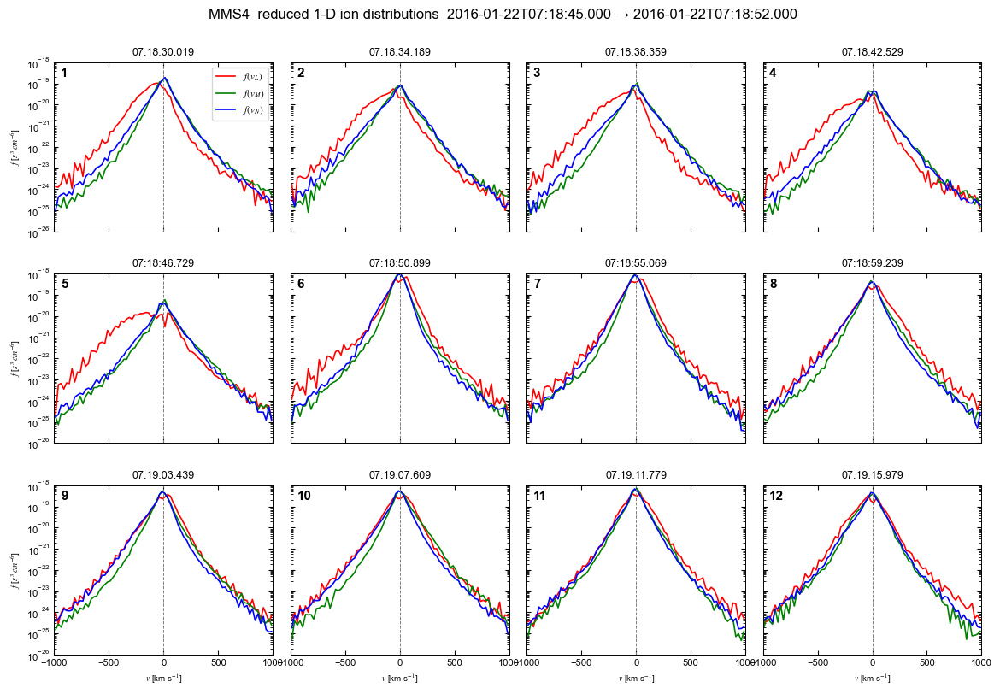

In [183]:
# ==============================================================================
# Plot: 3 rows × 4 columns  (each panel = one time cut with all three components)
# ==============================================================================
n_rows, n_cols = 3, 4
fig, axs = plt.subplots(
    n_rows, n_cols,
    figsize=(14, 9),
    sharex=True, sharey=True,
    gridspec_kw={"wspace": 0.08, "hspace": 0.25},
)
axs = axs.ravel()
ymin, ymax = 1e-26, 1e-18

for i, (t, fL, fM, fN) in enumerate(zip(times_cut, fL_cuts, fM_cuts, fN_cuts)):
    ax = axs[i]
    ax.semilogy(v_centres, fL, "r", lw=1.2, label=r"$f(v_L)$")
    ax.semilogy(v_centres, fM, "g", lw=1.2, label=r"$f(v_M)$")
    ax.semilogy(v_centres, fN, "b", lw=1.2, label=r"$f(v_N)$")
    ax.axvline(0, c="0.5", ls="--", lw=0.7)
    ax.set_ylim(ymin, ymax)
    ax.set_xlim(v_range)
    ax.set_title(np.datetime_as_string(t, unit="ms").split("T")[1], fontsize=9)
    ax.tick_params(direction="in", top=True, right=True, labelsize=8)

    # --- panel number (1–12) in the upper-left corner ---
    ax.text(
        0.03, 0.97, str(i + 1),
        transform=ax.transAxes,
        fontsize=11, fontweight="bold",
        va="top", ha="left",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8),
    )

    if i == 0:
        ax.legend(fontsize=8, loc="upper right")

# axis labels only on the outer edges
for i, ax in enumerate(axs):
    if i >= n_cuts - n_cols:          # bottom row
        ax.set_xlabel(r"$v$ [km s$^{-1}$]")
    if i % n_cols == 0:               # left column
        ax.set_ylabel(r"$f$ [$s^3\,cm^{-6}$]")

# hide any unused axes (if n_cuts < 12)
for i in range(n_cuts, n_rows * n_cols):
    axs[i].axis("off")

fig.suptitle(
    f"{sc.upper()}  reduced 1-D ion distributions  {t_start} → {t_end}",
    fontsize=12, y=0.95,
)
fig.savefig(
    os.path.join(output_folder, f"{taistarttime}_{sc}_reduced_1d_12cuts.png"),
    dpi=300, bbox_inches="tight",
)
plt.show()

25-Oct-26 18:55:10: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\1242959574.py:1801: RuntimeWarning: instrument_to_base=None. Verify that the FPI sky-map angles are in the same input frame used by eigvec.
  plot_five_vl_marginal_robustness(




Five selected DIS distributions

1.                     requested=2016-01-22T07:18:46.806898000  actual=2016-01-22T07:18:46.819564000  delta=+12.7 ms
2.                     requested=2016-01-22T07:18:47.106898000  actual=2016-01-22T07:18:47.119564000  delta=+12.7 ms
3. B_M minimum         requested=2016-01-22T07:18:48.559564000  actual=2016-01-22T07:18:48.559564000  delta=+0.0 ms
4.                     requested=2016-01-22T07:18:50.125472000  actual=2016-01-22T07:18:50.119564000  delta=-5.9 ms
5.                     requested=2016-01-22T07:18:50.425472000  actual=2016-01-22T07:18:50.419564000  delta=-5.9 ms


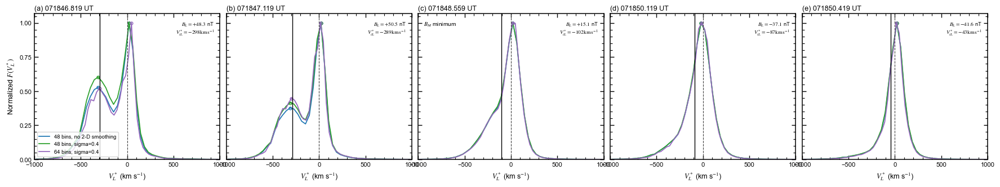

25-Oct-26 18:55:12: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\1242959574.py:1865: RuntimeWarning: instrument_to_base=None. Verify that the FPI sky-map angles are in the same input frame used by eigvec.
  plot_five_field_aligned_vdfs(




Candidate-peak summary
These are algorithmic candidates, not automatically physical beams.

 panel      location             configuration  candidate_peak_count candidate_peak_velocities_km_s
     1               48 bins, no 2-D smoothing                     2                       -313, 21
     1                      48 bins, sigma=0.4                     2                       -313, 21
     1                      64 bins, sigma=0.4                     2                       -297, 47
     2               48 bins, no 2-D smoothing                     2                       -313, 21
     2                      48 bins, sigma=0.4                     2                       -313, 21
     2                      64 bins, sigma=0.4                     2                       -297, 16
     3 $B_M$ minimum 48 bins, no 2-D smoothing                     1                             21
     3 $B_M$ minimum        48 bins, sigma=0.4                     1                             21
     3 

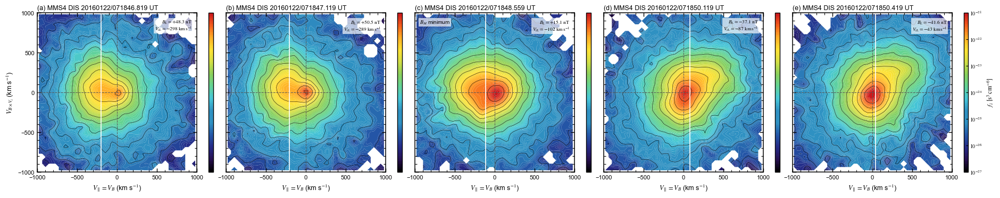

In [191]:

import os
import string
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter, gaussian_filter1d, zoom
from scipy.signal import find_peaks
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MultipleLocator


# ============================================================
# Physical constants
# ============================================================
QE = 1.602176634e-19
MP = 1.67262192595e-27


# ============================================================
# Paper-style colormap
# ============================================================
def make_paper_vdf_colormap():
    colors = [
        "black",
        "#26104f",
        "#252a86",
        "#2457a7",
        "#2f91c2",
        "#2f91c2",
        "#47c6d8",
        "#63d394",
        "#8bd05b",
        "#d3df45",
        "#ffe234",
        "#ffab26",
        "#f35b1d",
        "#c9151e",
    ]

    cmap = LinearSegmentedColormap.from_list(
        "paper_ion_vdf",
        colors,
        N=256,
    )

    cmap.set_under("black")
    cmap.set_over("#8b0000")
    cmap.set_bad("white")
    return cmap


PAPER_CMAP = make_paper_vdf_colormap()


# ============================================================
# General helpers
# ============================================================
def _to_datetime64_ns(value, name="time"):
    if hasattr(value, "values"):
        value = value.values

    array = np.asarray(value)

    if array.size != 1:
        raise ValueError(
            f"{name} must contain exactly one timestamp; "
            f"received shape {array.shape}."
        )

    return np.datetime64(array.reshape(-1)[0], "ns")


def _nearest_dis_sample(vds, requested_time):
    requested_time = _to_datetime64_ns(
        requested_time,
        name="requested_time",
    )

    available_times = vds.time.values.astype("datetime64[ns]")

    if available_times.size == 0:
        raise ValueError("The DIS dataset contains no time samples.")

    index = int(
        np.argmin(
            np.abs(available_times - requested_time)
        )
    )

    actual_time = available_times[index]

    difference_ms = float(
        (actual_time - requested_time)
        / np.timedelta64(1, "ms")
    )

    return actual_time, index, difference_ms


def _energy_to_speed_kms(energy_ev, ion_mass=MP):
    energy_ev = np.asarray(energy_ev, dtype=float)

    if np.any(energy_ev < 0):
        raise ValueError("Ion energy values must be non-negative.")

    return np.sqrt(
        2.0 * energy_ev * QE / ion_mass
    ) / 1000.0


def _matrix_at_time(matrix, snapshot_time, name="matrix"):
    if matrix is None:
        return None

    selected = matrix

    if hasattr(selected, "dims") and "time" in selected.dims:
        selected = selected.sel(
            time=snapshot_time,
            method="nearest",
        )

    values = np.asarray(
        selected.values if hasattr(selected, "values") else selected,
        dtype=float,
    ).squeeze()

    if values.shape != (3, 3):
        raise ValueError(
            f"{name} must resolve to shape (3, 3); "
            f"received {values.shape}."
        )

    if not np.all(np.isfinite(values)):
        raise ValueError(f"{name} contains non-finite values.")

    return values


def _vector_at_time(data_array, sample_time, name):
    selected = data_array.sel(
        time=sample_time,
        method="nearest",
    )

    values = np.asarray(
        selected.values,
        dtype=float,
    ).squeeze()

    if values.ndim != 1 or values.size < 3:
        raise ValueError(
            f"{name} must resolve to at least three components; "
            f"received shape {values.shape}."
        )

    vector = values[:3]

    if not np.all(np.isfinite(vector)):
        raise ValueError(
            f"{name} contains non-finite values at {sample_time}."
        )

    return vector


def _unit(vector, name="vector"):
    vector = np.asarray(vector, dtype=float).squeeze()

    if vector.shape != (3,):
        raise ValueError(
            f"{name} must have shape (3,), got {vector.shape}."
        )

    magnitude = np.linalg.norm(vector)

    if not np.isfinite(magnitude) or magnitude == 0:
        raise ValueError(f"Invalid {name}: {vector}")

    return vector / magnitude


def _paper_decade_formatter(value, position):
    if not np.isfinite(value) or value <= 0:
        return ""

    exponent = int(np.round(np.log10(value)))
    return rf"$10^{{{exponent}}}$"


# ============================================================
# Select the same five physical locations
# ============================================================
def build_five_time_selection(
    vidatasets_interp,
    bm_cross,
    sc,
    th_min,
    time_offset_ms=150,
):
    """
    Select:
        1. left of x2
        2. right of x2
        3. B_M minimum
        4. left of x3
        5. right of x3
    """
    if sc not in vidatasets_interp:
        raise KeyError(
            f"{sc!r} is absent from vidatasets_interp."
        )

    vds = vidatasets_interp[sc]
    offset = np.timedelta64(int(time_offset_ms), "ms")

    x2 = _to_datetime64_ns(
        bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[1],
        name="x2",
    )

    x3 = _to_datetime64_ns(
        bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[0],
        name="x3",
    )

    bm_minimum_time = _to_datetime64_ns(
        th_min,
        name="th_min",
    )

    requested_times = [
        x2 - offset,
        x2 + offset,
        bm_minimum_time,
        x3 - offset,
        x3 + offset,
    ]

    labels = [
        r"",
        r"",
        r"$B_M$ minimum",
        r"",
        r"",
    ]

    actual_times = []
    indices = []
    differences_ms = []

    for requested_time in requested_times:
        actual_time, index, difference_ms = _nearest_dis_sample(
            vds,
            requested_time,
        )

        actual_times.append(actual_time)
        indices.append(index)
        differences_ms.append(difference_ms)

    if len(set(indices)) != 5:
        warnings.warn(
            "Some requested locations selected the same DIS distribution. "
            "Increase time_offset_ms if five distinct distributions are needed.",
            RuntimeWarning,
            stacklevel=2,
        )

    selection = {
        "x2": x2,
        "x3": x3,
        "bm_minimum_time": bm_minimum_time,
        "requested_times": requested_times,
        "actual_times": actual_times,
        "indices": indices,
        "differences_ms": differences_ms,
        "labels": labels,
    }

    print("\nFive selected DIS distributions\n")

    for panel_number, (
        label,
        requested_time,
        actual_time,
        difference_ms,
    ) in enumerate(
        zip(
            labels,
            requested_times,
            actual_times,
            differences_ms,
        ),
        start=1,
    ):
        printable_label = (
            label
            .replace("$", "")
            .replace("\\", "")
            .replace("{", "")
            .replace("}", "")
        )

        print(
            f"{panel_number}. {printable_label:<18s}  "
            f"requested={requested_time}  "
            f"actual={actual_time}  "
            f"delta={difference_ms:+.1f} ms"
        )

    return selection


# ============================================================
# Construct the complete DIS velocity grid in LMN
# ============================================================
def make_velocity_grid_lmn(
    vds,
    time_index,
    eigvec,
    instrument_to_base=None,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
):
    snapshot_time = vds.time.isel(time=time_index)

    phi_data = vds["v1"]
    if "time" in phi_data.dims:
        phi_data = phi_data.isel(time=time_index)

    theta_data = vds["v2"]
    if "time" in theta_data.dims:
        theta_data = theta_data.isel(time=time_index)

    energy_data = vds["v3"]
    if "time" in energy_data.dims:
        energy_data = energy_data.isel(time=time_index)

    phi = np.deg2rad(
        np.asarray(phi_data.values, dtype=float)
    )
    theta = np.deg2rad(
        np.asarray(theta_data.values, dtype=float)
    )
    energy_ev = np.asarray(
        energy_data.values,
        dtype=float,
    )

    speed = _energy_to_speed_kms(
        energy_ev,
        ion_mass=ion_mass,
    )

    PHI, THETA, SPEED = np.meshgrid(
        phi,
        theta,
        speed,
        indexing="ij",
    )

    if theta_mode == "polar":
        vx = SPEED * np.sin(THETA) * np.cos(PHI)
        vy = SPEED * np.sin(THETA) * np.sin(PHI)
        vz = SPEED * np.cos(THETA)

    elif theta_mode == "elevation":
        vx = SPEED * np.cos(THETA) * np.cos(PHI)
        vy = SPEED * np.cos(THETA) * np.sin(PHI)
        vz = SPEED * np.sin(THETA)

    else:
        raise ValueError(
            "theta_mode must be 'polar' or 'elevation'."
        )

    velocity_instrument = np.stack(
        (vx, vy, vz),
        axis=-1,
    )

    if reverse_look_direction:
        velocity_instrument = -velocity_instrument

    instrument_matrix = _matrix_at_time(
        instrument_to_base,
        snapshot_time,
        name="instrument_to_base",
    )

    if instrument_matrix is None:
        velocity_base = velocity_instrument

    else:
        if instrument_matrix_layout == "rows":
            instrument_matrix = instrument_matrix.T

        elif instrument_matrix_layout != "columns":
            raise ValueError(
                "instrument_matrix_layout must be 'columns' or 'rows'."
            )

        velocity_base = np.einsum(
            "...i,ij->...j",
            velocity_instrument,
            instrument_matrix,
            optimize=True,
        )

    rotation = _matrix_at_time(
        eigvec,
        snapshot_time,
        name="eigvec",
    )

    if eigvec_layout == "rows":
        rotation = rotation.T

    elif eigvec_layout != "columns":
        raise ValueError(
            "eigvec_layout must be 'columns' or 'rows'."
        )

    velocity_lmn = np.einsum(
        "...i,ij->...j",
        velocity_base,
        rotation,
        optimize=True,
    )

    return velocity_lmn


# ============================================================
# Generic 2-D mean-PSD remapping
# ============================================================
def _mean_psd_histogram_2d(
    x_values,
    y_values,
    weights,
    bins,
    velocity_range,
):
    value_sum, x_edges, y_edges = np.histogram2d(
        x_values,
        y_values,
        bins=bins,
        range=[velocity_range, velocity_range],
        weights=weights,
    )

    sample_count, _, _ = np.histogram2d(
        x_values,
        y_values,
        bins=bins,
        range=[velocity_range, velocity_range],
    )

    field = np.full_like(
        value_sum,
        np.nan,
        dtype=float,
    )

    np.divide(
        value_sum,
        sample_count,
        out=field,
        where=sample_count > 0,
    )

    field = field.T
    field[field <= 0] = np.nan

    return field, x_edges, y_edges


def _smooth_log_field(field, sigma, support_threshold=0.12):
    if sigma is None or sigma <= 0:
        return field.copy()

    valid = np.isfinite(field) & (field > 0)

    if not np.any(valid):
        return np.full_like(field, np.nan)

    log_values = np.zeros_like(field, dtype=float)
    log_values[valid] = np.log10(field[valid])

    support = valid.astype(float)

    numerator = gaussian_filter(
        log_values * support,
        sigma=sigma,
        mode="nearest",
    )

    denominator = gaussian_filter(
        support,
        sigma=sigma,
        mode="nearest",
    )

    smoothed_log = np.full_like(
        field,
        np.nan,
        dtype=float,
    )

    supported = denominator >= support_threshold

    np.divide(
        numerator,
        denominator,
        out=smoothed_log,
        where=supported,
    )

    result = np.full_like(field, np.nan)
    result[supported] = 10.0 ** smoothed_log[supported]
    result[result <= 0] = np.nan

    return result


# ============================================================
# LN snapshot for the f(V_L*) marginal
# ============================================================
def make_ln_snapshot(
    vds,
    b_da,
    vi_da,
    eigvec,
    time_index,
    sc,
    instrument_to_base=None,
    structure_speed_l=0.0,
    velocity_range=(-1000.0, 1000.0),
    bins=48,
    sigma=0.0,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
):
    snapshot_time = vds.time.isel(time=time_index)
    dist_name = f"{sc}_dis_dist_brst"

    distribution = np.asarray(
        vds[dist_name].isel(time=time_index).values,
        dtype=float,
    )

    velocity_lmn = make_velocity_grid_lmn(
        vds=vds,
        time_index=time_index,
        eigvec=eigvec,
        instrument_to_base=instrument_to_base,
        reverse_look_direction=reverse_look_direction,
        theta_mode=theta_mode,
        ion_mass=ion_mass,
        eigvec_layout=eigvec_layout,
        instrument_matrix_layout=instrument_matrix_layout,
    )

    B_lmn = _vector_at_time(
        b_da,
        snapshot_time,
        name="lmn_b",
    )

    Vi_lmn = _vector_at_time(
        vi_da,
        snapshot_time,
        name="lmn_vi",
    )

    v_l_star = (
        velocity_lmn[..., 0]
        - float(structure_speed_l)
    )

    v_n = velocity_lmn[..., 2]

    weights = distribution.ravel()
    x_values = v_l_star.ravel()
    y_values = v_n.ravel()

    good = (
        np.isfinite(weights)
        & (weights > 0)
        & np.isfinite(x_values)
        & np.isfinite(y_values)
    )

    field, x_edges, y_edges = _mean_psd_histogram_2d(
        x_values=x_values[good],
        y_values=y_values[good],
        weights=weights[good],
        bins=bins,
        velocity_range=velocity_range,
    )

    field = _smooth_log_field(
        field,
        sigma=sigma,
    )

    return {
        "time": np.datetime64(snapshot_time.values, "ns"),
        "field": field,
        "x_edges": x_edges,
        "y_edges": y_edges,
        "B_lmn": B_lmn,
        "Vi_lmn": Vi_lmn,
        "Vi_L_star": float(
            Vi_lmn[0] - float(structure_speed_l)
        ),
        "bins": int(bins),
        "sigma": float(sigma),
    }


def normalized_vl_marginal(
    snapshot,
    profile_smoothing_bins=0.0,
):
    """
    Qualitative normalized marginal proxy:

        F(V_L*) proportional to sum over V_N of f(V_L*, V_N)

    Because the 2-D field is a mean-PSD remapping, use this to test
    peak structure, not to claim an absolutely normalized reduced VDF.
    """
    field = snapshot["field"]

    x_centers = 0.5 * (
        snapshot["x_edges"][:-1]
        + snapshot["x_edges"][1:]
    )

    profile = np.nansum(
        field,
        axis=0,
    )

    profile = np.where(
        np.isfinite(profile),
        profile,
        0.0,
    )

    if profile_smoothing_bins is not None and profile_smoothing_bins > 0:
        profile = gaussian_filter1d(
            profile,
            sigma=profile_smoothing_bins,
            mode="nearest",
        )

    maximum = np.nanmax(profile)

    if maximum > 0:
        profile = profile / maximum

    return x_centers, profile


def candidate_profile_peaks(
    velocity,
    profile,
    minimum_prominence=0.08,
    minimum_separation_kms=150.0,
):
    """
    Find candidate peaks in a normalized profile.

    These are candidates only; inspect the original VDF before calling
    any feature a physical beam.
    """
    velocity = np.asarray(velocity, dtype=float)
    profile = np.asarray(profile, dtype=float)

    if velocity.size < 3 or profile.size != velocity.size:
        return np.array([]), np.array([]), {}

    spacing = float(
        np.nanmedian(
            np.abs(np.diff(velocity))
        )
    )

    distance_bins = max(
        1,
        int(
            np.ceil(
                minimum_separation_kms / spacing
            )
        ),
    )

    peak_indices, properties = find_peaks(
        profile,
        prominence=minimum_prominence,
        distance=distance_bins,
    )

    return (
        peak_indices,
        velocity[peak_indices],
        properties,
    )


# ============================================================
# Diagnostic 1: five f(V_L*) marginals with robustness tests
# ============================================================
def plot_five_vl_marginal_robustness(
    vidatasets_interp,
    hall,
    eigvec,
    bm_cross,
    sc,
    th_min,
    time_offset_ms=150,
    b_key="lmn_b",
    vi_key="lmn_vi",
    instrument_to_base=None,
    structure_speed_l=0.0,
    velocity_range=(-1000.0, 1000.0),
    configurations=None,
    profile_smoothing_bins=0.7,
    minimum_prominence=0.08,
    minimum_separation_kms=150.0,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
    figsize=(18.0, 3.7),
    save_path=None,
    dpi=600,
):
    """
    Overlay several binning/smoothing choices in each of five panels.

    Default curves:
        48 bins, sigma=0.0
        48 bins, sigma=0.4
        64 bins, sigma=0.4

    A physical second beam should remain as a separated peak under
    reasonable changes in both binning and smoothing.
    """
    if configurations is None:
        configurations = [
            {
                "bins": 48,
                "sigma": 0.0,
                "label": "48 bins, no 2-D smoothing",
            },
            {
                "bins": 48,
                "sigma": 0.4,
                "label": "48 bins, sigma=0.4",
            },
            {
                "bins": 64,
                "sigma": 0.4,
                "label": "64 bins, sigma=0.4",
            },
        ]

    selection = build_five_time_selection(
        vidatasets_interp=vidatasets_interp,
        bm_cross=bm_cross,
        sc=sc,
        th_min=th_min,
        time_offset_ms=time_offset_ms,
    )

    vds = vidatasets_interp[sc]
    b_da = hall[sc][b_key]
    vi_da = hall[sc][vi_key]

    if instrument_to_base is None:
        warnings.warn(
            "instrument_to_base=None. Verify that the FPI sky-map angles "
            "are in the same input frame used by eigvec.",
            RuntimeWarning,
            stacklevel=2,
        )

    fig, axes = plt.subplots(
        1,
        5,
        figsize=figsize,
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    records = []
    stored_profiles = []

    for panel_index, (
        time_index,
        actual_time,
        location_label,
    ) in enumerate(
        zip(
            selection["indices"],
            selection["actual_times"],
            selection["labels"],
        )
    ):
        ax = axes[0, panel_index]
        panel_profiles = []

        for configuration_index, configuration in enumerate(configurations):
            snapshot = make_ln_snapshot(
                vds=vds,
                b_da=b_da,
                vi_da=vi_da,
                eigvec=eigvec,
                time_index=time_index,
                sc=sc,
                instrument_to_base=instrument_to_base,
                structure_speed_l=structure_speed_l,
                velocity_range=velocity_range,
                bins=configuration["bins"],
                sigma=configuration["sigma"],
                reverse_look_direction=reverse_look_direction,
                theta_mode=theta_mode,
                ion_mass=ion_mass,
                eigvec_layout=eigvec_layout,
                instrument_matrix_layout=instrument_matrix_layout,
            )

            velocity, profile = normalized_vl_marginal(
                snapshot,
                profile_smoothing_bins=profile_smoothing_bins,
            )

            peak_indices, peak_velocities, properties = (
                candidate_profile_peaks(
                    velocity=velocity,
                    profile=profile,
                    minimum_prominence=minimum_prominence,
                    minimum_separation_kms=minimum_separation_kms,
                )
            )

            line, = ax.plot(
                velocity,
                profile,
                linewidth=1.25,
                label=configuration["label"],
            )

            if peak_velocities.size:
                ax.plot(
                    peak_velocities,
                    profile[peak_indices],
                    linestyle="none",
                    marker="o",
                    markersize=3.5,
                    markerfacecolor="none",
                    markeredgecolor=line.get_color(),
                )

            records.append(
                {
                    "panel": panel_index + 1,
                    "location": location_label,
                    "time": actual_time,
                    "configuration": configuration["label"],
                    "B_L_nT": snapshot["B_lmn"][0],
                    "Vi_L_star_km_s": snapshot["Vi_L_star"],
                    "candidate_peak_count": int(peak_velocities.size),
                    "candidate_peak_velocities_km_s": (
                        ", ".join(
                            f"{value:.0f}"
                            for value in peak_velocities
                        )
                    ),
                }
            )

            panel_profiles.append(
                {
                    "configuration": configuration,
                    "snapshot": snapshot,
                    "velocity": velocity,
                    "profile": profile,
                    "peak_velocities": peak_velocities,
                }
            )

        stored_profiles.append(panel_profiles)

        reference_snapshot = panel_profiles[0]["snapshot"]

        ax.axvline(
            0.0,
            color="0.25",
            linestyle="--",
            linewidth=0.8,
        )

        ax.axvline(
            reference_snapshot["Vi_L_star"],
            color="white",
            linewidth=3.0,
            zorder=1,
        )

        ax.axvline(
            reference_snapshot["Vi_L_star"],
            color="black",
            linewidth=1.0,
            zorder=2,
        )

        ax.set_xlim(velocity_range)
        ax.set_ylim(0.0, 1.07)

        ax.xaxis.set_major_locator(
            MultipleLocator(500)
        )
        ax.xaxis.set_minor_locator(
            MultipleLocator(100)
        )
        ax.yaxis.set_major_locator(
            MultipleLocator(0.25)
        )
        ax.yaxis.set_minor_locator(
            MultipleLocator(0.05)
        )

        ax.tick_params(
            which="major",
            direction="in",
            top=True,
            right=True,
            length=5,
            width=1.0,
            labelsize=8,
        )

        ax.tick_params(
            which="minor",
            direction="in",
            top=True,
            right=True,
            length=2.8,
            width=0.8,
        )

        for spine in ax.spines.values():
            spine.set_linewidth(1.1)

        timestamp = np.datetime_as_string(
            actual_time,
            unit="ms",
        )

        compact_time = (
            timestamp
            .split("T")[-1]
            .replace(":", "")
        )

        panel_letter = string.ascii_lowercase[panel_index]

        ax.set_title(
            f"({panel_letter}) {compact_time} UT",
            loc="left",
            fontsize=9,
            pad=4,
        )

        ax.set_xlabel(
            r"$V_L^*$ (km s$^{-1}$)",
            fontsize=9,
        )

        if panel_index == 0:
            ax.set_ylabel(
                r"Normalized $F(V_L^*)$",
                fontsize=9,
            )
        else:
            ax.tick_params(
                axis="y",
                labelleft=False,
            )

        ax.text(
            0.03,
            0.95,
            location_label,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7.3,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.70,
                "pad": 1.3,
            },
        )

        ax.text(
            0.97,
            0.95,
            (
                rf"$B_L={reference_snapshot['B_lmn'][0]:+.1f}$ nT"
                "\n"
                rf"$V_{{iL}}^*={reference_snapshot['Vi_L_star']:+.0f}\mathrm{{km\,s^{{-1}}}}$"
            ),
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=6.8,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.70,
                "pad": 1.3,
            },
        )

    axes[0, 0].legend(
        loc="lower left",
        fontsize=6.8,
        frameon=True,
    )

    fig.subplots_adjust(
        left=0.055,
        right=0.995,
        bottom=0.18,
        top=0.88,
        wspace=0.035,
    )

    if save_path is not None:
        os.makedirs(
            os.path.dirname(
                os.path.abspath(save_path)
            ),
            exist_ok=True,
        )

        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()

    diagnostics = pd.DataFrame(records)

    print(
        "\nCandidate-peak summary\n"
        "These are algorithmic candidates, not automatically physical beams.\n"
    )
    print(
        diagnostics[
            [
                "panel",
                "location",
                "configuration",
                "candidate_peak_count",
                "candidate_peak_velocities_km_s",
            ]
        ].to_string(index=False)
    )

    return fig, axes, stored_profiles, diagnostics, selection


# ============================================================
# Field-aligned basis and snapshot
# ============================================================
def field_aligned_basis(B_lmn, Vi_lmn):
    """
    e_parallel = B / |B|
    e_BxVi     = (B x Vi) / |B x Vi|
    """
    b_hat = _unit(
        B_lmn,
        name="B_lmn",
    )

    Vi_lmn = np.asarray(
        Vi_lmn,
        dtype=float,
    ).squeeze()

    bxvi = np.cross(
        b_hat,
        Vi_lmn,
    )

    if (
        not np.all(np.isfinite(bxvi))
        or np.linalg.norm(bxvi) < 1e-12
    ):
        coordinate_axes = np.eye(3)
        trial = coordinate_axes[
            np.argmin(
                np.abs(coordinate_axes @ b_hat)
            )
        ]
        bxvi = np.cross(
            b_hat,
            trial,
        )

    e_bxvi = _unit(
        bxvi,
        name="B cross Vi",
    )

    return b_hat, e_bxvi


def make_field_aligned_snapshot(
    vds,
    b_da,
    vi_da,
    eigvec,
    time_index,
    sc,
    instrument_to_base=None,
    velocity_range=(-1000.0, 1000.0),
    bins=64,
    sigma=0.35,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
):
    snapshot_time = vds.time.isel(time=time_index)
    dist_name = f"{sc}_dis_dist_brst"

    distribution = np.asarray(
        vds[dist_name].isel(time=time_index).values,
        dtype=float,
    )

    B_lmn = _vector_at_time(
        b_da,
        snapshot_time,
        name="lmn_b",
    )

    Vi_lmn = _vector_at_time(
        vi_da,
        snapshot_time,
        name="lmn_vi",
    )

    velocity_lmn = make_velocity_grid_lmn(
        vds=vds,
        time_index=time_index,
        eigvec=eigvec,
        instrument_to_base=instrument_to_base,
        reverse_look_direction=reverse_look_direction,
        theta_mode=theta_mode,
        ion_mass=ion_mass,
        eigvec_layout=eigvec_layout,
        instrument_matrix_layout=instrument_matrix_layout,
    )

    b_hat, e_bxvi = field_aligned_basis(
        B_lmn,
        Vi_lmn,
    )

    v_parallel = np.tensordot(
        velocity_lmn,
        b_hat,
        axes=([-1], [0]),
    )

    v_bxvi = np.tensordot(
        velocity_lmn,
        e_bxvi,
        axes=([-1], [0]),
    )

    weights = distribution.ravel()
    x_values = v_parallel.ravel()
    y_values = v_bxvi.ravel()

    good = (
        np.isfinite(weights)
        & (weights > 0)
        & np.isfinite(x_values)
        & np.isfinite(y_values)
    )

    field, x_edges, y_edges = _mean_psd_histogram_2d(
        x_values=x_values[good],
        y_values=y_values[good],
        weights=weights[good],
        bins=bins,
        velocity_range=velocity_range,
    )

    field = _smooth_log_field(
        field,
        sigma=sigma,
    )

    weights_good = weights[good]
    x_good = x_values[good]
    y_good = y_values[good]

    weight_sum = np.sum(weights_good)

    if weight_sum > 0:
        parallel_centroid = float(
            np.sum(weights_good * x_good)
            / weight_sum
        )
        bxvi_centroid = float(
            np.sum(weights_good * y_good)
            / weight_sum
        )
    else:
        parallel_centroid = np.nan
        bxvi_centroid = np.nan

    Vi_parallel = float(
        np.dot(
            Vi_lmn,
            b_hat,
        )
    )

    return {
        "time": np.datetime64(snapshot_time.values, "ns"),
        "field": field,
        "x_edges": x_edges,
        "y_edges": y_edges,
        "B_lmn": B_lmn,
        "Vi_lmn": Vi_lmn,
        "Vi_parallel": Vi_parallel,
        "parallel_centroid": parallel_centroid,
        "bxvi_centroid": bxvi_centroid,
    }


# ============================================================
# Diagnostic 2: five V_parallel - V_(B x Vi) distributions
# ============================================================
def plot_five_field_aligned_vdfs(
    vidatasets_interp,
    hall,
    eigvec,
    bm_cross,
    sc,
    th_min,
    time_offset_ms=150,
    b_key="lmn_b",
    vi_key="lmn_vi",
    instrument_to_base=None,
    velocity_range=(-1000.0, 1000.0),
    bins=64,
    sigma=0.35,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
    vmin_exp=-27,
    vmax_exp=-21,
    contour_count=15,
    filled_level_count=100,
    display_upsample=1,
    cmap=PAPER_CMAP,
    figure_size=(18.8, 4.35),
    save_path=None,
    dpi=600,
):
    """
    Plot:
        x = V_parallel = V_B
        y = V_(B x Vi)

    at the same five selected times.
    """
    selection = build_five_time_selection(
        vidatasets_interp=vidatasets_interp,
        bm_cross=bm_cross,
        sc=sc,
        th_min=th_min,
        time_offset_ms=time_offset_ms,
    )

    vds = vidatasets_interp[sc]
    b_da = hall[sc][b_key]
    vi_da = hall[sc][vi_key]

    if instrument_to_base is None:
        warnings.warn(
            "instrument_to_base=None. Verify that the FPI sky-map angles "
            "are in the same input frame used by eigvec.",
            RuntimeWarning,
            stacklevel=2,
        )

    snapshots = [
        make_field_aligned_snapshot(
            vds=vds,
            b_da=b_da,
            vi_da=vi_da,
            eigvec=eigvec,
            time_index=index,
            sc=sc,
            instrument_to_base=instrument_to_base,
            velocity_range=velocity_range,
            bins=bins,
            sigma=sigma,
            reverse_look_direction=reverse_look_direction,
            theta_mode=theta_mode,
            ion_mass=ion_mass,
            eigvec_layout=eigvec_layout,
            instrument_matrix_layout=instrument_matrix_layout,
        )
        for index in selection["indices"]
    ]

    color_minimum = 10.0 ** vmin_exp
    color_maximum = 10.0 ** vmax_exp

    norm = LogNorm(
        vmin=color_minimum,
        vmax=color_maximum,
        clip=True,
    )

    filled_levels = np.logspace(
        vmin_exp,
        vmax_exp,
        filled_level_count,
    )

    contour_levels = np.logspace(
        vmin_exp,
        vmax_exp,
        contour_count,
    )

    colorbar_ticks = 10.0 ** np.arange(
        int(vmin_exp),
        int(vmax_exp) + 1,
        dtype=float,
    )

    fig = plt.figure(
        figsize=figure_size,
        facecolor="white",
    )

    outer_grid = fig.add_gridspec(
        1,
        5,
        left=0.050,
        right=0.992,
        bottom=0.19,
        top=0.88,
        wspace=0.010,
    )

    axes = np.empty(
        (1, 5),
        dtype=object,
    )

    colorbar_axes = []
    first_axis = None

    for layout_index in range(5):
        panel_grid = outer_grid[
            0,
            layout_index,
        ].subgridspec(
            1,
            2,
            width_ratios=[1.0, 0.025],
            wspace=0.010,
        )

        if first_axis is None:
            panel_axis = fig.add_subplot(
                panel_grid[0, 0]
            )
            first_axis = panel_axis

        else:
            panel_axis = fig.add_subplot(
                panel_grid[0, 0],
                sharex=first_axis,
                sharey=first_axis,
            )

        axes[0, layout_index] = panel_axis
        colorbar_axes.append(
            fig.add_subplot(
                panel_grid[0, 1]
            )
        )

    for panel_index, snapshot in enumerate(snapshots):
        ax = axes[0, panel_index]

        x_centers = 0.5 * (
            snapshot["x_edges"][:-1]
            + snapshot["x_edges"][1:]
        )

        y_centers = 0.5 * (
            snapshot["y_edges"][:-1]
            + snapshot["y_edges"][1:]
        )

        field_native = snapshot["field"]

        if display_upsample is not None and display_upsample > 1:
            valid = (
                np.isfinite(field_native)
                & (field_native > 0)
            )

            log_native = np.zeros_like(
                field_native,
                dtype=float,
            )
            log_native[valid] = np.log10(
                field_native[valid]
            )

            support_native = valid.astype(float)

            log_fine = zoom(
                log_native,
                zoom=display_upsample,
                order=3,
                mode="nearest",
            )

            support_fine = zoom(
                support_native,
                zoom=display_upsample,
                order=1,
                mode="nearest",
            )

            field_plot = np.full_like(
                log_fine,
                np.nan,
            )

            supported = support_fine >= 0.20

            field_plot[supported] = (
                10.0 ** log_fine[supported]
            )

            x_plot = np.linspace(
                x_centers[0],
                x_centers[-1],
                field_plot.shape[1],
            )

            y_plot = np.linspace(
                y_centers[0],
                y_centers[-1],
                field_plot.shape[0],
            )

        else:
            field_plot = field_native
            x_plot = x_centers
            y_plot = y_centers

        field_plot = np.where(
            np.isfinite(field_plot),
            np.clip(
                field_plot,
                color_minimum,
                color_maximum,
            ),
            np.nan,
        )

        X, Y = np.meshgrid(
            x_plot,
            y_plot,
        )

        filled_contours = ax.contourf(
            X,
            Y,
            field_plot,
            levels=filled_levels,
            norm=norm,
            cmap=cmap,
            extend="neither",
            antialiased=True,
        )

        positive = field_plot[
            np.isfinite(field_plot)
            & (field_plot > 0)
        ]

        if positive.size:
            usable = contour_levels[
                (contour_levels >= np.nanmin(positive))
                & (contour_levels <= np.nanmax(positive))
            ]

            if usable.size:
                ax.contour(
                    X,
                    Y,
                    field_plot,
                    levels=usable,
                    colors="black",
                    linewidths=0.55,
                    alpha=0.70,
                )

        ax.axhline(
            0.0,
            color="0.35",
            linestyle="--",
            linewidth=0.75,
        )

        ax.axvline(
            0.0,
            color="0.35",
            linestyle="--",
            linewidth=0.75,
        )

        # White vertical line: ion bulk velocity parallel to B.
        ax.axvline(
            snapshot["Vi_parallel"],
            color="white",
            linewidth=1.2,
            label=r"$V_{i\parallel}$",
        )

        ax.set_xlim(velocity_range)
        ax.set_ylim(velocity_range)
        ax.set_aspect("equal")

        ax.xaxis.set_major_locator(
            MultipleLocator(500)
        )
        ax.yaxis.set_major_locator(
            MultipleLocator(500)
        )
        ax.xaxis.set_minor_locator(
            MultipleLocator(100)
        )
        ax.yaxis.set_minor_locator(
            MultipleLocator(100)
        )

        ax.tick_params(
            which="major",
            direction="in",
            top=True,
            right=True,
            length=5,
            width=1.0,
            labelsize=8,
        )

        ax.tick_params(
            which="minor",
            direction="in",
            top=True,
            right=True,
            length=2.8,
            width=0.8,
        )

        for spine in ax.spines.values():
            spine.set_linewidth(1.1)

        timestamp = np.datetime_as_string(
            snapshot["time"],
            unit="ms",
        )

        compact_date = (
            timestamp
            .split("T")[0]
            .replace("-", "")
        )

        compact_time = (
            timestamp
            .split("T")[1]
            .replace(":", "")
        )

        panel_letter = string.ascii_lowercase[
            panel_index
        ]

        ax.set_title(
            f"({panel_letter}) {sc.upper()} DIS "
            f"{compact_date}/{compact_time} UT",
            loc="left",
            fontsize=9,
            pad=4,
        )

        ax.set_xlabel(
            r"$V_{\parallel}=V_B$ (km s$^{-1}$)",
            fontsize=9,
        )

        if panel_index == 0:
            ax.set_ylabel(
                r"$V_{B\times V_i}$ (km s$^{-1}$)",
                fontsize=9,
            )
        else:
            ax.tick_params(
                axis="y",
                labelleft=False,
            )

        ax.text(
            0.03,
            0.96,
            selection["labels"][panel_index],
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7.2,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.68,
                "pad": 1.3,
            },
        )

        ax.text(
            0.97,
            0.96,
            (
                rf"$B_L={snapshot['B_lmn'][0]:+.1f}\ \mathrm{{nT}}$"
                "\n"
                rf"$V_{{iL}}={snapshot['Vi_lmn'][0]:+.0f}\ "
                rf"\mathrm{{km\,s^{{-1}}}}$"
            ),
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=6.8,
            linespacing=1.05,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.68,
                "pad": 1.3,
            },
            zorder=40,
        )

        colorbar = fig.colorbar(
            filled_contours,
            cax=colorbar_axes[panel_index],
            ticks=colorbar_ticks,
            extend="neither",
        )

        colorbar.ax.yaxis.set_major_formatter(
            FuncFormatter(
                _paper_decade_formatter
            )
        )

        colorbar.ax.minorticks_off()
        colorbar.outline.set_linewidth(1.0)

        if panel_index == len(snapshots) - 1:
            colorbar.ax.tick_params(
                which="major",
                direction="in",
                right=True,
                labelright=True,
                labelsize=7.2,
                length=3,
                width=0.8,
                pad=2,
            )

            colorbar.set_label(
                r"$f_i$ $[\mathrm{s^3\,cm^{-6}}]$",
                fontsize=8.5,
                labelpad=4,
            )

        else:
            colorbar.set_ticks([])
            colorbar.ax.set_yticks([])
            colorbar.ax.set_yticklabels([])
            colorbar.ax.tick_params(
                which="both",
                left=False,
                right=False,
                labelleft=False,
                labelright=False,
                length=0,
            )
            colorbar.set_label("")

    if save_path is not None:
        os.makedirs(
            os.path.dirname(
                os.path.abspath(save_path)
            ),
            exist_ok=True,
        )

        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()

    diagnostics = pd.DataFrame(
        {
            "time": [
                snapshot["time"]
                for snapshot in snapshots
            ],
            "location": selection["labels"],
            "B_L_nT": [
                snapshot["B_lmn"][0]
                for snapshot in snapshots
            ],
            "Vi_L_km_s": [
                snapshot["Vi_lmn"][0]
                for snapshot in snapshots
            ],
            "Vi_parallel_km_s": [
                snapshot["Vi_parallel"]
                for snapshot in snapshots
            ],
            "VDF_parallel_centroid_km_s": [
                snapshot["parallel_centroid"]
                for snapshot in snapshots
            ],
        }
    )

    return fig, axes, snapshots, diagnostics, selection


# ============================================================
# READY-TO-RUN EXAMPLES
# ============================================================
sc = "mms4"

# ------------------------------------------------------------
# 1. Robustness-tested normalized f(V_L*) marginals
# ------------------------------------------------------------
fig_marginal, axes_marginal, profiles_marginal, diagnostics_marginal, selection_marginal = (
    plot_five_vl_marginal_robustness(
        vidatasets_interp=vidatasets_interp,
        hall=hall,
        eigvec=eigvec,
        bm_cross=bm_cross,
        sc=sc,
        th_min=th_min,

        time_offset_ms=150,

        b_key="lmn_b",
        vi_key="lmn_vi",

        instrument_to_base=None,
        structure_speed_l=0.0,

        velocity_range=(-1000.0, 1000.0),

        configurations=[
            {
                "bins": 48,
                "sigma": 0.0,
                "label": "48 bins, no 2-D smoothing",
            },
            {
                "bins": 48,
                "sigma": 0.4,
                "label": "48 bins, sigma=0.4",
            },
            {
                "bins": 64,
                "sigma": 0.4,
                "label": "64 bins, sigma=0.4",
            },
        ],

        profile_smoothing_bins=0.7,

        # Peak candidates must have at least 8% prominence and be
        # separated by at least 150 km/s.
        minimum_prominence=0.08,
        minimum_separation_kms=150.0,

        reverse_look_direction=True,
        theta_mode="polar",
        eigvec_layout="columns",
        instrument_matrix_layout="columns",

        figsize=(18.0, 3.7),

        save_path=os.path.join(
            output_folder,
            f"{taistarttime}_{sc}_"
            "five_normalized_VL_marginals_robustness.png",
        ),
        dpi=600,
    )
)


# ------------------------------------------------------------
# 2. Five V_parallel - V_(B x Vi) distributions
# ------------------------------------------------------------
fig_parallel, axes_parallel, snapshots_parallel, diagnostics_parallel, selection_parallel = (
    plot_five_field_aligned_vdfs(
        vidatasets_interp=vidatasets_interp,
        hall=hall,
        eigvec=eigvec,
        bm_cross=bm_cross,
        sc=sc,
        th_min=th_min,

        time_offset_ms=150,

        b_key="lmn_b",
        vi_key="lmn_vi",

        instrument_to_base=None,

        velocity_range=(-1000.0, 1000.0),

        bins=48,
        sigma=0.9,
        display_upsample=1,

        reverse_look_direction=True,
        theta_mode="polar",
        eigvec_layout="columns",
        instrument_matrix_layout="columns",

        vmin_exp=-27,
        vmax_exp=-21,

        contour_count=15,
        filled_level_count=100,

        cmap=PAPER_CMAP,
        figure_size=(18.8, 4.35),

        save_path=os.path.join(
            output_folder,
            f"{taistarttime}_{sc}_"
            "five_Vparallel_VBxVi_x2_Bmmin_x3.png",
        ),
        dpi=600,
    )
)


# Optional: save diagnostic tables
#
# diagnostics_marginal.to_csv(
#     os.path.join(
#         output_folder,
#         f"{taistarttime}_{sc}_VL_marginal_peak_candidates.csv",
#     ),
#     index=False,
# )
#
# diagnostics_parallel.to_csv(
#     os.path.join(
#         output_folder,
#         f"{taistAarttime}_{sc}_field_aligned_VDF_diagnostics.csv",
#     ),
#     index=False,
# )


In [187]:
from scipy.signal import find_peaks

def has_peaks(f, v, prominence_frac=0.15, min_height=None):
    """Return True if at least one significant peak exists away from v≈0."""
    f = np.asarray(f)
    if min_height is None:
        min_height = np.nanmax(f) * 0.05   # ignore very low-level noise
    peaks, props = find_peaks(f, height=min_height,
                              prominence=np.nanmax(f)*prominence_frac)
    # discard the central peak near zero if it is the only one
    peaks = peaks[np.abs(v[peaks]) > 50]   # km/s threshold
    return len(peaks) > 0, peaks

# example usage on the whole interval
for comp, data in [("L", red_ds.f_L), ("M", red_ds.f_M), ("N", red_ds.f_N)]:
    n_peaked = 0
    for it in range(len(red_ds.time)):
        peaked, _ = has_peaks(data.isel(time=it).values, red_ds.v.values)
        if peaked:
            n_peaked += 1
    print(f"{comp}: {n_peaked}/{len(red_ds.time)} times show significant off-zero peaks")

L: 40/150 times show significant off-zero peaks
M: 0/150 times show significant off-zero peaks
N: 3/150 times show significant off-zero peaks


In [178]:
# ============================================================
# GENERATE THE DIAGNOSTIC CSV FOR GROK
# ============================================================
import os
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- 1. the classification function (same as before) ----------
def classify_reduced_profile(
    velocity,
    normalized_profile,
    smoothing_sigma_bins=0.7,
    minimum_prominence=0.08,
    minimum_secondary_height=0.10,
    minimum_separation_kms=150.0,
    maximum_valley_fraction=0.85,
):
    velocity = np.asarray(velocity, dtype=float)
    profile  = np.asarray(normalized_profile, dtype=float)

    if smoothing_sigma_bins > 0:
        work = gaussian_filter1d(profile, sigma=smoothing_sigma_bins, mode="nearest")
    else:
        work = profile.copy()

    if velocity.size < 3:
        return dict(classification="invalid", peak_count=0,
                    primary_velocity=np.nan, secondary_velocity=np.nan,
                    secondary_ratio=np.nan, peak_separation_kms=np.nan,
                    valley_fraction=np.nan, is_separated=False)

    dv = np.nanmedian(np.abs(np.diff(velocity)))
    min_dist = max(1, int(np.ceil(minimum_separation_kms / dv)))

    peak_idx, props = find_peaks(work, prominence=minimum_prominence, distance=min_dist)

    if peak_idx.size == 0:
        return dict(classification="single_or_flat", peak_count=0,
                    primary_velocity=np.nan, secondary_velocity=np.nan,
                    secondary_ratio=np.nan, peak_separation_kms=np.nan,
                    valley_fraction=np.nan, is_separated=False)

    heights = work[peak_idx]
    order   = np.argsort(heights)[::-1]
    peak_idx = peak_idx[order]
    heights  = heights[order]

    primary_idx    = peak_idx[0]
    primary_height = heights[0]

    if peak_idx.size == 1:
        return dict(classification="single_peaked", peak_count=1,
                    primary_velocity=float(velocity[primary_idx]),
                    secondary_velocity=np.nan, secondary_ratio=np.nan,
                    peak_separation_kms=np.nan, valley_fraction=np.nan,
                    is_separated=False)

    # look for a qualifying secondary
    best = None
    for sec_idx in peak_idx[1:]:
        sec_h   = work[sec_idx]
        ratio   = sec_h / primary_height if primary_height > 0 else np.nan
        sep     = abs(velocity[sec_idx] - velocity[primary_idx])
        left, right = min(primary_idx, sec_idx), max(primary_idx, sec_idx)
        valley  = np.nanmin(work[left:right+1]) if right-left > 1 else min(primary_height, sec_h)
        weaker  = min(primary_height, sec_h)
        vfrac   = valley / weaker if weaker > 0 else np.nan

        if (ratio >= minimum_secondary_height and
            sep   >= minimum_separation_kms and
            vfrac <= maximum_valley_fraction):
            cand = dict(idx=sec_idx, height=sec_h, ratio=ratio,
                        separation=sep, valley_fraction=vfrac)
            if best is None or cand["height"] > best["height"]:
                best = cand

    if best is None:
        return dict(classification="single_peaked_with_shoulders",
                    peak_count=int(peak_idx.size),
                    primary_velocity=float(velocity[primary_idx]),
                    secondary_velocity=np.nan, secondary_ratio=np.nan,
                    peak_separation_kms=np.nan, valley_fraction=np.nan,
                    is_separated=False)

    return dict(classification="separated_peaks",
                peak_count=int(peak_idx.size),
                primary_velocity=float(velocity[primary_idx]),
                secondary_velocity=float(velocity[best["idx"]]),
                secondary_ratio=float(best["ratio"]),
                peak_separation_kms=float(best["separation"]),
                valley_fraction=float(best["valley_fraction"]),
                is_separated=True)


# ---------- 2. main loop – uses the reduced arrays you already have ----------
# Assume you already ran the full-Hall reduction and have:
#   red_ds   (xarray Dataset with f_L, f_M, f_N, coords time & v)
#   or the three numpy arrays  fL_arr, fM_arr, fN_arr  and  v_centres, times

# ---- if you have the xarray version ----
times     = red_ds.time.values
v_centres = red_ds.v.values
fL = red_ds.f_L.values          # shape (ntime, nv)
fM = red_ds.f_M.values
fN = red_ds.f_N.values

# ---- normalise each profile to its own max (for morphology) ----
def norm(p):
    p = np.asarray(p, float)
    m = np.nanmax(p)
    return p / m if m > 0 else p

records = []
for i, t in enumerate(times):
    nL = norm(fL[i])
    nM = norm(fM[i])
    nN = norm(fN[i])

    cL = classify_reduced_profile(v_centres, nL)
    cM = classify_reduced_profile(v_centres, nM)
    cN = classify_reduced_profile(v_centres, nN)

    records.append({
        "time": t,
        # L
        "L_class":          cL["classification"],
        "L_peak_count":     cL["peak_count"],
        "L_primary_km_s":   cL["primary_velocity"],
        "L_secondary_km_s": cL["secondary_velocity"],
        "L_secondary_ratio":cL["secondary_ratio"],
        "L_separation_km_s":cL["peak_separation_kms"],
        "L_valley_fraction":cL["valley_fraction"],
        "L_separated":      cL["is_separated"],
        # M
        "M_class":          cM["classification"],
        "M_peak_count":     cM["peak_count"],
        "M_primary_km_s":   cM["primary_velocity"],
        "M_secondary_km_s": cM["secondary_velocity"],
        "M_secondary_ratio":cM["secondary_ratio"],
        "M_separation_km_s":cM["peak_separation_kms"],
        "M_valley_fraction":cM["valley_fraction"],
        "M_separated":      cM["is_separated"],
        # N
        "N_class":          cN["classification"],
        "N_peak_count":     cN["peak_count"],
        "N_primary_km_s":   cN["primary_velocity"],
        "N_secondary_km_s": cN["secondary_velocity"],
        "N_secondary_ratio":cN["secondary_ratio"],
        "N_separation_km_s":cN["peak_separation_kms"],
        "N_valley_fraction":cN["valley_fraction"],
        "N_separated":      cN["is_separated"],
    })

df = pd.DataFrame(records)

# ---------- 3. add the persistence flag (≥ 2 consecutive samples) ----------
def add_persistent(df, min_consecutive=2):
    for ax in ["L", "M", "N"]:
        sep = df[f"{ax}_separated"].to_numpy(bool)
        pers = np.zeros(len(sep), dtype=bool)
        start = 0
        while start < len(sep):
            if not sep[start]:
                start += 1
                continue
            stop = start
            while stop+1 < len(sep) and sep[stop+1]:
                stop += 1
            if (stop - start + 1) >= min_consecutive:
                pers[start:stop+1] = True
            start = stop + 1
        df[f"{ax}_persistent_beam"] = pers
    return df

df = add_persistent(df, min_consecutive=2)

# ---------- 4. save ----------
out_csv = os.path.join(
    output_folder,
    f"{taistarttime}_{sc}_reduced_1d_beam_diagnostics.csv"
)
df.to_csv(out_csv, index=False)
print(f"Saved → {out_csv}")
print(df[["L_separated","M_separated","N_separated",
          "L_persistent_beam","M_persistent_beam","N_persistent_beam"]].sum())


Saved → D:\hallsim\MMS\pydata\trial\Plots\20160122071714\20160122071714_mms4_reduced_1d_beam_diagnostics.csv
L_separated          12
M_separated           0
N_separated           0
L_persistent_beam    10
M_persistent_beam     0
N_persistent_beam     0
dtype: int64



FULL-HALL REDUCED-VDF BEAM SUMMARY

L direction:
  samples analysed       : 300
  separated-peak samples : 0
  persistent-beam samples: 0
  persistent fraction    : 0.000

M direction:
  samples analysed       : 300
  separated-peak samples : 0
  persistent-beam samples: 0
  persistent fraction    : 0.000

N direction:
  samples analysed       : 300
  separated-peak samples : 0
  persistent-beam samples: 0
  persistent fraction    : 0.000



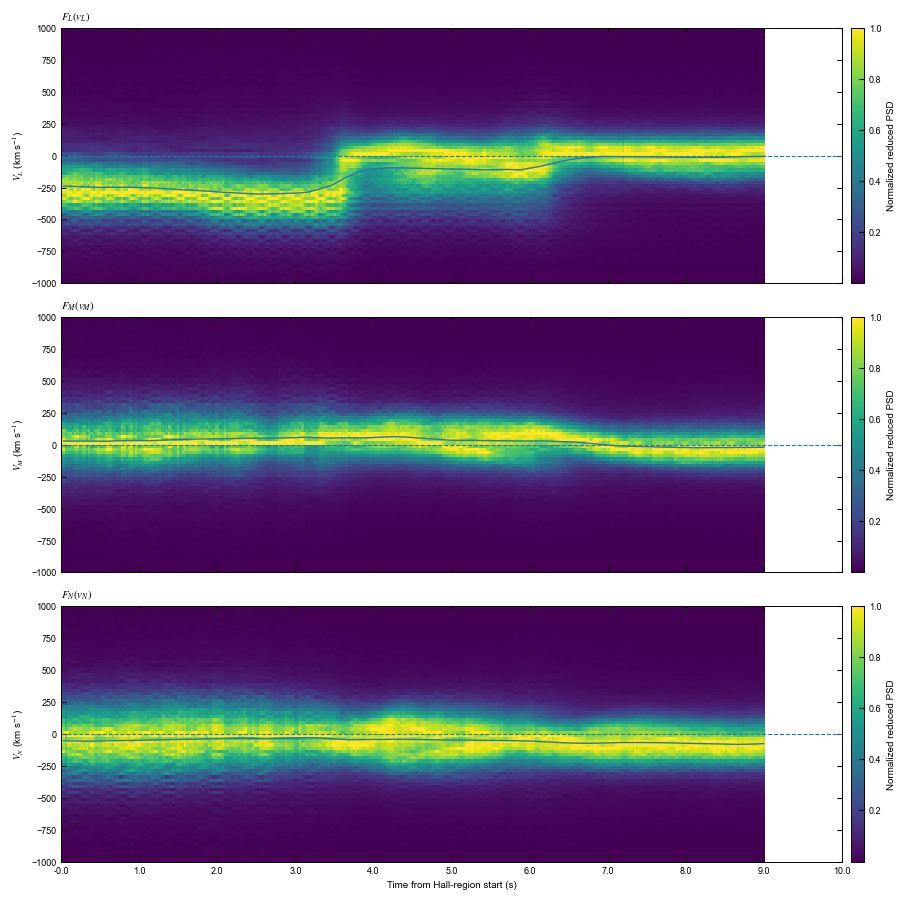

In [179]:
# ============================================================
# FULL-HALL-INTERVAL REDUCED 1-D ION DISTRIBUTIONS
# F_L(V_L), F_M(V_M), F_N(V_N)
#
# Designed to work with your existing:
#   vidatasets_interp
#   hall
#   eigvec
#   make_velocity_grid_lmn()
#
# Reviewer diagnostic:
#   single-peaked versus persistent separated populations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks


# ============================================================
# 1. Bin-edge utilities
# ============================================================

def linear_edges_from_centers(x, lower_limit=None, upper_limit=None):
    """
    Construct bin edges from monotonically increasing bin centers.
    """
    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or x.size < 2:
        raise ValueError("x must be a 1-D array with at least two elements.")

    edges = np.empty(x.size + 1, dtype=float)

    edges[1:-1] = 0.5 * (x[:-1] + x[1:])
    edges[0] = x[0] - 0.5 * (x[1] - x[0])
    edges[-1] = x[-1] + 0.5 * (x[-1] - x[-2])

    if lower_limit is not None:
        edges[0] = max(edges[0], lower_limit)

    if upper_limit is not None:
        edges[-1] = min(edges[-1], upper_limit)

    return edges


def periodic_phi_widths(phi_rad):
    """
    Angular widths for periodic azimuth bins.

    Parameters
    ----------
    phi_rad : array
        Azimuth centers in radians.

    Returns
    -------
    dphi : array
        Bin widths in radians.
    """
    phi = np.asarray(phi_rad, dtype=float)

    phi = np.mod(phi, 2.0 * np.pi)

    order = np.argsort(phi)
    sorted_phi = phi[order]

    forward = np.roll(sorted_phi, -1) - sorted_phi
    forward[-1] += 2.0 * np.pi

    backward = sorted_phi - np.roll(sorted_phi, 1)
    backward[0] += 2.0 * np.pi

    widths_sorted = 0.5 * (forward + backward)

    widths = np.empty_like(widths_sorted)
    widths[order] = widths_sorted

    return widths


# ============================================================
# 2. Velocity-space volume of each FPI sky-map cell
# ============================================================

def velocity_cell_volumes(
    vds,
    time_index,
    ion_mass=MP,
    theta_mode="polar",
):
    """
    Estimate d^3v for every FPI/DIS sky-map cell.

    Uses:

        d^3v =
            (v_hi^3 - v_lo^3)/3
            * dOmega

    where

        dOmega = dphi * (cos(theta_lo) - cos(theta_hi))

    for polar-angle coordinates.

    Returned units are proportional to (km/s)^3.

    Shape:
        (n_phi, n_theta, n_energy)
    """

    phi_data = vds["v1"]
    theta_data = vds["v2"]
    energy_data = vds["v3"]

    if "time" in phi_data.dims:
        phi_data = phi_data.isel(time=time_index)

    if "time" in theta_data.dims:
        theta_data = theta_data.isel(time=time_index)

    if "time" in energy_data.dims:
        energy_data = energy_data.isel(time=time_index)

    phi_deg = np.asarray(phi_data.values, dtype=float)
    theta_deg = np.asarray(theta_data.values, dtype=float)
    energy_ev = np.asarray(energy_data.values, dtype=float)

    # --------------------------------------------------------
    # Convert energy-bin centers to speed centers
    # --------------------------------------------------------
    speed = _energy_to_speed_kms(
        energy_ev,
        ion_mass=ion_mass,
    )

    # --------------------------------------------------------
    # Radial speed-bin edges
    # --------------------------------------------------------
    speed_edges = linear_edges_from_centers(
        speed,
        lower_limit=0.0,
    )

    radial_volume = (
        speed_edges[1:]**3
        - speed_edges[:-1]**3
    ) / 3.0

    # --------------------------------------------------------
    # Azimuth widths
    # --------------------------------------------------------
    phi_rad = np.deg2rad(phi_deg)

    dphi = periodic_phi_widths(phi_rad)

    # --------------------------------------------------------
    # Polar/elevation angular widths
    # --------------------------------------------------------
    theta_rad = np.deg2rad(theta_deg)

    if theta_mode == "polar":

        theta_edges = linear_edges_from_centers(
            theta_rad,
            lower_limit=0.0,
            upper_limit=np.pi,
        )

        dmu = (
            np.cos(theta_edges[:-1])
            - np.cos(theta_edges[1:])
        )

        dOmega = (
            dphi[:, None]
            * dmu[None, :]
        )

    elif theta_mode == "elevation":

        theta_edges = linear_edges_from_centers(
            theta_rad,
            lower_limit=-0.5 * np.pi,
            upper_limit=0.5 * np.pi,
        )

        # solid angle for elevation latitude
        dmu = (
            np.sin(theta_edges[1:])
            - np.sin(theta_edges[:-1])
        )

        dOmega = (
            dphi[:, None]
            * dmu[None, :]
        )

    else:
        raise ValueError(
            "theta_mode must be 'polar' or 'elevation'."
        )

    d3v = (
        dOmega[:, :, None]
        * radial_volume[None, None, :]
    )

    return d3v


# ============================================================
# 3. Reduce one 3-D ion VDF onto one LMN velocity component
# ============================================================

def reduced_distribution_1d(
    velocity_component,
    distribution,
    cell_volume,
    velocity_edges,
):
    """
    Calculate a reduced 1-D distribution:

        F_alpha(v_alpha)
          = integral integral
            f(v_L,v_M,v_N) dv_beta dv_gamma

    implemented by weighted histogramming of the original
    instrument cells into LMN velocity bins.

    The result is divided by output-bin width.

    For reviewer morphology analysis, the returned profile
    can subsequently be normalized to its own maximum.
    """

    v = np.asarray(
        velocity_component,
        dtype=float,
    ).ravel()

    f = np.asarray(
        distribution,
        dtype=float,
    ).ravel()

    dv3 = np.asarray(
        cell_volume,
        dtype=float,
    ).ravel()

    good = (
        np.isfinite(v)
        & np.isfinite(f)
        & np.isfinite(dv3)
        & (f > 0.0)
        & (dv3 > 0.0)
    )

    integrated, _ = np.histogram(
        v[good],
        bins=velocity_edges,
        weights=f[good] * dv3[good],
    )

    dv_output = np.diff(velocity_edges)

    profile = np.divide(
        integrated,
        dv_output,
        out=np.zeros_like(integrated, dtype=float),
        where=dv_output > 0,
    )

    centers = 0.5 * (
        velocity_edges[:-1]
        + velocity_edges[1:]
    )

    return centers, profile


# ============================================================
# 4. Normalize profile for morphological beam analysis
# ============================================================

def normalize_profile(profile):
    profile = np.asarray(profile, dtype=float)

    result = np.zeros_like(profile)

    good = np.isfinite(profile) & (profile > 0)

    if not np.any(good):
        return result

    maximum = np.nanmax(profile[good])

    if maximum > 0:
        result[good] = profile[good] / maximum

    return result


# ============================================================
# 5. Quantitative separated-population test
# ============================================================

def classify_reduced_profile(
    velocity,
    normalized_profile,
    smoothing_sigma_bins=0.7,
    minimum_prominence=0.08,
    minimum_secondary_height=0.10,
    minimum_separation_kms=150.0,
    maximum_valley_fraction=0.85,
):
    """
    Classify one reduced VDF.

    A candidate separated population requires:

    1. >= 2 detected peaks
    2. peak prominence >= minimum_prominence
    3. secondary peak >= minimum_secondary_height
       relative to the primary peak
    4. peak separation >= minimum_separation_kms
    5. an intervening valley <= maximum_valley_fraction
       of the weaker peak

    Returns
    -------
    dict
    """

    velocity = np.asarray(velocity, dtype=float)
    profile = np.asarray(normalized_profile, dtype=float)

    if smoothing_sigma_bins > 0:
        work = gaussian_filter1d(
            profile,
            sigma=smoothing_sigma_bins,
            mode="nearest",
        )
    else:
        work = profile.copy()

    if velocity.size < 3:
        return {
            "classification": "invalid",
            "peak_count": 0,
            "peak_velocities": [],
            "primary_velocity": np.nan,
            "secondary_velocity": np.nan,
            "secondary_ratio": np.nan,
            "peak_separation_kms": np.nan,
            "valley_fraction": np.nan,
            "is_separated": False,
        }

    dv = np.nanmedian(
        np.abs(np.diff(velocity))
    )

    minimum_distance_bins = max(
        1,
        int(
            np.ceil(
                minimum_separation_kms / dv
            )
        ),
    )

    peak_indices, properties = find_peaks(
        work,
        prominence=minimum_prominence,
        distance=minimum_distance_bins,
    )

    if peak_indices.size == 0:

        return {
            "classification": "single_or_flat",
            "peak_count": 0,
            "peak_velocities": [],
            "primary_velocity": np.nan,
            "secondary_velocity": np.nan,
            "secondary_ratio": np.nan,
            "peak_separation_kms": np.nan,
            "valley_fraction": np.nan,
            "is_separated": False,
        }

    heights = work[peak_indices]

    # Sort peaks by amplitude
    order = np.argsort(heights)[::-1]

    peak_indices = peak_indices[order]
    heights = heights[order]

    primary_idx = peak_indices[0]
    primary_height = heights[0]

    if peak_indices.size == 1:

        return {
            "classification": "single_peaked",
            "peak_count": 1,
            "peak_velocities": [
                float(velocity[primary_idx])
            ],
            "primary_velocity":
                float(velocity[primary_idx]),
            "secondary_velocity": np.nan,
            "secondary_ratio": np.nan,
            "peak_separation_kms": np.nan,
            "valley_fraction": np.nan,
            "is_separated": False,
        }

    # --------------------------------------------------------
    # Search all secondary candidate peaks
    # --------------------------------------------------------
    best_secondary = None

    for secondary_idx in peak_indices[1:]:

        secondary_height = work[secondary_idx]

        secondary_ratio = (
            secondary_height / primary_height
            if primary_height > 0
            else np.nan
        )

        separation = abs(
            velocity[secondary_idx]
            - velocity[primary_idx]
        )

        left = min(
            primary_idx,
            secondary_idx,
        )

        right = max(
            primary_idx,
            secondary_idx,
        )

        if right - left > 1:
            valley_height = np.nanmin(
                work[left:right + 1]
            )
        else:
            valley_height = min(
                primary_height,
                secondary_height,
            )

        weaker_peak = min(
            primary_height,
            secondary_height,
        )

        valley_fraction = (
            valley_height / weaker_peak
            if weaker_peak > 0
            else np.nan
        )

        qualifies = (
            secondary_ratio
            >= minimum_secondary_height
            and separation
            >= minimum_separation_kms
            and valley_fraction
            <= maximum_valley_fraction
        )

        if qualifies:

            candidate = {
                "idx": secondary_idx,
                "height": secondary_height,
                "ratio": secondary_ratio,
                "separation": separation,
                "valley_fraction": valley_fraction,
            }

            if (
                best_secondary is None
                or candidate["height"]
                > best_secondary["height"]
            ):
                best_secondary = candidate

    if best_secondary is None:

        return {
            "classification":
                "single_peaked_with_shoulders",
            "peak_count":
                int(peak_indices.size),
            "peak_velocities": [
                float(velocity[i])
                for i in peak_indices
            ],
            "primary_velocity":
                float(velocity[primary_idx]),
            "secondary_velocity": np.nan,
            "secondary_ratio": np.nan,
            "peak_separation_kms": np.nan,
            "valley_fraction": np.nan,
            "is_separated": False,
        }

    secondary_idx = best_secondary["idx"]

    return {
        "classification": "separated_peaks",
        "peak_count": int(
            peak_indices.size
        ),
        "peak_velocities": [
            float(velocity[i])
            for i in peak_indices
        ],
        "primary_velocity":
            float(velocity[primary_idx]),
        "secondary_velocity":
            float(velocity[secondary_idx]),
        "secondary_ratio":
            float(best_secondary["ratio"]),
        "peak_separation_kms":
            float(best_secondary["separation"]),
        "valley_fraction":
            float(
                best_secondary[
                    "valley_fraction"
                ]
            ),
        "is_separated": True,
    }


# ============================================================
# 6. Run across entire Hall interval
# ============================================================

def reduced_vdfs_entire_hall_region(
    vidatasets_interp,
    hall,
    eigvec,
    sc,
    hall_start,
    hall_end,

    b_key="lmn_b",
    vi_key="lmn_vi",

    instrument_to_base=None,

    velocity_range=(-1000.0, 1000.0),
    velocity_bin_width=25.0,

    reverse_look_direction=True,
    theta_mode="polar",

    ion_mass=MP,

    eigvec_layout="columns",
    instrument_matrix_layout="columns",

    smoothing_sigma_bins=0.7,

    minimum_prominence=0.08,
    minimum_secondary_height=0.10,
    minimum_separation_kms=150.0,
    maximum_valley_fraction=0.85,
):
    """
    Calculate F_L, F_M, F_N at every DIS time
    across the full Hall interval.
    """

    vds = vidatasets_interp[sc]

    hall_start = np.datetime64(
        hall_start,
        "ns",
    )

    hall_end = np.datetime64(
        hall_end,
        "ns",
    )

    times = vds.time.values.astype(
        "datetime64[ns]"
    )

    selected_indices = np.where(
        (times >= hall_start)
        & (times <= hall_end)
    )[0]

    if selected_indices.size == 0:
        raise ValueError(
            "No DIS samples found inside Hall interval."
        )

    velocity_edges = np.arange(
        velocity_range[0],
        velocity_range[1]
        + velocity_bin_width,
        velocity_bin_width,
    )

    velocity_centers = 0.5 * (
        velocity_edges[:-1]
        + velocity_edges[1:]
    )

    nt = selected_indices.size
    nv = velocity_centers.size

    F_L = np.full(
        (nt, nv),
        np.nan,
    )

    F_M = np.full(
        (nt, nv),
        np.nan,
    )

    F_N = np.full(
        (nt, nv),
        np.nan,
    )

    raw_L = np.full(
        (nt, nv),
        np.nan,
    )

    raw_M = np.full(
        (nt, nv),
        np.nan,
    )

    raw_N = np.full(
        (nt, nv),
        np.nan,
    )

    records = []

    distribution_name = (
        f"{sc}_dis_dist_brst"
    )

    for output_index, time_index in enumerate(
        selected_indices
    ):

        sample_time = times[time_index]

        # ----------------------------------------------------
        # Original ion PSD
        # ----------------------------------------------------
        distribution = np.asarray(
            vds[
                distribution_name
            ].isel(
                time=time_index
            ).values,
            dtype=float,
        )

        # ----------------------------------------------------
        # Complete LMN velocity grid
        # ----------------------------------------------------
        velocity_lmn = make_velocity_grid_lmn(
            vds=vds,
            time_index=time_index,
            eigvec=eigvec,
            instrument_to_base=instrument_to_base,
            reverse_look_direction=
                reverse_look_direction,
            theta_mode=theta_mode,
            ion_mass=ion_mass,
            eigvec_layout=eigvec_layout,
            instrument_matrix_layout=
                instrument_matrix_layout,
        )

        # ----------------------------------------------------
        # Original FPI cell volumes
        # ----------------------------------------------------
        d3v = velocity_cell_volumes(
            vds=vds,
            time_index=time_index,
            ion_mass=ion_mass,
            theta_mode=theta_mode,
        )

        # ----------------------------------------------------
        # Reduced L distribution
        # ----------------------------------------------------
        _, profile_L = reduced_distribution_1d(
            velocity_component=
                velocity_lmn[..., 0],
            distribution=distribution,
            cell_volume=d3v,
            velocity_edges=velocity_edges,
        )

        # ----------------------------------------------------
        # Reduced M distribution
        # ----------------------------------------------------
        _, profile_M = reduced_distribution_1d(
            velocity_component=
                velocity_lmn[..., 1],
            distribution=distribution,
            cell_volume=d3v,
            velocity_edges=velocity_edges,
        )

        # ----------------------------------------------------
        # Reduced N distribution
        # ----------------------------------------------------
        _, profile_N = reduced_distribution_1d(
            velocity_component=
                velocity_lmn[..., 2],
            distribution=distribution,
            cell_volume=d3v,
            velocity_edges=velocity_edges,
        )

        raw_L[output_index] = profile_L
        raw_M[output_index] = profile_M
        raw_N[output_index] = profile_N

        norm_L = normalize_profile(
            profile_L
        )

        norm_M = normalize_profile(
            profile_M
        )

        norm_N = normalize_profile(
            profile_N
        )

        F_L[output_index] = norm_L
        F_M[output_index] = norm_M
        F_N[output_index] = norm_N

        # ----------------------------------------------------
        # Quantitative peak classification
        # ----------------------------------------------------
        class_L = classify_reduced_profile(
            velocity_centers,
            norm_L,
            smoothing_sigma_bins=
                smoothing_sigma_bins,
            minimum_prominence=
                minimum_prominence,
            minimum_secondary_height=
                minimum_secondary_height,
            minimum_separation_kms=
                minimum_separation_kms,
            maximum_valley_fraction=
                maximum_valley_fraction,
        )

        class_M = classify_reduced_profile(
            velocity_centers,
            norm_M,
            smoothing_sigma_bins=
                smoothing_sigma_bins,
            minimum_prominence=
                minimum_prominence,
            minimum_secondary_height=
                minimum_secondary_height,
            minimum_separation_kms=
                minimum_separation_kms,
            maximum_valley_fraction=
                maximum_valley_fraction,
        )

        class_N = classify_reduced_profile(
            velocity_centers,
            norm_N,
            smoothing_sigma_bins=
                smoothing_sigma_bins,
            minimum_prominence=
                minimum_prominence,
            minimum_secondary_height=
                minimum_secondary_height,
            minimum_separation_kms=
                minimum_separation_kms,
            maximum_valley_fraction=
                maximum_valley_fraction,
        )

        record = {
            "time": sample_time,

            "L_class":
                class_L["classification"],
            "L_peak_count":
                class_L["peak_count"],
            "L_primary_km_s":
                class_L["primary_velocity"],
            "L_secondary_km_s":
                class_L["secondary_velocity"],
            "L_secondary_ratio":
                class_L["secondary_ratio"],
            "L_separation_km_s":
                class_L[
                    "peak_separation_kms"
                ],
            "L_valley_fraction":
                class_L[
                    "valley_fraction"
                ],
            "L_separated":
                class_L["is_separated"],

            "M_class":
                class_M["classification"],
            "M_peak_count":
                class_M["peak_count"],
            "M_primary_km_s":
                class_M["primary_velocity"],
            "M_secondary_km_s":
                class_M["secondary_velocity"],
            "M_secondary_ratio":
                class_M["secondary_ratio"],
            "M_separation_km_s":
                class_M[
                    "peak_separation_kms"
                ],
            "M_valley_fraction":
                class_M[
                    "valley_fraction"
                ],
            "M_separated":
                class_M["is_separated"],

            "N_class":
                class_N["classification"],
            "N_peak_count":
                class_N["peak_count"],
            "N_primary_km_s":
                class_N["primary_velocity"],
            "N_secondary_km_s":
                class_N["secondary_velocity"],
            "N_secondary_ratio":
                class_N["secondary_ratio"],
            "N_separation_km_s":
                class_N[
                    "peak_separation_kms"
                ],
            "N_valley_fraction":
                class_N[
                    "valley_fraction"
                ],
            "N_separated":
                class_N["is_separated"],
        }

        records.append(record)

    diagnostics = pd.DataFrame(
        records
    )

    return {
        "times":
            times[selected_indices],
        "indices":
            selected_indices,
        "velocity":
            velocity_centers,

        "F_L": F_L,
        "F_M": F_M,
        "F_N": F_N,

        "raw_L": raw_L,
        "raw_M": raw_M,
        "raw_N": raw_N,

        "diagnostics":
            diagnostics,
    }


# ============================================================
# 7. Persistence test
# ============================================================

def add_persistent_beam_flags(
    diagnostics,
    minimum_consecutive_samples=2,
):
    """
    A 'persistent' separated population must remain detected
    for at least N consecutive DIS samples.
    """

    result = diagnostics.copy()

    for axis in ["L", "M", "N"]:

        separated = result[
            f"{axis}_separated"
        ].to_numpy(dtype=bool)

        persistent = np.zeros(
            separated.size,
            dtype=bool,
        )

        start = 0

        while start < separated.size:

            if not separated[start]:
                start += 1
                continue

            stop = start

            while (
                stop + 1
                < separated.size
                and separated[stop + 1]
            ):
                stop += 1

            run_length = (
                stop - start + 1
            )

            if (
                run_length
                >= minimum_consecutive_samples
            ):
                persistent[
                    start:stop + 1
                ] = True

            start = stop + 1

        result[
            f"{axis}_persistent_beam"
        ] = persistent

    return result


# ============================================================
# 8. Plot time-velocity maps
# ============================================================

def plot_reduced_distribution_maps(
    result,
    hall=None,
    sc=None,
    vi_key="lmn_vi",
    save_path=None,
    dpi=600,
):
    """
    Plot normalized F_L, F_M and F_N across entire Hall region.
    """

    times = result["times"]
    velocity = result["velocity"]

    matrices = [
        result["F_L"],
        result["F_M"],
        result["F_N"],
    ]

    labels = [
        r"$F_L(v_L)$",
        r"$F_M(v_M)$",
        r"$F_N(v_N)$",
    ]

    velocity_labels = [
        r"$V_L$ (km s$^{-1}$)",
        r"$V_M$ (km s$^{-1}$)",
        r"$V_N$ (km s$^{-1}$)",
    ]

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(10.0, 9.0),
        sharex=True,
    )

    tnum = (
        times.astype("datetime64[ms]")
        .astype("int64")
    )

    for i, ax in enumerate(axes):

        mesh = ax.pcolormesh(
            tnum,
            velocity,
            matrices[i].T,
            shading="auto",
        )

        ax.set_ylabel(
            velocity_labels[i]
        )

        ax.set_title(
            labels[i],
            loc="left",
        )

        fig.colorbar(
            mesh,
            ax=ax,
            label="Normalized reduced PSD",
            pad=0.01,
        )

        # -----------------------------------------------
        # Optional overlay of measured ion bulk velocity
        # -----------------------------------------------
        if (
            hall is not None
            and sc is not None
        ):

            vi = hall[sc][vi_key]

            selected_vi = vi.sel(
                time=slice(
                    times[0],
                    times[-1],
                )
            )

            vi_times = (
                selected_vi.time.values
                .astype("datetime64[ms]")
                .astype("int64")
            )

            vi_values = np.asarray(
                selected_vi.values,
                dtype=float,
            )

            ax.plot(
                vi_times,
                vi_values[:, i],
                linewidth=1.0,
            )

        ax.axhline(
            0.0,
            linestyle="--",
            linewidth=0.8,
        )

    # Show UT as seconds relative to first sample
    t0 = tnum[0]

    ticks = axes[-1].get_xticks()

    labels_time = []

    for tick in ticks:
        dt_ms = tick - t0
        labels_time.append(
            f"{dt_ms / 1000.0:.1f}"
        )

    axes[-1].set_xticks(ticks)
    axes[-1].set_xticklabels(
        labels_time
    )

    axes[-1].set_xlabel(
        "Time from Hall-region start (s)"
    )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()

    return fig, axes


# ============================================================
# 9. Simple reviewer summary
# ============================================================

def print_beam_summary(diagnostics):

    print(
        "\n=============================================="
    )
    print(
        "FULL-HALL REDUCED-VDF BEAM SUMMARY"
    )
    print(
        "==============================================\n"
    )

    for axis in ["L", "M", "N"]:

        separated = diagnostics[
            f"{axis}_separated"
        ].sum()

        persistent = diagnostics[
            f"{axis}_persistent_beam"
        ].sum()

        total = len(diagnostics)

        print(
            f"{axis} direction:"
        )

        print(
            f"  samples analysed       : {total}"
        )

        print(
            f"  separated-peak samples : "
            f"{separated}"
        )

        print(
            f"  persistent-beam samples: "
            f"{persistent}"
        )

        print(
            f"  persistent fraction    : "
            f"{persistent / total:.3f}"
        )

        print()
# ============================================================
# RUN FOR MMS4
# ============================================================

sc = "mms4"

hall_start = del3

hall_end = del4

reduced_result = reduced_vdfs_entire_hall_region(
    vidatasets_interp=vidatasets_interp,
    hall=hall,
    eigvec=eigvec,
    sc=sc,

    hall_start=hall_start,
    hall_end=hall_end,

    b_key="lmn_b",
    vi_key="lmn_vi",

    # IMPORTANT:
    # Supply correct instrument -> base-frame rotation
    # if the FPI angular bins are not already expressed
    # in the same frame expected by eigvec.
    instrument_to_base=None,

    velocity_range=(-1000.0, 1000.0),

    # 25 km/s output bins are fine for morphology.
    # Test 20, 25, 40, 50 km/s for robustness.
    velocity_bin_width=25.0,

    reverse_look_direction=True,
    theta_mode="polar",

    eigvec_layout="columns",
    instrument_matrix_layout="columns",

    # Mild smoothing ONLY for peak detection.
    smoothing_sigma_bins=0.7,

    # Reviewer-facing quantitative criteria
    minimum_prominence=0.08,
    minimum_secondary_height=0.10,
    minimum_separation_kms=150.0,
    maximum_valley_fraction=0.85,
)


# ============================================================
# Require persistence across >= 2 consecutive DIS samples
# ============================================================

diagnostics = add_persistent_beam_flags(
    reduced_result["diagnostics"],
    minimum_consecutive_samples=2,
)

reduced_result["diagnostics"] = diagnostics


# ============================================================
# Print numerical result
# ============================================================

print_beam_summary(
    diagnostics
)


# ============================================================
# Plot full Hall-region F_L, F_M, F_N
# ============================================================

fig, axes = plot_reduced_distribution_maps(
    reduced_result,
    hall=hall,
    sc=sc,
    vi_key="lmn_vi",

    save_path=os.path.join(
        output_folder,
        f"{taistarttime}_{sc}_"
        "full_Hall_reduced_VDF_LMN.png",
    ),

    dpi=600,
)
fig.savefig(
    os.path.join(output_folder, f"{taistarttime}_{sc}_reduced_1dd.png"),
    dpi=300, bbox_inches="tight",
)

# ============================================================
# Save reviewer diagnostic table
# ============================================================

diagnostics.to_csv(
    os.path.join(
        output_folder,
        f"{taistarttime}_{sc}_"
        "full_Hall_reduced_VDF_beam_diagnostics.csv",
    ),
    index=False,
)

Reduced distributions: 2016-01-22T07:18:44.029564000 → 2016-01-22T07:18:52.999564000
<xarray.Dataset> Size: 290kB
Dimensions:  (time: 150, v: 80)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2016-01-22T07:18:44.029564 ... 2016-01...
  * v        (v) float64 640B -987.5 -962.5 -937.5 -912.5 ... 937.5 962.5 987.5
Data variables:
    f_L      (time, v) float64 96kB 2.636e-25 4.008e-24 ... 2.042e-25 3.957e-25
    f_M      (time, v) float64 96kB 1.396e-25 9.222e-26 ... 1.775e-25 4.387e-25
    f_N      (time, v) float64 96kB 2.188e-25 4.683e-25 ... 4.147e-25 2.793e-25
Attributes:
    units:    s^3 cm^-6  (summed over the other two velocity directions)
    v_units:  km s^-1
    note:     structure frame: only V_L shifted


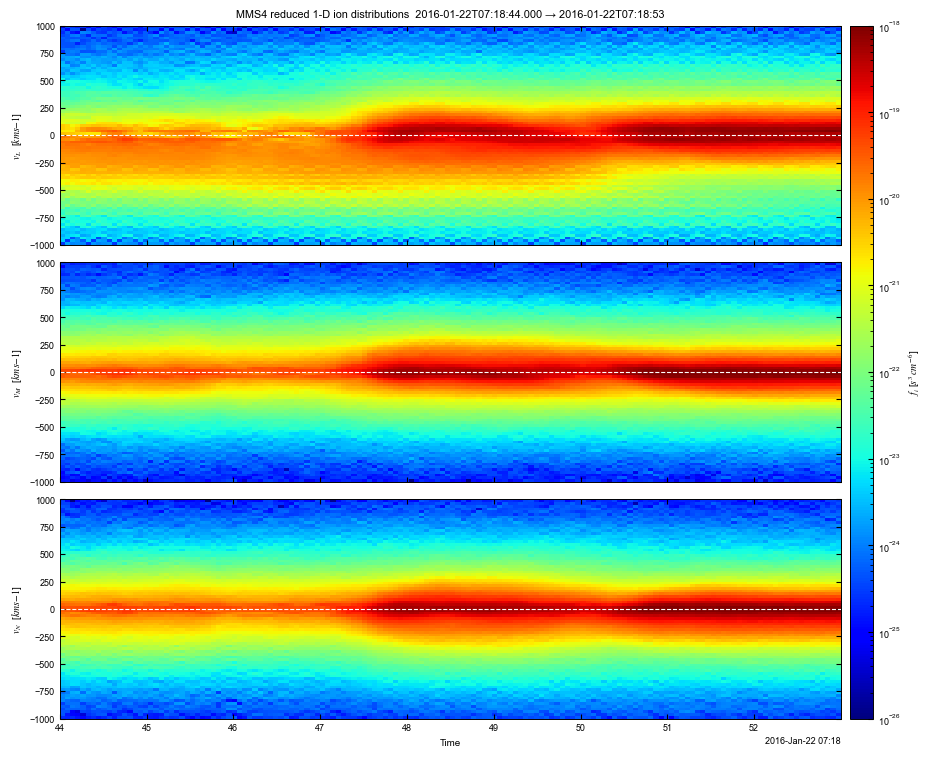

In [185]:
# ==============================================================================
# 1-D reduced velocity distribution functions  f(v_L), f(v_M), f(v_N)
# ==============================================================================
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator

# ---------------------------------------------------------------------------
# Helper: reduce the 3-D sky-map onto one LMN axis
# ---------------------------------------------------------------------------
def reduced_1d(
    vds,
    time_index,
    sc,
    eigvec,
    component="L",                 # "L", "M" or "N"
    v_range=(-1200.0, 1200.0),
    bins=80,
    structure_speed_l=0.0,
    instrument_to_base=None,
    reverse_look_direction=True,
    theta_mode="polar",
    ion_mass=MP,
    eigvec_layout="columns",
    instrument_matrix_layout="columns",
):
    """
    Return centres [km/s] and the reduced distribution f(v_comp)
    in the structure frame (only V_L is shifted).
    """
    vel = make_velocity_grid_lmn(
        vds=vds,
        time_index=time_index,
        eigvec=eigvec,
        instrument_to_base=instrument_to_base,
        reverse_look_direction=reverse_look_direction,
        theta_mode=theta_mode,
        ion_mass=ion_mass,
        eigvec_layout=eigvec_layout,
        instrument_matrix_layout=instrument_matrix_layout,
    ).values                                                     # (…, 3)

    f = np.asarray(
        vds[f"{sc}_dis_dist_brst"].isel(time=time_index).values,
        dtype=float,
    )

    # shift only the L-component into the structure frame
    structure_vel = np.array([structure_speed_l, 0.0, 0.0])
    w = vel - structure_vel

    idx = {"L": 0, "M": 1, "N": 2}[component.upper()]
    v_comp  = w[..., idx].ravel()
    weights = f.ravel()

    good = (
        np.isfinite(weights)
        & (weights > 0)
        & np.isfinite(v_comp)
    )

    hist, edges = np.histogram(
        v_comp[good],
        bins=bins,
        range=v_range,
        weights=weights[good],
        density=False,
    )
    centres = 0.5 * (edges[:-1] + edges[1:])
    return centres, hist


# ==============================================================================
# USER SETTINGS
# ==============================================================================
sc = "mms4"
vds = vidatasets_interp[sc]

# time window = whole Hall region
t_start = del3
t_end   = del4

# or use the B_M zero-crossings
# t_start = bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[0]
# t_end   = bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[1]

step          = 2                 # every N-th DIS sample
v_range       = (-1000.0, 1000.0)
bins          = 80
structure_speed_l = 0.0           # same value used for the 2-D VDFs

# ==============================================================================
# Build reduced-distribution spectrograms
# ==============================================================================
vds_sel = vds.sel(time=slice(t_start, t_end))
print(f"Reduced distributions: {vds_sel.time.values[0]} → {vds_sel.time.values[-1]}")

times = []
fL_list, fM_list, fN_list = [], [], []
v_centres = None

for it in range(0, len(vds_sel.time), step):
    global_idx = int(np.argmin(np.abs(vds.time.values - vds_sel.time.values[it])))
    try:
        vL, fL = reduced_1d(vds, global_idx, sc, eigvec, component="L",
                            v_range=v_range, bins=bins,
                            structure_speed_l=structure_speed_l)
        vM, fM = reduced_1d(vds, global_idx, sc, eigvec, component="M",
                            v_range=v_range, bins=bins,
                            structure_speed_l=structure_speed_l)
        vN, fN = reduced_1d(vds, global_idx, sc, eigvec, component="N",
                            v_range=v_range, bins=bins,
                            structure_speed_l=structure_speed_l)

        times.append(np.datetime64(vds.time.isel(time=global_idx).values, "ns"))
        fL_list.append(fL)
        fM_list.append(fM)
        fN_list.append(fN)
        if v_centres is None:
            v_centres = vL          # same for all three
    except Exception as e:
        print(f"skipping {global_idx}: {e}")
        continue

times = np.asarray(times)
fL_arr = np.asarray(fL_list)      # (ntime, nbins)
fM_arr = np.asarray(fM_list)
fN_arr = np.asarray(fN_list)

# store as xarray for convenience
red_ds = xr.Dataset(
    data_vars={
        "f_L": (["time", "v"], fL_arr),
        "f_M": (["time", "v"], fM_arr),
        "f_N": (["time", "v"], fN_arr),
    },
    coords={
        "time": times,
        "v": v_centres,
    },
    attrs={
        "units": "s^3 cm^-6  (summed over the other two velocity directions)",
        "v_units": "km s^-1",
        "note": "structure frame: only V_L shifted",
    },
)
print(red_ds)

# optional save
red_ds.to_netcdf(os.path.join(output_folder, f"{taistarttime}_{sc}_reduced_1d.nc"))
red_ds.to_dataframe().reset_index().to_csv(
    os.path.join(output_folder, f"{taistarttime}_{sc}_reduced_1d.csv"),
    index=False,
)

# ==============================================================================
# Plot: three spectrograms  (time vs velocity)
# ==============================================================================
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True,
                        gridspec_kw={"hspace": 0.08})

# common colour scale (adjust if needed)
vmin, vmax = 1e-26, 1e-18
norm = LogNorm(vmin=vmin, vmax=vmax)

for ax, data, label in zip(
    axs,
    [red_ds.f_L, red_ds.f_M, red_ds.f_N],
    [r"$v_L$", r"$v_M$", r"$v_N$"],
):
    # pcolormesh expects edges; we approximate with centres
    pcm = ax.pcolormesh(
        red_ds.time,
        red_ds.v,
        data.T,                     # (v, time)
        norm=norm,
        cmap="jet",
        shading="auto",
        rasterized=True,
    )
    ax.set_ylabel(label + r"  [$kms{-1}$]")
    ax.set_ylim(v_range)
    ax.axhline(0, c="w", ls="--", lw=0.8)
    ax.tick_params(direction="in", top=True, right=True)

# colourbar on the last axis
cbar = fig.colorbar(pcm, ax=axs, pad=0.01, aspect=30)
cbar.set_label(r"$f_i$ [$s^3\,cm^{-6}$]")

axs[-1].set_xlabel("Time")
axs[0].set_title(f"{sc.upper()} reduced 1-D ion distributions  "
                 f"{t_start} → {t_end}")

# optional: mark the same vertical lines you use in the overview
# for t in [x1, x2, Bl, x3, x4]:
#     for ax in axs:
#         ax.axvline(t, c="k", ls="--", lw=0.7)

fig.savefig(
    os.path.join(output_folder, f"{taistarttime}_{sc}_reduced_1d.png"),
    dpi=300, bbox_inches="tight",
)
plt.show()

2 9
0 8
-30 -21
-28 -21
-30 -21


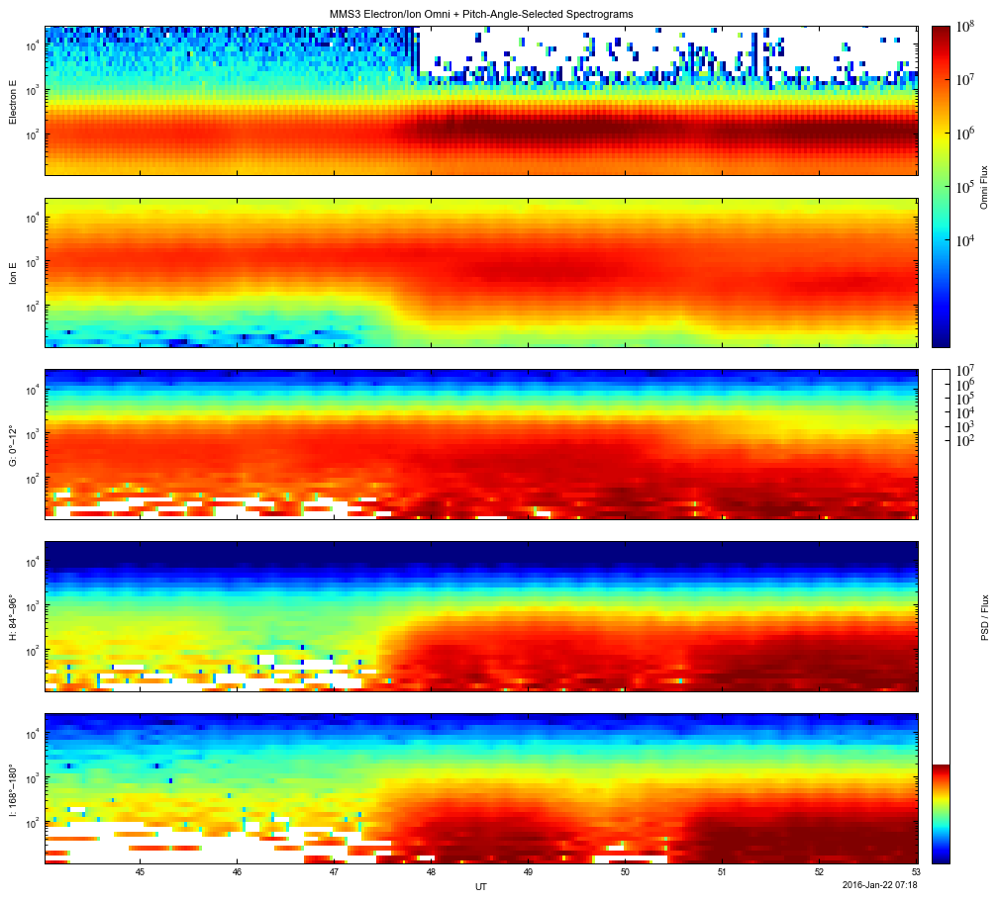

In [222]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# =========================================================
# choose exact colorbar tick range as powers of 10
# =========================================================
def set_cbar_log_ticks(cbar, start_exp, end_exp):
    ticks = 10.0 ** np.arange(start_exp, end_exp + 1)
    labels = [fr'$10^{{{k}}}$' for k in range(start_exp, end_exp + 1)]
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)
    cbar.minorticks_off()
    cbar.ax.tick_params(labelsize=10.5, labelcolor='black')


def scaled_log_limits(vals, frac=0):
    vals = vals[np.isfinite(vals) & (vals > 0)]
    log_min = int(round(np.log10(vals.min())))
    log_max = int(round(np.log10(vals.max())))
    print(log_min, log_max)

    vmin = 10 ** (log_min + 2)
    vmax = 10 ** log_max
    return vmin, vmax


# =========================================================
# helpers for omni spectrograms
# =========================================================
def get_omni_parts(da):
    if "espec_e_dim" in da.dims:
        e_dim = "espec_e_dim"
    elif "e_dim" in da.dims:
        e_dim = "e_dim"
    else:
        e_dim = [d for d in da.dims if d != "time"][0]

    if "spec_bins" in da.coords:
        E = da["spec_bins"]
    elif hasattr(da, "spec_bins"):
        E = da.spec_bins
    elif "espec_v" in da.coords:
        E = da["espec_v"]
    else:
        raise ValueError("No energy coordinate found for omni spectrogram")

    if "time" in E.dims:
        E = E.mean("time", skipna=True)

    E = np.asarray(E.values, dtype=float)
    t = np.asarray(da["time"].values)
    F = np.asarray(da.transpose(e_dim, "time").values, dtype=float)

    good_E = np.isfinite(E) & (E > 0)
    E = E[good_E]
    F = F[good_E, :]
    F = np.where(np.isfinite(F) & (F > 0), F, np.nan)

    vals = F[np.isfinite(F) & (F > 0)]
    vmin, vmax = scaled_log_limits(vals)
    return t, E, F, vmin, vmax


def plot_omni(ax, da, ylabel, title=None, cmap="jet"):
    t, E, F, vmin, vmax = get_omni_parts(da)

    m = ax.pcolormesh(
        t, E, F,
        shading="auto",
        cmap=cmap,
        norm=mcolors.LogNorm(vmin=vmin, vmax=vmax),
        rasterized=True
    )
    ax.set_yscale("log")
    ax.set_ylim(np.nanmin(E[E > 0]), np.nanmax(E))
    ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title)
    return m


# =========================================================
# helpers for G/H/I from full distribution
# =========================================================
def pa_energy_time_spec(dist, pa_min, pa_max):
    pa = dist["spec_bins"]
    pa_dim = pa.dims[0]

    mask = (pa >= pa_min) & (pa <= pa_max)
    idx = np.where(mask.values)[0]

    if len(idx) == 0:
        center = 0.5 * (pa_min + pa_max)
        idx = [int(np.argmin(np.abs(pa.values - center)))]

    out = dist.isel({pa_dim: idx}).mean(dim=pa_dim, skipna=True)

    extra_dims = [d for d in out.dims if d not in ["time", "v3_dim"]]
    for d in extra_dims:
        out = out.mean(dim=d, skipna=True)

    return out


def plot_et_spec(ax, da, ylabel, cmap="jet"):
    t = np.asarray(da["time"].values)

    E = da["v3"]
    if "time" in E.dims:
        E = E.mean("time", skipna=True)
    E = np.asarray(E.values, dtype=float)

    F = np.asarray(da.transpose("v3_dim", "time").values, dtype=float)

    good_E = np.isfinite(E) & (E > 0)
    E = E[good_E]
    F = F[good_E, :]
    F = np.where(np.isfinite(F) & (F > 0), F, np.nan)

    vals = F[np.isfinite(F) & (F > 0)]
    vmin, vmax = scaled_log_limits(vals)

    m = ax.pcolormesh(
        t, E, F,
        shading="auto",
        cmap=cmap,
        norm=mcolors.LogNorm(vmin=vmin, vmax=vmax),
        rasterized=True
    )
    ax.set_yscale("log")
    ax.set_ylim(np.nanmin(E[E > 0]), np.nanmax(E))
    ax.set_ylabel(ylabel)
    return m


# =========================================================
# load data
# =========================================================
i_da = idatasets_interp['mms3'].mms3_dis_energyspectr_omni_brst
e_da = edatasets_interp['mms3'].mms3_des_energyspectr_omni_brst
dist = vidatasets_interp['mms3']['mms3_dis_dist_brst']

# optional: restrict time
i_da = i_da.sel(time=slice(del3, del4))
e_da = e_da.sel(time=slice(del3, del4))
dist = dist.sel(time=slice(del3, del4))

# G/H/I
G = pa_energy_time_spec(dist, 0, 12)
H = pa_energy_time_spec(dist, 84, 96)
I = pa_energy_time_spec(dist, 168, 180)


# =========================================================
# plot
# =========================================================
fig, ax = plt.subplots(5, 1, figsize=(12, 11), sharex=True)

# corrected labels
m0 = plot_omni(
    ax[0], e_da,
    ylabel="Electron E",
    title="MMS3 Electron/Ion Omni + Pitch-Angle-Selected Spectrograms"
)

m1 = plot_omni(ax[1], i_da, ylabel="Ion E")

mG = plot_et_spec(ax[2], G, "G: 0°–12°")
mH = plot_et_spec(ax[3], H, "H: 84°–96°")
mI = plot_et_spec(ax[4], I, "I: 168°–180°")

ax[4].set_xlabel("UT")

# leave room on the right for colorbars
fig.subplots_adjust(right=0.86, hspace=0.15)

# make sure positions are updated
fig.canvas.draw()

# ---------------- top colorbar (ax[0], ax[1]) ----------------
pos0 = ax[0].get_position()
pos1 = ax[1].get_position()

y0_top = min(pos0.y0, pos1.y0)
y1_top = max(pos0.y1, pos1.y1)
x_right_top = max(pos0.x1, pos1.x1)

cbar_pad = 0.012
cbar_w = 0.015

cax0 = fig.add_axes([x_right_top + cbar_pad, y0_top, cbar_w, y1_top - y0_top])
cbar0 = fig.colorbar(m1, cax=cax0)
cbar0.set_label("Omni Flux")

# choose exact powers shown on top colorbar
# example: 10^4 to 10^8
set_cbar_log_ticks(cbar0, start_exp=4, end_exp=8)

# ---------------- bottom colorbar (ax[2], ax[3], ax[4]) ----------------
pos2 = ax[2].get_position()
pos3 = ax[3].get_position()
pos4 = ax[4].get_position()

y0_bot = min(pos2.y0, pos3.y0, pos4.y0)
y1_bot = max(pos2.y1, pos3.y1, pos4.y1)
x_right_bot = max(pos2.x1, pos3.x1, pos4.x1)

cax1 = fig.add_axes([x_right_bot + cbar_pad, y0_bot, cbar_w, y1_bot - y0_bot])
cbar1 = fig.colorbar(mI, cax=cax1)
cbar1.set_label("PSD / Flux")

# choose exact powers shown on bottom colorbar
# example: 10^2 to 10^7
set_cbar_log_ticks(cbar1, start_exp=2, end_exp=7)

plt.show()

Plotting for MMS1...


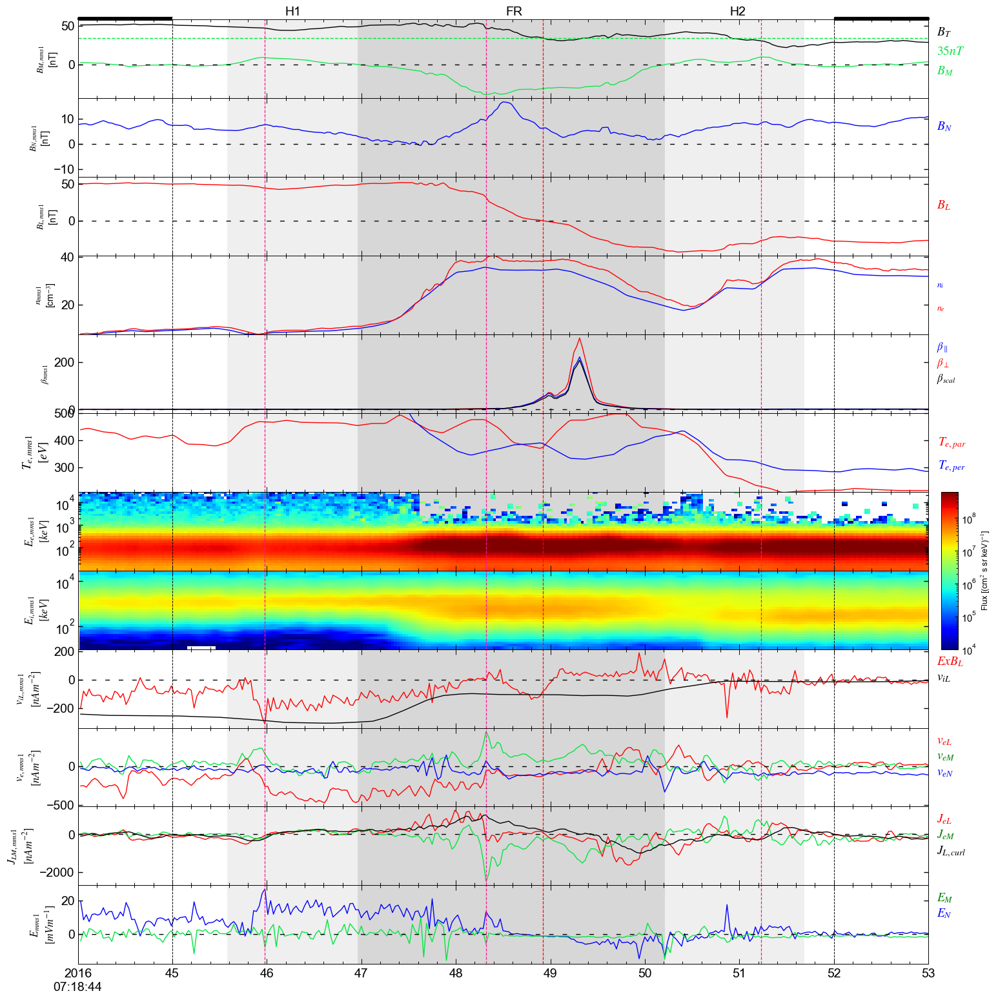

Plotting for MMS2...


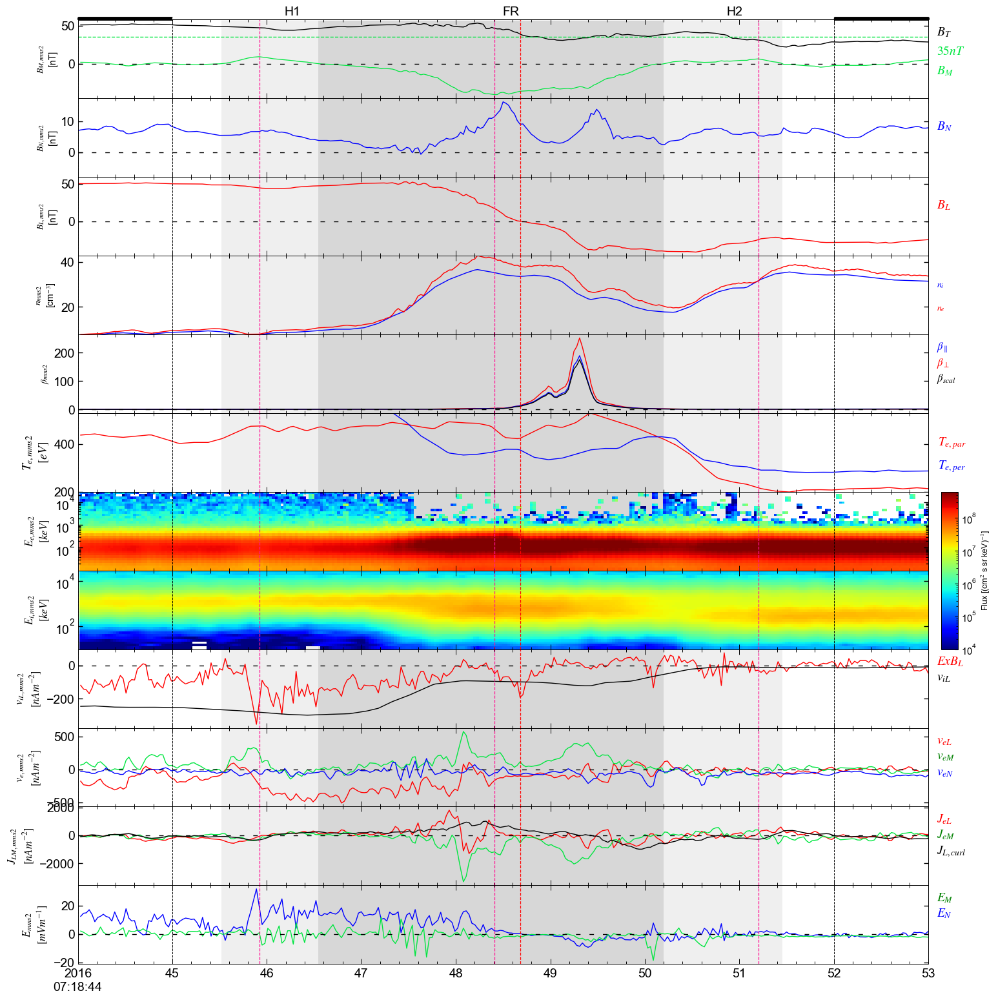

Plotting for MMS3...


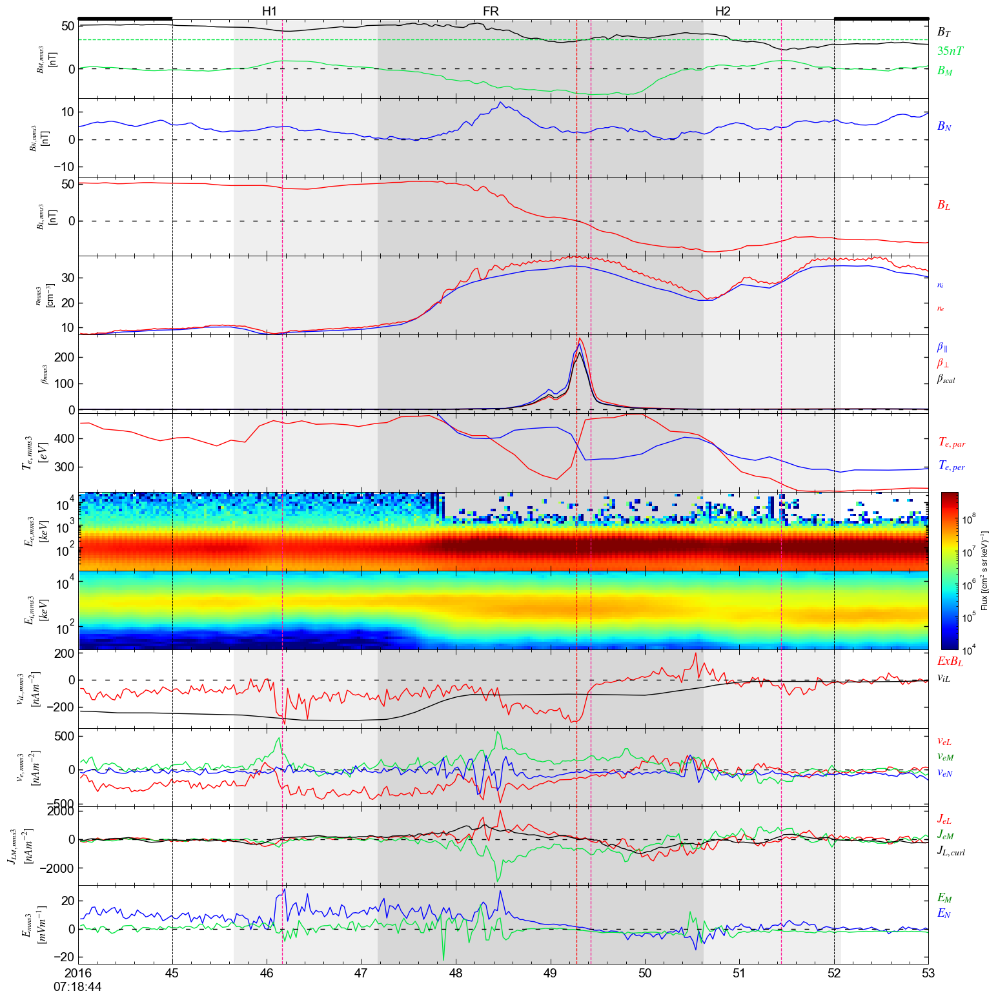

Plotting for MMS4...


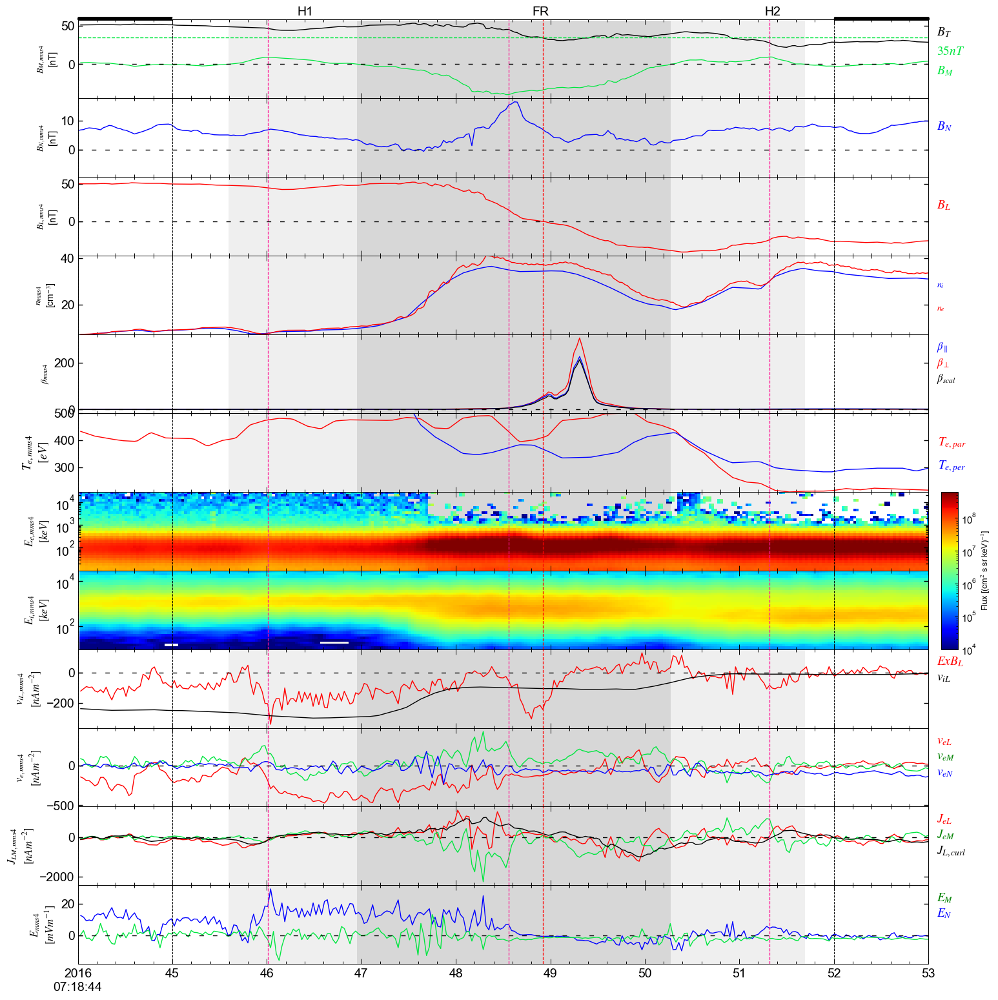

In [223]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors

mpl.rcParams["path.simplify"] = True
mpl.rcParams["path.simplify_threshold"] = 0.5
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams["path.simplify"] = True
mpl.rcParams["path.simplify_threshold"] = 0.5

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

for sc in sc_list:
    print(f"Plotting for {sc.upper()}...")

    # --- times (make sure these exist BEFORE you use them)
    t1 = times_dict[sc][0]
    t2 = times_dict[sc][1]

    # --- per-spacecraft Bl
    Bl_dict = {
        sc_: find(hall[sc_].lmn_b, LMN=0, d1=del3, d2=del4)[0]
        for sc_ in sc_list
    }
    Bl = Bl_dict[sc]

    # ✅ background guide field for this spacecraft
    B_g = df_all.loc[sc, '$B_g$']  # df_all indexed by sc

    # --- main fields
    B_hm = hall[sc].lmn_b.sel(time=slice(del3, del4)) - res_all[sc]['Bg_linear']

    bn = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=2)
    bl = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=0)
    B_magnitude = np.sqrt(bl**2 + res_all[sc]['Hall_BM']**2 + bn**2)

    # --- locate features (uses t1,t2,Bl)
    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values)
    )
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values)
    )
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values)
    )
    
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]
    
    # --- Plotting: NOW 12 PANELS (2 empty/beta panels after density)
    fig, axs = plt.subplots(12, 1, figsize=[17, 19], sharex=True,
                            gridspec_kw={'hspace': 0})

    # =======================
    # 0: B_M + |B|
    # =======================
    axs[0].plot(B_hm.time, B_hm.sel(LMN=1), c=(0/255, 230/255, 64/255), label=r'$\mathit{B_M}$')
    axs[0].plot(hall[sc].lmn_b.time.sel(time=slice(del3, del4)), Bmag, lw=1, c='k')
    axs[0].set_ylabel(r'$\mathit{B_{M,%s}}$' % sc + '\n[nT]', fontsize=10)
    axs[0].axhline(y=B_g, c=(0/255, 230/255, 64/255), ls='--', lw=1)

    # outside BN mean (unchanged logic)
    BN_left  = hall[sc].lmn_b.sel(LMN=2, time=slice(del3, th_0)).mean("time")
    BN_right = hall[sc].lmn_b.sel(LMN=2, time=slice(th_1, del4)).mean("time")
    BN_outside = 0.5 * (BN_left + BN_right)

    # =======================
    # 1: B_N
    # =======================
    axs[1].plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=2), c='b', lw=1, label=r'$\mathit{B_N}$')
    axs[1].set_ylabel(r'$\mathit{B_{N,%s}}$' % sc + '\n[nT]', fontsize=10)

    # =======================
    # 2: B_L
    # =======================
    axs[2].plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=0), c='r', lw=1, label=r'$\mathit{B_L}$')
    axs[2].set_ylabel(r'$\mathit{B_{L,%s}}$' % sc + '\n[nT]', fontsize=10)

    # =======================
    # 3: densities
    # =======================
    axs[3].plot(
        idatasets_interp[sc].time.sel(time=slice(del3, del4)),
        idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"].sel(time=slice(del3, del4)),
        c='b', lw=1
    )
    axs[3].plot(
        edatasets_interp[sc].time.sel(time=slice(del3, del4)),
        edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4)),
        c='r', lw=1
    )
    axs[3].set_ylabel(r'$\mathit{n_{%s}}$' % sc + '\n[cm$^{-3}$]', fontsize=10)

    axs[3].set_ylim(
        np.min(edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4))),
        np.max(edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4)))
    )

    # =======================
    # 4: NEW (empty/beta panel 1)
    # =======================
    axs[4].plot(
        beta_tensor.time.sel(time=slice(del3, del4)),
        beta_results[sc]["beta_parallel"].sel(time=slice(del3, del4)),
        c='r', lw=1,label=r'$\beta_\perp$'
    )
    axs[4].plot(
        beta_nt.time.sel(time=slice(del3, del4)),
        beta_results[sc]["beta_perpendicular"].sel(time=slice(del3, del4)),
        c='b', lw=1, label=r'$\beta_\par$'
    )
    axs[4].plot(
        beta_results[sc]["beta_i_scalar"].time.sel(time=slice(del3, del4)),
        beta_results[sc]["beta_i_scalar"].sel(time=slice(del3, del4)),
        c='k', lw=1,label=r'$\beta_scalar$'
    )
    axs[4].set_ylabel(r'$\beta_{%s}$' % sc, fontsize=10)

    # =======================
    # 5: NEW (empty/beta panel 2)
    # =======================
    axs[5].set_ylabel(r'$\beta_{\parallel,%s}$' % sc + '\n' + r'$\beta$', fontsize=10)

    # =======================
    # 6: Spectrogram electrons (was axs[4])
    # =======================
    e_da = edatasets_interp[sc][f"{sc}_des_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    e_time = e_da.time.values
    e_energy = e_da.spec_bins.mean("time", skipna=True).values
    e_flux = e_da.transpose("e_dim", "time").values
    e_flux = np.where(np.isfinite(e_flux) & (e_flux > 0), e_flux, np.nan)

    specgram = axs[6].pcolormesh(
        e_time, e_energy, e_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True,
        shading="auto"
    )
    axs[6].set_ylabel(r'$\mathbf{\mathit{E_{e,%s}}}$' % sc + '\n' + r'$\mathit{[keV]}$', fontsize=12)
    axs[6].set_yscale("log")

    # =======================
    # 7: Spectrogram ions (was axs[5])
    # =======================
    i_da = idatasets_interp[sc][f"{sc}_dis_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    i_time = i_da.time.values
    i_energy = i_da.spec_bins.mean("time", skipna=True).values
    i_flux = i_da.transpose("e_dim", "time").values
    i_flux = np.where(np.isfinite(i_flux) & (i_flux > 0), i_flux, np.nan)

    pcmi = axs[7].pcolormesh(
        i_time, i_energy, i_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True,
        shading="auto"
    )
    axs[7].set_ylabel(r'$\mathbf{\mathit{E_{i,%s}}}$' % sc + '\n' + r'$\mathit{[keV]}$', fontsize=12)
    axs[7].set_yscale("log")

    # --- ensure axes positions finalized before reading them ---
    fig.canvas.draw()

    # Colorbar spanning BOTH spectrograms (axs[6] & axs[7])
    posi6 = axs[6].get_position()
    posi7 = axs[7].get_position()

    y0 = float(np.minimum(posi6.y0, posi7.y0))
    y1 = float(np.maximum(posi6.y1, posi7.y1))
    x_right = float(np.maximum(posi6.x1, posi7.x1))

    cbar_pad = 0.012
    cbar_w = 0.015

    cax = fig.add_axes([x_right + cbar_pad, y0, cbar_w, (y1 - y0)])
    mappable = pcmi  # shared norm
    cbar = fig.colorbar(mappable, cax=cax)
    cbar.set_label(r"Flux [(cm$^2$ s sr keV)$^{-1}$]", fontsize=9)
    cbar.set_ticks(10 ** np.arange(4, 9))
    cbar.ax.tick_params(labelsize=10.5, labelcolor="black")

    # =======================
    # 8: ExB_L and v_iL (was axs[6])
    # =======================
    axs[8].plot(
        hall[sc].ExB.time.sel(time=slice(del3, del4)),
        hall[sc].ExB.sel(LMN=0, time=slice(del3, del4)),
        c='r', lw=1
    )
    axs[8].plot(
        hall[sc].lmn_vi.time.sel(time=slice(del3, del4)),
        hall[sc].lmn_vi.sel(LMN=0, time=slice(del3, del4)),
        c='k', lw=1
    )
    axs[8].set_ylabel(r'$\mathbf{\mathit{v_{iL,%s}}}$' % sc + '\n' + r'$\mathit{[nA m^{-2}]}$', fontsize=12)

    # =======================
    # 9: v_e (was axs[7])
    # =======================
    axs[9].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
                hall[sc].lmn_ve.sel(LMN=0, time=slice(del3, del4)), c='r', lw=1)
    axs[9].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
                hall[sc].lmn_ve.sel(LMN=1, time=slice(del3, del4)), c=(0/255, 230/255, 64/255), lw=1)
    axs[9].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
                hall[sc].lmn_ve.sel(LMN=2, time=slice(del3, del4)), c='b', lw=1)
    axs[9].set_ylabel(r'$\mathbf{\mathit{v_{e,%s}}}$' % sc + '\n' + r'$\mathit{[nA m^{-2}]}$', fontsize=12)

    # =======================
    # 10: currents J (was axs[8])
    # =======================
    axs[10].plot(hall[sc].lmn_j.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_j.sel(LMN=0, time=slice(del3, del4)), lw=1, c='r')
    axs[10].plot(hall[sc].lmn_j.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_j.sel(LMN=1, time=slice(del3, del4)), lw=1, c=(0/255, 230/255, 64/255))
    axs[10].plot(hall[sc].fgm_j.time.sel(time=slice(del3, del4)),
                 hall[sc].fgm_j.sel(LMN=0, time=slice(del3, del4)), lw=1, c='k')
    axs[10].set_ylabel(r'$\mathbf{\mathit{J_{LM,%s}}}$' % sc + '\n' + r'$\mathit{[nA m^{-2}]}$', fontsize=12)

    # =======================
    # 11: E field (was axs[9])
    # =======================
    axs[11].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=2, time=slice(del3, del4)), c='b', lw=1)
    axs[11].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=1, time=slice(del3, del4)), c=(0/255, 230/255, 64/255), lw=1)
    axs[11].set_ylabel(r'$\mathbf{\mathit{E_{%s}}}$' % sc + '\n' + r'$\mathit{[mV m^{-1}]}$', fontsize=12)

    # ----------------------------
    # Annotations (UPDATED INDICES)
    # ----------------------------
    axs[0].annotate(r'$\mathit{B_T}$', xy=(1.01, 0.8), xycoords='axes fraction',
                    fontsize=14, color='k', style='italic')
    axs[0].annotate(r'$\mathit{35 nT}$', xy=(1.01, 0.55), xycoords='axes fraction',
                    fontsize=14, c=(0/255, 230/255, 64/255), style='italic')
    axs[0].annotate(r'$\mathit{B_M}$', xy=(1.01, 0.3), xycoords='axes fraction',
                    fontsize=14, c=(0/255, 230/255, 64/255), style='italic')

    axs[1].annotate(r'$\mathit{B_N}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=14, color='b', style='italic')
    axs[2].annotate(r'$\mathit{B_L}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=14, color='r', style='italic')

    axs[3].annotate(r'$n_i$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=10, color='b', style='italic')
    axs[3].annotate(r'$n_e$', xy=(1.01, 0.3), xycoords='axes fraction',
                    fontsize=10, color='r', style='italic')
    # New beta panels (optional labels on the right)
    axs[4].annotate(r'$\beta_\parallel$', xy=(1.01, 0.8), xycoords='axes fraction',
                    fontsize=12, color='b', style='italic')
    axs[4].annotate(r'$\beta_\perp$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=12, color='r', style='italic')
    axs[4].annotate(r'$\beta_{scal}$', xy=(1.01, 0.4), xycoords='axes fraction',
                    fontsize=12, color='k', style='italic')

    axs[5].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4)),
                c='r', lw=1, label='Te,par')
    axs[5].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=slice(del3, del4)),
                c='b', lw=1, label='Te,per')

    axs[5].annotate(r'$\mathit{T_{e,par}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    style='italic', fontsize=14, color='r', xytext=(1, -1),
                    textcoords='offset points')
    axs[5].annotate(r'$\mathit{T_{e,per}}$', xy=(1.01, 0.3), xycoords='axes fraction',
                    style='italic', fontsize=14, color='b', xytext=(1, -1),
                    textcoords='offset points')

    axs[5].set_ylabel(r"$\mathbf{\mathit{T_{e,%s}}}$" % sc + '\n' + r"$[\mathit{eV}]$",
                      fontsize=14)
    axs[5].set_ylim(
        np.round(np.min(idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4))),-1),
        np.round(np.max(idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4))),-1)
        )

    
    axs[8].annotate(r'$\mathit{ExB}_L$', xy=(1.01, 0.8), xycoords='axes fraction',
                    fontsize=14, color='r', style='italic')
    axs[8].annotate(r'$\mathit{v_{iL}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=14, color='k', style='italic')

    axs[9].annotate(r'$\mathit{v_{eL}}$', xy=(1.01, 0.8), xycoords='axes fraction',
                    fontsize=14, color='r', style='italic')
    axs[9].annotate(r'$\mathit{v_{eM}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=14, color='g', style='italic')
    axs[9].annotate(r'$\mathit{v_{eN}}$', xy=(1.01, 0.4), xycoords='axes fraction',
                    fontsize=14, color='b', style='italic')

    axs[10].annotate(r'$\mathit{J_{eL}}$', xy=(1.01, 0.8), xycoords='axes fraction',
                     fontsize=14, color='r', style='italic')
    axs[10].annotate(r'$\mathit{J_{eM}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                     fontsize=14, color='g', style='italic')
    axs[10].annotate(r'$\mathit{J_{L,curl}}$', xy=(1.01, 0.4), xycoords='axes fraction',
                     fontsize=14, color='k', style='italic')

    axs[11].annotate(r'$\mathit{E_{M}}$', xy=(1.01, 0.8), xycoords='axes fraction',
                     fontsize=14, color='g', style='italic')
    axs[11].annotate(r'$\mathit{E_{N}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                     fontsize=14, color='b', style='italic')
    # centers of each span
    xc_h1 = x1 + (x2 - x1) / 2
    xc_fr = x2 + (x3 - x2) / 2
    xc_h2 = x3 + (x4 - x3) / 2

    axs[0].text(xc_h1, 1.02, "H1",
            transform=axs[0].get_xaxis_transform(),
            ha="center", va="bottom", fontsize=14)

    axs[0].text(xc_fr, 1.02, "FR",
            transform=axs[0].get_xaxis_transform(),
            ha="center", va="bottom", fontsize=14)

    axs[0].text(xc_h2, 1.02, "H2",
            transform=axs[0].get_xaxis_transform(),
            ha="center", va="bottom", fontsize=14)
    # Shared styling for all axes
    # ----------------------------
    for ax in axs:
        ax.set_xlim(
            hall[sc].lmn_b.time.sel(time=del3, method="nearest"),
            hall[sc].lmn_b.time.sel(time=del4, method="nearest")
        )
        ax.axvline(x=Bl.values, ls='--', c='r')
        ax.axvline(x=th_maxl.values, ls='--', c='#FF1493')
        ax.axvline(x=th_min.values, ls='--', c='#FF1493')
        ax.axvline(x=th_maxr.values, ls='--', c='#FF1493')

        ax.set_xticks(xticks(del3, del4)[0])
        ax.set_xticks(xticks(del3, del4)[1], minor=True)
        ax.set_xticklabels(xticks(del3, del4)[2], rotation=0, fontsize=14)

        ax.axhline(y=0, c='k', ls=(0, (5, 10)), lw=1)
        ax.tick_params(axis='x', which='major', labelsize=14, size=6, width=0.7,
                       pad=5, direction='in', top=True, bottom=True)
        ax.tick_params(axis='x', which='minor', labelsize=14, size=3, width=0.7,
                       direction='in', top=True, bottom=True)
        ax.tick_params(axis='y', which='major', direction='in', left=True, right=True,
                       width=1, length=5, labelsize=14)
        ax.tick_params(axis='y', which='minor', direction='in', left=True, right=True,
                       width=1, length=3, labelsize=14)
        ax.grid(False)

        t = sorted([del3, t1, t2, del4])
        tr = ax.get_xaxis_transform()
        [axs[0].axvspan(t[i], t[i+1], 1.00, 1.03, transform=tr, color=c, clip_on=False)
         for i, c in enumerate("kwk")]
        [ax.axvline(x, ls="--", c="k", lw=0.7) for x in t]

        #ax.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.4)
        x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
        x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
        x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
        x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

        ax.axvspan(x1, x2, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)
        ax.axvspan(x2, x3, color='#BDBDBD', alpha=0.6, lw=0, zorder=0)
        ax.axvspan(x3, x4, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)

        #for xc in [x1, x2, x3, x4]:
        #    ax.axvline(xc, color="0.5", ls="--", lw=0.8, zorder=1)
    fig.savefig(
        os.path.join(output_folder, f"{taistarttime}_I_{sc}.png"),
        dpi=600, format='png', bbox_inches='tight'
    )
    plt.show(fig)

In [224]:
import numpy as np
import pandas as pd
from pathlib import Path

out = Path("mms_reviewer_data")
out.mkdir(exist_ok=True)

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
t_slice = slice(del3, del4)

all_data = []

for sc in sc_list:
    # ----- Magnetic field -----
    b = hall[sc].lmn_b.sel(time=t_slice)
    
    # ----- Ion moments -----
    ni = idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"].sel(time=t_slice)
    vi = hall[sc].lmn_vi.sel(time=t_slice)
    
    # temperatures (safe try)
    try:
        Tpar  = idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=t_slice).values
        Tperp = idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=t_slice).values
    except:
        Tpar  = np.full(len(ni.time), np.nan)
        Tperp = np.full(len(ni.time), np.nan)

    df = pd.DataFrame({
        'spacecraft': sc,
        'time'      : b.time.values,
        'B_L'       : b.sel(LMN=0).values,
        'B_M'       : b.sel(LMN=1).values,
        'B_N'       : b.sel(LMN=2).values,
        'B_mag'     : np.sqrt(b.sel(LMN=0)**2 + b.sel(LMN=1)**2 + b.sel(LMN=2)**2).values,
        'ni'        : ni.values,
        'Vi_L'      : vi.sel(LMN=0).values,
        'Vi_M'      : vi.sel(LMN=1).values,
        'Vi_N'      : vi.sel(LMN=2).values,
        'Ti_par'    : Tpar,
        'Ti_perp'   : Tperp,
    })
    
    all_data.append(df)

# Combine everything
final = pd.concat(all_data, ignore_index=True)

# Save as one single CSV
final.to_csv(out / "mms_all_spacecraft_data.csv", index=False)

print("✅ Saved single file:")
print(out / "mms_all_spacecraft_data.csv")
print(f"Total rows: {len(final)}")
print(final['spacecraft'].value_counts())

✅ Saved single file:
mms_reviewer_data\mms_all_spacecraft_data.csv
Total rows: 1200
spacecraft
mms1    300
mms2    300
mms3    300
mms4    300
Name: count, dtype: int64


In [225]:
import xarray as xr
import numpy as np
import pandas as pd
from pathlib import Path

output_dir = Path("mms_reviewer_data")
output_dir.mkdir(exist_ok=True)

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
time_slice = slice(del3, del4)   # the exact interval used in the plots

# ---- Core magnetic field data (most important) ----
for sc in sc_list:
    b = hall[sc].lmn_b.sel(time=time_slice)
    
    # B_L, B_M, B_N, |B|
    ds = xr.Dataset({
        'B_L': b.sel(LMN=0),
        'B_M': b.sel(LMN=1),
        'B_N': b.sel(LMN=2),
        'B_mag': np.sqrt(b.sel(LMN=0)**2 + b.sel(LMN=1)**2 + b.sel(LMN=2)**2)
    })
    ds.to_netcdf(output_dir / f"{sc}_B_LMN.nc")

# ---- Ion moments (to check for counterstreaming / beams) ----
for sc in sc_list:
    # density
    ni = idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"].sel(time=time_slice)
    # velocity in LMN (critical for beams)
    vi = hall[sc].lmn_vi.sel(time=time_slice)
    # temperatures (optional but useful)
    Tpar = idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=time_slice)
    Tperp = idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=time_slice)
    
    ds_i = xr.Dataset({
        'ni': ni,
        'Vi_L': vi.sel(LMN=0),
        'Vi_M': vi.sel(LMN=1),
        'Vi_N': vi.sel(LMN=2),
        'Ti_par': Tpar,
        'Ti_perp': Tperp
    })
    ds_i.to_netcdf(output_dir / f"{sc}_ions.nc")

# ---- Spacecraft positions (needed for ΔL) ----
# Prefer the highest-resolution position data you have (usually mec or fgm)
# Example if you have pos_lmn or similar:
for sc in sc_list:
    # Replace with the actual position variable you use
    # pos = ... .sel(time=time_slice)
    # pos.to_netcdf(...)
    pass

# ---- Key times for reference ----
times_info = {
    'del3': str(del3),
    'del4': str(del4),
    'Bl_times': {sc: str(times_dict[sc][0]) for sc in sc_list},  # or whatever you use for the reversal
}
pd.Series(times_info).to_json(output_dir / "key_times.json")

print("Data exported to", output_dir)

TypeError: Invalid value for attr 'CDF': {'VATT': {'CATDESC': 'Magnetic field vector in Geocentric Solar Ecliptic (GSE) cartesian coordinates plus Btotal (128 S/s)', 'DEPEND_0': 'Epoch', 'DISPLAY_TYPE': 'time_series', 'FIELDNAM': 'Magnetic field vector in GSE plus Btotal (128 S/s)', 'FILLVAL': np.float32(-1e+31), 'FORMAT': 'E13.5', 'LABL_PTR_1': 'label_b_gse', 'UNITS': 'nT', 'VALIDMIN': array([-20000., -20000., -20000.,      0.], dtype=float32), 'VALIDMAX': array([20000., 20000., 20000., 20000.], dtype=float32), 'VAR_TYPE': 'data', 'SCALETYP': 'linear', 'COORDINATE_SYSTEM': 'GSE', 'SI_CONVERSION': '1.0e-9>T', 'TENSOR_ORDER': np.int32(1), 'REPRESENTATION_1': 'represent_vec_tot'}, 'GATT': {'Project': ['STP>Solar-Terrestrial Physics'], 'Source_name': ['MMS1>MMS Satellite Number 1'], 'Discipline': ['Space Physics>Magnetospheric Science'], 'Data_type': ['brst_l2'], 'Descriptor': ['FGM>Flux Gate Magnetometer'], 'File_naming_convention': ['source_descriptor_datatype_yyyyMMddHHmmss'], 'Data_ve

In [226]:
import os
import numpy as np
import pandas as pd

sc_list = ["mms1", "mms2", "mms3", "mms4"]

output_excel = "plotted_data.xlsx"


# ============================================================
# Helper functions
# ============================================================

def da_1d_to_df(da, name, time_slice=None):
    """
    Convert 1D xarray DataArray with time coordinate to DataFrame.
    """
    if time_slice is not None:
        da = da.sel(time=time_slice)

    df = pd.DataFrame({
        "time": da.time.values,
        name: da.values
    })

    return df


def da_lmn_to_df(da, prefix, components=("L", "M", "N"), time_slice=None):
    """
    Convert LMN xarray DataArray into columns:
    prefix_L, prefix_M, prefix_N
    """
    if time_slice is not None:
        da = da.sel(time=time_slice)

    out = pd.DataFrame({"time": da.time.values})

    for i, comp in enumerate(components):
        out[f"{prefix}_{comp}"] = da.sel(LMN=i).values

    return out


def merge_on_time(dfs):
    """
    Outer-merge many MMS time-series DataFrames.
    This preserves all time stamps from all instruments.
    """
    df = dfs[0]

    for other in dfs[1:]:
        df = pd.merge(df, other, on="time", how="outer")

    df = df.sort_values("time").reset_index(drop=True)

    return df


def to_str_time(x):
    """
    Convert numpy/xarray/pandas timestamps to Excel-friendly strings.
    """
    try:
        if hasattr(x, "values"):
            x = x.values
        return str(np.datetime_as_string(np.datetime64(x), unit="ns"))
    except Exception:
        return str(x)


def make_time_markers_df(sc, del3, del4, t1, t2, Bl,
                         th_maxl, th_min, th_maxr,
                         x1, x2, x3, x4):
    """
    Save all vertical-line timestamps used in the plot.
    """

    rows = [
        {
            "spacecraft": sc,
            "marker_name": "del3",
            "plot_feature": "black vertical line",
            "meaning": "left outer background/asymptotic timestamp",
            "time": to_str_time(del3),
        },
        {
            "spacecraft": sc,
            "marker_name": "t1",
            "plot_feature": "black vertical line",
            "meaning": "left inner background/asymptotic timestamp",
            "time": to_str_time(t1),
        },
        {
            "spacecraft": sc,
            "marker_name": "t2",
            "plot_feature": "black vertical line",
            "meaning": "right inner background/asymptotic timestamp",
            "time": to_str_time(t2),
        },
        {
            "spacecraft": sc,
            "marker_name": "del4",
            "plot_feature": "black vertical line",
            "meaning": "right outer background/asymptotic timestamp",
            "time": to_str_time(del4),
        },
        {
            "spacecraft": sc,
            "marker_name": "Bl",
            "plot_feature": "red vertical line",
            "meaning": "B_L current crossing / B_L = 0",
            "time": to_str_time(Bl),
        },
        {
            "spacecraft": sc,
            "marker_name": "th_maxl",
            "plot_feature": "left pink vertical line",
            "meaning": "left B_M peak",
            "time": to_str_time(th_maxl),
        },
        {
            "spacecraft": sc,
            "marker_name": "th_min",
            "plot_feature": "center pink vertical line",
            "meaning": "center B_M minimum",
            "time": to_str_time(th_min),
        },
        {
            "spacecraft": sc,
            "marker_name": "th_maxr",
            "plot_feature": "right pink vertical line",
            "meaning": "right B_M peak",
            "time": to_str_time(th_maxr),
        },
        {
            "spacecraft": sc,
            "marker_name": "x1",
            "plot_feature": "gray axvspan boundary",
            "meaning": "start of H1",
            "time": to_str_time(x1),
        },
        {
            "spacecraft": sc,
            "marker_name": "x2",
            "plot_feature": "gray axvspan boundary",
            "meaning": "end of H1 / start of FR",
            "time": to_str_time(x2),
        },
        {
            "spacecraft": sc,
            "marker_name": "x3",
            "plot_feature": "gray axvspan boundary",
            "meaning": "end of FR / start of H2",
            "time": to_str_time(x3),
        },
        {
            "spacecraft": sc,
            "marker_name": "x4",
            "plot_feature": "gray axvspan boundary",
            "meaning": "end of H2",
            "time": to_str_time(x4),
        },
    ]

    return pd.DataFrame(rows)


def make_hall_regions_df(sc, x1, x2, x3, x4):
    """
    Save the three Hall-region intervals shown by axvspan.
    """

    rows = [
        {
            "spacecraft": sc,
            "region": "H1",
            "start_time": to_str_time(x1),
            "end_time": to_str_time(x2),
            "description": "left Hall region",
        },
        {
            "spacecraft": sc,
            "region": "FR",
            "start_time": to_str_time(x2),
            "end_time": to_str_time(x3),
            "description": "middle flux-rope / central region",
        },
        {
            "spacecraft": sc,
            "region": "H2",
            "start_time": to_str_time(x3),
            "end_time": to_str_time(x4),
            "description": "right Hall region",
        },
    ]

    return pd.DataFrame(rows)# ============================================================
# Main Excel export
# ============================================================

all_time_markers = []
all_hall_regions = []

with pd.ExcelWriter(output_excel, engine="openpyxl") as writer:

    # Optional: save guide-field / asymptotic summary table
    df_all.to_excel(writer, sheet_name="summary_Bg_shear")

    for sc in sc_list:
        print(f"Exporting plotted data for {sc}...")

        time_slice = slice(del3, del4)

        # =====================================================
        # Important event times for this spacecraft
        # =====================================================

        t1 = times_dict[sc][0]
        t2 = times_dict[sc][1]

        Bl = find(hall[sc].lmn_b, LMN=0, d1=del3, d2=del4)[0]
         
        B_hm = hall[sc].lmn_b.sel(time=time_slice)  - res_all[sc]["Bg_linear"]
    
        th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
            time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values)
        )

        th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
            time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values)
        )

        th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
            time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values)
        )

        x1 = bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[0]
        x2 = bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[1]
        x3 = bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[0]
        x4 = bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[1]

        # =====================================================
        # Magnetic field quantities
        # =====================================================
        bm =  hall[sc].lmn_b.sel(time=time_slice,LMN=1)
        bn = hall[sc].lmn_b.sel(time=time_slice, LMN=2)
        bl = hall[sc].lmn_b.sel(time=time_slice, LMN=0)

        B_magnitude = np.sqrt(
            bl**2 + res_all[sc]["Hall_BM"]**2 + bn**2
        )
        df_bm= da_1d_to_df(bm, "guide field")
        df_BM = da_1d_to_df(B_hm.sel(LMN=1), "B_M_minus_linBg")
        df_Bmag = da_1d_to_df(B_magnitude, "B_total")
        df_BN = da_1d_to_df(hall[sc].lmn_b.sel(LMN=2), "B_N", time_slice)
        df_BL = da_1d_to_df(hall[sc].lmn_b.sel(LMN=0), "B_L", time_slice)

        # =====================================================
        # Density
        # =====================================================

        df_ni = da_1d_to_df(
            idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"],
            "n_i",
            time_slice
        )

        df_ne = da_1d_to_df(
            edatasets_interp[sc][f"{sc}_des_numberdensity_brst"],
            "n_e",
            time_slice
        )

        # =====================================================
        # Beta
        # =====================================================

        df_beta_perp = da_1d_to_df(
            beta_results[sc]["beta_perp"],
            "beta_perp",
            time_slice
        )

        df_beta_par = da_1d_to_df(
            beta_results[sc]["beta_par"],
            "beta_parallel",
            time_slice
        )

        df_beta_scalar = da_1d_to_df(
            beta_results[sc]["beta_scalar"],
            "beta_scalar",
            time_slice
        )

        # =====================================================
        # Electron temperature
        # =====================================================

        df_Te_para = da_1d_to_df(
            edatasets_interp[sc][f"{sc}_des_temppara_brst"],
            "Te_parallel",
            time_slice
        )

        df_Te_perp = da_1d_to_df(
            edatasets_interp[sc][f"{sc}_des_tempperp_brst"],
            "Te_perp",
            time_slice
        )
    # =====================================================
        # ALFVEN SPEED temperature
        # =====================================================

        df_ionalfven = da_1d_to_df(
           hall[sc].V_a,
            "Va",
            time_slice=time_slice
        )

    
        # =====================================================
        # ExB and ion velocity
        # =====================================================

        df_ExB = da_lmn_to_df(
            hall[sc].ExB,
            "ExB",
            time_slice=time_slice
        )

        df_Vi = da_lmn_to_df(
            hall[sc].lmn_vi,
            "Vi",
            time_slice=time_slice
        )

        # =====================================================
        # Electron velocity
        # =====================================================

        df_Ve = da_lmn_to_df(
            hall[sc].lmn_ve,
            "Ve",
            time_slice=time_slice
        )

        # =====================================================
        # Current density
        # =====================================================

        df_J = da_lmn_to_df(
            hall[sc].lmn_j,
            "J",
            time_slice=time_slice
        )

        # Better name than "J_L_curl_L", "J_L_curl_M", etc.
        df_J_curl = da_lmn_to_df(
            hall[sc].fgm_j,
            "Jcurl",
            time_slice=time_slice
        )

        # =====================================================
        # Electric field
        # =====================================================

        df_E = da_lmn_to_df(
            hall[sc].lmn_e,
            "E",
            time_slice=time_slice
        )

        # =====================================================
        # Combine all line-plot data
        # =====================================================

        dfs = [
            df_bm,
            df_BM,
            df_Bmag,
            df_BN,
            df_BL,
            df_ni,
            df_ne,
            df_beta_perp,
            df_beta_par,
            df_beta_scalar,
            df_Te_para,
            df_Te_perp,
            df_ExB,
            df_Vi,
            df_ionalfven,
            df_Ve,
            df_J,
            df_J_curl,
            df_E,
        ]

        df_all_plotted = merge_on_time(dfs)

        if len(df_all_plotted) > 1_048_000:
            print(f"Warning: {sc} has too many rows for Excel. Downsampling by factor 2.")
            df_all_plotted = df_all_plotted.iloc[::2, :]

        df_all_plotted.to_excel(
            writer,
            sheet_name=f"{sc}_timeseries",
            index=False
        )

        # =====================================================
        # Time markers sheet
        # =====================================================

        df_time_markers = make_time_markers_df(
            sc=sc,
            del3=del3,
            del4=del4,
            t1=t1,
            t2=t2,
            Bl=Bl,
            th_maxl=th_maxl,
            th_min=th_min,
            th_maxr=th_maxr,
            x1=x1,
            x2=x2,
            x3=x3,
            x4=x4,
        )

        df_time_markers.to_excel(
            writer,
            sheet_name=f"{sc}_time_markers",
            index=False
        )

        all_time_markers.append(df_time_markers)

        # =====================================================
        # Hall-region interval sheet
        # =====================================================

        df_hall_regions = make_hall_regions_df(
            sc=sc,
            x1=x1,
            x2=x2,
            x3=x3,
            x4=x4,
        )

        df_hall_regions.to_excel(
            writer,
            sheet_name=f"{sc}_hall_regions",
            index=False
        )

        all_hall_regions.append(df_hall_regions)

        # =====================================================
        # Metadata sheet
        # =====================================================

        B_g = df_all.loc[sc, "$B_g$"]

        df_meta_basic = pd.DataFrame({
            "quantity": [
                "del3",
                "t1",
                "t2",
                "del4",
                "B_g",
                "Bl_time",
                "th_maxl",
                "th_min",
                "th_maxr",
                "H1_start_x1",
                "H1_end_FR_start_x2",
                "FR_end_H2_start_x3",
                "H2_end_x4",
            ],
            "value": [
                to_str_time(del3),
                to_str_time(t1),
                to_str_time(t2),
                to_str_time(del4),
                B_g,
                to_str_time(Bl),
                to_str_time(th_maxl),
                to_str_time(th_min),
                to_str_time(th_maxr),
                to_str_time(x1),
                to_str_time(x2),
                to_str_time(x3),
                to_str_time(x4),
            ],
            "meaning": [
                "left outer background/asymptotic timestamp",
                "left inner background/asymptotic timestamp",
                "right inner background/asymptotic timestamp",
                "right outer background/asymptotic timestamp",
                "guide field",
                "B_L current crossing / B_L = 0",
                "left B_M peak",
                "center B_M minimum",
                "right B_M peak",
                "start of H1 Hall region",
                "end of H1 / start of FR",
                "end of FR / start of H2",
                "end of H2 Hall region",
            ]
        })

        df_meta_bg = (
            df_all.loc[sc]
            .reset_index()
            .rename(columns={"index": "quantity", sc: "value"})
        )

        df_meta_bg["meaning"] = "asymptotic / guide-field summary parameter"

        df_meta = pd.concat(
            [df_meta_basic, df_meta_bg],
            ignore_index=True
        )

        df_meta.to_excel(
            writer,
            sheet_name=f"{sc}_metadata",
            index=False
        )

        # =====================================================
        # Electron spectrogram
        # =====================================================

        e_da = edatasets_interp[sc][f"{sc}_des_energyspectr_omni_brst"].sel(
            time=time_slice
        )

        e_time = e_da.time.values
        e_energy = e_da.spec_bins.mean("time", skipna=True).values
        e_flux = e_da.transpose("e_dim", "time").values
        e_flux = np.where(np.isfinite(e_flux) & (e_flux > 0), e_flux, np.nan)

        df_e_spec = pd.DataFrame(
            e_flux,
            index=e_energy,
            columns=e_time
        )

        df_e_spec.index.name = "electron_energy"

        df_e_spec.to_excel(
            writer,
            sheet_name=f"{sc}_e_spectrogram"
        )

        # =====================================================
        # Ion spectrogram
        # =====================================================

        i_da = idatasets_interp[sc][f"{sc}_dis_energyspectr_omni_brst"].sel(
            time=time_slice
        )

        i_time = i_da.time.values
        i_energy = i_da.spec_bins.mean("time", skipna=True).values
        i_flux = i_da.transpose("e_dim", "time").values
        i_flux = np.where(np.isfinite(i_flux) & (i_flux > 0), i_flux, np.nan)

        df_i_spec = pd.DataFrame(
            i_flux,
            index=i_energy,
            columns=i_time
        )

        df_i_spec.index.name = "ion_energy"

        df_i_spec.to_excel(
            writer,
            sheet_name=f"{sc}_i_spectrogram"
        )

    # =========================================================
    # Combined sheets for all MMS spacecraft
    # =========================================================

    df_all_time_markers = pd.concat(all_time_markers, ignore_index=True)

    df_all_time_markers.to_excel(
        writer,
        sheet_name="all_time_markers",
        index=False
    )

    df_all_hall_regions = pd.concat(all_hall_regions, ignore_index=True)

    df_all_hall_regions.to_excel(
        writer,
        sheet_name="all_hall_regions",
        index=False
    )

print(f"Saved: {output_excel}")

Exporting plotted data for mms1...


KeyError: 'beta_perp'

Maximum velocity reconstruction error: 0.0 km/s
Maximum stored/recalculated ExB difference: 5.684341886080802e-14 km/s

Positive-jet screening threshold:
ViL_HT > 54.5 km/s
Minimum consecutive samples = 3

No sustained positive-ion-jet candidate was identified.


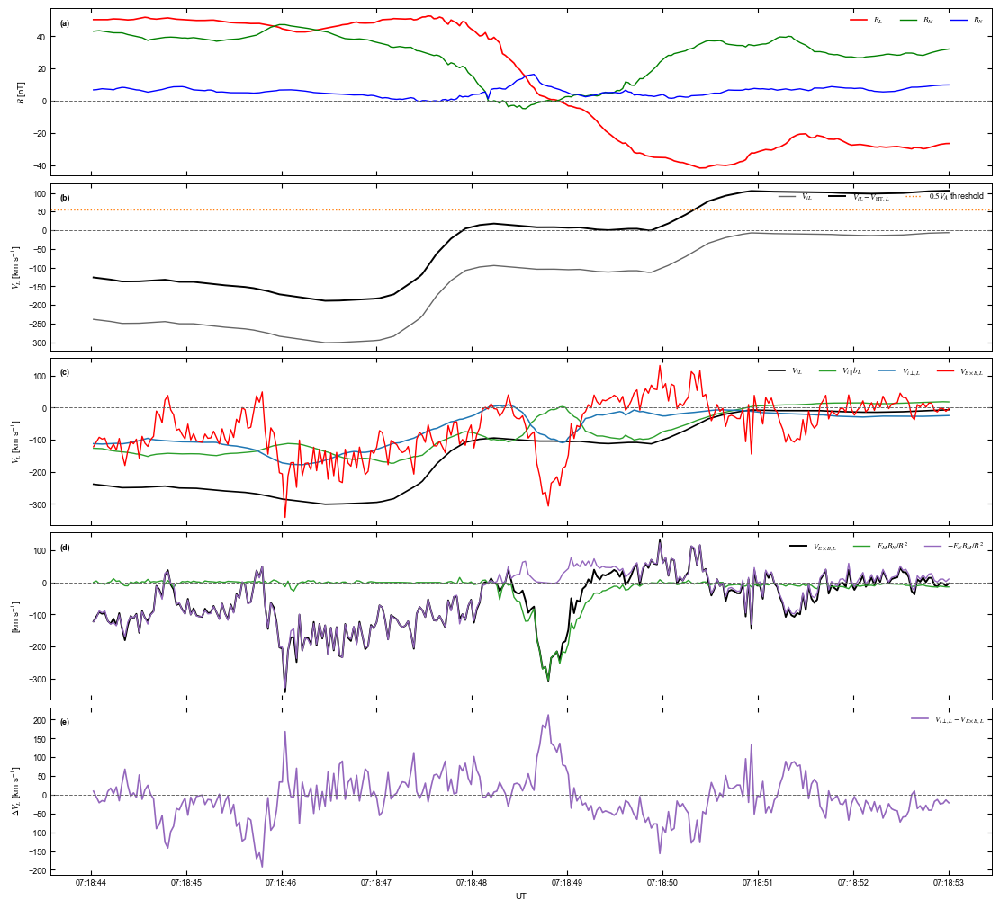

In [227]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ============================================================
# USER SETTINGS
# ============================================================

sc = "mms4"

# L component of the deHoffmann-Teller/boundary velocity [km/s]
VHT_L = -112.3

# Reference Alfvén/outflow speed [km/s]
# Prefer the asymmetric predicted outflow speed if available.
VA_REF = 109.0

# Preliminary positive-jet threshold
JET_FRACTION = 0.5
JET_THRESHOLD = JET_FRACTION * VA_REF

# Require at least this many consecutive ion samples
MIN_SAMPLES = 3

# Optional plotting interval
t_start = del3
t_stop = del4


# ============================================================
# LOAD AND ALIGN THE DATA
# ============================================================

ds = hall[sc]

# Use the ion cadence as the common time base.
Vi = ds["lmn_vi"].sel(time=slice(t_start, t_stop))
Vi = Vi.dropna(dim="time", how="all")

time = Vi.time

# Interpolate B and E onto the ion measurement times.
B = ds["lmn_b"].sel(time=slice(t_start, t_stop)).interp(time=time)
E = ds["lmn_e"].sel(time=slice(t_start, t_stop)).interp(time=time)

# Remove times where any required vector is unavailable.
valid = (
    np.isfinite(Vi).all("LMN")
    & np.isfinite(B).all("LMN")
    & np.isfinite(E).all("LMN")
)

Vi = Vi.where(valid, drop=True)
B = B.interp(time=Vi.time)
E = E.interp(time=Vi.time)
time = Vi.time


# ============================================================
# LMN COMPONENTS
# ============================================================

ViL = Vi.sel(LMN=0)
ViM = Vi.sel(LMN=1)
ViN = Vi.sel(LMN=2)

BL = B.sel(LMN=0)
BM = B.sel(LMN=1)       # total measured BM, not Delta BM
BN = B.sel(LMN=2)

EL = E.sel(LMN=0)
EM = E.sel(LMN=1)
EN = E.sel(LMN=2)

Bmag = np.sqrt((B**2).sum("LMN"))
B2 = Bmag**2
bhat = B / Bmag

bL = bhat.sel(LMN=0)
bM = bhat.sel(LMN=1)
bN = bhat.sel(LMN=2)


# ============================================================
# ION PARALLEL AND PERPENDICULAR VELOCITIES
# ============================================================

# Scalar ion velocity parallel to B.
Vi_parallel = xr.dot(Vi, bhat, dim="LMN")

# Parallel velocity vector.
Vi_parallel_vector = Vi_parallel * bhat

# Perpendicular velocity vector.
Vi_perp_vector = Vi - Vi_parallel_vector

# L-directed components.
Vi_parallel_L = Vi_parallel_vector.sel(LMN=0)
Vi_perp_L = Vi_perp_vector.sel(LMN=0)

# Check reconstruction:
# ViL should equal Vi_parallel_L + Vi_perp_L.
reconstruction_error = (
    ViL - Vi_parallel_L - Vi_perp_L
)

print(
    "Maximum velocity reconstruction error:",
    float(np.nanmax(np.abs(reconstruction_error.values))),
    "km/s"
)


# ============================================================
# E x B DRIFT AND ITS TWO L-DIRECTED CONTRIBUTIONS
#
# VExB,L = (EM*BN - EN*BM)/B^2
#
# With E in mV/m and B in nT, multiply by 1e3
# to obtain km/s.
# ============================================================

VExB_L_EMBN = 1e3 * EM * BN / B2
VExB_L_ENBM = -1e3 * EN * BM / B2

VExB_L = VExB_L_EMBN + VExB_L_ENBM

# Verify against the ExB value stored in hall, if available.
if "ExB" in ds:
    VExB_stored = (
        ds["ExB"]
        .sel(LMN=0, time=slice(t_start, t_stop))
        .interp(time=time)
    )

    exb_error = VExB_stored - VExB_L

    print(
        "Maximum stored/recalculated ExB difference:",
        float(np.nanmax(np.abs(exb_error.values))),
        "km/s"
    )


# ============================================================
# ION VELOCITY IN THE HT/BOUNDARY FRAME
# ============================================================

ViL_HT = ViL - VHT_L

# This is a diagnostic of perpendicular ion-field slippage
# in the spacecraft frame.
ion_slippage_L = Vi_perp_L - VExB_L


# ============================================================
# POSITIVE-JET SCREENING TEST
# ============================================================

# Basic conditions:
positive_total_flow = ViL_HT > JET_THRESHOLD
positive_perp_flow = Vi_perp_L > 0
positive_exb = VExB_L > 0

# A preliminary positive-exhaust candidate requires all three.
candidate_mask = (
    positive_total_flow
    & positive_perp_flow
    & positive_exb
)

candidate_values = np.asarray(
    candidate_mask.fillna(False).values,
    dtype=bool
)


# ============================================================
# FIND SUSTAINED CANDIDATE INTERVALS
# ============================================================

def find_sustained_intervals(mask, times, min_samples=3):
    """
    Return contiguous True intervals containing at least
    min_samples consecutive measurements.
    """

    mask = np.asarray(mask, dtype=bool)
    times = np.asarray(times)

    padded = np.r_[False, mask, False]
    changes = np.diff(padded.astype(int))

    starts = np.where(changes == 1)[0]
    stops = np.where(changes == -1)[0]

    intervals = []

    for start, stop in zip(starts, stops):
        number_of_samples = stop - start

        if number_of_samples >= min_samples:
            intervals.append({
                "start_index": start,
                "stop_index": stop - 1,
                "start": times[start],
                "stop": times[stop - 1],
                "samples": number_of_samples
            })

    return intervals


candidate_intervals = find_sustained_intervals(
    candidate_values,
    time.values,
    min_samples=MIN_SAMPLES
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("\nPositive-jet screening threshold:")
print(f"ViL_HT > {JET_THRESHOLD:.1f} km/s")
print(f"Minimum consecutive samples = {MIN_SAMPLES}")

if len(candidate_intervals) == 0:
    print("\nNo sustained positive-ion-jet candidate was identified.")

else:
    print("\nSustained positive-ion-jet candidate intervals:")

    for number, interval in enumerate(candidate_intervals, start=1):
        i0 = interval["start_index"]
        i1 = interval["stop_index"] + 1

        mean_ViL_HT = float(
            ViL_HT.isel(time=slice(i0, i1)).mean()
        )

        mean_Viperp = float(
            Vi_perp_L.isel(time=slice(i0, i1)).mean()
        )

        mean_VExB = float(
            VExB_L.isel(time=slice(i0, i1)).mean()
        )

        print(
            f"\nCandidate {number}:"
            f"\n  Start: {interval['start']}"
            f"\n  Stop:  {interval['stop']}"
            f"\n  Samples: {interval['samples']}"
            f"\n  Mean ViL_HT:    {mean_ViL_HT:.1f} km/s"
            f"\n  Mean Vi_perp,L: {mean_Viperp:.1f} km/s"
            f"\n  Mean VExB,L:    {mean_VExB:.1f} km/s"
        )


# ============================================================
# PLOT THE DIAGNOSTIC PANELS
# ============================================================

fig, axs = plt.subplots(
    5, 1,
    figsize=(11, 10),
    sharex=True,
    constrained_layout=True
)

# ------------------------------------------------------------
# Panel 1: magnetic topology
# ------------------------------------------------------------

axs[0].plot(time, BL, color="red", lw=1.2, label=r"$B_L$")
axs[0].plot(time, BM, color="green", lw=1.0, label=r"$B_M$")
axs[0].plot(time, BN, color="blue", lw=1.0, label=r"$B_N$")

axs[0].axhline(0, color="0.4", ls="--", lw=0.7)
axs[0].set_ylabel(r"$B$ [nT]")
axs[0].legend(frameon=False, ncol=3, loc="upper right")
axs[0].text(
    0.01, 0.90, "(a)",
    transform=axs[0].transAxes,
    fontweight="bold"
)

# ------------------------------------------------------------
# Panel 2: total ion flow in spacecraft and HT frames
# ------------------------------------------------------------

axs[1].plot(
    time, ViL,
    color="0.4", lw=1.0,
    label=r"$V_{iL}$"
)

axs[1].plot(
    time, ViL_HT,
    color="black", lw=1.4,
    label=r"$V_{iL}-V_{\mathrm{HT},L}$"
)

axs[1].axhline(
    0,
    color="0.4",
    ls="--",
    lw=0.7
)

axs[1].axhline(
    JET_THRESHOLD,
    color="tab:orange",
    ls=":",
    lw=1.0,
    label=rf"${JET_FRACTION:.1f}V_A$ threshold"
)

axs[1].set_ylabel(r"$V_L$ [km s$^{-1}$]")
axs[1].legend(frameon=False, ncol=3, loc="upper right")
axs[1].text(
    0.01, 0.90, "(b)",
    transform=axs[1].transAxes,
    fontweight="bold"
)

# ------------------------------------------------------------
# Panel 3: parallel, perpendicular, and ExB components
# ------------------------------------------------------------

axs[2].plot(
    time, ViL,
    color="black", lw=1.2,
    label=r"$V_{iL}$"
)

axs[2].plot(
    time, Vi_parallel_L,
    color="tab:green", lw=1.0,
    label=r"$V_{i\parallel}b_L$"
)

axs[2].plot(
    time, Vi_perp_L,
    color="tab:blue", lw=1.1,
    label=r"$V_{i\perp,L}$"
)

axs[2].plot(
    time, VExB_L,
    color="red", lw=1.0,
    label=r"$V_{E\times B,L}$"
)

axs[2].axhline(0, color="0.4", ls="--", lw=0.7)
axs[2].set_ylabel(r"$V_L$ [km s$^{-1}$]")
axs[2].legend(frameon=False, ncol=4, loc="upper right")
axs[2].text(
    0.01, 0.90, "(c)",
    transform=axs[2].transAxes,
    fontweight="bold"
)

# ------------------------------------------------------------
# Panel 4: origin of the positive ExB drift
# ------------------------------------------------------------

axs[3].plot(
    time, VExB_L,
    color="black", lw=1.4,
    label=r"$V_{E\times B,L}$"
)

axs[3].plot(
    time, VExB_L_EMBN,
    color="tab:green", lw=1.0,
    label=r"$E_MB_N/B^2$"
)

axs[3].plot(
    time, VExB_L_ENBM,
    color="tab:purple", lw=1.0,
    label=r"$-E_NB_M/B^2$"
)

axs[3].axhline(0, color="0.4", ls="--", lw=0.7)
axs[3].set_ylabel(r"[km s$^{-1}$]")
axs[3].legend(frameon=False, ncol=3, loc="upper right")
axs[3].text(
    0.01, 0.90, "(d)",
    transform=axs[3].transAxes,
    fontweight="bold"
)

# ------------------------------------------------------------
# Panel 5: perpendicular ion-field slippage
# ------------------------------------------------------------

axs[4].plot(
    time, ion_slippage_L,
    color="tab:purple", lw=1.2,
    label=r"$V_{i\perp,L}-V_{E\times B,L}$"
)

axs[4].axhline(0, color="0.4", ls="--", lw=0.7)
axs[4].set_ylabel(r"$\Delta V_L$ [km s$^{-1}$]")
axs[4].set_xlabel("UT")
axs[4].legend(frameon=False, loc="upper right")
axs[4].text(
    0.01, 0.90, "(e)",
    transform=axs[4].transAxes,
    fontweight="bold"
)


# ============================================================
# SHADE SUSTAINED POSITIVE-JET CANDIDATES
# ============================================================

for interval in candidate_intervals:
    for ax in axs:
        ax.axvspan(
            interval["start"],
            interval["stop"],
            color="gold",
            alpha=0.25,
            lw=0
        )


# ============================================================
# COMMON FORMATTING
# ============================================================

for ax in axs:
    ax.grid(False)
    ax.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True
    )

axs[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M:%S")
)

plt.show()

Plotting for MMS4...


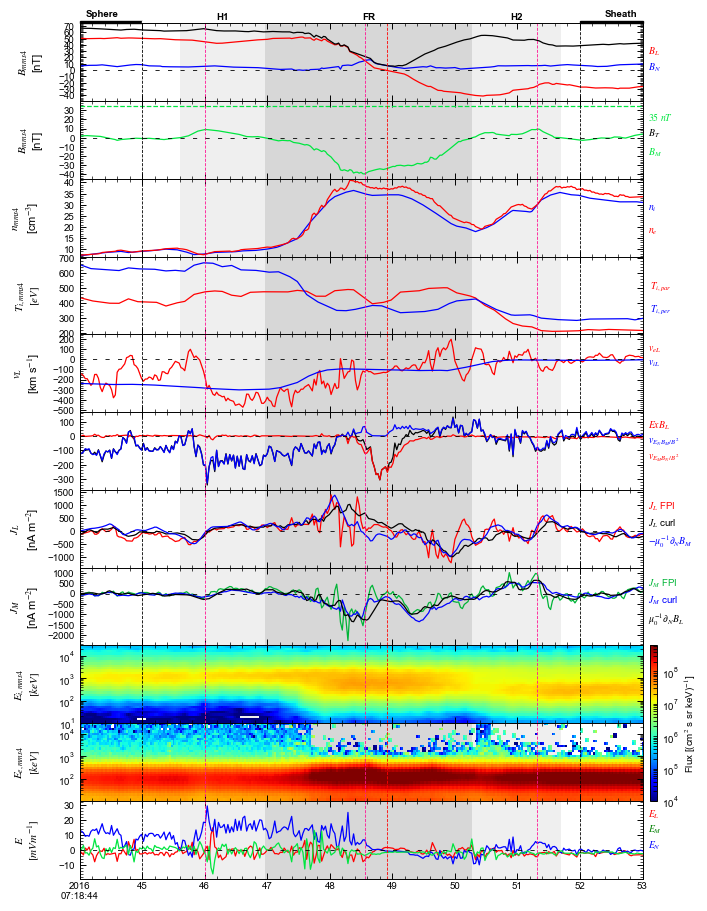

In [228]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
import xarray as xr

# -----------------------------
# Matplotlib performance tweaks
# -----------------------------
mpl.rcParams["path.simplify"] = True
mpl.rcParams["path.simplify_threshold"] = 0.5

# GRL full-width dimensions and final-size typography
GRL_WIDTH = 7.08       # inches (about 180 mm)
GRL_HEIGHT = 9.20      # full-page 11-panel figure
FS_LABEL = 8.0
FS_TICK = 7.0
FS_TEXT = 7.0
FS_PANEL = 8.0
FS_CBAR = 7.0
DATA_LW = 0.9         # identical width for every scientific data curve
GUIDE_LW = 0.6        # thinner zero lines and vertical reference markers

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": FS_TEXT,
    "axes.labelsize": FS_LABEL,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_TEXT,
    "axes.linewidth": 0.7,
    "lines.linewidth": 0.9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =============================
# âœ… Extract spacecraft: MMS3
# =============================
sc = "mms4"
sc_list = [sc]

for sc in sc_list:
    print(f"Plotting for {sc.upper()}...")

    # --- times (make sure these exist BEFORE you use them)
    t1 = times_dict[sc][0]
    t2 = times_dict[sc][1]

    # --- per-spacecraft Bl
    Bl_dict = {
        sc_: find(hall[sc_].lmn_b, LMN=0, d1=del3, d2=del4)[0]
        for sc_ in sc_list
    }
    Bl = Bl_dict[sc]

    # âœ… background guide field for this spacecraft
    B_g = df_all.loc[sc, '$B_g$']  # df_all indexed by sc

    # --- main fields
    # B_hm retains the LMN structure expected by find(), but only its M
    # component is converted to the Hall perturbation B_M' = B_M - B_g.
    B_hm = hall[sc].lmn_b.sel(time=slice(del3, del4)).copy()
    B_hm.loc[dict(LMN=1)] = (
        B_hm.sel(LMN=1) - res_all[sc]['Bg_linear']
    )

    bn = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=2)
    bl = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=0)
    bm_total = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=1)
    B_magnitude = np.sqrt(bl**2 + bm_total**2 + bn**2)

    # -----------------------------------------
    # Locate features
    # -----------------------------------------
    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values)
    )
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values)
    )
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values)
    )

    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]

    # ============================================================
    # Subplots: NOW 11 PANELS (added ion temperature)
    # ============================================================
    fig, axs = plt.subplots(
        11, 1,
        figsize=(GRL_WIDTH, GRL_HEIGHT),
        sharex=True,
        gridspec_kw={"hspace": 0}
    )

    axs[0].plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=2), c="b", lw=1)
    axs[0].plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=0), c="r", lw=1)
    axs[0].set_ylabel(r"$\mathit{B_{%s}}$" % sc + "\n[nT]", fontsize=14)
    axs[0].annotate(r"$\mathit{B_L}$", xy=(1.01, 0.6), xycoords="axes fraction",
                    fontsize=14, color="r", style="italic")
    axs[0].annotate(r"$\mathit{B_N}$", xy=(1.01, 0.4), xycoords="axes fraction",
                    fontsize=14, color="b", style="italic")

    # --------------------------
    # axs[1]: B_M + |B|
    # --------------------------
    axs[1].plot(B_hm.time, B_hm.sel(LMN=1,time=slice(del3, del4)), c=(0/255, 230/255, 64/255), lw=1)
    axs[0].plot(hall[sc].lmn_b.time.sel(time=slice(del3, del4)),
                B_magnitude.sel(time=slice(del3, del4)), lw=1, c="k")
    axs[1].axhline(y=B_g, c=(0/255, 230/255, 64/255), ls="--", lw=1)
    axs[1].set_ylabel(r"$\mathit{B_{%s}}$" % sc + "\n[nT]", fontsize=14)
    axs[1].annotate(r"$\mathit{B_T}$", xy=(1.01, 0.55), xycoords="axes fraction",
                    fontsize=14, color="k", style="italic")
    axs[1].annotate(r"$\mathit{35\ nT}$", xy=(1.01, 0.75), xycoords="axes fraction",
                    fontsize=14, color=(0/255, 230/255, 64/255), style="italic")
    axs[1].annotate(r"$\mathit{B_M}$", xy=(1.01, 0.3), xycoords="axes fraction",
                    fontsize=14, color=(0/255, 230/255, 64/255), style="italic")

    # --------------------------
    # axs[2]: densities
    # --------------------------
    axs[2].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"].sel(time=slice(del3, del4)),
                c="b", lw=1)
    axs[2].plot(edatasets_interp[sc].time.sel(time=slice(del3, del4)),
                edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4)),
                c="r", lw=1)
    axs[2].set_ylabel(r"$\mathit{n_{%s}}$" % sc + "\n[cm$^{-3}$]", fontsize=14)

    axs[2].annotate(r"$n_i$", xy=(1.01, 0.6), xycoords="axes fraction",
                    fontsize=14, color="b", style="italic")
    axs[2].annotate(r"$n_e$", xy=(1.01, 0.3), xycoords="axes fraction",
                    fontsize=14, color="r", style="italic")

    axs[2].set_ylim(
        np.min(edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4))),
        np.max(edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4)))
    )

    # (keep your BN outside calc if you need it elsewhere)
    BN_left = hall[sc].lmn_b.sel(LMN=2, time=slice(del3, th_0)).mean("time")
    BN_right = hall[sc].lmn_b.sel(LMN=2, time=slice(th_1, del4)).mean("time")
    BN_outside = 0.5 * (BN_left + BN_right)

    # ============================================================
    # axs[3]: Ion Temperature
    # ============================================================
    axs[3].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4)),
                c='r', lw=1, label='Ti,par')
    axs[3].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=slice(del3, del4)),
                c='b', lw=1, label='Ti,per')

    axs[3].annotate(r'$\mathit{T_{i,par}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    style='italic', fontsize=14, color='r', xytext=(1, -1),
                    textcoords='offset points')
    axs[3].annotate(r'$\mathit{T_{i,per}}$', xy=(1.01, 0.3), xycoords='axes fraction',
                    style='italic', fontsize=14, color='b', xytext=(1, -1),
                    textcoords='offset points')

    axs[3].set_ylabel(r"$\mathbf{\mathit{T_{i,%s}}}$" % sc + '\n' + r"$[\mathit{eV}]$",
                      fontsize=14)

    axs[3].set_ylim(
        np.round(np.min(idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4))), -2),
        np.round(np.max(idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=slice(del3, del4))), -2)
    )

    # ============================================================
    # axs[9]: Electron spectrogram (panel 10)
    # ============================================================
    e_da = edatasets_interp[sc][f"{sc}_des_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    e_time = e_da.time.values
    e_energy = e_da.spec_bins.mean("time", skipna=True).values
    e_flux = e_da.transpose("e_dim", "time").values
    e_flux = np.where(np.isfinite(e_flux) & (e_flux > 0), e_flux, np.nan)

    specgram = axs[9].pcolormesh(
        e_time, e_energy, e_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True,
        shading="auto"
    )
    axs[9].set_ylabel(r"$\mathbf{\mathit{E_{e,%s}}}$" % sc + "\n" + r"$\mathit{[keV]}$", fontsize=14)
    axs[9].set_yscale("log")

    # ============================================================
    # axs[8]: Ion spectrogram (panel 9)
    # ============================================================
    i_da = idatasets_interp[sc][f"{sc}_dis_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    i_time = i_da.time.values
    i_energy = i_da.spec_bins.mean("time", skipna=True).values
    i_flux = i_da.transpose("e_dim", "time").values
    i_flux = np.where(np.isfinite(i_flux) & (i_flux > 0), i_flux, np.nan)

    pcmi = axs[8].pcolormesh(
        i_time, i_energy, i_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True,
        shading="auto"
    )
    axs[8].set_ylabel(r"$\mathbf{\mathit{E_{i,%s}}}$" % sc + "\n" + r"$\mathit{[keV]}$", fontsize=14)
    axs[8].set_yscale("log")

    # The shared spectrogram colorbar is added after subplot margins are fixed.

    
    # ============================================================
    # axs[4]: ExB_L and viL (panel 5)
    # ============================================================
    #axs[4].plot(hall[sc].ExB.time.sel(time=slice(del3, del4)),
     #           hall[sc].ExB.sel(LMN=0, time=slice(del3, del4)),
      #          c="r", lw=1)
    axs[4].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
                hall[sc].lmn_ve.sel(LMN=0, time=slice(del3, del4)),
                c="r", lw=1)
    axs[4].plot(hall[sc].lmn_vi.time.sel(time=slice(del3, del4)),
                hall[sc].lmn_vi.sel(LMN=0, time=slice(del3, del4)),
                c="b", lw=1)
   

    #axs[4].plot(
     #   time, VExB_L_ENBM,
     #   color="tab:purple", lw=1.0,
     #   label=r"$-E_NB_M/B^2$"
   # )
    axs[4].set_ylabel(r"$v_L$" + "\n" + r"[km s$^{-1}$]", fontsize=FS_LABEL)
    axs[4].annotate(r'$v_{eL}$', xy=(1.01, 0.78), xycoords='axes fraction',
                    fontsize=FS_TEXT, color='r', style='italic')
   
    axs[4].annotate(r'$\mathit{v_{iL}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=14, color='b', style='italic')

    # ============================================================
    # axs[5]: ve (panel 6)
    # ============================================================
    #axs[5].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
     #           hall[sc].lmn_ve.sel(LMN=0, time=slice(del3, del4)),
    #            c="r", lw=1)
    #axs[5].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
     #           hall[sc].lmn_ve.sel(LMN=1, time=slice(del3, del4)),
      #          c=(0/255, 230/255, 64/255), lw=1)
    #axs[5].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
      #          hall[sc].lmn_ve.sel(LMN=2, time=slice(del3, del4)),
      #          c="b", lw=1)
    # Decompose (E x B)_L = (E_M B_N - E_N B_M)/B^2.
    # E[mV/m]/B[nT] directly gives km/s.
    exb = hall[sc].ExB.sel(time=slice(del3, del4))
    e_lmn = hall[sc].lmn_e.sel(time=slice(del3, del4)).interp(time=exb.time)
    b_lmn = hall[sc].lmn_b.sel(time=slice(del3, del4)).interp(time=exb.time)
    b2 = (b_lmn**2).sum("LMN")
    VExB_L_EMBN = e_lmn.sel(LMN=1) * b_lmn.sel(LMN=2) * 1e3 / b2
    VExB_L_ENBM = -e_lmn.sel(LMN=2) * b_lmn.sel(LMN=1) * 1e3 / b2

    axs[5].plot(exb.time,
                exb.sel(LMN=0),
                c="k", lw=1)
    axs[5].plot(
        exb.time, VExB_L_EMBN,
        color="r", lw=1.0,
        label=r"$E_MB_N/B^2$"
    )
    axs[5].plot(
        exb.time, VExB_L_ENBM,
        color="b", lw=1.0,
        label=r"$-E_NB_M/B^2$"
    )
    
    axs[5].annotate(r'$\mathit{ExB}_L$', xy=(1.01, 0.8), xycoords='axes fraction',
                    fontsize=14, color='r', style='italic')
    axs[5].annotate(r'$\mathit{v_{E_NB_M/B^2}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                    fontsize=14, color='b', style='italic')
    axs[5].annotate(r'$\mathit{v_{E_MB_N/B^2}}$', xy=(1.01, 0.4), xycoords='axes fraction',
                    fontsize=14, color='r', style='italic')

    # ============================================================
    # axs[6] and axs[7]: Ampere-law current comparisons
    # Locally 1-D current sheet:
    #   J_L = -(1/mu0) dB_M/dN
    #   J_M = +(1/mu0) dB_L/dN
    # with d/dN = (1/V_N)d/dt.
    # ============================================================
    mu0 = 4.0 * np.pi * 1e-7       # H/m
    VN = 46.8 * 1e3                 # signed structure speed, m/s
    smooth_samples = 7

    B_current = hall[sc].lmn_b.sel(time=slice(del3, del4))
    BL = B_current.sel(LMN=0)
    BM = B_current.sel(LMN=1)

    time_s = (
        B_current.time.values.astype("datetime64[ns]").astype(np.int64)
        - B_current.time.values[0].astype("datetime64[ns]").astype(np.int64)
    ) * 1e-9

    BL_smooth = BL.rolling(time=smooth_samples, center=True,
                           min_periods=1).mean()
    BM_smooth = BM.rolling(time=smooth_samples, center=True,
                           min_periods=1).mean()

    dBL_dt = np.gradient(np.asarray(BL_smooth.values), time_s)
    dBM_dt = np.gradient(np.asarray(BM_smooth.values), time_s)

    # B is in nT. The factors 1e-9 and 1e9 convert nT -> T and
    # A m^-2 -> nA m^-2, respectively.
    JL_ampere_values = -(dBM_dt * 1e-9 / VN) / mu0 * 1e9
    JM_ampere_values = +(dBL_dt * 1e-9 / VN) / mu0 * 1e9

    JL_ampere = xr.DataArray(
        JL_ampere_values, coords={"time": B_current.time}, dims=["time"],
        name="JL_ampere", attrs={"units": "nA m^-2"}
    )
    JM_ampere = xr.DataArray(
        JM_ampere_values, coords={"time": B_current.time}, dims=["time"],
        name="JM_ampere", attrs={"units": "nA m^-2"}
    )
    hall[sc]["JL_ampere"] = JL_ampere
    hall[sc]["JM_ampere"] = JM_ampere

    JL_FPI = hall[sc].lmn_j.sel(LMN=0, time=slice(del3, del4))
    JL_FGM = hall[sc].fgm_j.sel(LMN=0, time=slice(del3, del4))
    JM_FPI = hall[sc].lmn_j.sel(LMN=1, time=slice(del3, del4))
    JM_FGM = hall[sc].fgm_j.sel(LMN=1, time=slice(del3, del4))

    # Panel 7: J_L
    axs[6].plot(JL_FPI.time, JL_FPI, c="r", label=r"$J_L$ FPI")
    axs[6].plot(JL_FGM.time, JL_FGM, c="k", label=r"$J_L$ curlometer")
    axs[6].plot(JL_ampere.time, JL_ampere, c="b",
                label=r"$-\mu_0^{-1}\partial B_M/\partial N$")
    axs[6].set_ylabel(r"$J_L$" + "\n" + r"[nA m$^{-2}$]",
                      fontsize=FS_LABEL)
    axs[6].annotate(r"$J_L$ FPI", xy=(1.01, 0.76),
                    xycoords="axes fraction", color="r")
    axs[6].annotate(r"$J_L$ curl", xy=(1.01, 0.54),
                    xycoords="axes fraction", color="k")
    axs[6].annotate(r"$-\mu_0^{-1}\partial_N B_M$", xy=(1.01, 0.30),
                    xycoords="axes fraction", color="b")

    # Panel 8: J_M -- same calculation, using +dB_L/dN
    axs[7].plot(JM_FPI.time, JM_FPI, c=(0/255, 180/255, 55/255),
                label=r"$J_M$ FPI")
    axs[7].plot(JM_FGM.time, JM_FGM, c="b",
                label=r"$J_M$ curlometer")
    axs[7].plot(JM_ampere.time, JM_ampere, c="k",
                label=r"$\mu_0^{-1}\partial B_L/\partial N$")
    axs[7].set_ylabel(r"$J_M$" + "\n" + r"[nA m$^{-2}$]",
                      fontsize=FS_LABEL)
    axs[7].annotate(r"$J_M$ FPI", xy=(1.01, 0.76),
                    xycoords="axes fraction", color=(0/255, 180/255, 55/255))
    axs[7].annotate(r"$J_M$ curl", xy=(1.01, 0.54),
                    xycoords="axes fraction", color="b")
    axs[7].annotate(r"$\mu_0^{-1}\partial_N B_L$", xy=(1.01, 0.30),
                    xycoords="axes fraction", color="k")

    # =======================
    # 11: E field (was axs[9])
    # =======================
    axs[10].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=0, time=slice(del3, del4)), c='r', lw=1)
    axs[10].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=2, time=slice(del3, del4)), c='b', lw=1)
    axs[10].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=1, time=slice(del3, del4)), c=(0/255, 230/255, 64/255), lw=1)
    axs[10].set_ylabel(r'$\mathbf{\mathit{E}}$'  + '\n' + r'$\mathit{[mV m^{-1}]}$', fontsize=12)
    axs[10].annotate(r'$\mathit{E_{L}}$', xy=(1.01, 0.8), xycoords='axes fraction',
                     fontsize=14, color='r', style='italic')
    axs[10].annotate(r'$\mathit{E_{M}}$', xy=(1.01, 0.6), xycoords='axes fraction',
                     fontsize=14, color='g', style='italic')
    axs[10].annotate(r'$\mathit{E_{N}}$', xy=(1.01, 0.4), xycoords='axes fraction',
                     fontsize=14, color='b', style='italic')
    # ============================================================
    # centers of each span
    # ============================================================
    x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
    x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
    x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
    x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

    xc_h1 = x1 + (x2 - x1) / 2
    xc_fr = x2 + (x3 - x2) / 2
    xc_h2 = x3 + (x4 - x3) / 2

    axs[0].text(xc_h1, 1.02, "H1",
                transform=axs[0].get_xaxis_transform(),
                ha="center", va="bottom", fontsize=14,fontweight="bold")

    axs[0].text(xc_fr, 1.02, "FR",
                transform=axs[0].get_xaxis_transform(),
                ha="center", va="bottom", fontsize=14,fontweight="bold")

    axs[0].text(xc_h2, 1.02, "H2",
                transform=axs[0].get_xaxis_transform(),
                ha="center", va="bottom", fontsize=14,fontweight="bold")
    axs[0].text(0.01, 1.06, "Sphere",transform=axs[0].transAxes,
                ha="left", va="bottom", fontsize=14, fontweight="bold")

    axs[0].text(0.99, 1.06, "Sheath",transform=axs[0].transAxes,
                ha="right", va="bottom",fontsize=14, fontweight="bold")
    # ============================================================
    # Shared styling (vertical markers, ticks, spans)
    # ============================================================
    for ax in axs:
        # Normalize all curves already plotted on this panel. This overrides
        # earlier explicit lw=1, 1.2, and 1.5 settings consistently.
        for data_line in ax.lines:
            data_line.set_linewidth(DATA_LW)

        ax.set_xlim(
            hall[sc].lmn_b.time.sel(time=del3, method="nearest"),
            hall[sc].lmn_b.time.sel(time=del4, method="nearest")
        )

        ax.axvline(x=Bl.values, ls="--", c="r", lw=GUIDE_LW)
        ax.axvline(x=th_maxl.values, ls="--", c='#FF1493', lw=GUIDE_LW)
        ax.axvline(x=th_min.values, ls="--", c='#FF1493', lw=GUIDE_LW)
        ax.axvline(x=th_maxr.values, ls="--", c='#FF1493', lw=GUIDE_LW)

        ax.set_xticks(xticks(del3, del4)[0])
        ax.set_xticks(xticks(del3, del4)[1], minor=True)
        ax.set_xticklabels(xticks(del3, del4)[2], rotation=0, fontsize=FS_TICK)

        ax.axhline(y=0, c="k", ls=(0, (5, 10)), lw=GUIDE_LW)

        ax.tick_params(axis="x", which="major", pad=2, width=0.7, length=4, labelsize=FS_TICK,
                       direction="in", top=True, bottom=True)
        ax.tick_params(axis="x", which="minor", pad=2, width=0.5, length=2.5, labelsize=FS_TICK,
                       direction="in", top=True, bottom=True)

        from matplotlib.ticker import AutoMinorLocator, MaxNLocator

# --------------------------------------------------
# Y-axis ticks: linear only, not log scale
# tight limits around actual plotted values
# automatic clean major ticks
# 10 minor subdivisions between major ticks
# --------------------------------------------------
        if ax.get_yscale() != "log":
            ymin, ymax = ax.get_ylim()
            data_min, data_max = sorted((ymin, ymax))
            data_range = data_max - data_min

    # small padding
            pad = 0.02 * data_range if data_range > 0 else 0.5
            ylow = data_min - pad
            yhigh = data_max + pad
            span = yhigh - ylow

    # allowed major tick steps
            allowed_steps = np.array([2, 5, 10, 50, 100, 500, 1000], dtype=float)

    # choose a step that gives about 5â€“7 major intervals
            target_step = span / 6.0
            major_step = allowed_steps[np.argmin(np.abs(allowed_steps - target_step))]

            ax.set_ylim(ylow, yhigh)
            ax.yaxis.set_major_locator(MultipleLocator(major_step))
            ax.yaxis.set_minor_locator(MultipleLocator(major_step / 5.0))
        
        ax.tick_params(axis="y", which="major", direction="in", left=True, right=True,
                       width=0.7, length=4, labelsize=FS_TICK)
        ax.tick_params(axis="y", which="minor", direction="in", left=True, right=True,
                       width=0.5, length=2.5, labelsize=FS_TICK)

        ax.yaxis.label.set_size(FS_LABEL)
        for text_object in ax.texts:
            text_object.set_fontsize(FS_TEXT)

        ax.grid(False)

        # vertical guide lines
        t = sorted([del3, t1, t2, del4])
        [ax.axvline(x, ls="--", c="k", lw=GUIDE_LW) for x in t]

        # main shaded region
        #ax.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.4)
        x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
        x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
        x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
        x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

        ax.axvspan(x1, x2, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)
        ax.axvspan(x2, x3, color='#BDBDBD', alpha=0.6, lw=0, zorder=0)
        ax.axvspan(x3, x4, color='#D9D9D9', alpha=0.4, lw=0, zorder=0)

    # Draw the three header segments once (not once per subplot).
    header_transform = axs[0].get_xaxis_transform()
    for i, color in enumerate("kwk"):
        axs[0].axvspan(
            t[i], t[i + 1], 1.00, 1.03,
            transform=header_transform, color=color, clip_on=False
        )

    plt.subplots_adjust(
        left=0.105,
        right=0.90,
        bottom=0.040,
        top=0.970,
        hspace=0
    )

    fig.align_ylabels(axs)

    # Shared colorbar, positioned only after the final axes geometry is known.
    fig.canvas.draw()
    posi4 = axs[8].get_position()
    posi5 = axs[9].get_position()
    cax = fig.add_axes([
        0.91,
        min(posi4.y0, posi5.y0),
        0.010,
        max(posi4.y1, posi5.y1) - min(posi4.y0, posi5.y0),
    ])
    cbar = fig.colorbar(pcmi, cax=cax)
    cbar.set_label(r"Flux [(cm$^2$ s sr keV)$^{-1}$]",
                   fontsize=FS_CBAR, labelpad=3)
    cbar.set_ticks(10 ** np.arange(4, 9))
    cbar.ax.tick_params(which="both", direction="in", labelsize=FS_CBAR,
                        width=0.6, length=3, labelcolor="black")
    # -----------------------------------------
    # Save
    # -----------------------------------------
    fig.savefig(
        os.path.join(output_folder, f"{taistarttime}_k_{sc}.png"),
        dpi=600,
        format="png",
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.015
    )
    
    fig.savefig(
        os.path.join(output_folder, f"{taistarttime}_k_{sc}_GRL.pdf"),
        format="pdf",
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.015
    )
    plt.show()


Plotting for MMS4...


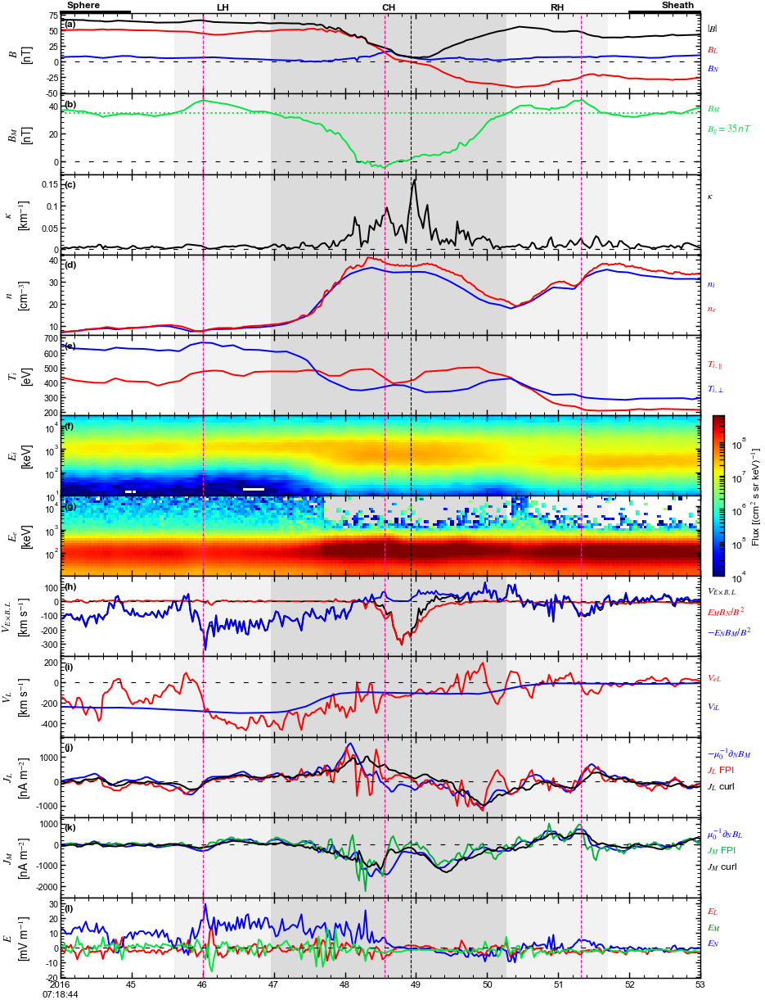

In [232]:
# ============================================================
# Overview figure – 12 panels (κ as panel c)
# Strictly optimised for GRL full-page (double-column)
# Width  ≤ 170 mm, Height ≤ 228 mm
# ============================================================
import os
import string
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
import xarray as xr

# -----------------------------
# GRL geometry & typography (strict)
# -----------------------------
GRL_WIDTH  = 6.69          # inches = 170 mm (hard maximum)
GRL_HEIGHT = 8.60          # inches ≈ 218 mm (safe under 228 mm)

FS_LABEL   = 6.5
FS_TICK    = 5.5
FS_YTICK   = 5.2
FS_TEXT    = 5.8
FS_PANEL   = 7.0
FS_CBAR    = 5.8
DATA_LW    = 0.95
GUIDE_LW   = 0.55

mpl.rcParams.update({
    "font.family"            : "Arial",
    "font.size"              : FS_TEXT,
    "axes.labelsize"         : FS_LABEL,
    "xtick.labelsize"        : FS_TICK,
    "ytick.labelsize"        : FS_TICK,
    "legend.fontsize"        : FS_TEXT,
    "axes.linewidth"         : 0.7,
    "lines.linewidth"        : DATA_LW,
    "xtick.major.width"      : 0.7,
    "ytick.major.width"      : 0.7,
    "xtick.minor.width"      : 0.5,
    "ytick.minor.width"      : 0.5,
    "xtick.direction"        : "in",
    "ytick.direction"        : "in",
    "xtick.top"              : True,
    "ytick.right"            : True,
    "pdf.fonttype"           : 42,
    "ps.fonttype"            : 42,
    "path.simplify"          : True,
    "path.simplify_threshold": 0.5,
    "figure.dpi"             : 150,
    "savefig.dpi"            : 600,
    "savefig.bbox"           : "tight",
    "savefig.pad_inches"     : 0.015,
})

# =============================
# Spacecraft
# =============================
sc = "mms4"
sc_list = [sc]

for sc in sc_list:
    print(f"Plotting for {sc.upper()}...")

    # --- times
    t1 = times_dict[sc][0]
    t2 = times_dict[sc][1]

    # --- Bl
    Bl_dict = {
        sc_: find(hall[sc_].lmn_b, LMN=0, d1=del3, d2=del4)[0]
        for sc_ in sc_list
    }
    Bl = Bl_dict[sc]

    # --- guide field
    B_g = df_all.loc[sc, '$B_g$']

    # --- magnetic field (guide-field corrected B_M)
    B_hm = hall[sc].lmn_b.sel(time=slice(del3, del4)).copy()
    B_hm.loc[dict(LMN=1)] = (
        B_hm.sel(LMN=1) - res_all[sc]['Bg_linear']
    )

    bn          = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=2)
    bl          = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=0)
    bm_total    = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=1)
    B_magnitude = np.sqrt(bl**2 + bm_total**2 + bn**2)

    # -----------------------------------------
    # Feature times
    # -----------------------------------------
    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values)
    )
    th_min  = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values)
    )
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values)
    )
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min,  d2=th_maxr)[0]

    # ============================================================
    # Curvature κ
    # ============================================================
    V_cross = -46.8          # km s⁻¹
    B_curv  = hall[sc].lmn_b.sel(time=slice(del3, del4))
    BL_c    = B_curv.sel(LMN=0)
    BM_c    = B_curv.sel(LMN=1)
    BN_c    = B_curv.sel(LMN=2)
    Bmag_c  = np.sqrt(BL_c**2 + BM_c**2 + BN_c**2)

    bL = BL_c / Bmag_c
    bM = BM_c / Bmag_c
    bN = BN_c / Bmag_c

    t_sec = (B_curv.time.values.astype("datetime64[ns]").astype(np.int64) * 1e-9)
    dbLdt = np.gradient(bL.values, t_sec)
    dbMdt = np.gradient(bM.values, t_sec)
    dbNdt = np.gradient(bN.values, t_sec)

    kappa = np.sqrt(dbLdt**2 + dbMdt**2 + dbNdt**2) / np.abs(V_cross)
    kappa_da = xr.DataArray(
        kappa,
        coords={"time": B_curv.time},
        dims=["time"],
        name="kappa",
        attrs={"units": "km^-1"},
    )

    # ============================================================
    # 12-panel figure
    # ============================================================
    master_fig = plt.figure(figsize=(GRL_WIDTH, GRL_HEIGHT), facecolor="white")
    overview_fig = master_fig
    fig = overview_fig

    axs = overview_fig.subplots(12, 1, sharex=True,
                                gridspec_kw={"hspace": 0.00})

    # ------------------------------------------------------------------
    # (a) B_L, B_N, |B|
    # ------------------------------------------------------------------
    axs[0].plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=2), c="b", lw=DATA_LW)
    axs[0].plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=0), c="r", lw=DATA_LW)
    axs[0].plot(hall[sc].lmn_b.time.sel(time=slice(del3, del4)),
                B_magnitude.sel(time=slice(del3, del4)), c="k", lw=DATA_LW)
    axs[0].set_ylabel(r"$B$" + "\n[nT]", fontsize=FS_LABEL)
    axs[0].annotate(r"$|B|$", xy=(1.01, 0.78), xycoords="axes fraction",
                    fontsize=FS_TEXT, color="k", style="italic")
    axs[0].annotate(r"$B_L$", xy=(1.01, 0.52), xycoords="axes fraction",
                    fontsize=FS_TEXT, color="r", style="italic")
    axs[0].annotate(r"$B_N$", xy=(1.01, 0.28), xycoords="axes fraction",
                    fontsize=FS_TEXT, color="b", style="italic")

    # ------------------------------------------------------------------
    # (b) B_M (total) and B_g
    # ------------------------------------------------------------------
    axs[1].plot(B_hm.time, B_hm.sel(LMN=1) + B_g,
                c=(0/255, 230/255, 64/255), lw=DATA_LW)
    axs[1].axhline(y=B_g, c=(0/255, 230/255, 64/255), ls=":", lw=GUIDE_LW)
    axs[1].set_ylabel(r"$B_M$" + "\n[nT]", fontsize=FS_LABEL)
    axs[1].annotate(r"$B_M$",  xy=(1.01, 0.78), xycoords="axes fraction",
                    fontsize=FS_TEXT, color=(0/255, 230/255, 64/255), style="italic")
    axs[1].annotate(r"$B_g=35\,$nT", xy=(1.01, 0.52), xycoords="axes fraction",
                    fontsize=FS_TEXT, color=(0/255, 230/255, 64/255), style="italic")

    # ------------------------------------------------------------------
    # (c) Field-line curvature κ
    # ------------------------------------------------------------------
    axs[2].plot(kappa_da.time, kappa_da, c="k", lw=DATA_LW)
    axs[2].set_ylabel(r"$\kappa$" + "\n" + r"[km$^{-1}$]", fontsize=FS_LABEL)
    axs[2].annotate(r"$\kappa$", xy=(1.01, 0.70), xycoords="axes fraction",
                    fontsize=FS_TEXT, color="k", style="italic")

    kappa_vals = kappa_da.values
    kappa_min  = np.nanmin(kappa_vals)
    kappa_max  = np.nanmax(kappa_vals)
    kappa_pad  = 0.08 * (kappa_max - kappa_min) if kappa_max > kappa_min else 0.01
    axs[2].set_ylim(kappa_min - kappa_pad, kappa_max + kappa_pad)
    span = (kappa_max + kappa_pad) - (kappa_min - kappa_pad)
    candidates = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05,
                           0.1, 0.2, 0.5, 1.0, 2.0, 5.0])
    major_step = float(candidates[np.argmin(np.abs(candidates - span / 4.0))])
    axs[2].yaxis.set_major_locator(MultipleLocator(major_step))
    axs[2].yaxis.set_minor_locator(MultipleLocator(major_step / 5.0))
    axs[2].yaxis.set_major_formatter(FormatStrFormatter("%.3g"))

    # ------------------------------------------------------------------
    # (d) densities
    # ------------------------------------------------------------------
    axs[3].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"].sel(time=slice(del3, del4)),
                c="b", lw=DATA_LW)
    axs[3].plot(edatasets_interp[sc].time.sel(time=slice(del3, del4)),
                edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4)),
                c="r", lw=DATA_LW)
    axs[3].set_ylabel(r"$n$" + "\n[cm$^{-3}$]", fontsize=FS_LABEL)
    axs[3].annotate(r"$n_i$", xy=(1.01, 0.60), xycoords="axes fraction",
                    fontsize=FS_TEXT, color="b", style="italic")
    axs[3].annotate(r"$n_e$", xy=(1.01, 0.30), xycoords="axes fraction",
                    fontsize=FS_TEXT, color="r", style="italic")
    axs[3].set_ylim(
        np.min(edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4))),
        np.max(edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4)))
    )

    # ------------------------------------------------------------------
    # (e) Ion temperature
    # ------------------------------------------------------------------
    axs[4].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4)),
                c='r', lw=DATA_LW)
    axs[4].plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
                idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=slice(del3, del4)),
                c='b', lw=DATA_LW)
    axs[4].annotate(r'$T_{i,\parallel}$', xy=(1.01, 0.60), xycoords='axes fraction',
                    style='italic', fontsize=FS_TEXT, color='r')
    axs[4].annotate(r'$T_{i,\perp}$', xy=(1.01, 0.30), xycoords='axes fraction',
                    style='italic', fontsize=FS_TEXT, color='b')
    axs[4].set_ylabel(r"$T_i$" + "\n[eV]", fontsize=FS_LABEL)
    axs[4].set_ylim(
        np.round(np.min(idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4))), -2),
        np.round(np.max(idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=slice(del3, del4))), -2)
    )

    # ------------------------------------------------------------------
    # (f) Ion spectrogram
    # ------------------------------------------------------------------
    i_da     = idatasets_interp[sc][f"{sc}_dis_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    i_time   = i_da.time.values
    i_energy = i_da.spec_bins.mean("time", skipna=True).values
    i_flux   = i_da.transpose("e_dim", "time").values
    i_flux   = np.where(np.isfinite(i_flux) & (i_flux > 0), i_flux, np.nan)

    pcmi = axs[5].pcolormesh(
        i_time, i_energy, i_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True, shading="auto"
    )
    axs[5].set_ylabel(r"$E_i$" + "\n[keV]", fontsize=FS_LABEL)
    axs[5].set_yscale("log")

    # ------------------------------------------------------------------
    # (g) Electron spectrogram
    # ------------------------------------------------------------------
    e_da     = edatasets_interp[sc][f"{sc}_des_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    e_time   = e_da.time.values
    e_energy = e_da.spec_bins.mean("time", skipna=True).values
    e_flux   = e_da.transpose("e_dim", "time").values
    e_flux   = np.where(np.isfinite(e_flux) & (e_flux > 0), e_flux, np.nan)

    axs[6].pcolormesh(
        e_time, e_energy, e_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True, shading="auto"
    )
    axs[6].set_ylabel(r"$E_e$" + "\n[keV]", fontsize=FS_LABEL)
    axs[6].set_yscale("log")

    # ------------------------------------------------------------------
    # (h) V_E×B,L
    # ------------------------------------------------------------------
    exb   = hall[sc].ExB.sel(time=slice(del3, del4))
    e_lmn = hall[sc].lmn_e.sel(time=slice(del3, del4)).interp(time=exb.time)
    b_lmn = hall[sc].lmn_b.sel(time=slice(del3, del4)).interp(time=exb.time)
    b2    = (b_lmn**2).sum("LMN")

    VExB_L_EMBN =  e_lmn.sel(LMN=1) * b_lmn.sel(LMN=2) * 1e3 / b2
    VExB_L_ENBM = -e_lmn.sel(LMN=2) * b_lmn.sel(LMN=1) * 1e3 / b2

    axs[7].plot(exb.time, exb.sel(LMN=0), c="k", lw=DATA_LW)
    axs[7].plot(exb.time, VExB_L_EMBN, color="r", lw=DATA_LW)
    axs[7].plot(exb.time, VExB_L_ENBM, color="b", lw=DATA_LW)
    axs[7].set_ylabel(r"$V_{E\times B,L}$" + "\n[km s$^{-1}$]", fontsize=FS_LABEL)
    axs[7].annotate(r"$V_{E\times B,L}$", xy=(1.01, 0.78), xycoords="axes fraction",
                    color="k", fontsize=FS_TEXT)
    axs[7].annotate(r"$E_M B_N/B^2$", xy=(1.01, 0.52), xycoords="axes fraction",
                    color="r", fontsize=FS_TEXT)
    axs[7].annotate(r"$-E_N B_M/B^2$", xy=(1.01, 0.26), xycoords="axes fraction",
                    color="b", fontsize=FS_TEXT)

    # ------------------------------------------------------------------
    # (i) V_L (electrons & ions)
    # ------------------------------------------------------------------
    axs[8].plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
                hall[sc].lmn_ve.sel(LMN=0, time=slice(del3, del4)),
                c="r", lw=DATA_LW)
    axs[8].plot(hall[sc].lmn_vi.time.sel(time=slice(del3, del4)),
                hall[sc].lmn_vi.sel(LMN=0, time=slice(del3, del4)),
                c="b", lw=DATA_LW)
    axs[8].set_ylabel(r"$V_L$" + "\n[km s$^{-1}$]", fontsize=FS_LABEL)
    axs[8].annotate(r"$V_{eL}$", xy=(1.01, 0.70), xycoords="axes fraction",
                    color="r", fontsize=FS_TEXT)
    axs[8].annotate(r"$V_{iL}$", xy=(1.01, 0.35), xycoords="axes fraction",
                    color="b", fontsize=FS_TEXT)

    # ------------------------------------------------------------------
    # (j) & (k) Currents
    # ------------------------------------------------------------------
    mu0            = 4.0 * np.pi * 1e-7
    VN             = 41 * 1e3          # m s⁻¹
    smooth_samples = 7

    B_current = hall[sc].lmn_b.sel(time=slice(del3, del4))
    BL = B_current.sel(LMN=0)
    BM = B_current.sel(LMN=1)

    current_time_s = (
        B_current.time.values.astype("datetime64[ns]").astype(np.int64)
        - B_current.time.values[0].astype("datetime64[ns]").astype(np.int64)
    ) * 1e-9

    BL_smooth = BL.rolling(time=smooth_samples, center=True, min_periods=1).mean()
    BM_smooth = BM.rolling(time=smooth_samples, center=True, min_periods=1).mean()

    dBL_dt = np.gradient(np.asarray(BL_smooth.values), current_time_s)
    dBM_dt = np.gradient(np.asarray(BM_smooth.values), current_time_s)

    JL_ampere_values = -(dBM_dt * 1e-9 / VN) / mu0 * 1e9
    JM_ampere_values = +(dBL_dt * 1e-9 / VN) / mu0 * 1e9

    JL_ampere = xr.DataArray(JL_ampere_values, coords={"time": B_current.time},
                             dims=["time"], name="JL_ampere")
    JM_ampere = xr.DataArray(JM_ampere_values, coords={"time": B_current.time},
                             dims=["time"], name="JM_ampere")

    hall[sc]["JL_ampere"] = JL_ampere
    hall[sc]["JM_ampere"] = JM_ampere

    JL_FPI = hall[sc].lmn_j.sel(LMN=0, time=slice(del3, del4))
    JL_FGM = hall[sc].fgm_j.sel(LMN=0, time=slice(del3, del4))
    JM_FPI = hall[sc].lmn_j.sel(LMN=1, time=slice(del3, del4))
    JM_FGM = hall[sc].fgm_j.sel(LMN=1, time=slice(del3, del4))

    # (j) J_L
    axs[9].plot(JL_ampere.time, JL_ampere, c="b", lw=DATA_LW)
    axs[9].plot(JL_FPI.time,    JL_FPI,    c="r", lw=DATA_LW)
    axs[9].plot(JL_FGM.time,    JL_FGM,    c="k", lw=DATA_LW)
    axs[9].set_ylabel(r"$J_L$" + "\n[nA m$^{-2}$]", fontsize=FS_LABEL)
    axs[9].annotate(r"$-\mu_0^{-1}\partial_N B_M$", xy=(1.01, 0.75),
                    xycoords="axes fraction", color="b", fontsize=FS_TEXT)
    axs[9].annotate(r"$J_L$ FPI",  xy=(1.01, 0.55),
                    xycoords="axes fraction", color="r", fontsize=FS_TEXT)
    axs[9].annotate(r"$J_L$ curl", xy=(1.01, 0.35),
                    xycoords="axes fraction", color="k", fontsize=FS_TEXT)

    # (k) J_M
    axs[10].plot(JM_ampere.time, JM_ampere, c="b", lw=DATA_LW)
    axs[10].plot(JM_FPI.time, JM_FPI, c=(0/255, 180/255, 55/255), lw=DATA_LW)
    axs[10].plot(JM_FGM.time, JM_FGM, c="k", lw=DATA_LW)
    axs[10].set_ylabel(r"$J_M$" + "\n[nA m$^{-2}$]", fontsize=FS_LABEL)
    axs[10].annotate(r"$\mu_0^{-1}\partial_N B_L$", xy=(1.01, 0.75),
                     xycoords="axes fraction", color="b", fontsize=FS_TEXT)
    axs[10].annotate(r"$J_M$ FPI",  xy=(1.01, 0.55),
                     xycoords="axes fraction",
                     color=(0/255, 180/255, 55/255), fontsize=FS_TEXT)
    axs[10].annotate(r"$J_M$ curl", xy=(1.01, 0.35),
                     xycoords="axes fraction", color="k", fontsize=FS_TEXT)

    # ------------------------------------------------------------------
    # (l) Electric field
    # ------------------------------------------------------------------
    axs[11].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=0, time=slice(del3, del4)),
                 c='r', lw=DATA_LW)
    axs[11].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=2, time=slice(del3, del4)),
                 c='b', lw=DATA_LW)
    axs[11].plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
                 hall[sc].lmn_e.sel(LMN=1, time=slice(del3, del4)),
                 c=(0/255, 230/255, 64/255), lw=DATA_LW)
    axs[11].set_ylabel(r"$E$" + "\n[mV m$^{-1}$]", fontsize=FS_LABEL)
    axs[11].annotate(r"$E_L$", xy=(1.01, 0.80), xycoords='axes fraction',
                     fontsize=FS_TEXT, color='r', style='italic')
    axs[11].annotate(r"$E_M$", xy=(1.01, 0.60), xycoords='axes fraction',
                     fontsize=FS_TEXT, color='g', style='italic')
    axs[11].annotate(r"$E_N$", xy=(1.01, 0.40), xycoords='axes fraction',
                     fontsize=FS_TEXT, color='b', style='italic')

    # ============================================================
    # Region labels on top panel
    # ============================================================
    x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
    x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
    x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
    x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

    xc_h1 = x1 + (x2 - x1) / 2
    xc_fr = x2 + (x3 - x2) / 2
    xc_h2 = x3 + (x4 - x3) / 2

    axs[0].text(xc_h1, 1.02, "LH", transform=axs[0].get_xaxis_transform(),
                ha="center", va="bottom", fontsize=11, fontweight="bold")
    axs[0].text(xc_fr, 1.02, "CH", transform=axs[0].get_xaxis_transform(),
                ha="center", va="bottom", fontsize=11, fontweight="bold")
    axs[0].text(xc_h2, 1.02, "RH", transform=axs[0].get_xaxis_transform(),
                ha="center", va="bottom", fontsize=11, fontweight="bold")

    axs[0].text(0.01, 1.05, "Sphere", transform=axs[0].transAxes,
                ha="left",  va="bottom", fontsize=10, fontweight="bold")
    axs[0].text(0.99, 1.05, "Sheath", transform=axs[0].transAxes,
                ha="right", va="bottom", fontsize=10, fontweight="bold")

    # ============================================================
    # Shared styling for every panel
    # ============================================================
    for overview_index, ax in enumerate(axs):
        for data_line in ax.lines:
            data_line.set_linewidth(DATA_LW)

        # panel letters (a)–(l)
        ax.text(0.006, 0.92, f"({string.ascii_lowercase[overview_index]})",
                transform=ax.transAxes, ha="left", va="top",
                fontsize=FS_PANEL, fontweight="bold", color="black", zorder=60)

        ax.set_xlim(
            hall[sc].lmn_b.time.sel(time=del3, method="nearest"),
            hall[sc].lmn_b.time.sel(time=del4, method="nearest")
        )

        # vertical markers
        ax.axvline(x=Bl.values,      ls="--", c="k",       lw=GUIDE_LW)
        ax.axvline(x=th_maxl.values, ls="--", c='#FF1493', lw=GUIDE_LW)
        ax.axvline(x=th_min.values,  ls="--", c='#FF1493', lw=GUIDE_LW)
        ax.axvline(x=th_maxr.values, ls="--", c='#FF1493', lw=GUIDE_LW)

        ax.set_xticks(xticks(del3, del4)[0])
        ax.set_xticks(xticks(del3, del4)[1], minor=True)
        ax.set_xticklabels(xticks(del3, del4)[2], rotation=0, fontsize=FS_TICK)

        ax.axhline(y=0, c="k", ls=(0, (5, 10)), lw=GUIDE_LW)

        ax.tick_params(axis="x", which="major", pad=1.5, width=0.7, length=3.5,
                       labelsize=FS_TICK, direction="in", top=True, bottom=True)
        ax.tick_params(axis="x", which="minor", pad=1.5, width=0.5, length=2.0,
                       labelsize=FS_TICK, direction="in", top=True, bottom=True)

        # Y-axis ticks
        if ax.get_yscale() != "log":
            if overview_index == 2:          # keep explicit ticks for κ
                pass
            else:
                ymin, ymax = ax.get_ylim()
                data_min, data_max = sorted((ymin, ymax))
                data_range = data_max - data_min
                pad = 0.04 * data_range if data_range > 0 else 0.5
                ylow  = data_min - pad
                yhigh = data_max + pad
                span  = yhigh - ylow
                allowed_steps = np.array(
                    [0.5, 1, 2, 5, 10, 20, 25, 50, 100, 200, 500, 1000, 2000],
                    dtype=float,
                )
                target_step = span / 3.8
                major_step  = float(
                    allowed_steps[np.argmin(np.abs(allowed_steps - target_step))]
                )
                ax.set_ylim(ylow, yhigh)
                ax.yaxis.set_major_locator(MultipleLocator(major_step))
                ax.yaxis.set_minor_locator(MultipleLocator(major_step / 5.0))
                if major_step >= 1.0 and abs(major_step - round(major_step)) < 1e-9:
                    ax.yaxis.set_major_formatter(FormatStrFormatter("%d"))
                else:
                    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))

        ax.tick_params(axis="y", which="major",
                       direction="in", left=True, right=True, labelleft=True,
                       width=0.7, length=3.0, labelsize=FS_YTICK, pad=1.0)
        ax.tick_params(axis="y", which="minor",
                       direction="in", left=True, right=True,
                       width=0.5, length=1.8)

        if overview_index < len(axs) - 1:
            ax.tick_params(axis="x", which="both", labelbottom=False)
        else:
            ax.tick_params(axis="x", which="both", labelbottom=True)

        ax.yaxis.label.set_size(FS_LABEL)
        ax.yaxis.labelpad = 2.0

        for text_object in ax.texts:
            text_object.set_fontsize(FS_TEXT)

        ax.grid(False)

        # soft professional shading
        ax.axvspan(x1, x2, color="#E8E8E8", alpha=0.55, lw=0, zorder=0)
        ax.axvspan(x2, x3, color="#C8C8C8", alpha=0.65, lw=0, zorder=0)
        ax.axvspan(x3, x4, color="#E8E8E8", alpha=0.55, lw=0, zorder=0)

    # header colour bars
    t = sorted([del3, t1, t2, del4])
    header_transform = axs[0].get_xaxis_transform()
    for i, color in enumerate("kwk"):
        axs[0].axvspan(t[i], t[i+1], 1.00, 1.025,
                       transform=header_transform, color=color, clip_on=False)

    # final layout – tight for GRL
    overview_fig.subplots_adjust(
        left   = 0.105,
        right  = 0.885,
        bottom = 0.042,
        top    = 0.955,
        hspace = 0.00
    )
    fig.align_ylabels(axs)

    # shared spectrogram colour-bar
    fig.canvas.draw()
    pos5 = axs[5].get_position()
    pos6 = axs[6].get_position()
    cax = fig.add_axes([
        0.900,
        min(pos5.y0, pos6.y0),
        0.014,
        max(pos5.y1, pos6.y1) - min(pos5.y0, pos6.y0),
    ])
    cbar = fig.colorbar(pcmi, cax=cax)
    cbar.set_label(r"Flux [(cm$^2$ s sr keV)$^{-1}$]",
                   fontsize=FS_CBAR, labelpad=2.0)
    cbar.set_ticks(10 ** np.arange(4, 9))
    cbar.ax.tick_params(which="both", direction="in",
                        labelsize=FS_CBAR, width=0.6, length=2.8)
    cbar.outline.set_linewidth(0.7)

    # ------------------------------------------------------------------
    # Save
    # ------------------------------------------------------------------
    master_fig.savefig(
        os.path.join(output_folder, f"{taistarttime}_m_{sc}_GRL.tiff"),
        dpi=1000, format="tiff", facecolor="white",
        bbox_inches="tight", pad_inches=0.015
    )
    master_fig.savefig(
        os.path.join(output_folder, f"{taistarttime}_m_{sc}_GRL.pdf"),
        format="pdf", facecolor="white",dpi=1000,
        bbox_inches="tight", pad_inches=0.015
    )
    plt.show()

Plotting for MMS4...


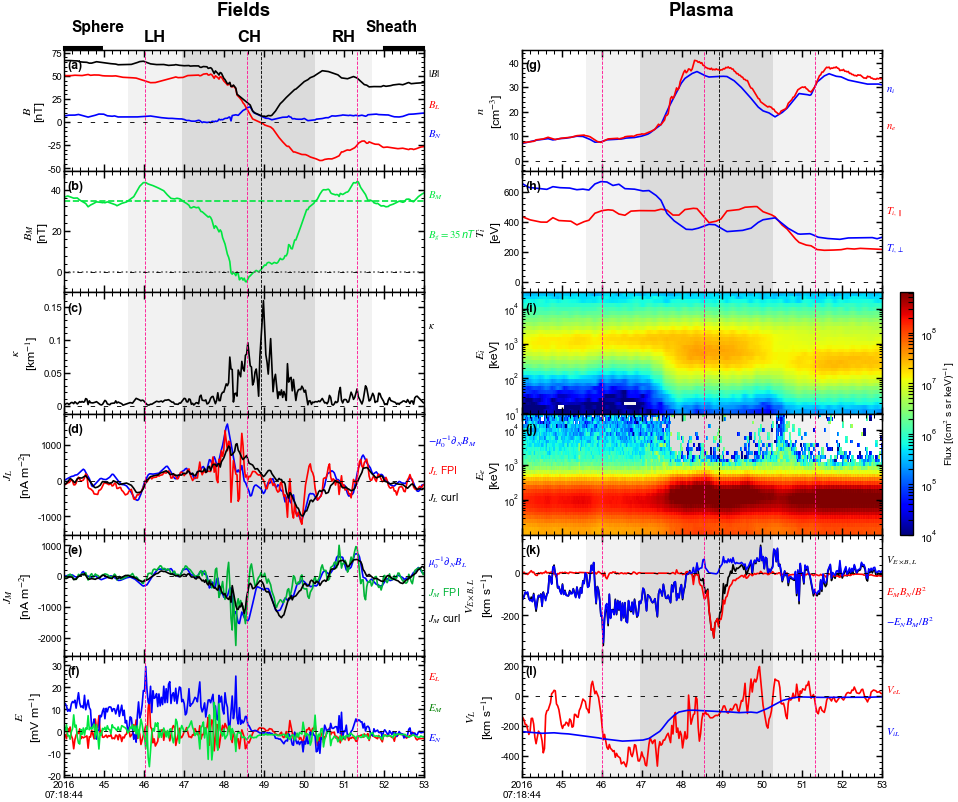

In [233]:
# ============================================================
# Overview figure – 2-column (Fields | Plasma)
# Strictly optimised for GRL full-page (double-column)
# Width ≤ 170 mm, Height ≤ 228 mm
# ============================================================
import os
import string
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from matplotlib.gridspec import GridSpec
import xarray as xr

# -----------------------------
# GRL geometry – very compact + better fonts
# -----------------------------
GRL_WIDTH  = 6.69
GRL_HEIGHT = 5.95
FS_LABEL   = 5.9
FS_TICK    = 4.8
FS_YTICK   = 4.6
FS_TEXT    = 5.1
FS_PANEL   = 6.0
FS_CBAR    = 5.0
DATA_LW    = 0.80
GUIDE_LW   = 0.42

mpl.rcParams.update({
    "font.family"            : "Arial",
    "font.size"              : FS_TEXT,
    "axes.labelsize"         : FS_LABEL,
    "xtick.labelsize"        : FS_TICK,
    "ytick.labelsize"        : FS_TICK,
    "legend.fontsize"        : FS_TEXT,
    "axes.linewidth"         : 0.7,
    "lines.linewidth"        : DATA_LW,
    "xtick.major.width"      : 0.7,
    "ytick.major.width"      : 0.7,
    "xtick.minor.width"      : 0.5,
    "ytick.minor.width"      : 0.5,
    "xtick.direction"        : "in",
    "ytick.direction"        : "in",
    "xtick.top"              : True,
    "ytick.right"            : True,
    "pdf.fonttype"           : 42,
    "ps.fonttype"            : 42,
    "path.simplify"          : True,
    "path.simplify_threshold": 0.5,
    "figure.dpi"             : 150,
    "savefig.dpi"            : 600,
    "savefig.bbox"           : "tight",
    "savefig.pad_inches"     : 0.015,
})

# =============================
# Spacecraft
# =============================
sc = "mms4"
sc_list = [sc]

for sc in sc_list:
    print(f"Plotting for {sc.upper()}...")

    # --- times
    t1 = times_dict[sc][0]
    t2 = times_dict[sc][1]

    # --- Bl
    Bl_dict = {
        sc_: find(hall[sc_].lmn_b, LMN=0, d1=del3, d2=del4)[0]
        for sc_ in sc_list
    }
    Bl = Bl_dict[sc]

    # --- guide field
    B_g = df_all.loc[sc, '$B_g$']

    # --- magnetic field (guide-field corrected B_M)
    B_hm = hall[sc].lmn_b.sel(time=slice(del3, del4)).copy()
    B_hm.loc[dict(LMN=1)] = (
        B_hm.sel(LMN=1) - res_all[sc]['Bg_linear']
    )

    bn          = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=2)
    bl          = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=0)
    bm_total    = hall[sc].lmn_b.sel(time=slice(del3, del4), LMN=1)
    B_magnitude = np.sqrt(bl**2 + bm_total**2 + bn**2)

    # Feature times
    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values)
    )
    th_min  = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values)
    )
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values)
    )
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min,  d2=th_maxr)[0]

    # Curvature κ
    V_cross = -46.8
    B_curv  = hall[sc].lmn_b.sel(time=slice(del3, del4))
    BL_c    = B_curv.sel(LMN=0)
    BM_c    = B_curv.sel(LMN=1)
    BN_c    = B_curv.sel(LMN=2)
    Bmag_c  = np.sqrt(BL_c**2 + BM_c**2 + BN_c**2)

    bL = BL_c / Bmag_c
    bM = BM_c / Bmag_c
    bN = BN_c / Bmag_c

    t_sec = (B_curv.time.values.astype("datetime64[ns]").astype(np.int64) * 1e-9)
    dbLdt = np.gradient(bL.values, t_sec)
    dbMdt = np.gradient(bM.values, t_sec)
    dbNdt = np.gradient(bN.values, t_sec)

    kappa = np.sqrt(dbLdt**2 + dbMdt**2 + dbNdt**2) / np.abs(V_cross)
    kappa_da = xr.DataArray(
        kappa, coords={"time": B_curv.time}, dims=["time"],
        name="kappa", attrs={"units": "km^-1"}
    )

    # Currents (Ampère)
    mu0 = 4.0 * np.pi * 1e-7
    VN  = 41 * 1e3
    smooth_samples = 7

    B_current = hall[sc].lmn_b.sel(time=slice(del3, del4))
    BL = B_current.sel(LMN=0)
    BM = B_current.sel(LMN=1)

    current_time_s = (
        B_current.time.values.astype("datetime64[ns]").astype(np.int64)
        - B_current.time.values[0].astype("datetime64[ns]").astype(np.int64)
    ) * 1e-9

    BL_smooth = BL.rolling(time=smooth_samples, center=True, min_periods=1).mean()
    BM_smooth = BM.rolling(time=smooth_samples, center=True, min_periods=1).mean()

    dBL_dt = np.gradient(np.asarray(BL_smooth.values), current_time_s)
    dBM_dt = np.gradient(np.asarray(BM_smooth.values), current_time_s)

    JL_ampere_values = -(dBM_dt * 1e-9 / VN) / mu0 * 1e9
    JM_ampere_values = +(dBL_dt * 1e-9 / VN) / mu0 * 1e9

    JL_ampere = xr.DataArray(JL_ampere_values, coords={"time": B_current.time},
                             dims=["time"], name="JL_ampere")
    JM_ampere = xr.DataArray(JM_ampere_values, coords={"time": B_current.time},
                             dims=["time"], name="JM_ampere")

    hall[sc]["JL_ampere"] = JL_ampere
    hall[sc]["JM_ampere"] = JM_ampere

    JL_FPI = hall[sc].lmn_j.sel(LMN=0, time=slice(del3, del4))
    JL_FGM = hall[sc].fgm_j.sel(LMN=0, time=slice(del3, del4))
    JM_FPI = hall[sc].lmn_j.sel(LMN=1, time=slice(del3, del4))
    JM_FGM = hall[sc].fgm_j.sel(LMN=1, time=slice(del3, del4))

    # ============================================================
    # 2-column figure
    # ============================================================
    fig = plt.figure(figsize=(GRL_WIDTH, GRL_HEIGHT), facecolor="white")

    # 6 rows × 2 columns, zero vertical gap inside each column
    gs = GridSpec(6, 2, figure=fig,
              hspace=0.0,
              wspace=0.27,
              left=0.085, right=0.90,
              bottom=0.060, top=0.875)   # ← lowered top for more space above

    # Left column – Fields
    ax_a = fig.add_subplot(gs[0, 0])   # B
    ax_b = fig.add_subplot(gs[1, 0], sharex=ax_a)   # BM
    ax_c = fig.add_subplot(gs[2, 0], sharex=ax_a)   # κ
    ax_d = fig.add_subplot(gs[3, 0], sharex=ax_a)   # JL
    ax_e = fig.add_subplot(gs[4, 0], sharex=ax_a)   # JM
    ax_f = fig.add_subplot(gs[5, 0], sharex=ax_a)   # E

    # Right column – Plasma
    ax_g = fig.add_subplot(gs[0, 1], sharex=ax_a)   # n
    ax_h = fig.add_subplot(gs[1, 1], sharex=ax_a)   # Ti
    ax_i = fig.add_subplot(gs[2, 1], sharex=ax_a)   # ion spectrogram
    ax_j = fig.add_subplot(gs[3, 1], sharex=ax_a)   # electron spectrogram
    ax_k = fig.add_subplot(gs[4, 1], sharex=ax_a)   # VExB,L
    ax_l = fig.add_subplot(gs[5, 1], sharex=ax_a)   # VL

    axs_left  = [ax_a, ax_b, ax_c, ax_d, ax_e, ax_f]
    axs_right = [ax_g, ax_h, ax_i, ax_j, ax_k, ax_l]
    all_axs   = axs_left + axs_right

    # ------------------------------------------------------------------
    # LEFT COLUMN – FIELDS
    # ------------------------------------------------------------------
    # (a) B
    ax_a.plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=2), c="b", lw=DATA_LW)
    ax_a.plot(hall[sc].lmn_b.time, hall[sc].lmn_b.sel(LMN=0), c="r", lw=DATA_LW)
    ax_a.plot(hall[sc].lmn_b.time.sel(time=slice(del3, del4)),
              B_magnitude.sel(time=slice(del3, del4)), c="k", lw=DATA_LW)
    ax_a.set_ylabel(r"$B$" + "\n[nT]", fontsize=FS_LABEL)
    ax_a.annotate(r"$|B|$", xy=(1.01, 0.78), xycoords="axes fraction",
                  fontsize=FS_TEXT, color="k", style="italic")
    ax_a.annotate(r"$B_L$", xy=(1.01, 0.52), xycoords="axes fraction",
                  fontsize=FS_TEXT, color="r", style="italic")
    ax_a.annotate(r"$B_N$", xy=(1.01, 0.28), xycoords="axes fraction",
                  fontsize=FS_TEXT, color="b", style="italic")

    # (b) BM
    ax_b.plot(B_hm.time, B_hm.sel(LMN=1) + B_g,
              c=(0/255, 230/255, 64/255), lw=DATA_LW)
    ax_b.axhline(y=B_g, c=(0/255, 230/255, 64/255), ls="--", lw=GUIDE_LW)
    ax_b.axhline(y=0,   c="0.4", ls=":", lw=GUIDE_LW)
    ax_b.set_ylabel(r"$B_M$" + "\n[nT]", fontsize=FS_LABEL)
    ax_b.annotate(r"$B_M$", xy=(1.01, 0.78), xycoords="axes fraction",
                  fontsize=FS_TEXT, color=(0/255, 230/255, 64/255), style="italic")
    ax_b.annotate(r"$B_g=35\,$nT", xy=(1.01, 0.45), xycoords="axes fraction",
                  fontsize=FS_TEXT, color=(0/255, 230/255, 64/255), style="italic")

    # (c) κ
    ax_c.plot(kappa_da.time, kappa_da, c="k", lw=DATA_LW)
    ax_c.set_ylabel(r"$\kappa$" + "\n" + r"[km$^{-1}$]", fontsize=FS_LABEL)
    ax_c.annotate(r"$\kappa$", xy=(1.01, 0.70), xycoords="axes fraction",
                  fontsize=FS_TEXT, color="k", style="italic")

    kappa_vals = kappa_da.values
    kappa_min, kappa_max = np.nanmin(kappa_vals), np.nanmax(kappa_vals)
    kappa_pad = 0.08 * (kappa_max - kappa_min) if kappa_max > kappa_min else 0.01
    ax_c.set_ylim(kappa_min - kappa_pad, kappa_max + kappa_pad)
    span = (kappa_max + kappa_pad) - (kappa_min - kappa_pad)
    candidates = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0])
    major_step = float(candidates[np.argmin(np.abs(candidates - span / 4.0))])
    ax_c.yaxis.set_major_locator(MultipleLocator(major_step))
    ax_c.yaxis.set_minor_locator(MultipleLocator(major_step / 5.0))
    ax_c.yaxis.set_major_formatter(FormatStrFormatter("%.3g"))

    # (d) JL
    ax_d.plot(JL_ampere.time, JL_ampere, c="b", lw=DATA_LW)
    ax_d.plot(JL_FPI.time,    JL_FPI,    c="r", lw=DATA_LW)
    ax_d.plot(JL_FGM.time,    JL_FGM,    c="k", lw=DATA_LW)
    ax_d.set_ylabel(r"$J_L$" + "\n[nA m$^{-2}$]", fontsize=FS_LABEL)
    ax_d.annotate(r"$-\mu_0^{-1}\partial_N B_M$", xy=(1.01, 0.75),
                  xycoords="axes fraction", color="b", fontsize=FS_TEXT)
    ax_d.annotate(r"$J_L$ FPI",  xy=(1.01, 0.50),
                  xycoords="axes fraction", color="r", fontsize=FS_TEXT)
    ax_d.annotate(r"$J_L$ curl", xy=(1.01, 0.28),
                  xycoords="axes fraction", color="k", fontsize=FS_TEXT)

    # (e) JM
    ax_e.plot(JM_ampere.time, JM_ampere, c="b", lw=DATA_LW)
    ax_e.plot(JM_FPI.time, JM_FPI, c=(0/255, 180/255, 55/255), lw=DATA_LW)
    ax_e.plot(JM_FGM.time, JM_FGM, c="k", lw=DATA_LW)
    ax_e.set_ylabel(r"$J_M$" + "\n[nA m$^{-2}$]", fontsize=FS_LABEL)
    ax_e.annotate(r"$\mu_0^{-1}\partial_N B_L$", xy=(1.01, 0.75),
                  xycoords="axes fraction", color="b", fontsize=FS_TEXT)
    ax_e.annotate(r"$J_M$ FPI",  xy=(1.01, 0.50),
                  xycoords="axes fraction", color=(0/255, 180/255, 55/255), fontsize=FS_TEXT)
    ax_e.annotate(r"$J_M$ curl", xy=(1.01, 0.28),
                  xycoords="axes fraction", color="k", fontsize=FS_TEXT)

    # (f) E
    ax_f.plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
              hall[sc].lmn_e.sel(LMN=0, time=slice(del3, del4)), c='r', lw=DATA_LW)
    ax_f.plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
              hall[sc].lmn_e.sel(LMN=2, time=slice(del3, del4)), c='b', lw=DATA_LW)
    ax_f.plot(hall[sc].lmn_e.time.sel(time=slice(del3, del4)),
              hall[sc].lmn_e.sel(LMN=1, time=slice(del3, del4)),
              c=(0/255, 230/255, 64/255), lw=DATA_LW)
    ax_f.set_ylabel(r"$E$" + "\n[mV m$^{-1}$]", fontsize=FS_LABEL)
    ax_f.annotate(r"$E_L$", xy=(1.01, 0.80), xycoords='axes fraction',
                  fontsize=FS_TEXT, color='r', style='italic')
    ax_f.annotate(r"$E_M$", xy=(1.01, 0.55), xycoords='axes fraction',
                  fontsize=FS_TEXT, color='g', style='italic')
    ax_f.annotate(r"$E_N$", xy=(1.01, 0.30), xycoords='axes fraction',
                  fontsize=FS_TEXT, color='b', style='italic')

    # ------------------------------------------------------------------
    # RIGHT COLUMN – PLASMA
    # ------------------------------------------------------------------
    # (g) densities
    ax_g.plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
              idatasets_interp[sc][f"{sc}_dis_numberdensity_brst"].sel(time=slice(del3, del4)),
              c="b", lw=DATA_LW)
    ax_g.plot(edatasets_interp[sc].time.sel(time=slice(del3, del4)),
              edatasets_interp[sc][f"{sc}_des_numberdensity_brst"].sel(time=slice(del3, del4)),
              c="r", lw=DATA_LW)
    ax_g.set_ylabel(r"$n$" + "\n[cm$^{-3}$]", fontsize=FS_LABEL)
    ax_g.annotate(r"$n_i$", xy=(1.01, 0.65), xycoords="axes fraction",
                  fontsize=FS_TEXT, color="b", style="italic")
    ax_g.annotate(r"$n_e$", xy=(1.01, 0.35), xycoords="axes fraction",
                  fontsize=FS_TEXT, color="r", style="italic")

    # (h) Ion temperature
    ax_h.plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
              idatasets_interp[sc][f"{sc}_dis_temppara_brst"].sel(time=slice(del3, del4)),
              c='r', lw=DATA_LW)
    ax_h.plot(idatasets_interp[sc].time.sel(time=slice(del3, del4)),
              idatasets_interp[sc][f"{sc}_dis_tempperp_brst"].sel(time=slice(del3, del4)),
              c='b', lw=DATA_LW)
    ax_h.set_ylabel(r"$T_i$" + "\n[eV]", fontsize=FS_LABEL)
    ax_h.annotate(r'$T_{i,\parallel}$', xy=(1.01, 0.65), xycoords='axes fraction',
                  style='italic', fontsize=FS_TEXT, color='r')
    ax_h.annotate(r'$T_{i,\perp}$', xy=(1.01, 0.35), xycoords='axes fraction',
                  style='italic', fontsize=FS_TEXT, color='b')

    # (i) Ion spectrogram
    i_da     = idatasets_interp[sc][f"{sc}_dis_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    i_time   = i_da.time.values
    i_energy = i_da.spec_bins.mean("time", skipna=True).values
    i_flux   = i_da.transpose("e_dim", "time").values
    i_flux   = np.where(np.isfinite(i_flux) & (i_flux > 0), i_flux, np.nan)

    pcmi = ax_i.pcolormesh(
        i_time, i_energy, i_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True, shading="auto"
    )
    ax_i.set_ylabel(r"$E_i$" + "\n[keV]", fontsize=FS_LABEL)
    ax_i.set_yscale("log")

    # (j) Electron spectrogram
    e_da     = edatasets_interp[sc][f"{sc}_des_energyspectr_omni_brst"].sel(time=slice(del3, del4))
    e_time   = e_da.time.values
    e_energy = e_da.spec_bins.mean("time", skipna=True).values
    e_flux   = e_da.transpose("e_dim", "time").values
    e_flux   = np.where(np.isfinite(e_flux) & (e_flux > 0), e_flux, np.nan)

    ax_j.pcolormesh(
        e_time, e_energy, e_flux,
        cmap="jet",
        norm=mcolors.LogNorm(vmin=1e4, vmax=1e8 * 10**0.8),
        rasterized=True, shading="auto"
    )
    ax_j.set_ylabel(r"$E_e$" + "\n[keV]", fontsize=FS_LABEL)
    ax_j.set_yscale("log")

    # (k) VExB,L
    exb   = hall[sc].ExB.sel(time=slice(del3, del4))
    e_lmn = hall[sc].lmn_e.sel(time=slice(del3, del4)).interp(time=exb.time)
    b_lmn = hall[sc].lmn_b.sel(time=slice(del3, del4)).interp(time=exb.time)
    b2    = (b_lmn**2).sum("LMN")

    VExB_L_EMBN =  e_lmn.sel(LMN=1) * b_lmn.sel(LMN=2) * 1e3 / b2
    VExB_L_ENBM = -e_lmn.sel(LMN=2) * b_lmn.sel(LMN=1) * 1e3 / b2

    ax_k.plot(exb.time, exb.sel(LMN=0), c="k", lw=DATA_LW)
    ax_k.plot(exb.time, VExB_L_EMBN, color="r", lw=DATA_LW)
    ax_k.plot(exb.time, VExB_L_ENBM, color="b", lw=DATA_LW)
    ax_k.set_ylabel(r"$V_{E\times B,L}$" + "\n[km s$^{-1}$]", fontsize=FS_LABEL)
    ax_k.annotate(r"$V_{E\times B,L}$", xy=(1.01, 0.78), xycoords="axes fraction",
                  color="k", fontsize=FS_TEXT)
    ax_k.annotate(r"$E_M B_N/B^2$", xy=(1.01, 0.50), xycoords="axes fraction",
                  color="r", fontsize=FS_TEXT)
    ax_k.annotate(r"$-E_N B_M/B^2$", xy=(1.01, 0.25), xycoords="axes fraction",
                  color="b", fontsize=FS_TEXT)

    # (l) VL
    ax_l.plot(hall[sc].lmn_ve.time.sel(time=slice(del3, del4)),
              hall[sc].lmn_ve.sel(LMN=0, time=slice(del3, del4)),
              c="r", lw=DATA_LW)
    ax_l.plot(hall[sc].lmn_vi.time.sel(time=slice(del3, del4)),
              hall[sc].lmn_vi.sel(LMN=0, time=slice(del3, del4)),
              c="b", lw=DATA_LW)
    ax_l.set_ylabel(r"$V_L$" + "\n[km s$^{-1}$]", fontsize=FS_LABEL)
    ax_l.annotate(r"$V_{eL}$", xy=(1.01, 0.70), xycoords="axes fraction",
                  color="r", fontsize=FS_TEXT)
    ax_l.annotate(r"$V_{iL}$", xy=(1.01, 0.35), xycoords="axes fraction",
                  color="b", fontsize=FS_TEXT)

    # ============================================================
# Region labels & column titles (smaller fonts + better spacing)
# ============================================================
    x1 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[0]
    x2 = bm_cross[sc]['left_two']['zero_crossing_time'].iloc[1]
    x3 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[0]
    x4 = bm_cross[sc]['right_two']['zero_crossing_time'].iloc[1]

    xc_h1 = x1 + (x2 - x1) / 2
    xc_fr = x2 + (x3 - x2) / 2
    xc_h2 = x3 + (x4 - x3) / 2

# LH / CH / RH
    ax_a.text(xc_h1, 1.045, "LH", transform=ax_a.get_xaxis_transform(),
          ha="center", va="bottom", fontsize=8.0, fontweight="bold")
    ax_a.text(xc_fr, 1.045, "CH", transform=ax_a.get_xaxis_transform(),
          ha="center", va="bottom", fontsize=8.0, fontweight="bold")
    ax_a.text(xc_h2, 1.045, "RH", transform=ax_a.get_xaxis_transform(),
          ha="center", va="bottom", fontsize=8.0, fontweight="bold")

# Sphere / Sheath
    ax_a.text(0.02, 1.13, "Sphere", transform=ax_a.transAxes,
          ha="left", va="bottom", fontsize=7.5, fontweight="bold")
    ax_a.text(0.98, 1.13, "Sheath", transform=ax_a.transAxes,
          ha="right", va="bottom", fontsize=7.5, fontweight="bold")

# Column titles
    ax_a.text(0.5, 1.25, "Fields", transform=ax_a.transAxes,
          ha="center", va="bottom", fontsize=9.0, fontweight="bold")
    ax_g.text(0.5, 1.25, "Plasma", transform=ax_g.transAxes,
          ha="center", va="bottom", fontsize=9.0, fontweight="bold")

    # ============================================================
    # Shared styling
    # ============================================================
    panel_labels = list(string.ascii_lowercase)

    for idx, ax in enumerate(all_axs):
        for line in ax.lines:
            line.set_linewidth(DATA_LW)

        # panel letter
        ax.text(0.01, 0.92, f"({panel_labels[idx]})",
                transform=ax.transAxes, ha="left", va="top",
                fontsize=FS_PANEL, fontweight="bold", zorder=60)

        ax.set_xlim(
            hall[sc].lmn_b.time.sel(time=del3, method="nearest"),
            hall[sc].lmn_b.time.sel(time=del4, method="nearest")
        )

        # vertical markers
        ax.axvline(x=Bl.values,      ls="--", c="k",       lw=GUIDE_LW)
        ax.axvline(x=th_maxl.values, ls="--", c='#FF1493', lw=GUIDE_LW)
        ax.axvline(x=th_min.values,  ls="--", c='#FF1493', lw=GUIDE_LW)
        ax.axvline(x=th_maxr.values, ls="--", c='#FF1493', lw=GUIDE_LW)

        ax.set_xticks(xticks(del3, del4)[0])
        ax.set_xticks(xticks(del3, del4)[1], minor=True)
        ax.set_xticklabels(xticks(del3, del4)[2], rotation=0, fontsize=FS_TICK)

        ax.axhline(y=0, c="k", ls=(0, (5, 10)), lw=GUIDE_LW)

        ax.tick_params(axis="x", which="major", pad=1.5, width=0.7, length=3.2,
                       labelsize=FS_TICK, direction="in", top=True, bottom=True)
        ax.tick_params(axis="x", which="minor", pad=1.5, width=0.5, length=1.8,
                       labelsize=FS_TICK, direction="in", top=True, bottom=True)

        # Y-ticks (skip for spectrograms and κ which already have custom ticks)
        if ax.get_yscale() != "log" and ax not in (ax_c,):
            ymin, ymax = ax.get_ylim()
            data_min, data_max = sorted((ymin, ymax))
            data_range = data_max - data_min
            pad = 0.05 * data_range if data_range > 0 else 0.5
            ylow, yhigh = data_min - pad, data_max + pad
            span = yhigh - ylow
            allowed = np.array([0.5, 1, 2, 5, 10, 20, 25, 50, 100, 200, 500, 1000, 2000])
            major_step = float(allowed[np.argmin(np.abs(allowed - span / 3.8))])
            ax.set_ylim(ylow, yhigh)
            ax.yaxis.set_major_locator(MultipleLocator(major_step))
            ax.yaxis.set_minor_locator(MultipleLocator(major_step / 5.0))
            if major_step >= 1 and abs(major_step - round(major_step)) < 1e-9:
                ax.yaxis.set_major_formatter(FormatStrFormatter("%d"))
            else:
                ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))

        ax.tick_params(axis="y", which="major",
                       direction="in", left=True, right=True, labelleft=True,
                       width=0.7, length=2.8, labelsize=FS_YTICK, pad=1.0)
        ax.tick_params(axis="y", which="minor",
                       direction="in", left=True, right=True,
                       width=0.5, length=1.6)

        # only bottom panels show x-labels
        if ax not in (ax_f, ax_l):
            ax.tick_params(axis="x", which="both", labelbottom=False)

        ax.yaxis.label.set_size(FS_LABEL)
        ax.yaxis.labelpad = 1.8
        ax.grid(False)

        # soft shading
        ax.axvspan(x1, x2, color="#E8E8E8", alpha=0.55, lw=0, zorder=0)
        ax.axvspan(x2, x3, color="#C8C8C8", alpha=0.65, lw=0, zorder=0)
        ax.axvspan(x3, x4, color="#E8E8E8", alpha=0.55, lw=0, zorder=0)

    # header colour bars on top of left column
    t = sorted([del3, t1, t2, del4])
    header_transform = ax_a.get_xaxis_transform()
    for i, color in enumerate("kwk"):
        ax_a.axvspan(t[i], t[i+1], 1.00, 1.02,
                     transform=header_transform, color=color, clip_on=False)

    # shared colourbar for the two spectrograms
    # shared colourbar for the two spectrograms – closer to axis
    fig.canvas.draw()
    pos_i = ax_i.get_position()
    pos_j = ax_j.get_position()
    cax = fig.add_axes([
        0.918,                                   # ← moved closer (was 0.935)
        min(pos_i.y0, pos_j.y0),
        0.013,                                   # slightly narrower
        max(pos_i.y1, pos_j.y1) - min(pos_i.y0, pos_j.y0)
    ])
    cbar = fig.colorbar(pcmi, cax=cax)
    cbar.set_label(r"Flux [(cm$^2$ s sr keV)$^{-1}$]",
               fontsize=FS_CBAR, labelpad=1.5)
    cbar.set_ticks(10 ** np.arange(4, 9))
    cbar.ax.tick_params(which="both", direction="in",
                    labelsize=FS_CBAR, width=0.55, length=2.3)
    cbar.outline.set_linewidth(0.65)

    # ------------------------------------------------------------------
    # Save
    # ------------------------------------------------------------------
    fig.savefig(
        os.path.join(output_folder, f"{taistarttime}_k_{sc}_GRL_2col.tiff"),
        dpi=600, format="tiff", facecolor="white",
        bbox_inches="tight", pad_inches=0.015
    )
    fig.savefig(
        os.path.join(output_folder, f"{taistarttime}_k_{sc}_GRL_2col.pdf"),
        format="pdf", facecolor="white",
        bbox_inches="tight", pad_inches=0.015
    )
    plt.show()

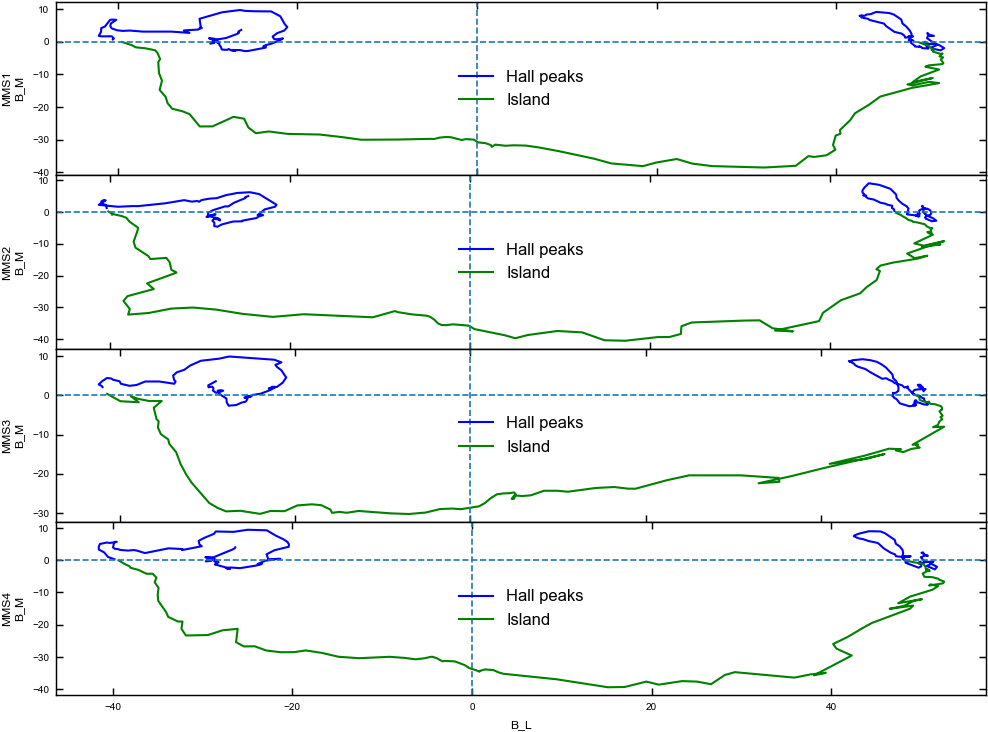

In [234]:
import matplotlib.pyplot as plt

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

fig, ax = plt.subplots(4, 1, figsize=(8, 6), sharex=False, sharey=False)

# Remove vertical space
plt.subplots_adjust(hspace=0)

# ===============================
# First 4 → B_M vs B_L
# ===============================
for i, sc in enumerate(sc_list):

    Bl = find(hall[sc].lmn_b, LMN=0, d1=del3, d2=del4)[0]
    B_g = df_all.loc[sc, "$B_g$"]
    B_hm = hall[sc].lmn_b.sel(time=slice(del3, del4)) - B_g
    B_G = hall[sc].lmn_b.sel(time=slice(del3, del4)) - res_all[sc]['Bg_linear']
    th_maxl = B_G.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_G.sel(LMN=1, time=slice(t1, Bl)).values)
    )
    th_min = B_G.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_G.sel(LMN=1, time=slice(t1, t2)).values)
    )
    th_maxr = B_G.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_G.sel(LMN=1, time=slice(Bl, t2)).values)
    )

    th_0 = find(B_G, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_G, LMN=1, d1=th_min, d2=th_maxr)[0]

    BL = hall[sc].lmn_b.sel(LMN=0)
    BM = B_G.sel(LMN=1)

    tmin = min(th_0, th_1)
    tmax = max(th_0, th_1)

    mask_green = (BM.time >= tmin) & (BM.time <= tmax)
    mask_blue = ~mask_green

    # Blue outside
    ax[i].plot(BL.where(mask_blue), BM.where(mask_blue),
               c='blue', lw=1, label='Hall peaks')

    # Green inside
    ax[i].plot(BL.where(mask_green), BM.where(mask_green),
               c='green', lw=1, label='Island')

    ax[i].axhline(0, ls='--')
    ax[i].axvline(0, ls='--')
    ax[i].set_ylabel(f'{sc.upper()}\nB_M')

    # Legend inside
    ax[i].legend(loc='center', fontsize=8, frameon=False)

# Bottom x label only
ax[-1].set_xlabel('B_L')
plt.savefig(os.path.join(output_folder, f"{taistarttime}_hodogram.png"), dpi=600)
plt.show()

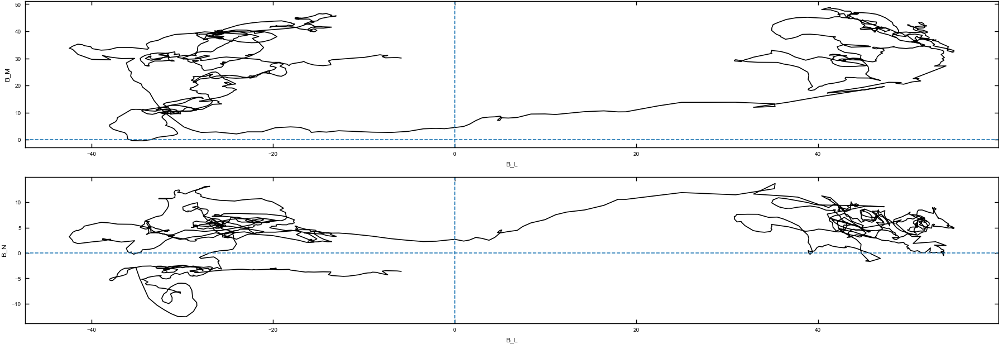

In [235]:
# Create subplots with 1 row and 2 columns
fig, ax = plt.subplots(2, 1, figsize=(15, 5), gridspec_kw={'wspace': 0.5})


# Plot for the first subplot (left column)
ax[0].plot(hall['mms3'].lmn_b.sel(LMN=0), hall['mms3'].lmn_b.sel(LMN=1),c='k')
ax[0].set_ylabel('B_M')
ax[0].set_xlabel('B_L')
ax[0].axhline(y=0,ls='--')
ax[0].axvline(x=0,ls='--')
# Plot for the second subplot (right column)
ax[1].plot(hall['mms3'].lmn_b.sel(LMN=0),hall['mms3'].lmn_b.sel(LMN=2),c='k')
ax[1].set_xlabel('B_L')  # Correctly set the x-axis label for the second plot
ax[1].set_ylabel('B_N')
ax[1].axhline(y=0,ls='--')
ax[1].axvline(x=0,ls='--')
# Adjust the layout and display the plots
plt.savefig("hodogram_mms3.png", dpi=600, bbox_inches='tight')
plt.show()

In [236]:
B_G = hall[sc].lmn_b.sel(time=slice(t1, del4)) - B_g
B_G.max().values,B_G.min().values

(array(17.90853793), array(-76.21179033))

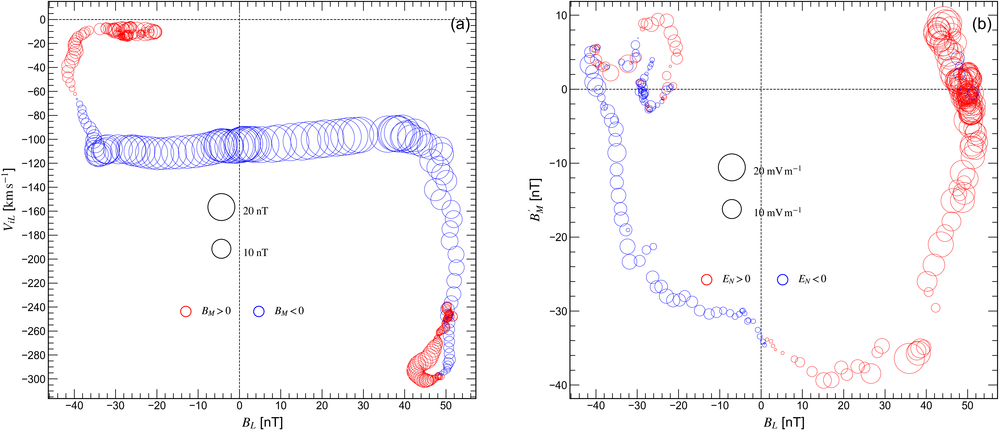

In [237]:
import logging
logging.getLogger("fontTools").setLevel(logging.WARNING)
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)
logging.getLogger("matplotlib.font_manager").setLevel(logging.WARNING)

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from matplotlib.transforms import blended_transform_factory

# ============================================================
# Bubble-scatter helper
# ============================================================
def bubble_scatter(
    ax,
    x,
    y,
    q,
    color,
    q_ref=20.0,
    s_ref=400.0,
    lw=0.25,
    alpha=1.0,
):
    """
    Draw hollow bubbles with area proportional to |q|.
    q = q_ref produces marker area s_ref.
    """
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()
    q = np.abs(np.asarray(q).ravel())
    good = (
        np.isfinite(x)
        & np.isfinite(y)
        & np.isfinite(q)
    )
    x = x[good]
    y = y[good]
    q = q[good]
    # Linear bubble-area scaling
    sizes = s_ref * (q / q_ref)
    sizes = np.clip(sizes, 0, None)
    return ax.scatter(
        x,
        y,
        s=sizes,
        facecolors="none",
        edgecolors=color,
        linewidths=lw,
        alpha=alpha,
        zorder=4,  # Data remain above legends
    )

# ============================================================
# Background-subtracted magnetic field
# ============================================================
B_g = df_all.loc[sc, "$B_g$"]
B_G = (
    hall[sc].lmn_b.sel(time=slice(del3, del4))
    - res_all[sc]["Bg_linear"]
)

# ============================================================
# Determine the central interval for panel (a)
# ============================================================
Bl_time = find(
    hall[sc].lmn_b,
    LMN=0,
    d1=del3,
    d2=del4,
)[0]

# Left B_M' maximum
BM_left = B_G.sel(
    LMN=1,
    time=slice(t1, Bl_time),
)
th_maxl = BM_left.time.isel(
    time=int(np.nanargmax(BM_left.values))
)

# Central B_M' minimum
BM_center = B_G.sel(
    LMN=1,
    time=slice(t1, t2),
)
th_min = BM_center.time.isel(
    time=int(np.nanargmin(BM_center.values))
)

# Right B_M' maximum
BM_right = B_G.sel(
    LMN=1,
    time=slice(Bl_time, t2),
)
th_maxr = BM_right.time.isel(
    time=int(np.nanargmax(BM_right.values))
)

# B_M' zero crossings
th_0 = find(
    B_G,
    LMN=1,
    d1=th_maxl,
    d2=Bl_time,
)[0]
th_1 = find(
    B_G,
    LMN=1,
    d1=th_min,
    d2=th_maxr,
)[0]
tmin = min(th_0, th_1)
tmax = max(th_0, th_1)

# ============================================================
# PANEL (a): B_L versus V_iL
# Bubble area = |B_M'|
# ============================================================
# Ion-velocity time grid
ViL = hall[sc].lmn_vi.sel(
    LMN=0,
    time=slice(del3, del4),
)

# Interpolate magnetic data to ion-velocity times
BL_ViL = hall[sc].lmn_b.sel(
    LMN=0,
    time=slice(del3, del4),
).interp(time=ViL.time)
BM_ViL = np.abs(
    B_G.sel(LMN=1).interp(time=ViL.time)
)

# Central-interval masks
mask_inside = (
    (ViL.time >= tmin)
    & (ViL.time <= tmax)
)
mask_outside = ~mask_inside

# ============================================================
# PANEL (b): B_L versus B_M'
# Bubble area = |E_N|
# ============================================================
# Electric-field time grid
EN = hall[sc].lmn_e.sel(
    LMN=2,
    time=slice(del3, del4),
)

# Interpolate magnetic data to electric-field times
BL_EN = hall[sc].lmn_b.sel(
    LMN=0,
    time=slice(del3, del4),
).interp(time=EN.time)
BMp_EN = B_G.sel(
    LMN=1
).interp(time=EN.time)

# Electric-field sign masks
mask_pos = EN > 0
mask_neg = EN < 0

# ============================================================
# Figure settings  (side-by-side)
# ============================================================
FIG_WIDTH  = 11.0      # wider
FIG_HEIGHT = 5.0       # shorter
DPI = 600
BUBBLE_LINEWIDTH = 0.25
GUIDE_LINEWIDTH  = 0.5
SPINE_LINEWIDTH  = 0.7
AXIS_LABEL_SIZE  = 10
TICK_LABEL_SIZE  = 8
PANEL_LABEL_SIZE = 12
LEGEND_SIZE      = 8

# ============================================================
# Create figure – side by side
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    dpi=DPI,
    sharex=True,                     # still share B_L axis
    gridspec_kw={"wspace": 0.22},    # horizontal spacing
)

# ============================================================
# PANEL (a)
# ============================================================
# Outside interval: red
bubble_scatter(
    ax=ax1,
    x=BL_ViL.where(mask_outside),
    y=ViL.where(mask_outside),
    q=BM_ViL.where(mask_outside),
    color="red",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)
# Inside interval: blue
bubble_scatter(
    ax=ax1,
    x=BL_ViL.where(mask_inside),
    y=ViL.where(mask_inside),
    q=BM_ViL.where(mask_inside),
    color="blue",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)

ax1.set_ylabel(
    r"$V_{iL}$ [$\mathrm{km\,s^{-1}}$]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax1.set_xlabel(
    r"$B_L$ [nT]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax1.text(
    0.94, 0.96, "(a)",
    transform=ax1.transAxes,
    fontsize=PANEL_LABEL_SIZE,
    fontweight="normal",
    ha="left", va="top",
)

# ============================================================
# PANEL (b)
# ============================================================
# Positive E_N: red
bubble_scatter(
    ax=ax2,
    x=BL_EN.where(mask_pos),
    y=BMp_EN.where(mask_pos),
    q=EN.where(mask_pos),
    color="red",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)
# Negative E_N: blue
bubble_scatter(
    ax=ax2,
    x=BL_EN.where(mask_neg),
    y=BMp_EN.where(mask_neg),
    q=EN.where(mask_neg),
    color="blue",
    q_ref=20.0,
    s_ref=400.0,
    lw=BUBBLE_LINEWIDTH,
)

ax2.set_xlabel(
    r"$B_L$ [nT]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax2.set_ylabel(
    r"$B_M^{\prime}$ [nT]",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="normal",
)
ax2.text(
    0.94, 0.96, "(b)",
    transform=ax2.transAxes,
    fontsize=PANEL_LABEL_SIZE,
    fontweight="normal",
    ha="left", va="top",
)

# ============================================================
# Common axis formatting
# ============================================================
for ax in (ax1, ax2):
    ax.axvline(x=0, linestyle="--", linewidth=GUIDE_LINEWIDTH, color="black", zorder=1)
    ax.axhline(y=0, linestyle="--", linewidth=GUIDE_LINEWIDTH, color="black", zorder=1)

    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.xaxis.set_minor_locator(MultipleLocator(2))

    ax.tick_params(
        axis="both", which="major",
        direction="in", length=7, width=0.5,
        labelsize=TICK_LABEL_SIZE,
        top=True, right=True, bottom=True, left=True, pad=2,
    )
    ax.tick_params(
        axis="both", which="minor",
        direction="in", length=4, width=0.5,
        top=True, right=True, bottom=True, left=True,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_LINEWIDTH)
        spine.set_color("black")

# Panel-specific y ticks
ax1.yaxis.set_major_locator(MultipleLocator(20))
ax1.yaxis.set_minor_locator(MultipleLocator(5))
ax2.yaxis.set_major_locator(MultipleLocator(10))
ax2.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend coordinate systems (x=0 still centres on B_L=0)
# ============================================================
legend_transform_1 = blended_transform_factory(ax1.transData, ax1.transAxes)
legend_transform_2 = blended_transform_factory(ax2.transData, ax2.transAxes)

# ============================================================
# PANEL (a): |B_M'| size legend
# ============================================================
size_handles_a = [
    ax1.scatter([], [], s=400, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$20\ \mathrm{nT}$"),
    ax1.scatter([], [], s=200, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$10\ \mathrm{nT}$"),
]
size_legend_a = ax1.legend(
    handles=size_handles_a,
    loc="center",
    bbox_to_anchor=(0, 0.42),
    bbox_transform=legend_transform_1,
    frameon=False,
    fontsize=LEGEND_SIZE,
    labelspacing=2.2,
    handleheight=2.2,
    handlelength=2.0,
    handletextpad=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.40],
    borderaxespad=0,
)
size_legend_a.set_zorder(2)
ax1.add_artist(size_legend_a)

# ============================================================
# PANEL (a): interval legend
# ============================================================
inside_handle_a  = ax1.scatter([], [], s=60, facecolors="none", edgecolors="red",
                               linewidths=0.6, label=r"$B_M>0$")
outside_handle_a = ax1.scatter([], [], s=60, facecolors="none", edgecolors="blue",
                               linewidths=0.6, label=r"$B_M<0$")
interval_legend_a = ax1.legend(
    handles=[inside_handle_a, outside_handle_a],
    loc="center",
    bbox_to_anchor=(0, 0.22),
    bbox_transform=legend_transform_1,
    ncol=2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    columnspacing=1.6,
    handletextpad=0.45,
    labelspacing=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.35],
    borderaxespad=0,
)
interval_legend_a.set_zorder(2)
ax1.add_artist(interval_legend_a)

# ============================================================
# PANEL (b): |E_N| size legend
# ============================================================
size_handles_b = [
    ax2.scatter([], [], s=400, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$20\ \mathrm{mV\,m^{-1}}$"),
    ax2.scatter([], [], s=200, facecolors="none", edgecolors="black",
                linewidths=0.6, label=r"$10\ \mathrm{mV\,m^{-1}}$"),
]
size_legend_b = ax2.legend(
    handles=size_handles_b,
    loc="center",
    bbox_to_anchor=(0, 0.52),
    bbox_transform=legend_transform_2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    labelspacing=2.2,
    handleheight=2.2,
    handlelength=2.0,
    handletextpad=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.40],
    borderaxespad=0,
)
size_legend_b.set_zorder(2)
ax2.add_artist(size_legend_b)

# ============================================================
# PANEL (b): E_N sign legend
# ============================================================
positive_handle_b = ax2.scatter([], [], s=60, facecolors="none", edgecolors="red",
                                linewidths=0.6, label=r"$E_N>0$")
negative_handle_b = ax2.scatter([], [], s=60, facecolors="none", edgecolors="blue",
                                linewidths=0.6, label=r"$E_N<0$")
sign_legend_b = ax2.legend(
    handles=[positive_handle_b, negative_handle_b],
    loc="center",
    bbox_to_anchor=(0, 0.30),
    bbox_transform=legend_transform_2,
    ncol=2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    columnspacing=2.0,
    handletextpad=0.45,
    labelspacing=1.0,
    borderpad=0.2,
    scatteryoffsets=[0.35],
    borderaxespad=0,
)
sign_legend_b.set_zorder(2)
ax2.add_artist(sign_legend_b)

# ============================================================
# Figure layout
# ============================================================
fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.14,
    top=0.96,
    wspace=0.22,
)

# ============================================================
# Save figure
# ============================================================
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"]  = 42

base_output_path = os.path.join(
    output_folder,
    f"{taistarttime}_combined_{sc}_sidebyside",
)

fig.savefig(
    base_output_path + ".pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.01,
    facecolor="white",
)
fig.savefig(
    base_output_path + ".tif",
    format="tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.01,
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"},
)
fig.savefig(
    base_output_path + ".png",
    format="png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.01,
    facecolor="white",
)

plt.show()


In [238]:
edatasets_interp['mms3'].mms3_des_numberdensity_brst.sel(time=slice(t1,del4)).max().values

array(38.93691479)

In [239]:
idatasets_interp['mms3'].mms3_dis_numberdensity_brst.sel(time=slice(t1,del4)).max().values

array(34.90994542)

In [240]:
th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]
t1 = times_dict[sc][0]
t2 = times_dict[sc][1]
t1,t2,th_1.values,th_0.values

(np.datetime64('2016-01-22T07:18:45.000'),
 np.datetime64('2016-01-22T07:18:52.000'),
 np.datetime64('2016-01-22T07:18:50.359564000'),
 np.datetime64('2016-01-22T07:18:47.119564000'))

Plotting MMS1...
Plotting MMS2...
Plotting MMS3...
Plotting MMS4...


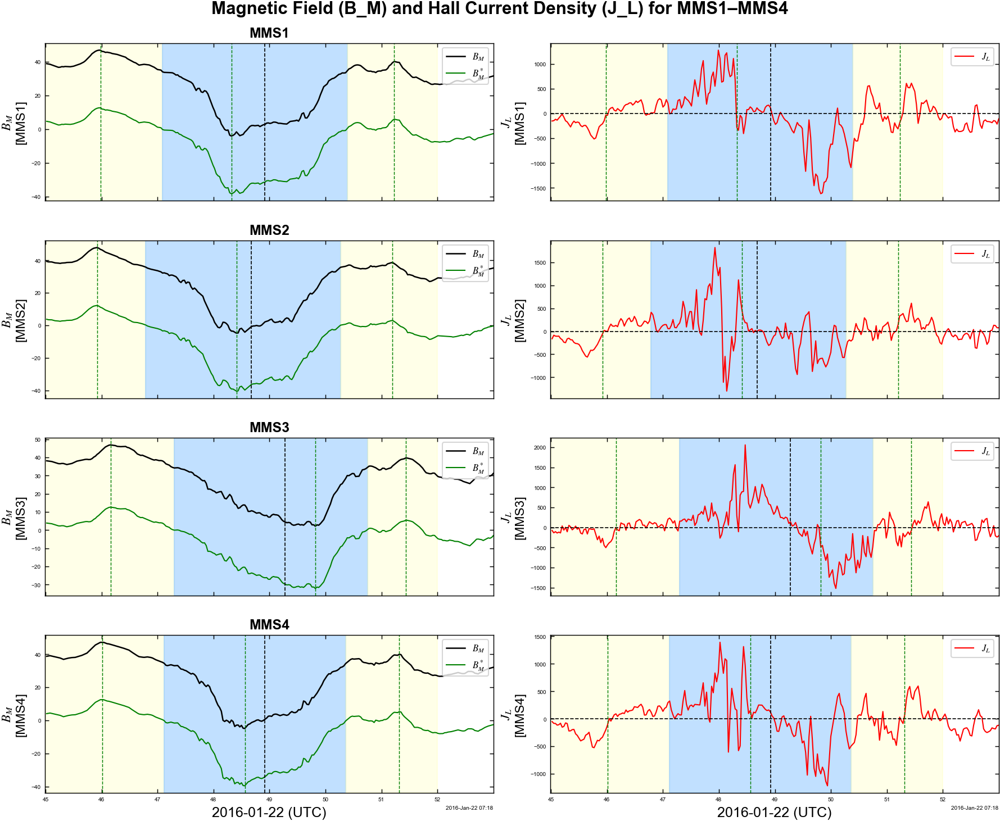

In [241]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import os

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
fig.suptitle("Magnetic Field (B_M) and Hall Current Density (J_L) for MMS1–MMS4", fontsize=15, fontweight='bold')

for i, sc in enumerate(sc_list):
    print(f"Plotting {sc.upper()}...")

    # --- Compute derived quantities ---
    Bl_dict = {sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=del4)[0] for sc_ in sc_list}
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, '$B_g$']
    B_hm = hall[sc].lmn_b.sel(time=slice(t1, del4)) - B_g
    t1, t2 = times_dict[sc]

    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]

    # --- Magnetic Field (Column 1) ---
    axB = axes[i, 0]
    axB.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
             hall[sc].lmn_b.sel(LMN=1, time=slice(t1, del4)),
             c='k', lw=1.2, label=r'$B_M$')
    axB.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
             B_hm.sel(LMN=1), c='g', lw=1, label=r'$B_M^*$')
    axB.set_ylabel(rf'$\mathit{{B_M}}$' + '\n' + rf'[{sc.upper()}]', fontsize=11)
    axB.legend(fontsize=8, loc='upper right')
    axB.set_title(f"{sc.upper()}", fontsize=12, fontweight='bold', pad=5)

    # --- Hall Current Density (Column 2) ---
    axJ = axes[i, 1]
    axJ.plot(hall[sc].lmn_j.time.sel(time=slice(t1, del4)),
             hall[sc].lmn_j.sel(LMN=0, time=slice(t1, del4)), c='r', lw=1, label=r'$J_L$')
    axJ.axhline(0, color='k', ls='--', lw=0.8)
    axJ.set_ylabel(rf'$\mathit{{J_L}}$' + '\n' + rf'[{sc.upper()}]', fontsize=11)
    axJ.legend(fontsize=8, loc='upper right')

    # --- Shared formatting for both columns ---
    for ax in [axB, axJ]:
        ax.axvline(x=Bl.values, ls='--', c='k', lw=0.8)
        for tline in [th_maxl, th_min, th_maxr]:
            ax.axvline(x=tline.values, ls='--', c='g', lw=0.7)
        ax.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.3)
        ax.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.6)
        ax.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.3)
        ax.grid(False)
        ax.set_xlim(hall[sc].lmn_b.time.sel(time=t1, method='nearest'),
                    hall[sc].lmn_b.time.sel(time=del4, method='nearest'))

# --- Formatting ---
for ax in axes[-1, :]:
    ax.set_xlabel('2016-01-22 (UTC)', fontsize=12)

plt.tight_layout(pad=1.2)
plt.subplots_adjust(top=0.93, hspace=0.25)
plt.savefig(os.path.join(output_folder, f"{taistarttime}_n.png"), dpi=600)
plt.show()


Processing MMS1...
Processing MMS2...
Processing MMS3...
Processing MMS4...


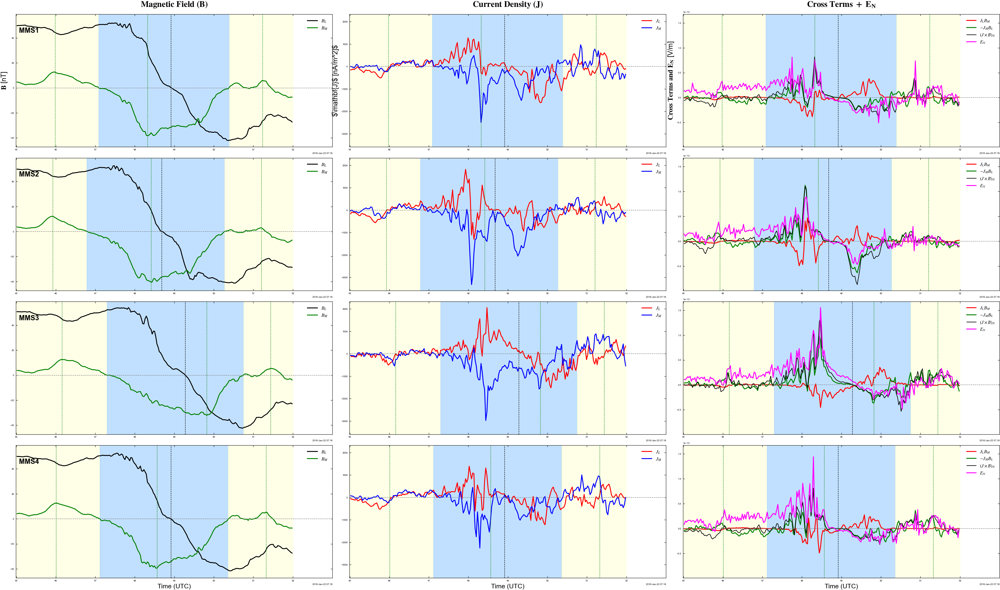

In [242]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
colors_B = ['k', 'g']
colors_J = ['r', 'b']
colors_cross = ['red', 'green', 'black']  # Added color for J×B

# --- Expanded but compact layout ---
fig, axes = plt.subplots(4, 3, figsize=(30, 18), sharex='row', sharey='col')

# Optional: Add column headers for clarity
col_titles = [r'$\mathbf{Magnetic\ Field\ (B)}$',
              r'$\mathbf{Current\ Density\ (J)}$',
              r'$\mathbf{Cross\ Terms\ +\ E_N}$']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=17, fontweight='bold', pad=15)

for i, sc in enumerate(sc_list):
    print(f"Processing {sc.upper()}...")
    # --- Compute derived quantities ---
    Bl_dict = {sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=del4)[0] for sc_ in sc_list}
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, '$B_g$']
    B_hm = hall[sc].lmn_b.sel(time=slice(t1, del4)) - B_g
    t1, t2 = times_dict[sc]

    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]

    # Extract data
    t_start, t_end = t1, t2

    BL = hall[sc].lmn_b.sel(LMN=0, time=slice(t_start, t_end))
    B_hm = hall[sc].lmn_b.sel(LMN=1, time=slice(t_start, t_end)) - B_g
    JL = hall[sc].lmn_j.sel(LMN=0, time=slice(t_start, t_end))
    Jm = hall[sc].lmn_j.sel(LMN=1, time=slice(t_start, t_end))

    Bl_dict = {sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=del4)[0] for sc_ in sc_list}
    Bl = Bl_dict[sc]

    # Compute cross terms
    JL_BM = JL * B_hm * (1e-9) ** 2   # V/m
    JM_BL = -Jm * BL * (1e-9) ** 2    # negative sign as per your request

    # ---- Column 1: B_L and B_M ----
    axB = axes[i, 0]
    axB.plot(BL.time, BL, c=colors_B[0], lw=1.8, label=r'$B_L$')
    axB.plot(B_hm.time, B_hm, c=colors_B[1], lw=1.8, label=r'$B_M$')
    axB.axhline(0, color='gray', ls='--', lw=0.8)
    axB.text(0.01, 0.9, sc.upper(), transform=axB.transAxes,
             fontsize=14, fontweight='bold', va='top', ha='left')
    if i == len(sc_list) - 1:
        axB.set_xlabel('Time (UTC)', fontsize=13)
    if i == 0:
        axB.set_ylabel(r'$\mathbf{B}$ [nT]', fontsize=14)
    axB.legend(loc='upper right', fontsize=10, frameon=False)
    axB.grid(False)

    # ---- Column 2: J_L and J_M ----
    axJ = axes[i, 1]
    axJ.plot(JL.time, JL, c=colors_J[0], lw=1.8, label=r'$J_L$')
    axJ.plot(Jm.time, Jm, c=colors_J[1], lw=1.8, label=r'$J_M$')
    axJ.axhline(0, color='gray', ls='--', lw=0.8)
    if i == len(sc_list) - 1:
        axJ.set_xlabel('Time (UTC)', fontsize=13)
    if i == 0:
        axJ.set_ylabel(r'$\mathbf{J}$ [nA/m^2]$', fontsize=14)
    axJ.legend(loc='upper right', fontsize=10, frameon=False)
    axJ.grid(False)

    # ---- Column 3: Cross Terms + E_N overlay ----
    axC = axes[i, 2]
    axC.plot(JL_BM.time, JL_BM, c=colors_cross[0], lw=1.8, label=r'$J_L B_M$')
    axC.plot(JM_BL.time, JM_BL, c=colors_cross[1], lw=1.8, label=r'$-J_M B_L$')
    axC.plot(hall[sc].jxb.time.sel(time=slice(t1, t2)),
             hall[sc].jxb.sel(LMN=2, time=slice(t1, t2)) * (ni * (1e6) * q_e) * (1e-3),  # V/m
             c='k', lw=1.2, label=r'$(J\times B)_N$')

    # --- Overlay E_N ---
    axC.plot(hall[sc].lmn_e.time.sel(time=slice(t1, t2)),
             hall[sc].lmn_e.sel(LMN=2, time=slice(t1, t2))* (ni * (1e6) * q_e)*(1e-3),
             c='magenta', lw=1.8, label=r'$E_N$')

    # --- Fix legend and y-label ---
    axC.axhline(0, color='gray', ls='--', lw=0.8)
    if i == len(sc_list) - 1:
        axC.set_xlabel('Time (UTC)', fontsize=13)
    if i == 0:
        axC.set_ylabel(r'$\mathbf{Cross\ Terms\ and\ E_N}$ [V/m]', fontsize=14)
    axC.legend(loc='upper right', fontsize=9.5, frameon=False)
    axC.grid(False)
# --- Shared formatting for both columns ---
    for ax in [axB,axJ,axC]:
        ax.axvline(x=Bl.values, ls='--', c='k', lw=0.8)
        for tline in [th_maxl, th_min, th_maxr]:
            ax.axvline(x=tline.values, ls='--', c='g', lw=0.7)
        ax.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.3)
        ax.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.6)
        ax.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.3)
        ax.grid(False)
        ax.set_xlim(hall[sc].lmn_b.time.sel(time=t1, method='nearest'),
                    hall[sc].lmn_b.time.sel(time=del4, method='nearest'))

        

plt.tight_layout(pad=0.8, w_pad=0.3, h_pad=0.5)
plt.subplots_adjust(top=0.94, bottom=0.06, left=0.06, right=0.98)

# Save figure
plt.savefig(os.path.join(output_folder,
            f"{taistarttime}_o.png"),
            dpi=400, bbox_inches='tight')

plt.show()


Processing MMS1...
Processing MMS2...
Processing MMS3...
Processing MMS4...


25-Oct-26 19:07:06: Font 'bf' does not have a glyph for '\\cdot' [U+22c5], substituting with a dummy symbol.
25-Oct-26 19:07:07: Font 'bf' does not have a glyph for '\\cdot' [U+22c5], substituting with a dummy symbol.
25-Oct-26 19:07:08: Font 'bf' does not have a glyph for '\\cdot' [U+22c5], substituting with a dummy symbol.
25-Oct-26 19:07:13: Font 'bf' does not have a glyph for '\\cdot' [U+22c5], substituting with a dummy symbol.
25-Oct-26 19:07:14: Font 'bf' does not have a glyph for '\\cdot' [U+22c5], substituting with a dummy symbol.


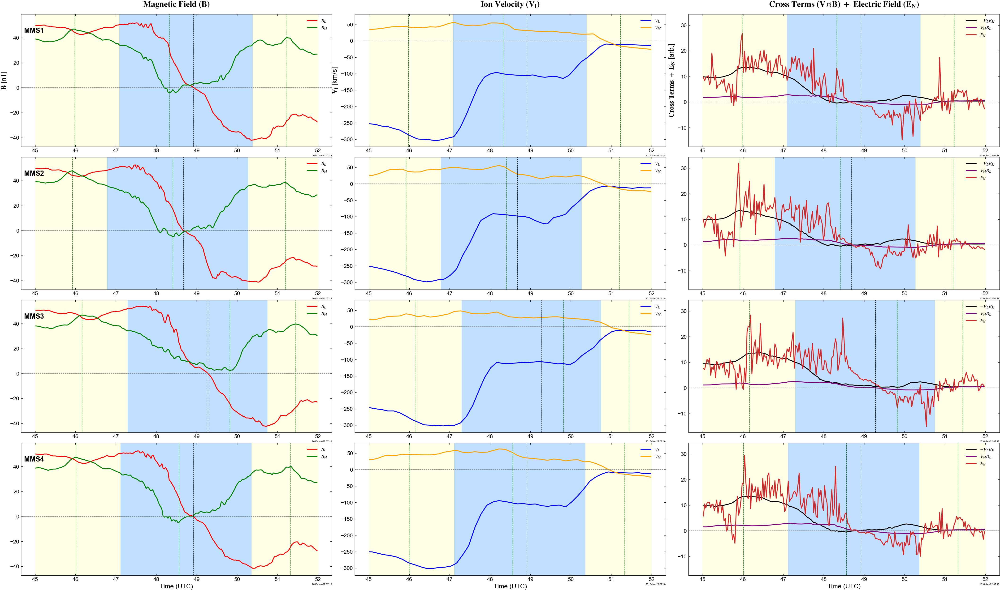

In [243]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']
colors_B = ['r', 'g']           # B_L, B_M
colors_V = ['b', 'orange']      # V_L, V_M
colors_cross = ['black', 'purple']  # Cross terms: V_L*B_M, V_M*B_L
color_En = 'tab:red'            # E_N color

# --- Expanded but compact layout ---
fig, axes = plt.subplots(4, 3, figsize=(30, 18), sharex='row', sharey='col')

# Optional: Add column headers for clarity
col_titles = [r'$\mathbf{Magnetic\ Field\ (B)}$',
              r'$\mathbf{Ion\ Velocity\ (V_i)}$',
              r'$\mathbf{Cross\ Terms\ (V\cdot B)\ +\ Electric\ Field\ (E_N)}$']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=17, fontweight='bold', pad=15)

# === LOOP THROUGH SPACECRAFT ===
for i, sc in enumerate(sc_list):
    print(f"Processing {sc.upper()}...")
    # Locate features
    # --- Compute derived quantities ---
    Bl_dict = {sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=del4)[0] for sc_ in sc_list}
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, '$B_g$']
    B_hm = hall[sc].lmn_b.sel(time=slice(t1, del4)) - B_g
    t1, t2 = times_dict[sc]

    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]

    t1 = times_dict[sc][0]
    t2 = times_dict[sc][1]
   
    # Extract components
    Bl_dict = {sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=t2)[0] for sc_ in sc_list}
    Bl = Bl_dict[sc]
   

    B_L = hall[sc].lmn_b.sel(LMN=0, time=slice(t1, t2))
    B_M = hall[sc].lmn_b.sel(LMN=1, time=slice(t1, t2))
    V_L = hall[sc].lmn_vi.sel(LMN=0, time=slice(t1, t2))
    V_M = hall[sc].lmn_vi.sel(LMN=1, time=slice(t1, t2))

    # Cross terms
    VL_BM = -V_L * B_M * (1e3) * (1e-9)*(1e3)
    VM_BL = V_M * B_L * (1e3) * (1e-9)*(1e3)

    # Electric Field (E_N)
    E_N = hall[sc].lmn_e.sel(LMN=2, time=slice(t1, t2))

    # === Column 1: B_L and B_M ===
    axB = axes[i, 0]
    axB.plot(B_L.time, B_L, c=colors_B[0], lw=1.8, label=r'$B_L$')
    axB.plot(B_M.time, B_M, c=colors_B[1], lw=1.8, label=r'$B_M$')
    axB.axhline(0, color='gray', ls='--', lw=0.8)

    # Region markers
    axB.axvline(x=Bl.values, ls='--', c='k', lw=0.8)
    for tline in [th_maxl, th_min, th_maxr]:
        axB.axvline(x=tline.values, ls='--', c='g', lw=0.7)
    axB.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.3)
    axB.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.6)
    axB.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.3)

    axB.text(0.01, 0.9, sc.upper(), transform=axB.transAxes,
             fontsize=14, fontweight='bold', va='top', ha='left')
    if i == len(sc_list) - 1:
        axB.set_xlabel('Time (UTC)', fontsize=13)
    if i == 0:
        axB.set_ylabel(r'$\mathbf{B}$ [nT]', fontsize=14)
    axB.legend(loc='upper right', fontsize=10, frameon=False)
    axB.grid(False)

    # === Column 2: V_L and V_M ===
    axV = axes[i, 1]
    axV.plot(V_L.time, V_L, c=colors_V[0], lw=1.8, label=r'$V_L$')
    axV.plot(V_M.time, V_M, c=colors_V[1], lw=1.8, label=r'$V_M$')
    axV.axhline(0, color='gray', ls='--', lw=0.8)

    axV.axvline(x=Bl.values, ls='--', c='k', lw=0.8)
    for tline in [th_maxl, th_min, th_maxr]:
        axV.axvline(x=tline.values, ls='--', c='g', lw=0.7)
    axV.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.3)
    axV.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.6)
    axV.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.3)

    if i == len(sc_list) - 1:
        axV.set_xlabel('Time (UTC)', fontsize=13)
    if i == 0:
        axV.set_ylabel(r'$\mathbf{V_i}$ [km/s]', fontsize=14)
    axV.legend(loc='upper right', fontsize=10, frameon=False)
    axV.grid(False)

    # === Column 3: Cross Terms + E_N ===
    axC = axes[i, 2]
    axC.plot(VL_BM.time, VL_BM, c=colors_cross[0], lw=1.8, label=r'$-V_L B_M$')
    axC.plot(VM_BL.time, VM_BL, c=colors_cross[1], lw=1.8, label=r'$V_M B_L$')
    axC.plot(E_N.time, E_N, c=color_En, lw=1.8, label=r'$E_N$')
    axC.axhline(0, color='gray', ls='--', lw=0.8)

    axC.axvline(x=Bl.values, ls='--', c='k', lw=0.8)
    for tline in [th_maxl, th_min, th_maxr]:
        axC.axvline(x=tline.values, ls='--', c='g', lw=0.7)
    axC.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.3)
    axC.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.6)
    axC.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.3)

    if i == len(sc_list) - 1:
        axC.set_xlabel('Time (UTC)', fontsize=13)
    if i == 0:
        axC.set_ylabel(r'$\mathbf{Cross\ Terms\ +\ E_N}$ [arb.]', fontsize=14)
    axC.legend(loc='upper right', fontsize=10, frameon=False)
    axC.grid(False)

# === Compact layout tuning ===
for ax_row in axes:
    for ax in ax_row:
        ax.tick_params(axis='both', labelsize=11)

plt.tight_layout(pad=0.8, w_pad=0.3, h_pad=0.5)
plt.subplots_adjust(top=0.94, bottom=0.06, left=0.06, right=0.98)

# === SAVE AND SHOW ===
plt.savefig(os.path.join(output_folder,
            f"{taistarttime}_p.png"),
            dpi=600, bbox_inches='tight')
plt.show()


Plotting MMS1...
Plotting MMS2...
Plotting MMS3...
Plotting MMS4...


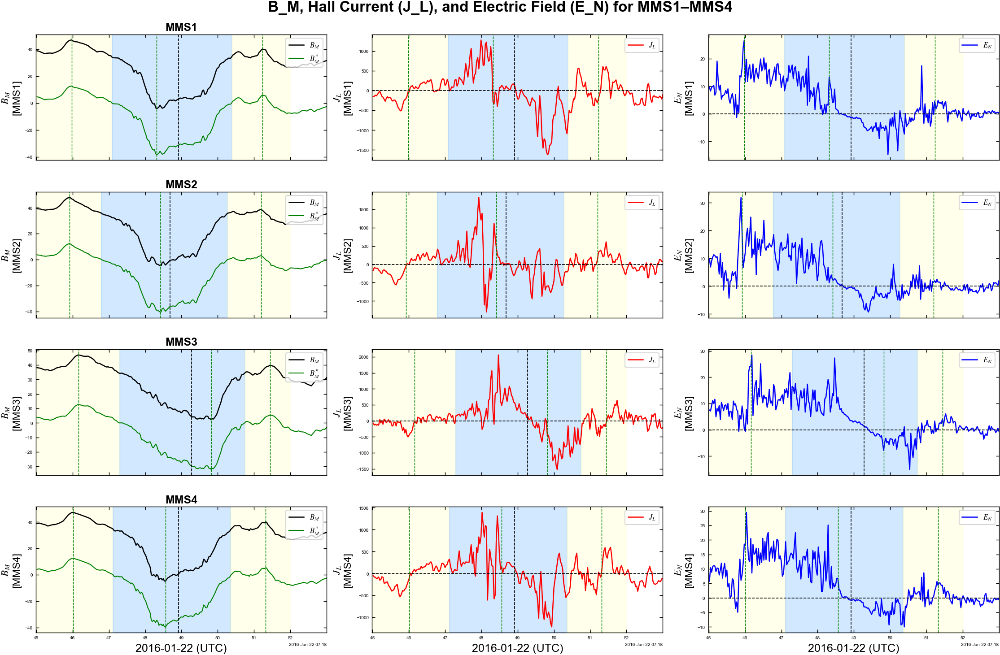

In [244]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

fig, axes = plt.subplots(4, 3, figsize=(15, 10), sharex=True)
fig.suptitle("B_M, Hall Current (J_L), and Electric Field (E_N) for MMS1–MMS4", 
             fontsize=16, fontweight='bold')

for i, sc in enumerate(sc_list):
    print(f"Plotting {sc.upper()}...")

    # --- Derived quantities ---
    Bl_dict = {sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=del4)[0] for sc_ in sc_list}
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, '$B_g$']
    B_hm = hall[sc].lmn_b.sel(time=slice(t1, del4)) - B_g
    t1, t2 = times_dict[sc]

    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]

    # --- Column 1: B_M ---
    axB = axes[i, 0]
    axB.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
             hall[sc].lmn_b.sel(LMN=1, time=slice(t1, del4)),
             c='k', lw=1.2, label=r'$B_M$')
    axB.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
             B_hm.sel(LMN=1),
             c='g', lw=1, label=r'$B_M^*$')
    axB.set_ylabel(rf'$B_M$' + '\n' + rf'[{sc.upper()}]', fontsize=11)
    axB.legend(fontsize=8, loc='upper right')
    axB.set_title(f"{sc.upper()}", fontsize=12, fontweight='bold', pad=4)

    # --- Column 2: Hall Current Density J_L ---
    axJ = axes[i, 1]
    axJ.plot(hall[sc].lmn_j.time.sel(time=slice(t1, del4)),
             hall[sc].lmn_j.sel(LMN=0, time=slice(t1, del4)),
             c='r', lw=1.2, label=r'$J_L$')
    axJ.axhline(0, color='k', ls='--', lw=0.8)
    axJ.set_ylabel(rf'$J_L$' + '\n' + rf'[{sc.upper()}]', fontsize=11)
    axJ.legend(fontsize=8, loc='upper right')

    # --- Column 3: Electric Field E_N ---
    axE = axes[i, 2]
    axE.plot(hall[sc].lmn_e.time.sel(time=slice(t1, del4)),
             hall[sc].lmn_e.sel(LMN=2, time=slice(t1, del4)),
             c='b', lw=1.2, label=r'$E_N$')
    axE.axhline(0, color='k', ls='--', lw=0.8)
    axE.set_ylabel(rf'$E_N$' + '\n' + rf'[{sc.upper()}]', fontsize=11)
    axE.legend(fontsize=8, loc='upper right')

    # --- Shared formatting: shading, lines ---
    for ax in [axB, axJ, axE]:
        ax.axvline(x=Bl.values, ls='--', c='k', lw=0.8)
        for tline in [th_maxl, th_min, th_maxr]:
            ax.axvline(x=tline.values, ls='--', c='g', lw=0.7)
        ax.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.25)
        ax.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.45)
        ax.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.25)
        ax.grid(False)
        ax.set_xlim(hall[sc].lmn_b.time.sel(time=t1, method='nearest'),
                    hall[sc].lmn_b.time.sel(time=del4, method='nearest'))

# --- X-axis labels only on bottom row ---
for ax in axes[-1, :]:
    ax.set_xlabel('2016-01-22 (UTC)', fontsize=12)

plt.tight_layout(pad=1.2)
plt.subplots_adjust(top=0.93, hspace=0.25)
plt.savefig(os.path.join(output_folder, f"{taistarttime}_q.png"), dpi=600)
plt.show()


Plotting for MMS1...
Plotting for MMS2...
Plotting for MMS3...
Plotting for MMS4...


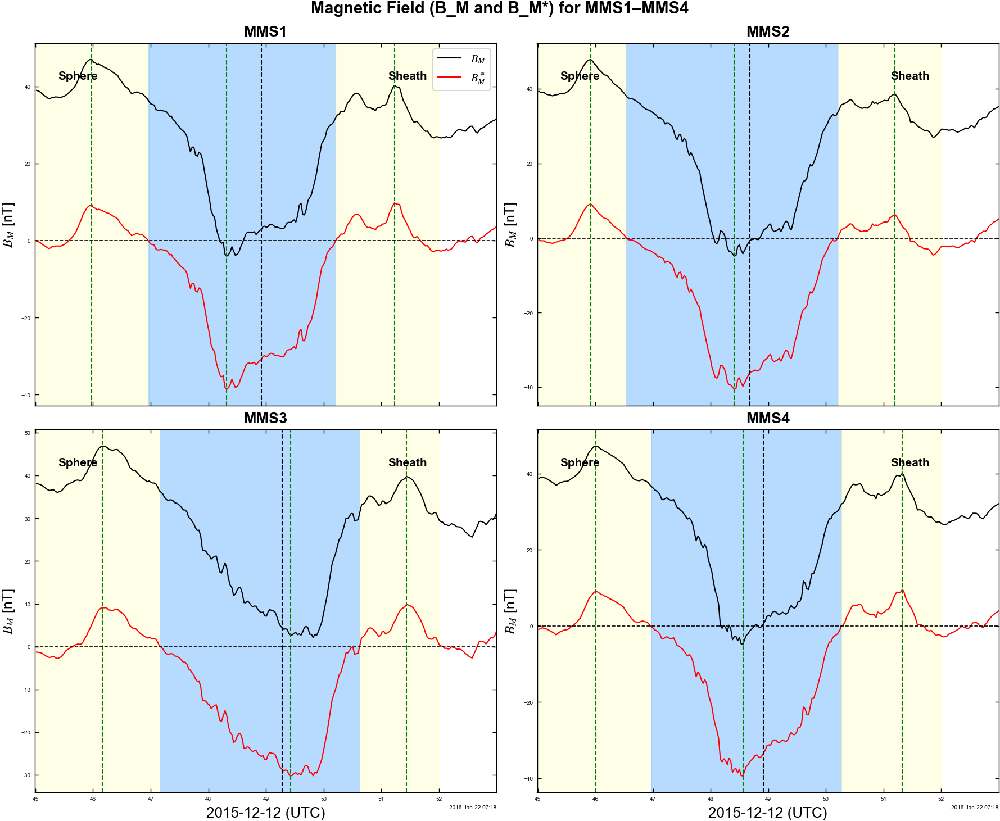

In [245]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

# Create a single figure with 2x2 subplots for MMS1–MMS4
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True)
axes = axes.flatten()  # flatten 2D array into 1D list for easy iteration

for i, sc in enumerate(sc_list):
    ax = axes[i]
    print(f"Plotting for {sc.upper()}...")

    # --- Compute necessary variables ---
    Bl_dict = {
        sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=del4)[0]
        for sc_ in sc_list
    }
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, '$B_g$']
    Bg = hall[sc].lmn_b.sel(time=slice(t1, del4)) - B_g
    B_hm = hall[sc].lmn_b.sel(time=slice(t1, del4)) - res_all[sc]['Bg_linear']
    # --- Locate features ---
    t1, t2 = times_dict[sc]
    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]

    # --- Determine plasma region ---
    plasma_region = ['Sheath', 'Sphere']
    if hall[sc].lmn_b.sel(LMN=0, time=slice(t1, del4)).values[0] > 0:
        plasma_region = ['Sphere', 'Sheath']

    # --- Plot magnetic field B_M and B_M* ---
    ax.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
            hall[sc].lmn_b.sel(LMN=1, time=slice(t1, del4)), c='k', lw=1, label=r'$B_M$')
    #ax.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
     #       Bg.sel(LMN=1), c='g', lw=1, label=r'$B_M^*$')
    ax.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
            res_all[sc]['Hall_BM'].sel(time=slice(t1, del4)), c='r', lw=1, label=r'$B_M^*$')

    # --- Annotations & formatting ---
    ax.set_title(sc.upper(), fontsize=13, fontweight='bold')
    ax.set_ylabel(r'$B_M$ [nT]', fontsize=12)
    ax.grid(False)

    # Marking vertical lines
    for tline, color in zip([Bl, th_maxl, th_min, th_maxr], ['k', 'g', 'g', 'g']):
        ax.axvline(x=tline.values, ls='--', c=color, lw=1)

    # Add plasma regions
    ax.annotate(plasma_region[0], xy=(0.05, 0.9), xycoords='axes fraction',
                fontsize=10, fontweight='bold', ha='left')
    ax.annotate(plasma_region[1], xy=(0.85, 0.9), xycoords='axes fraction',
                fontsize=10, fontweight='bold', ha='right')

    # Highlight intervals
    ax.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.3)
    ax.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.7)
    ax.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.3)

    # Set x-limits and ticks
    ax.set_xlim(hall[sc].lmn_b.time.sel(time=t1, method='nearest'),
                hall[sc].lmn_b.time.sel(time=del4, method='nearest'))
    ax.axhline(0, color='k', ls='--', lw=0.8)
# --- Common x-axis label ---
for ax in axes[-2:]:
    ax.set_xlabel('2015-12-12 (UTC)', fontsize=12.5)

# --- Legend and layout ---
axes[0].legend(loc='upper right', fontsize=10)
plt.tight_layout(pad=1.2)
plt.subplots_adjust(top=0.93)
fig.suptitle("Magnetic Field (B_M and B_M*) for MMS1–MMS4", fontsize=14, fontweight='bold')

# --- Save & show ---
plt.savefig(os.path.join(output_folder, f"{taistarttime}r.png"), dpi=600)
plt.show()


Plotting MMS1...
Plotting MMS2...
Plotting MMS3...
Plotting MMS4...


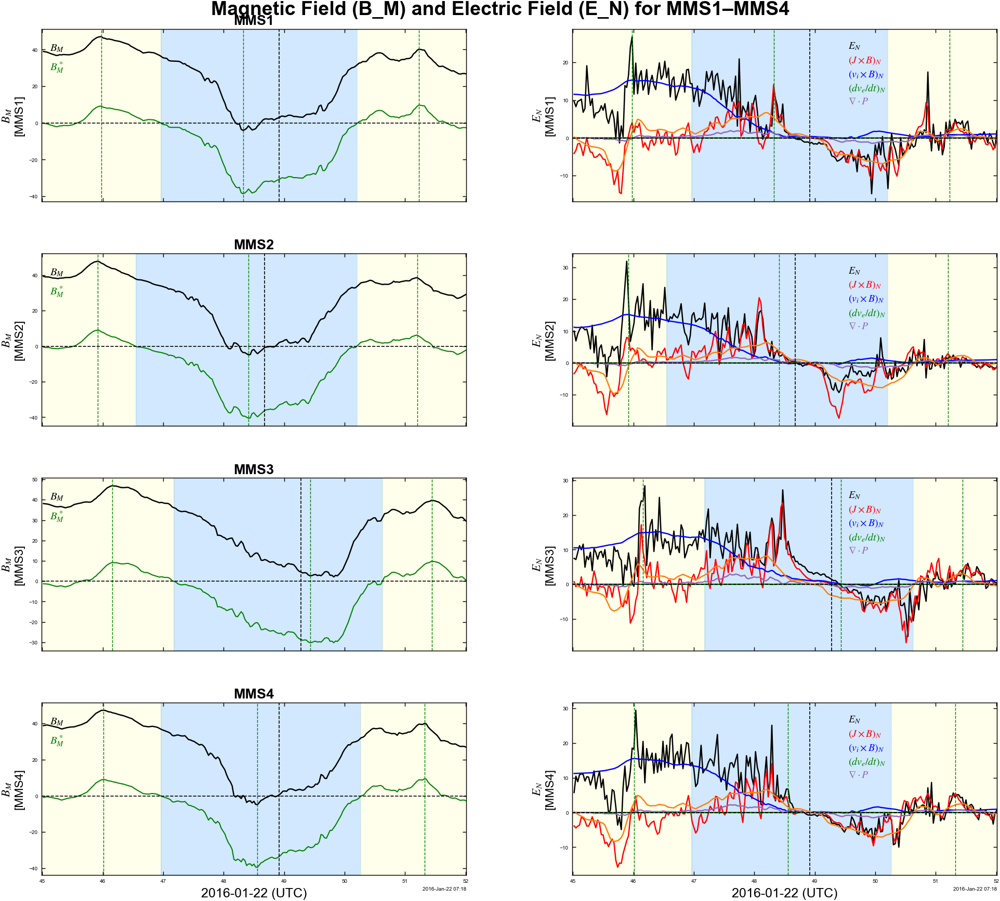

In [247]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
fig.suptitle("Magnetic Field (B_M) and Electric Field (E_N) for MMS1–MMS4", 
             fontsize=18, fontweight='bold', y=0.97)

for i, sc in enumerate(sc_list):
    print(f"Plotting {sc.upper()}...")

    # --- Derived quantities ---
    Bl_dict = {sc_: find(hall[sc_].lmn_b, LMN=0, d1=t1, d2=del4)[0] for sc_ in sc_list}
    Bl = Bl_dict[sc]
    B_g = df_all.loc[sc, '$B_g$']
    B_hm = hall[sc].lmn_b.sel(time=slice(t1, del4)) -  res_all[sc]["Bg_linear"]
    t1, t2 = times_dict[sc]

    th_maxl = B_hm.time.sel(time=slice(t1, Bl)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(t1, Bl)).values))
    th_min = B_hm.time.sel(time=slice(t1, t2)).isel(
        time=np.argmin(B_hm.sel(LMN=1, time=slice(t1, t2)).values))
    th_maxr = B_hm.time.sel(time=slice(Bl, t2)).isel(
        time=np.argmax(B_hm.sel(LMN=1, time=slice(Bl, t2)).values))
    th_0 = find(B_hm, LMN=1, d1=th_maxl, d2=Bl)[0]
    th_1 = find(B_hm, LMN=1, d1=th_min, d2=th_maxr)[0]

    # ============ COLUMN 1: B_M ============
    axB = axes[i, 0]
    axB.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
             hall[sc].lmn_b.sel(LMN=1, time=slice(t1, del4)),
             c='k', lw=1.2)
    axB.plot(hall[sc].lmn_b.time.sel(time=slice(t1, del4)),
             B_hm.sel(LMN=1),
             c='g', lw=1)
    axB.set_ylabel(rf'$B_M$' + '\n' + rf'[{sc.upper()}]', fontsize=11)
    axB.set_title(f"{sc.upper()}", fontsize=13, fontweight='bold', pad=4)

    # Text labels inside the plot
    axB.text(0.02, 0.92, r'$B_M$', color='k', transform=axB.transAxes,
             fontsize=10, fontweight='bold', ha='left', va='top')
    axB.text(0.02, 0.82, r'$B_M^*$', color='g', transform=axB.transAxes,
             fontsize=10, fontweight='bold', ha='left', va='top')

    # ============ COLUMN 2: E_N ============
    axE = axes[i, 1]
    axE.plot(hall[sc].lmn_e.time.sel(time=slice(t1, del4)),
             hall[sc].lmn_e.sel(LMN=2, time=slice(t1, del4)),
             c='k', lw=1.2)
    axE.plot(hall[sc].jxb.time.sel(time=slice(t1, del4)),
             hall[sc].jxb.sel(LMN=2, time=slice(t1, del4)),
             c='r', lw=1.2)
    axE.plot(hall[sc].vib.time.sel(time=slice(t1, del4)),
             hall[sc].vib.sel(LMN=2, time=slice(t1, del4)),
             c='b', lw=1.2)
    axE.plot(hall[sc].dvedt.time.sel(time=slice(t1, del4)),
             hall[sc].dvedt.sel(LMN=2, time=slice(t1, del4)),
             c='g', lw=1.2)
    axE.plot(hall[sc].eDivP.time.sel(time=slice(t1, del4)),
             hall[sc].eDivP.sel(LMN=2, time=slice(t1, del4)),
             c='tab:purple', lw=1.2)
    axE.plot(hall[sc].iDivP.time.sel(time=slice(t1, del4)),
             hall[sc].iDivP.sel(LMN=2, time=slice(t1, del4)),
             c='tab:orange', lw=1.2)
    axE.axhline(0, color='k', ls='--', lw=0.8)
    axE.set_ylabel(rf'$E_N$' + '\n' + rf'[{sc.upper()}]', fontsize=11)

    # Text labels (color-coded)
    axE.text(0.65, 0.93, r'$E_N$', color='k', transform=axE.transAxes,
             fontsize=9.5, fontweight='bold', ha='left', va='top')
    axE.text(0.65, 0.85, r'$(J\times B)_N$', color='r', transform=axE.transAxes,
             fontsize=9.5, fontweight='bold', ha='left', va='top')
    axE.text(0.65, 0.77, r'$(v_i\times B)_N$', color='b', transform=axE.transAxes,
             fontsize=9.5, fontweight='bold', ha='left', va='top')
    axE.text(0.65, 0.69, r'$(dv_e/dt)_N$', color='g', transform=axE.transAxes,
             fontsize=9.5, fontweight='bold', ha='left', va='top')
    axE.text(0.65, 0.61, r'$\nabla \cdot P$', color='tab:purple', transform=axE.transAxes,
             fontsize=9.5, fontweight='bold', ha='left', va='top')

    # --- Shared formatting ---
    for ax in [axB, axE]:
        ax.axvline(x=Bl.values, ls='--', c='k', lw=0.8)
        for tline in [th_maxl, th_min, th_maxr]:
            ax.axvline(x=tline.values, ls='--', c='g', lw=0.7)
        ax.axvspan(t1, th_0.values, color=(1, 1, 0.7), alpha=0.25)
        ax.axvspan(th_0.values, th_1.values, color=(0.6, 0.8, 1.0), alpha=0.45)
        ax.axvspan(th_1.values, t2, color=(1, 1, 0.7), alpha=0.25)
        ax.grid(False)
        ax.set_xlim(hall[sc].lmn_b.time.sel(time=t1, method='nearest'),
                    hall[sc].lmn_b.time.sel(time=t2, method='nearest'))
        ax.axhline(0, color='k', ls='--', lw=0.8)
        #ax.axhline(res_all[sc]["Bg_linear"].mean(), color='g', ls='--', lw=0.8)
# X-axis labels only on bottom row
for ax in axes[-1, :]:
    ax.set_xlabel('2016-01-22 (UTC)', fontsize=12)

plt.tight_layout(pad=1.4)
plt.subplots_adjust(top=0.94, hspace=0.3, wspace=0.25)
plt.savefig(os.path.join(output_folder, f"{taistarttime}_s.png"), dpi=600)
plt.show()


Plotting MMS1 Electric Field Components...
Plotting MMS2 Electric Field Components...
Plotting MMS3 Electric Field Components...
Plotting MMS4 Electric Field Components...


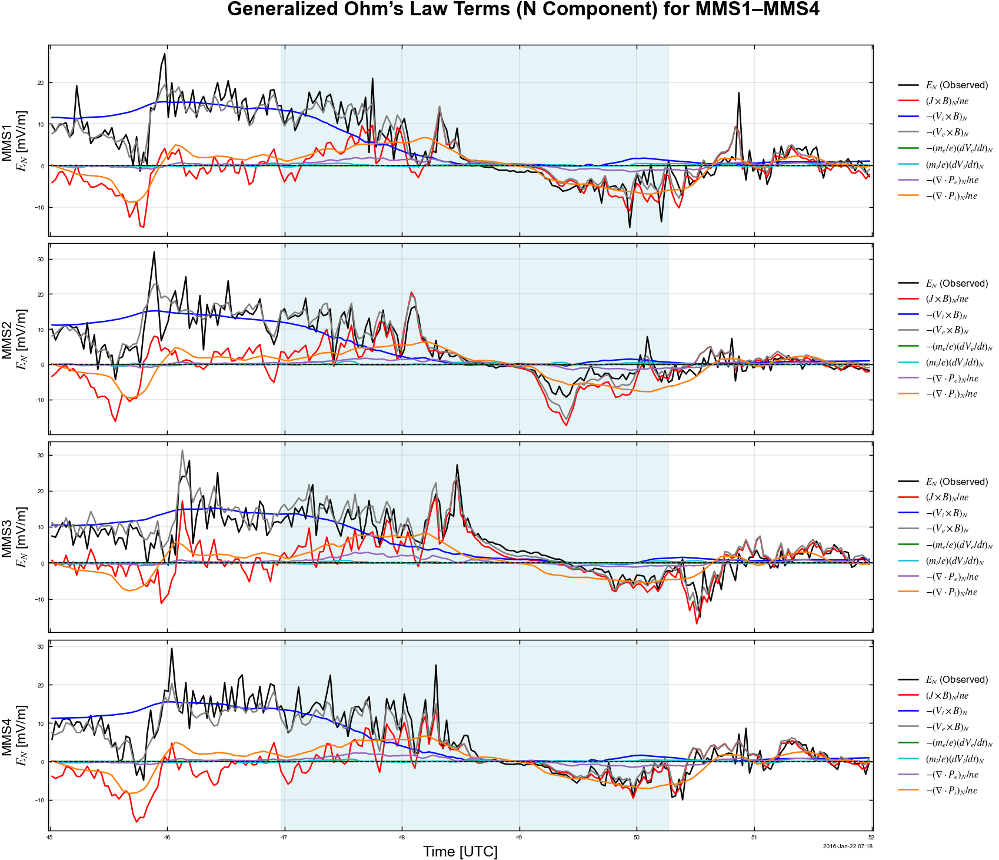

In [248]:
import matplotlib.pyplot as plt
import os

sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
fig.suptitle("Generalized Ohm’s Law Terms (N Component) for MMS1–MMS4",
             fontsize=16, fontweight='bold')

for i, sc in enumerate(sc_list):
    print(f"Plotting {sc.upper()} Electric Field Components...")

    t1, t2 = times_dict[sc]
    ax = axes[i]

    # --- Plot individual terms ---
    lines = []
    labels = []

    ln1, = ax.plot(hall[sc].lmn_e.time.sel(time=slice(t1, t2)),
                   hall[sc].lmn_e.sel(LMN=2, time=slice(t1, t2)),
                   c='k', lw=1.2, label=r'$E_N$ (Observed)')
    ln2, = ax.plot(hall[sc].jxb.time.sel(time=slice(t1, t2)),
                   hall[sc].jxb.sel(LMN=2, time=slice(t1, t2)),
                   c='r', lw=1.2, label=r'$(J\times B)_N/ne$')
    ln3, = ax.plot(hall[sc].vib.time.sel(time=slice(t1, t2)),
                   hall[sc].vib.sel(LMN=2, time=slice(t1, t2)),
                   c='b', lw=1.2, label=r'$-(V_i\times B)_N$')
    ln4, = ax.plot(hall[sc].veb.time.sel(time=slice(t1, t2)),
                   hall[sc].veb.sel(LMN=2, time=slice(t1, t2)),
                   c='tab:grey', lw=1.2, label=r'$-(V_e\times B)_N$')
    ln5, = ax.plot(hall[sc].dvedt.time.sel(time=slice(t1, t2)),
                   hall[sc].dvedt.sel(LMN=2, time=slice(t1, t2)),
                   c='g', lw=1.2, label=r'$-(m_e/e)(dV_e/dt)_N$')
    ln6, = ax.plot(hall[sc].dvidt.time.sel(time=slice(t1, t2)),
                   hall[sc].dvidt.sel(LMN=2, time=slice(t1, t2)),
                   c='tab:cyan', lw=1.2, label=r'$(m_i/e)(dV_i/dt)_N$')
    ln7, = ax.plot(hall[sc].eDivP.time.sel(time=slice(t1, t2)),
                   hall[sc].eDivP.sel(LMN=2, time=slice(t1, t2)),
                   c='tab:purple', lw=1.2, label=r'$-(\nabla\cdot P_e)_N/ne$')
    ln8, = ax.plot(hall[sc].iDivP.time.sel(time=slice(t1, t2)),
                   hall[sc].iDivP.sel(LMN=2, time=slice(t1, t2)),
                   c='tab:orange', lw=1.2, label=r'$-(\nabla\cdot P_i)_N/ne$')

    # Formatting
    ax.axhline(0, color='k', ls='--', lw=0.8)
    ax.set_ylabel(f'{sc.upper()}\n$E_N$ [mV/m]', fontsize=11)
    ax.set_xlim(hall[sc].lmn_e.time.sel(time=t1, method='nearest'),
                hall[sc].lmn_e.time.sel(time=t2, method='nearest'))
    ax.grid(True, alpha=0.3)

    # Add shaded reconnection regions if applicable
    ax.axvspan(th_0.values, th_1.values, color='lightblue', alpha=0.3)

    # Legend on the right side (compact)
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5),
              fontsize=8, frameon=False, ncol=1)

# Shared X label
axes[-1].set_xlabel('Time [UTC]', fontsize=12)

plt.tight_layout(pad=1.2)
plt.subplots_adjust(top=0.93, right=0.83)
plt.savefig(os.path.join(output_folder, f"{taistarttime}_t.png"), dpi=600)
plt.show()


Plotting Ion terms for MMS1
Plotting Ion terms for MMS2
Plotting Ion terms for MMS3
Plotting Ion terms for MMS4
Plotting Electron terms for MMS1
Plotting Electron terms for MMS2
Plotting Electron terms for MMS3
Plotting Electron terms for MMS4
Plotting Macro terms for MMS1
Plotting Macro terms for MMS2
Plotting Macro terms for MMS3
Plotting Macro terms for MMS4


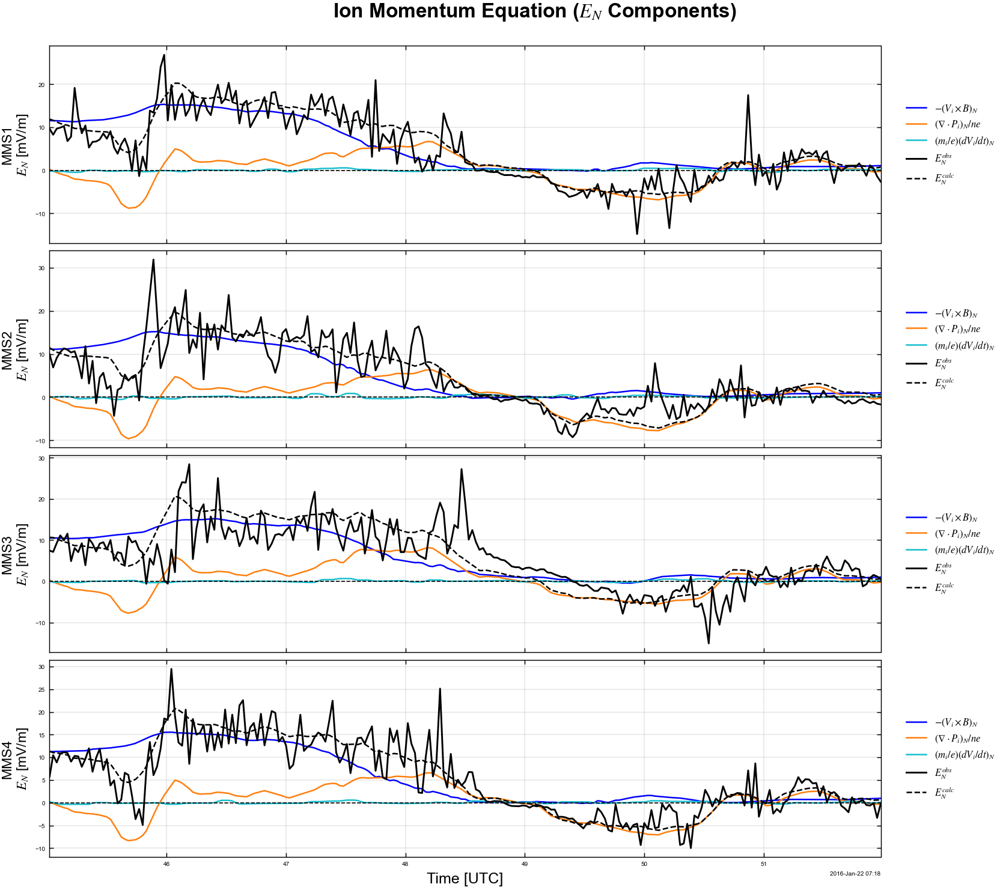

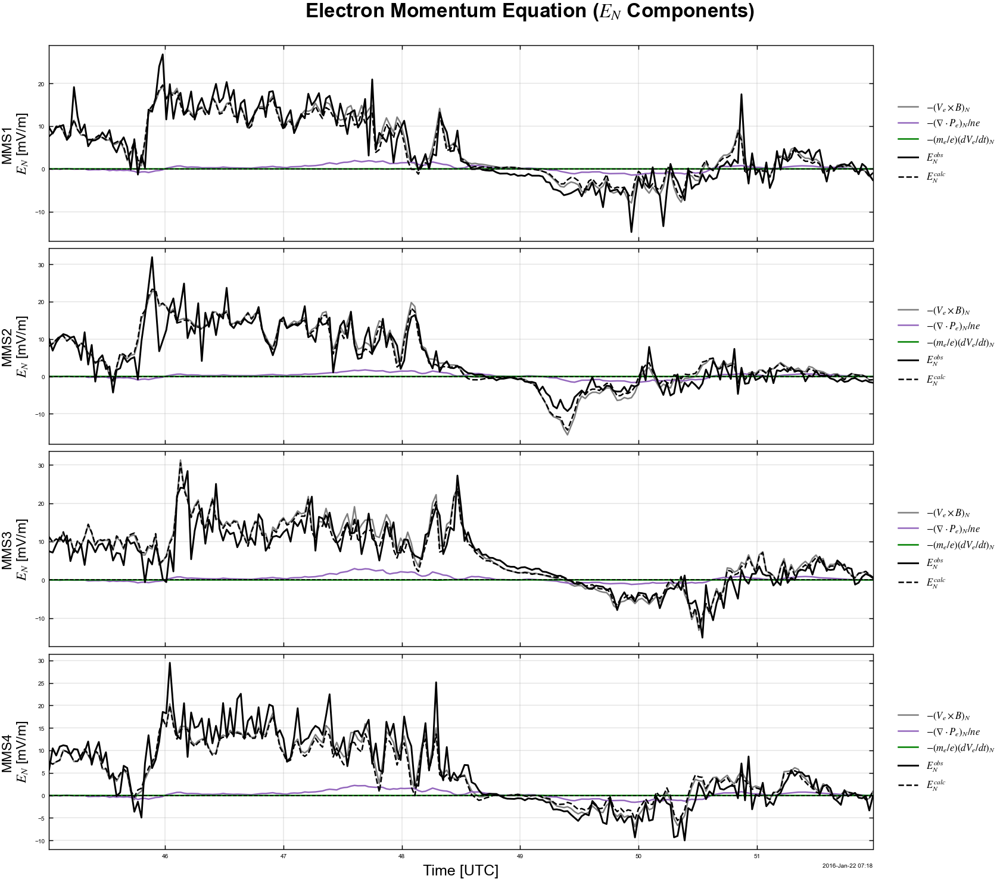

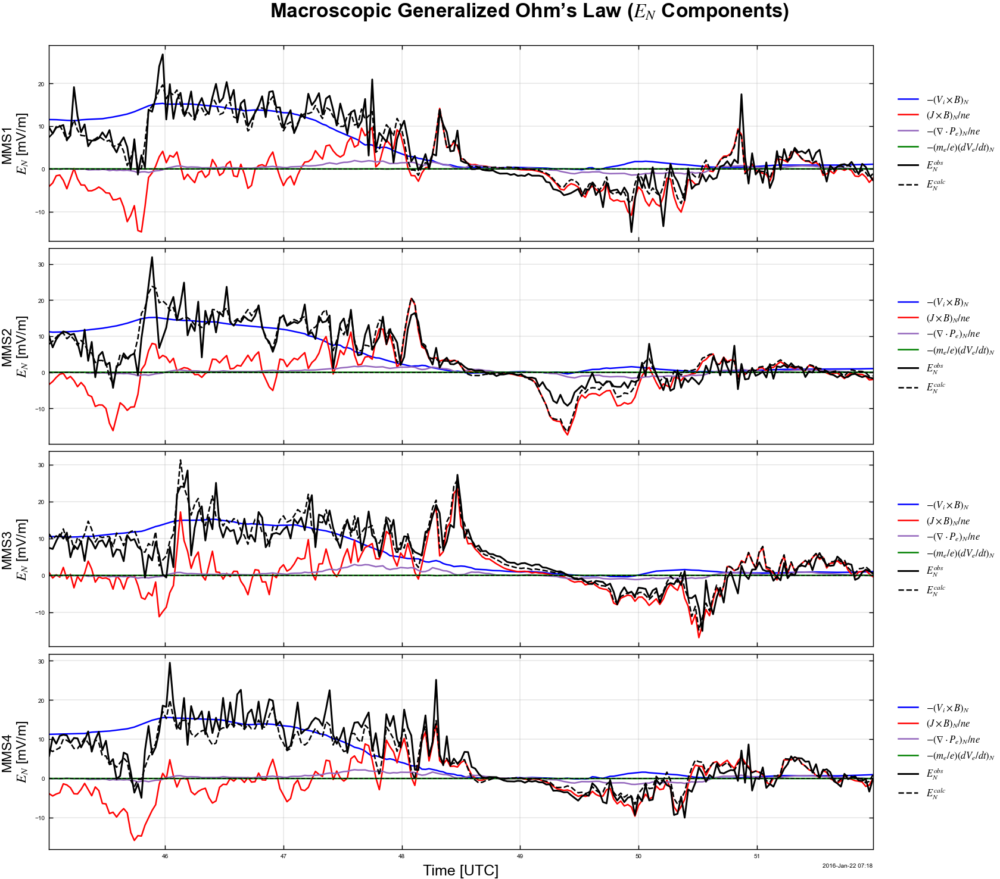

In [249]:
sc_list = ['mms1', 'mms2', 'mms3', 'mms4']

# ===============================================================
# Helper Function
# ===============================================================
def plot_ohms_terms(category, terms, colors, labels, suptitle, filename, reconstruct_expr):
    """
    Plot Generalized Ohm's Law terms for all spacecraft, including
    observed and reconstructed E_N (E_calc).
    """
    fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
    fig.suptitle(suptitle, fontsize=16, fontweight='bold')

    for i, sc in enumerate(sc_list):
        ax = axes[i]
        t1, t2 = times_dict[sc]

        print(f"Plotting {category} terms for {sc.upper()}")

        # Plot individual terms
        for term, color, label in zip(terms, colors, labels):
            ax.plot(hall[sc][term].time.sel(time=slice(t1, t2)),
                    hall[sc][term].sel(LMN=2, time=slice(t1, t2)),
                    color=color, lw=1.2, label=label)

        # Observed Electric Field
        E_obs = hall[sc].lmn_e.sel(LMN=2, time=slice(t1, t2))
        ax.plot(E_obs.time, E_obs, color='k', lw=1.4, label=r'$E_N^{obs}$')

        # Calculated Electric Field
        hall[sc]['E_calc'] = reconstruct_expr(hall[sc])
        E_calc = hall[sc]['E_calc'].sel(LMN=2, time=slice(t1, t2))
        ax.plot(E_calc.time, E_calc, color='k', lw=1.2, ls='--', label=r'$E_N^{calc}$')

        # Formatting
        ax.axhline(0, color='k', ls='--', lw=0.8)
        ax.set_ylabel(f'{sc.upper()}\n$E_N$ [mV/m]', fontsize=11)
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5),
                  fontsize=8, frameon=False)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(E_obs.time[0], E_obs.time[-1])
       
    plt.tight_layout(pad=1.2)
    plt.savefig(os.path.join(output_folder, f"_{filename}_u.png"), dpi=600) 
    plt.subplots_adjust(top=0.93, right=0.82)
    axes[-1].set_xlabel('Time [UTC]', fontsize=12)

# ===============================================================
# 1️⃣ Ion Momentum Equation
# ===============================================================
ion_terms   = ['vib', 'iDivP', 'dvidt']
ion_colors  = ['b', 'tab:orange', 'tab:cyan']
ion_labels  = [
    r'$-(V_i\times B)_N$',
    r'$(\nabla\cdot P_i)_N/ne$',
    r'$(m_i/e)(dV_i/dt)_N$'
]

plot_ohms_terms(
    category='Ion',
    terms=ion_terms,
    colors=ion_colors,
    labels=ion_labels,
    suptitle='Ion Momentum Equation ($E_N$ Components)',
    filename=f'{taistarttime}_ion_p',
    reconstruct_expr=lambda d: (d['vib'] + d['iDivP'] - d['dvidt'])
)

# ===============================================================
# 2️⃣ Electron Momentum Equation
# ===============================================================
electron_terms   = ['veb', 'eDivP', 'dvedt']
electron_colors  = ['tab:grey', 'tab:purple', 'g']
electron_labels  = [
    r'$-(V_e\times B)_N$',
    r'$-(\nabla\cdot P_e)_N/ne$',
    r'$-(m_e/e)(dV_e/dt)_N$'
]

plot_ohms_terms(
    category='Electron',
    terms=electron_terms,
    colors=electron_colors,
    labels=electron_labels,
    suptitle='Electron Momentum Equation ($E_N$ Components)',
    filename=f'{taistarttime}_elecp',
    reconstruct_expr=lambda d: (d['veb'] - d['eDivP'] - d['dvedt'])
)

# ===============================================================
# 3️⃣ Macroscopic (Two-fluid) Generalized Ohm’s Law
# ===============================================================
macro_terms   = ['vib', 'jxb', 'eDivP', 'dvedt']
macro_colors  = ['b', 'r', 'tab:purple', 'g']
macro_labels  = [
    r'$-(V_i\times B)_N$',
    r'$(J\times B)_N/ne$',
    r'$-(\nabla\cdot P_e)_N/ne$',
    r'$-(m_e/e)(dV_e/dt)_N$'
]

plot_ohms_terms(
    category='Macro',
    terms=macro_terms,
    colors=macro_colors,
    labels=macro_labels,
    suptitle='Macroscopic Generalized Ohm’s Law ($E_N$ Components)',
    filename=f'{taistarttime}_macro',
    reconstruct_expr=lambda d: (d['vib'] + d['jxb'] - d['eDivP'] - d['dvedt'])
)


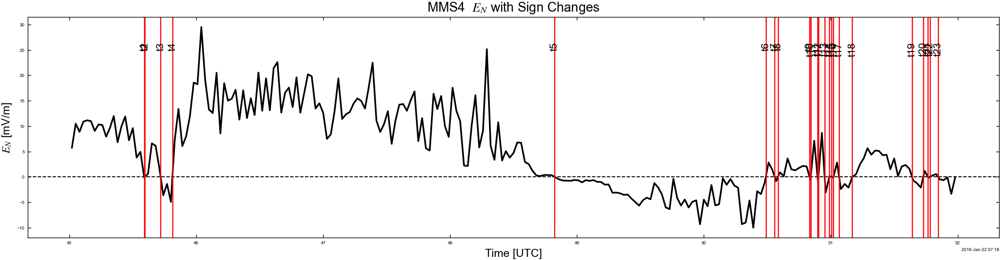


Zero-crossing timestamps:
t1 = 2016-01-22T07:18:45.588775471
t2 = 2016-01-22T07:18:45.594632530
t3 = 2016-01-22T07:18:45.718794604
t4 = 2016-01-22T07:18:45.811778502
t5 = 2016-01-22T07:18:48.822816136
t6 = 2016-01-22T07:18:50.487982258
t7 = 2016-01-22T07:18:50.558447890
t8 = 2016-01-22T07:18:50.583777570
t9 = 2016-01-22T07:18:50.832712336
t10 = 2016-01-22T07:18:50.841938139
t11 = 2016-01-22T07:18:50.895625610
t12 = 2016-01-22T07:18:50.902876046
t13 = 2016-01-22T07:18:50.951712844
t14 = 2016-01-22T07:18:50.988167358
t15 = 2016-01-22T07:18:51.006125619
t16 = 2016-01-22T07:18:51.020804204
t17 = 2016-01-22T07:18:51.065798089
t18 = 2016-01-22T07:18:51.169564000
t19 = 2016-01-22T07:18:51.640901657
t20 = 2016-01-22T07:18:51.728653859
t21 = 2016-01-22T07:18:51.766032935
t22 = 2016-01-22T07:18:51.781142421
t23 = 2016-01-22T07:18:51.845626929


In [253]:
import numpy as np
import matplotlib.pyplot as plt

def plot_EN_with_vertical_bars(sc, hall, times_dict, eps=0.02):
    
    t_start, t_end = times_dict[sc]

    # Extract E_N (mV/m)
    EN = hall[sc].lmn_e.sel(LMN=2, time=slice(t_start, t_end))

    t = EN.time.values
    y = EN.values.astype(float)

    # Remove tiny noise around zero
    y[np.abs(y) <= eps] = 0.0
    sign = np.sign(y)

    # Forward-fill zeros
    for i in range(1, len(sign)):
        if sign[i] == 0:
            sign[i] = sign[i-1]

    # Find sign-change indices
    idx = np.where(np.diff(sign) != 0)[0]

    # Interpolate exact zero-crossing times
    zero_times = []
    for k in idx:
        y0, y1 = y[k], y[k+1]
        if (y1 - y0) != 0:
            frac = (-y0) / (y1 - y0)
            tz = t[k] + (t[k+1] - t[k]) * frac
            zero_times.append(tz)

    # =======================
    # Plot
    # =======================
    fig, ax = plt.subplots(figsize=(15,4))

    ax.plot(EN.time, EN, color='black', lw=1.8)
    ax.axhline(0, color='k', ls='--', lw=1)

    # Add vertical bars + labels
    ymax = np.max(np.abs(y)) * 0.9
    for i, tz in enumerate(zero_times):
        ax.axvline(tz, color='red', lw=1.2)
        ax.text(tz, ymax, f"t{i+1}", rotation=90,
                va='top', ha='center', fontsize=11)

    ax.set_title(f"{sc.upper()}  $E_N$ with Sign Changes", fontsize=14)
    ax.set_ylabel(r"$E_N$ [mV/m]", fontsize=12)
    ax.set_xlabel("Time [UTC]", fontsize=12)
    ax.grid(False)

    plt.tight_layout()
    plt.show()

    # Print timestamps for use
    print("\nZero-crossing timestamps:")
    for i, tz in enumerate(zero_times):
        print(f"t{i+1} =", tz)

    return zero_times


# ==========================
# Run
# ==========================
# sc = "mms4"
zero_times = plot_EN_with_vertical_bars(sc, hall, times_dict, eps=0.02)

# Then you can define:
# t1 = zero_times[0]
#t2 = zero_times[1]
# t3 = zero_times[2]

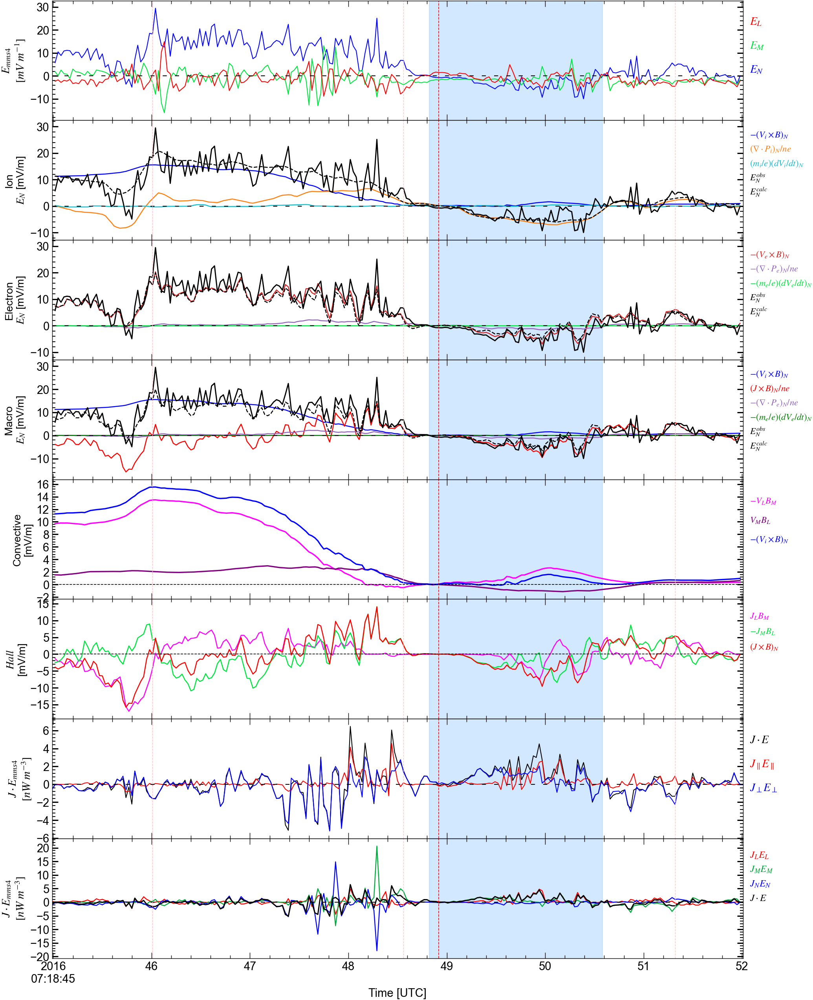

In [254]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


# ==========================================
# Fixed spacecraft
# ==========================================
sc = "mms4"


def add_color_text_legend(
    ax,
    labels,
    colors,
    x=1.01,
    y0=0.86,
    dy=0.12,
    fs=11
):
    for i, (lab, c) in enumerate(zip(labels, colors)):
        ax.text(
            x,
            y0 - i * dy,
            lab,
            transform=ax.transAxes,
            color=c,
            fontsize=fs,
            style="italic",
            va="center"
        )


def plot_ohms_4panels_for_mms3(
    sc,
    times_dict,
    hall,
    df_all,
    output_folder,
    taistarttime
):
    """
    Panels:
      axs[0] Electric field in LMN
      axs[1] Ion momentum equation terms
      axs[2] Electron momentum equation terms
      axs[3] Generalized Ohm's law terms
      axs[4] Ion convective electric-field cross terms
      axs[5] Hall JxB cross terms
      axs[6] J·E, parallel and perpendicular contributions
      axs[7] J_L E_L, J_M E_M, J_N E_N, and total J·E
    """

    # ----------------------------------------------------------
    # Time window
    # ----------------------------------------------------------
    t1, t2 = times_dict[sc]

    # ----------------------------------------------------------
    # Find BL = 0 and region marker times
    # ----------------------------------------------------------
    Bl = find(
        hall[sc].lmn_b,
        LMN=0,
        d1=t1,
        d2=t2
    )[0]

    B_hm_full = hall[sc].lmn_b.sel(
        time=slice(t1, t2)
    )

    th_maxl = B_hm_full.time.sel(
        time=slice(t1, Bl)
    ).isel(
        time=np.argmax(
            B_hm_full.sel(
                LMN=1,
                time=slice(t1, Bl)
            ).values
        )
    )

    th_min = B_hm_full.time.sel(
        time=slice(t1, t2)
    ).isel(
        time=np.argmin(
            B_hm_full.sel(
                LMN=1,
                time=slice(t1, t2)
            ).values
        )
    )

    th_maxr = B_hm_full.time.sel(
        time=slice(Bl, t2)
    ).isel(
        time=np.argmax(
            B_hm_full.sel(
                LMN=1,
                time=slice(Bl, t2)
            ).values
        )
    )

    th_0 = find(
        B_hm_full,
        LMN=1,
        d1=th_maxl,
        d2=Bl
    )[0]

    th_1 = find(
        B_hm_full,
        LMN=1,
        d1=th_min,
        d2=th_maxr
    )[0]

    # ==========================================================
    # Figure: eight panels
    # ==========================================================
    fig, axs = plt.subplots(
        8,
        1,
        figsize=(17, 18),
        sharex=True,
        gridspec_kw={"hspace": 0}
    )

    # ==========================================================
    # Common observed EN
    # ==========================================================
    E_obs = hall[sc].lmn_e.sel(
        LMN=2,
        time=slice(t1, t2)
    )

    # ==========================================================
    # 0) Electric field in LMN
    # ==========================================================
    ax = axs[0]

    ax.plot(
        hall[sc].lmn_e.time.sel(
            time=slice(t1, t2)
        ),
        hall[sc].lmn_e.sel(
            LMN=2,
            time=slice(t1, t2)
        ),
        c="b",
        lw=1
    )

    ax.plot(
        hall[sc].lmn_e.time.sel(
            time=slice(t1, t2)
        ),
        hall[sc].lmn_e.sel(
            LMN=1,
            time=slice(t1, t2)
        ),
        c=(0 / 255, 230 / 255, 64 / 255),
        lw=1
    )

    ax.plot(
        hall[sc].lmn_e.time.sel(
            time=slice(t1, t2)
        ),
        hall[sc].lmn_e.sel(
            LMN=0,
            time=slice(t1, t2)
        ),
        c="r",
        lw=1
    )

    ax.set_ylabel(
        r"$\mathbf{\mathit{E_{%s}}}$" % sc
        + "\n"
        + r"$\mathit{[mV\ m^{-1}]}$",
        fontsize=14
    )

    ax.axhline(
        0,
        c="k",
        ls=(0, (5, 10)),
        lw=1
    )

    ax.annotate(
        r"$\mathit{E_L}$",
        xy=(1.01, 0.8),
        xycoords="axes fraction",
        fontsize=14,
        color="r",
        style="italic"
    )

    ax.annotate(
        r"$\mathit{E_M}$",
        xy=(1.01, 0.6),
        xycoords="axes fraction",
        fontsize=14,
        color=(0 / 255, 230 / 255, 64 / 255),
        style="italic"
    )

    ax.annotate(
        r"$\mathit{E_N}$",
        xy=(1.01, 0.4),
        xycoords="axes fraction",
        fontsize=14,
        color="b",
        style="italic"
    )

    # ==========================================================
    # 1) Ion momentum equation
    # ==========================================================
    ion_terms = [
        "vib",
        "iDivP",
        "dvidt"
    ]

    ion_colors = [
        "b",
        "tab:orange",
        "tab:cyan"
    ]

    ion_labels = [
        r"$-(V_i\times B)_N$",
        r"$(\nabla\cdot P_i)_N/ne$",
        r"$(m_i/e)(dV_i/dt)_N$"
    ]

    ax = axs[1]

    for term, c in zip(
        ion_terms,
        ion_colors
    ):
        ax.plot(
            hall[sc][term].time.sel(
                time=slice(t1, t2)
            ),
            hall[sc][term].sel(
                LMN=2,
                time=slice(t1, t2)
            ),
            color=c,
            lw=1.2
        )

    E_calc_ion = (
        hall[sc]["vib"]
        + hall[sc]["iDivP"]
        - hall[sc]["dvidt"]
    )

    ax.plot(
        E_obs.time,
        E_obs,
        color="k",
        lw=1.4
    )

    ax.plot(
        E_calc_ion.sel(
            LMN=2,
            time=slice(t1, t2)
        ).time,
        E_calc_ion.sel(
            LMN=2,
            time=slice(t1, t2)
        ),
        color="k",
        lw=1.2,
        ls="--"
    )

    ax.set_ylabel(
        "Ion\n"
        r"$E_N$ [mV/m]",
        fontsize=13
    )

    ax.axhline(
        0,
        c="k",
        ls=(0, (5, 10)),
        lw=1
    )

    add_color_text_legend(
        ax,
        ion_labels
        + [
            r"$E_N^{obs}$",
            r"$E_N^{calc}$"
        ],
        ion_colors
        + [
            "k",
            "k"
        ],
        y0=0.88
    )

    # ==========================================================
    # 2) Electron momentum equation
    # ==========================================================
    electron_terms = [
        "veb",
        "eDivP",
        "dvedt"
    ]

    electron_colors = [
        "tab:red",
        "tab:purple",
        (0 / 255, 230 / 255, 64 / 255)
    ]

    electron_labels = [
        r"$-(V_e\times B)_N$",
        r"$-(\nabla\cdot P_e)_N/ne$",
        r"$-(m_e/e)(dV_e/dt)_N$"
    ]

    ax = axs[2]

    for term, c in zip(
        electron_terms,
        electron_colors
    ):
        ax.plot(
            hall[sc][term].time.sel(
                time=slice(t1, t2)
            ),
            hall[sc][term].sel(
                LMN=2,
                time=slice(t1, t2)
            ),
            color=c,
            lw=1.2
        )

    E_calc_e = (
        hall[sc]["veb"]
        - hall[sc]["eDivP"]
        - hall[sc]["dvedt"]
    )

    ax.plot(
        E_obs.time,
        E_obs,
        color="k",
        lw=1.4
    )

    ax.plot(
        E_calc_e.sel(
            LMN=2,
            time=slice(t1, t2)
        ).time,
        E_calc_e.sel(
            LMN=2,
            time=slice(t1, t2)
        ),
        color="k",
        lw=1.2,
        ls="--"
    )

    ax.set_ylabel(
        "Electron\n"
        r"$E_N$ [mV/m]",
        fontsize=13
    )

    ax.axhline(
        0,
        c="k",
        ls=(0, (5, 10)),
        lw=1
    )

    add_color_text_legend(
        ax,
        electron_labels
        + [
            r"$E_N^{obs}$",
            r"$E_N^{calc}$"
        ],
        electron_colors
        + [
            "k",
            "k"
        ],
        y0=0.88
    )

    # ==========================================================
    # 3) Generalized Ohm's law
    # ==========================================================
    macro_terms = [
        "vib",
        "jxb",
        "eDivP",
        "dvedt"
    ]

    macro_colors = [
        "b",
        "r",
        "tab:purple",
        "g"
    ]

    macro_labels = [
        r"$-(V_i\times B)_N$",
        r"$(J\times B)_N/ne$",
        r"$-(\nabla\cdot P_e)_N/ne$",
        r"$-(m_e/e)(dV_e/dt)_N$"
    ]

    ax = axs[3]

    for term, c in zip(
        macro_terms,
        macro_colors
    ):
        ax.plot(
            hall[sc][term].time.sel(
                time=slice(t1, t2)
            ),
            hall[sc][term].sel(
                LMN=2,
                time=slice(t1, t2)
            ),
            color=c,
            lw=1.2
        )

    E_calc_macro = (
        hall[sc]["vib"]
        + hall[sc]["jxb"]
        - hall[sc]["eDivP"]
        - hall[sc]["dvedt"]
    )

    ax.plot(
        E_obs.time,
        E_obs,
        color="k",
        lw=1.4
    )

    ax.plot(
        E_calc_macro.sel(
            LMN=2,
            time=slice(t1, t2)
        ).time,
        E_calc_macro.sel(
            LMN=2,
            time=slice(t1, t2)
        ),
        color="k",
        lw=1.2,
        ls="--"
    )

    ax.set_ylabel(
        "Macro\n"
        r"$E_N$ [mV/m]",
        fontsize=13
    )

    ax.axhline(
        0,
        c="k",
        ls=(0, (5, 10)),
        lw=1
    )

    add_color_text_legend(
        ax,
        macro_labels
        + [
            r"$E_N^{obs}$",
            r"$E_N^{calc}$"
        ],
        macro_colors
        + [
            "k",
            "k"
        ],
        y0=0.88
    )

    # ==========================================================
    # 4) Ion convective cross terms
    # ==========================================================
    ax = axs[4]

    B_L = hall[sc].lmn_b.sel(
        LMN=0,
        time=slice(t1, t2)
    )

    BM_hm = hall[sc].lmn_b.sel(
        LMN=1,
        time=slice(t1, t2)
    )

    V_L = hall[sc].lmn_vi.sel(
        LMN=0,
        time=slice(t1, t2)
    )

    V_M = hall[sc].lmn_vi.sel(
        LMN=1,
        time=slice(t1, t2)
    )

    # km/s × nT -> mV/m
    VL_BM = -V_L * BM_hm * 1e-3
    VM_BL = V_M * B_L * 1e-3

    E_N = hall[sc]["vib"].sel(
        LMN=2,
        time=slice(t1, t2)
    )

    ax.plot(
        VL_BM.time,
        VL_BM,
        c="magenta",
        lw=1.6
    )

    ax.plot(
        VM_BL.time,
        VM_BL,
        c="purple",
        lw=1.6
    )

    ax.plot(
        E_N.time,
        E_N,
        c="b",
        lw=1.6
    )

    ax.axhline(
        0,
        color="k",
        ls="--",
        lw=0.8
    )

    ax.set_ylabel(
        "Convective\n[mV/m]",
        fontsize=13
    )

    add_color_text_legend(
        ax,
        [
            r"$-V_LB_M$",
            r"$V_MB_L$",
            r"$-(V_i\times B)_N$"
        ],
        [
            "magenta",
            "purple",
            "b"
        ],
        y0=0.82,
        dy=0.16
    )

    # ==========================================================
    # 5) Hall J×B cross terms
    # ==========================================================
    ax = axs[5]

    BL = hall[sc].lmn_b.sel(
        LMN=0,
        time=slice(t1, t2)
    )

    BM_hm = hall[sc].lmn_b.sel(
        LMN=1,
        time=slice(t1, t2)
    )

    JL = hall[sc].lmn_j.sel(
        LMN=0,
        time=slice(t1, t2)
    )

    JM = hall[sc].lmn_j.sel(
        LMN=1,
        time=slice(t1, t2)
    )

    JL_BM = (
        JL
        * BM_hm
        * 1e-21
        / (ni * q_e)
    )

    JM_BL = (
        -JM
        * BL
        * 1e-21
        / (ni * q_e)
    )

    JxB_N = hall[sc]["jxb"].sel(
        LMN=2,
        time=slice(t1, t2)
    )

    EN_sc = hall[sc].lmn_e.sel(
        LMN=2,
        time=slice(t1, t2)
    )

    ax.plot(
        JL_BM.time,
        JL_BM,
        c="magenta",
        lw=1.2
    )

    ax.plot(
        JM_BL.time,
        JM_BL,
        c=(0 / 255, 230 / 255, 64 / 255),
        lw=1.2
    )

    ax.plot(
        JxB_N.time,
        JxB_N,
        c="r",
        lw=1.2
    )

    # ax.plot(
    #     EN_sc.time,
    #     EN_sc,
    #     c="k",
    #     lw=1.6
    # )

    ax.axhline(
        0,
        color="k",
        ls="--",
        lw=0.8
    )

    ax.set_ylabel(
        "$Hall$\n[mV/m]",
        fontsize=13
    )

    add_color_text_legend(
        ax,
        [
            r"$J_LB_M$",
            r"$-J_MB_L$",
            r"$(J\times B)_N$"
        ],
        [
            "magenta",
            (0 / 255, 230 / 255, 64 / 255),
            "r"
        ],
        y0=0.86,
        dy=0.13
    )

    # ==========================================================
    # 6) J·E: jdote1 CONVERSION
    # ==========================================================
    ax = axs[6]

    ax.plot(
        hall[sc].jdote1.time.sel(
            time=slice(del3, del4)
        ),
        hall[sc].jdote1.sel(
            time=slice(del3, del4)
        ),
        c="k",
        lw=1
    )

    ax.plot(
        hall[sc].jdote_para1.time.sel(
            time=slice(del3, del4)
        ),
        hall[sc].jdote_para1.sel(
            time=slice(del3, del4)
        ),
        c="r",
        lw=1
    )

    ax.plot(
        hall[sc].jdote_perp1.time.sel(
            time=slice(del3, del4)
        ),
        hall[sc].jdote_perp1.sel(
            time=slice(del3, del4)
        ),
        c="b",
        lw=1
    )

    ax.axhline(
        0,
        c="k",
        ls=(0, (5, 10)),
        lw=1
    )

    ax.set_ylabel(
        r"$\mathbf{\mathit{J\cdot E_{%s}}}$" % sc
        + "\n"
        + r"$\mathit{[nW\ m^{-3}]}$",
        fontsize=14
    )

    ax.annotate(
        r"$\mathit{J\cdot E}$",
        xy=(1.01, 0.8),
        xycoords="axes fraction",
        fontsize=14,
        color="k",
        style="italic"
    )

    ax.annotate(
        r"$\mathit{J_{\parallel}E_{\parallel}}$",
        xy=(1.01, 0.6),
        xycoords="axes fraction",
        fontsize=14,
        color="r",
        style="italic"
    )

    ax.annotate(
        r"$\mathit{J_{\perp}E_{\perp}}$",
        xy=(1.01, 0.4),
        xycoords="axes fraction",
        fontsize=14,
        color="b",
        style="italic"
    )

    # ==========================================================
    # 7) Component-resolved J·E
    # ==========================================================
    ax = axs[7]

    # Use J cadence and interpolate E onto the same timestamps.
    # Assumed units:
    #   J : nA m^-2
    #   E : mV m^-1
    # Then J*E must be multiplied by 1e-3 to obtain nW m^-3.
    j_lmn = hall[sc].lmn_j.sel(
        time=slice(del3, del4)
    )

    e_lmn = hall[sc].lmn_e.interp(
        time=j_lmn.time
    )

    JL = j_lmn.sel(LMN=0)
    JM = j_lmn.sel(LMN=1)
    JN = j_lmn.sel(LMN=2)

    EL = e_lmn.sel(LMN=0)
    EM = e_lmn.sel(LMN=1)
    EN = e_lmn.sel(LMN=2)

    je_factor = 1e-3

    JLEL = JL * EL * je_factor
    JMEM = JM * EM * je_factor
    JNEN = JN * EN * je_factor

    JdotE_total = JLEL + JMEM + JNEN

    ax.plot(
        JLEL.time,
        JLEL,
        c="r",
        lw=1.15
    )

    ax.plot(
        JMEM.time,
        JMEM,
        c=(0 / 255, 170 / 255, 60 / 255),
        lw=1.15
    )

    ax.plot(
        JNEN.time,
        JNEN,
        c="b",
        lw=1.15
    )

    ax.plot(
        JdotE_total.time,
        JdotE_total,
        c="k",
        lw=1.45
    )

    ax.axhline(
        0,
        c="k",
        ls=(0, (5, 10)),
        lw=1
    )

    ax.set_ylabel(
        r"$\mathbf{\mathit{J\cdot E_{%s}}}$" % sc
        + "\n"
        + r"$\mathit{[nW\ m^{-3}]}$",
        fontsize=14
    )

    add_color_text_legend(
        ax,
        [
            r"$J_LE_L$",
            r"$J_ME_M$",
            r"$J_NE_N$",
            r"$J\cdot E$"
        ],
        [
            "r",
            (0 / 255, 170 / 255, 60 / 255),
            "b",
            "k"
        ],
        y0=0.86,
        dy=0.12,
        fs=12
    )

    # ==========================================================
    # Apply tick formatting and region markers
    # ==========================================================
    for ax in axs:

        ax.set_xlim(
            hall[sc].lmn_b.time.sel(
                time=t1,
                method="nearest"
            ),
            hall[sc].lmn_b.time.sel(
                time=t2,
                method="nearest"
            )
        )

        ax.set_xticks(
            xticks(t1, t2)[0]
        )

        ax.set_xticks(
            xticks(t1, t2)[1],
            minor=True
        )

        ax.set_xticklabels(
            xticks(t1, t2)[2],
            rotation=0,
            fontsize=14
        )

        ax.tick_params(
            axis="x",
            which="major",
            labelsize=14,
            length=7,
            width=0.7,
            direction="in",
            top=True,
            bottom=True
        )

        ax.tick_params(
            axis="x",
            which="minor",
            length=4,
            width=0.7,
            labelsize=14,
            direction="in",
            top=True,
            bottom=True
        )

        if ax.get_yscale() != "log":

            ymin, ymax = ax.get_ylim()

            data_min, data_max = sorted(
                (ymin, ymax)
            )

            data_range = data_max - data_min

            # Small padding
            pad = (
                0.02 * data_range
                if data_range > 0
                else 0.5
            )

            ylow = data_min - pad
            yhigh = data_max + pad
            span = yhigh - ylow

            # Allowed major tick steps
            allowed_steps = np.array(
                [
                    2,
                    5,
                    10,
                    50,
                    100,
                    500,
                    1000
                ],
                dtype=float
            )

            # Choose approximately 5–7 major intervals
            target_step = span / 6.0

            major_step = allowed_steps[
                np.argmin(
                    np.abs(
                        allowed_steps
                        - target_step
                    )
                )
            ]

            ax.set_ylim(
                ylow,
                yhigh
            )

            ax.yaxis.set_major_locator(
                MultipleLocator(
                    major_step
                )
            )

            ax.yaxis.set_minor_locator(
                MultipleLocator(
                    major_step / 5.0
                )
            )

        ax.tick_params(
            axis="y",
            which="major",
            direction="in",
            left=True,
            right=True,
            width=1.5,
            length=7,
            labelsize=14
        )

        ax.tick_params(
            axis="y",
            which="minor",
            direction="in",
            left=True,
            right=True,
            width=1.0,
            length=4,
            labelsize=14
        )

        ax.grid(False)

        ax.axvline(
            x=Bl.values,
            ls="--",
            c="r",
            lw=0.8
        )

        for tline in [
            th_maxl,
            th_min,
            th_maxr
        ]:
            ax.axvline(
                x=tline.values,
                ls="--",
                c="pink",
                lw=0.7
            )

        ax.axvspan(
            zero_times[4],
            zero_times[7],
            color=(0.6, 0.8, 1.0),
            alpha=0.45
        )

    axs[-1].set_xlabel(
        "Time [UTC]",
        fontsize=14
    )

    plt.tight_layout(
        rect=[
            0.0,
            0.0,
            0.82,
            0.95
        ]
    )

    plt.subplots_adjust(
        hspace=0
    )

    fig.savefig(
        os.path.join(
            output_folder,
            f"{taistarttime}_{sc}_v.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()


# ==========================================================
# Run
# ==========================================================
plot_ohms_4panels_for_mms3(
    sc=sc,
    times_dict=times_dict,
    hall=hall,
    df_all=df_all,
    output_folder=output_folder,
    taistarttime=taistarttime
)

In [231]:
 zero_times[4], zero_times[7]

(np.datetime64('2016-01-22T07:18:48.822816136'),
 np.datetime64('2016-01-22T07:18:50.583777570'))

In [255]:
import os
import pandas as pd
import xarray as xr

def _to_common_time(da, common_time):
    """
    Interpolate an xarray DataArray to common_time.
    If interpolation fails, return selection on the original time slice.
    """
    if "time" in da.dims:
        return da.interp(time=common_time)
    return da


def _align_density(ni, sc, common_time):
    """
    Handles ni if it is:
    1. a scalar
    2. an xarray DataArray with time
    3. a dict-like object with spacecraft keys
    """
    try:
        # Case: ni is dict-like, e.g. ni["mms1"]
        ni_sc = ni[sc]
    except Exception:
        ni_sc = ni

    try:
        if hasattr(ni_sc, "dims") and "time" in ni_sc.dims:
            ni_sc = ni_sc.interp(time=common_time)
    except Exception:
        pass

    return ni_sc


def collect_plot_data_as_dataframe(sc, times_dict, hall, df_all, ni, q_e):
    """
    Collects the same quantities plotted in your figure and returns a DataFrame.
    Column names are the legend names.
    """

    t1, t2 = times_dict[sc]

    # Use E-field N component time as the common time grid
    E_N = hall[sc].lmn_e.sel(LMN=2, time=slice(t1, t2))
    common_time = E_N.time

    # -----------------------------
    # Helper functions
    # -----------------------------
    def lmn_e(comp):
        return hall[sc].lmn_e.sel(LMN=comp, time=slice(t1, t2)).interp(time=common_time)

    def lmn_b(comp):
        return hall[sc].lmn_b.sel(LMN=comp, time=slice(t1, t2)).interp(time=common_time)

    def lmn_vi(comp):
        return hall[sc].lmn_vi.sel(LMN=comp, time=slice(t1, t2)).interp(time=common_time)

    def lmn_j(comp):
        return hall[sc].lmn_j.sel(LMN=comp, time=slice(t1, t2)).interp(time=common_time)

    def term_N(term):
        return hall[sc][term].sel(LMN=2, time=slice(t1, t2)).interp(time=common_time)

    # -----------------------------
    # Panel 0: E field LMN
    # Legend names:
    # E_L, E_M, E_N
    # -----------------------------
    E_L = lmn_e(0)
    E_M = lmn_e(1)
    E_N = lmn_e(2)

    # -----------------------------
    # Panel 1: Ion momentum terms
    # Legend names from your code:
    # -(V_i x B)_N
    # (∇·P_i)_N/ne
    # (m_i/e)(dV_i/dt)_N
    # E_N^obs
    # E_N^calc
    # -----------------------------
    vib_N = term_N("vib")
    iDivP_N = term_N("iDivP")
    dvidt_N = term_N("dvidt")

    E_calc_ion = vib_N + iDivP_N - dvidt_N

    # -----------------------------
    # Panel 2: Electron momentum terms
    # -----------------------------
    veb_N = term_N("veb")
    eDivP_N = term_N("eDivP")
    dvedt_N = term_N("dvedt")

    E_calc_electron = veb_N - eDivP_N - dvedt_N

    # -----------------------------
    # Panel 3: Macro generalized Ohm's law
    # -----------------------------
    jxb_N = term_N("jxb")

    E_calc_macro = vib_N + jxb_N - eDivP_N - dvedt_N

    # -----------------------------
    # Panel 4: Hall cross-terms from V dot B
    # -----------------------------
    B_L = lmn_b(0)
    B_M = lmn_b(1)
    V_L = lmn_vi(0)
    V_M = lmn_vi(1)

    minus_VL_BM = -V_L * B_M * 1e-3
    VM_BL = V_M * B_L * 1e-3

    # -----------------------------
    # Panel 5: J x B Hall cross-terms
    # -----------------------------
    B_g = df_all.loc[sc, "$B_g$"]

    BL = B_L
    BM_hm = B_M - B_g

    JL = lmn_j(0)
    JM = lmn_j(1)

    ni_sc = _align_density(ni, sc, common_time)

    JL_BM = JL * BM_hm * 1e-21 / (ni_sc * q_e)
    minus_JM_BL = -JM * BL * 1e-21 / (ni_sc * q_e)

    # -----------------------------
    # Store with legend-style column names
    # -----------------------------
    ds = xr.Dataset(
        {
            # Panel 0
            r"$E_L$": E_L,
            r"$E_M$": E_M,
            r"$E_N$": E_N,

            # Panel 1: Ion momentum
            r"$-(V_i\times B)_N$": vib_N,
            r"$(\nabla\cdot P_i)_N/ne$": iDivP_N,
            r"$(m_i/e)(dV_i/dt)_N$": dvidt_N,
            r"$E_N^{obs}$": E_N,
            r"$E_{N,ion}^{calc}$": E_calc_ion,

            # Panel 2: Electron momentum
            r"$-(V_e\times B)_N$": veb_N,
            r"$-(\nabla\cdot P_e)_N/ne$": -eDivP_N,
            r"$-(m_e/e)(dV_e/dt)_N$": -dvedt_N,
            r"$E_{N,electron}^{calc}$": E_calc_electron,

            # Panel 3: Macro generalized Ohm's law
            r"$(J\times B)_N/ne$": jxb_N,
            r"$E_{N,macro}^{calc}$": E_calc_macro,

            # Panel 4: Convective Hall terms
            r"$-V_L B_M$": minus_VL_BM,
            r"$V_M B_L$": VM_BL,

            # Panel 5: Hall JxB cross-terms
            r"$J_L B_M$": JL_BM,
            r"$-J_M B_L$": minus_JM_BL,
            r"$(J\times B)_N$": jxb_N,
        }
    )

    df = ds.to_dataframe().reset_index()

    # Add spacecraft column
    df.insert(0, "spacecraft", sc)

    return df

25-Oct-26 19:11:14: C:\Users\dell\AppData\Local\Temp\ipykernel_9740\3088919153.py:371: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.0, 0.0, 0.79, 1.0], pad=0.25)



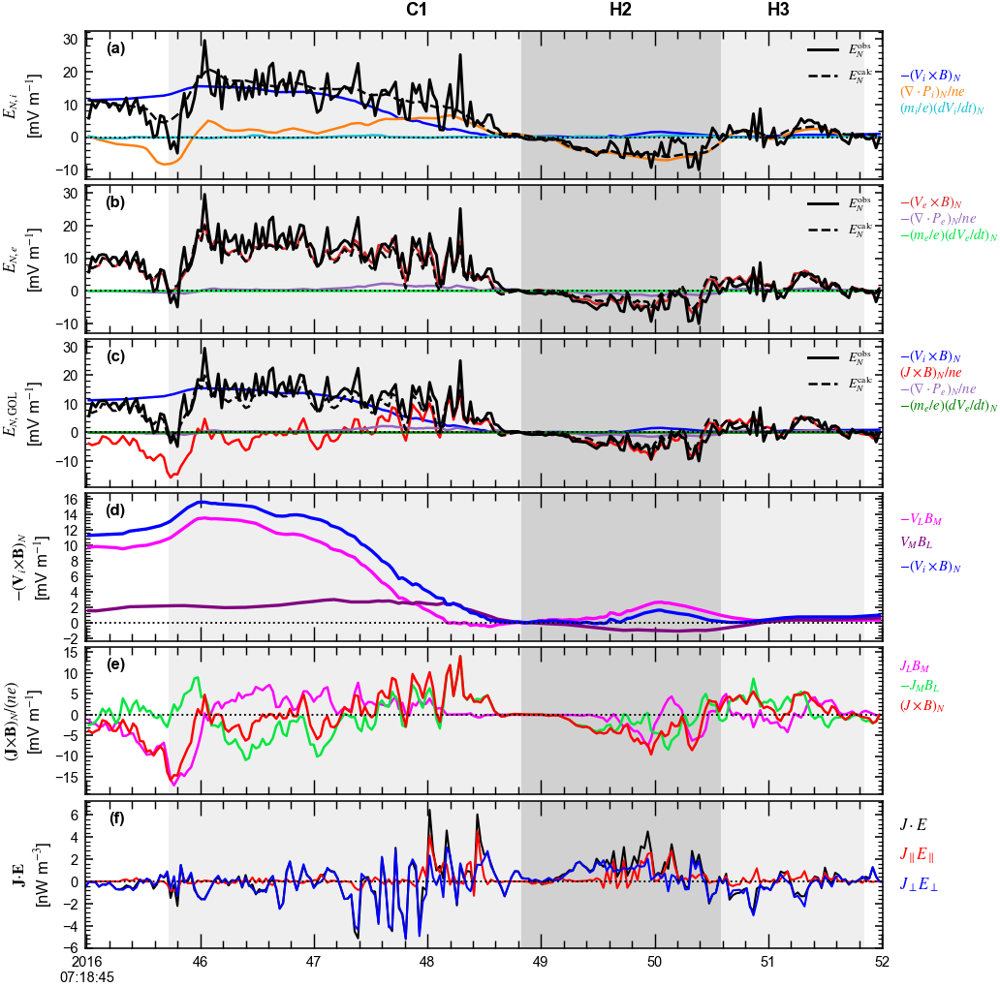

In [257]:
import os
import logging
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D

logging.getLogger("fontTools").setLevel(logging.WARNING)
plt.set_loglevel("warning")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.linewidth": 0.75,
    "lines.linewidth": 0.9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ==========================================
# Fixed spacecraft
# ==========================================
sc = "mms4"

def add_color_text_legend(ax, labels, colors, x=1.02, y0=0.88, dy=0.11, fs=7,
                          add_obs_calc=False):
    """
    Place coloured term labels on the right side of the panel.
    Optionally also place E_N obs / calc underneath them.
    """
    for i, (lab, c) in enumerate(zip(labels, colors)):
        ax.text(
            x, y0 - i * dy, lab,
            transform=ax.transAxes,
            color=c, fontsize=fs, style="italic",
            va="center", ha="left", clip_on=False
        )

    if add_obs_calc:
        # Position just below the last coloured label
        y_obs = y0 - len(labels) * dy - 0.04
        ax.text(x, y_obs, r"$E_N^{\rm obs}$", transform=ax.transAxes,
                color="k", fontsize=fs, style="italic", va="center", ha="left", clip_on=False)
        ax.text(x, y_obs - dy, r"$E_N^{\rm calc}$", transform=ax.transAxes,
                color="k", fontsize=fs, style="italic", va="center", ha="left", clip_on=False)
def plot_ohms_4panels_for_mms3(
    sc,
    times_dict,
    hall,
    df_all,
    output_folder,
    taistarttime,
    bm_cross=None,
    shaded_interval=None
):
    """
    6-panel Ohm's-law figure optimised for GRL.
    Solid black = E_N observed, dashed black = E_N calculated.
    Zero line is dotted.
    """
    t1, t2 = times_dict[sc]

    fig, axs = plt.subplots(
        6, 1,
        figsize=(7.08, 8.2),          # GRL full-page width
        sharex=True,
        gridspec_kw={"hspace": 0.04}
    )

    # Common observed EN
    E_obs = hall[sc].lmn_e.sel(LMN=2, time=slice(t1, t2))

    # ==========================================================
    # 1) Ion momentum equation(
    # ==========================================================
    ion_terms   = ["vib", "iDivP", "dvidt"]
    ion_colors  = ["b", "tab:orange", "tab:cyan"]
    ion_labels  = [
        r"$-(V_i\times B)_N$",
        r"$(\nabla\cdot P_i)_N/ne$",
        r"$(m_i/e)(dV_i/dt)_N$"
    ]

    ax = axs[0]
    for term, c in zip(ion_terms, ion_colors):
        ax.plot(
            hall[sc][term].time.sel(time=slice(t1, t2)),
            hall[sc][term].sel(LMN=2, time=slice(t1, t2)),
            color=c, lw=1.2
        )

    E_calc_ion = hall[sc]["vib"] + hall[sc]["iDivP"] - hall[sc]["dvidt"]
    ax.plot(E_obs.time, E_obs, color="k", lw=1.4)                    # solid = observed
    ax.plot(
        E_calc_ion.sel(LMN=2, time=slice(t1, t2)).time,
        E_calc_ion.sel(LMN=2, time=slice(t1, t2)),
        color="k", lw=1.2, ls="--"                                     # dashed = calculated
    )

    ax.set_ylabel(r"$E_{N,i}$" + "\n" + r"[mV m$^{-1}$]", fontsize=8)
    ax.axhline(0, c="k", ls=":", lw=0.9)                               # dotted zero line

    add_color_text_legend(ax, ion_labels, ion_colors, y0=0.7)

    legend_elements = [
        Line2D([0], [0], color="k", lw=1.4, ls="-",  label=r"$E_N^{\rm obs}$"),
        Line2D([0], [0], color="k", lw=1.2, ls="--", label=r"$E_N^{\rm calc}$"),
    ]
    ax.legend(handles=legend_elements, loc="upper right", fontsize=6.5,
              frameon=False, handlelength=2.2, borderpad=0.2)

    # ==========================================================
    # 2) Electron momentum equation
    # ==========================================================
    electron_terms  = ["veb", "eDivP", "dvedt"]
    electron_colors = ["tab:red", "tab:purple", (0/255, 230/255, 64/255)]
    electron_labels = [
        r"$-(V_e\times B)_N$",
        r"$-(\nabla\cdot P_e)_N/ne$",
        r"$-(m_e/e)(dV_e/dt)_N$"
    ]

    ax = axs[1]
    for term, c in zip(electron_terms, electron_colors):
        ax.plot(
            hall[sc][term].time.sel(time=slice(t1, t2)),
            hall[sc][term].sel(LMN=2, time=slice(t1, t2)),
            color=c, lw=1.2
        )

    E_calc_e = hall[sc]["veb"] - hall[sc]["eDivP"] - hall[sc]["dvedt"]
    ax.plot(E_obs.time, E_obs, color="k", lw=1.4)
    ax.plot(
        E_calc_e.sel(LMN=2, time=slice(t1, t2)).time,
        E_calc_e.sel(LMN=2, time=slice(t1, t2)),
        color="k", lw=1.2, ls="--"
    )

    ax.set_ylabel(r"$E_{N,e}$" + "\n" + r"[mV m$^{-1}$]", fontsize=8)
    ax.axhline(0, c="k", ls=":", lw=0.9)

    add_color_text_legend(ax, electron_labels, electron_colors, y0=0.88)

    legend_elements = [
        Line2D([0], [0], color="k", lw=1.4, ls="-",  label=r"$E_N^{\rm obs}$"),
        Line2D([0], [0], color="k", lw=1.2, ls="--", label=r"$E_N^{\rm calc}$"),
    ]
    ax.legend(handles=legend_elements, loc="upper right", fontsize=6.5,
              frameon=False, handlelength=2.2, borderpad=0.2)

    # ==========================================================
    # 3) Generalized Ohm's law
    # ==========================================================
    macro_terms  = ["vib", "jxb", "eDivP", "dvedt"]
    macro_colors = ["b", "r", "tab:purple", "g"]
    macro_labels = [
        r"$-(V_i\times B)_N$",
        r"$(J\times B)_N/ne$",
        r"$-(\nabla\cdot P_e)_N/ne$",
        r"$-(m_e/e)(dV_e/dt)_N$"
    ]

    ax = axs[2]
    for term, c in zip(macro_terms, macro_colors):
        ax.plot(
            hall[sc][term].time.sel(time=slice(t1, t2)),
            hall[sc][term].sel(LMN=2, time=slice(t1, t2)),
            color=c, lw=1.2
        )

    E_calc_macro = (
        hall[sc]["vib"] + hall[sc]["jxb"]
        - hall[sc]["eDivP"] - hall[sc]["dvedt"]
    )
    ax.plot(E_obs.time, E_obs, color="k", lw=1.4)
    ax.plot(
        E_calc_macro.sel(LMN=2, time=slice(t1, t2)).time,
        E_calc_macro.sel(LMN=2, time=slice(t1, t2)),
        color="k", lw=1.2, ls="--"
    )

    ax.set_ylabel(r"$E_{N,\mathrm{GOL}}$" + "\n" + r"[mV m$^{-1}$]", fontsize=8)
    ax.axhline(0, c="k", ls=":", lw=0.9)

    add_color_text_legend(ax, macro_labels, macro_colors, y0=0.88)

    legend_elements = [
        Line2D([0], [0], color="k", lw=1.4, ls="-",  label=r"$E_N^{\rm obs}$"),
        Line2D([0], [0], color="k", lw=1.2, ls="--", label=r"$E_N^{\rm calc}$"),
    ]
    ax.legend(handles=legend_elements, loc="upper right", fontsize=6.5,
              frameon=False, handlelength=2.2, borderpad=0.2)

    # ==========================================================
    # 4) Ion convective cross terms
    # ==========================================================
    ax = axs[3]
    B_L   = hall[sc].lmn_b.sel(LMN=0, time=slice(t1, t2))
    BM_hm = hall[sc].lmn_b.sel(LMN=1, time=slice(t1, t2))
    V_L   = hall[sc].lmn_vi.sel(LMN=0, time=slice(t1, t2))
    V_M   = hall[sc].lmn_vi.sel(LMN=1, time=slice(t1, t2))

    VL_BM = -V_L * BM_hm * 1e-3
    VM_BL =  V_M * B_L   * 1e-3
    E_N   = hall[sc]["vib"].sel(LMN=2, time=slice(t1, t2))

    ax.plot(VL_BM.time, VL_BM, c="magenta", lw=1.6)
    ax.plot(VM_BL.time, VM_BL, c="purple",  lw=1.6)
    ax.plot(E_N.time,   E_N,   c="b",       lw=1.6)
    ax.axhline(0, color="k", ls=":", lw=0.9)

    ax.set_ylabel(
        r"$-(\mathbf{V}_i\!\times\!\mathbf{B})_N$" + "\n" + r"[mV m$^{-1}$]",
        fontsize=8
    )
    add_color_text_legend(
        ax,
        [r"$-V_LB_M$", r"$V_MB_L$", r"$-(V_i\times B)_N$"],
        ["magenta", "purple", "b"],
        y0=0.82, dy=0.16
    )

    # ==========================================================
    # 5) Hall J×B cross terms
    # ==========================================================
    ax = axs[4]
    BL    = hall[sc].lmn_b.sel(LMN=0, time=slice(t1, t2))
    BM_hm = hall[sc].lmn_b.sel(LMN=1, time=slice(t1, t2))
    JL    = hall[sc].lmn_j.sel(LMN=0, time=slice(t1, t2))
    JM    = hall[sc].lmn_j.sel(LMN=1, time=slice(t1, t2))

    JL_BM =  JL * BM_hm * 1e-21 / (ni * q_e)
    JM_BL = -JM * BL    * 1e-21 / (ni * q_e)
    JxB_N = hall[sc]["jxb"].sel(LMN=2, time=slice(t1, t2))

    ax.plot(JL_BM.time, JL_BM, c="magenta", lw=1.2)
    ax.plot(JM_BL.time, JM_BL, c=(0/255, 230/255, 64/255), lw=1.2)
    ax.plot(JxB_N.time, JxB_N, c="r", lw=1.2)
    ax.axhline(0, color="k", ls=":", lw=0.9)

    ax.set_ylabel(
        r"$(\mathbf{J}\!\times\!\mathbf{B})_N/(ne)$" + "\n" + r"[mV m$^{-1}$]",
        fontsize=8
    )
    add_color_text_legend(
        ax,
        [r"$J_LB_M$", r"$-J_MB_L$", r"$(J\times B)_N$"],
        ["magenta", (0/255, 230/255, 64/255), "r"],
        y0=0.86, dy=0.13
    )

    # ==========================================================
    # 6) J·E
    # ==========================================================
    ax = axs[5]
    ax.plot(
        hall[sc].jdote1.time.sel(time=slice(del3, del4)),
        hall[sc].jdote1.sel(time=slice(del3, del4)),
        c="k", lw=1
    )
    ax.plot(
        hall[sc].jdote_para1.time.sel(time=slice(del3, del4)),
        hall[sc].jdote_para1.sel(time=slice(del3, del4)),
        c="r", lw=1
    )
    ax.plot(
        hall[sc].jdote_perp1.time.sel(time=slice(del3, del4)),
        hall[sc].jdote_perp1.sel(time=slice(del3, del4)),
        c="b", lw=1
    )
    ax.axhline(0, c="k", ls=":", lw=0.9)

    ax.set_ylabel(r"$\mathbf{J}\!\cdot\!\mathbf{E}$" + "\n" + r"[nW m$^{-3}$]", fontsize=8)
    ax.annotate(r"$\mathit{J\cdot E}$", xy=(1.02, 0.80), xycoords="axes fraction",
                fontsize=8, color="k", style="italic", ha="left", clip_on=False)
    ax.annotate(r"$\mathit{J_{\parallel}E_{\parallel}}$", xy=(1.02, 0.60), xycoords="axes fraction",
                fontsize=8, color="r", style="italic", ha="left", clip_on=False)
    ax.annotate(r"$\mathit{J_{\perp}E_{\perp}}$", xy=(1.02, 0.40), xycoords="axes fraction",
                fontsize=8, color="b", style="italic", ha="left", clip_on=False)

    # ==========================================================
    # Common formatting + shaded regions
    # ==========================================================
    for ax in axs:
        ax.set_xlim(
            hall[sc].lmn_b.time.sel(time=t1, method="nearest"),
            hall[sc].lmn_b.time.sel(time=t2, method="nearest")
        )
        ax.set_xticks(xticks(t1, t2)[0])
        ax.set_xticks(xticks(t1, t2)[1], minor=True)
        ax.set_xticklabels(xticks(t1, t2)[2], rotation=0, fontsize=7)

        ax.tick_params(axis="x", which="major", labelsize=7, length=7, width=0.7,
                       direction="in", top=True, bottom=True)
        ax.tick_params(axis="x", which="minor", length=4, width=0.7,
                       direction="in", top=True, bottom=True)

        if ax.get_yscale() != "log":
            ymin, ymax = ax.get_ylim()
            data_min, data_max = sorted((ymin, ymax))
            data_range = data_max - data_min
            pad = 0.02 * data_range if data_range > 0 else 0.5
            ylow  = data_min - pad
            yhigh = data_max + pad
            span  = yhigh - ylow

            allowed_steps = np.array([2, 5, 10, 50, 100, 500, 1000], dtype=float)
            target_step = span / 6.0
            major_step = allowed_steps[np.argmin(np.abs(allowed_steps - target_step))]

            ax.set_ylim(ylow, yhigh)
            ax.yaxis.set_major_locator(MultipleLocator(major_step))
            ax.yaxis.set_minor_locator(MultipleLocator(major_step / 5.0))

        ax.tick_params(axis="y", which="major", direction="in", left=True, right=True,
                       width=0.75, length=4, labelsize=7)
        ax.tick_params(axis="y", which="minor", direction="in", left=True, right=True,
                       width=0.6, length=2.5, labelsize=7)
        ax.grid(False)

        # Shaded regions
        ax.axvspan(zero_times[2], zero_times[7],  color="#D9D9D9", alpha=0.4, lw=0, zorder=-2)
        ax.axvspan(zero_times[4], zero_times[7],  color="#BDBDBD", alpha=0.6, lw=0, zorder=-2)
        ax.axvspan(zero_times[7], zero_times[22], color="#D9D9D9", alpha=0.4, lw=0, zorder=-2)

    # ==========================================================
    # Region labels above top panel
    # ==========================================================
    ax0 = axs[0]
    y_label = 1.08

    ax0.text(
        zero_times[2] + 0.45*(zero_times[7]-zero_times[2]),
        y_label, "C1",
        transform=ax0.get_xaxis_transform(),
        ha="center", va="bottom",
        fontsize=9, fontweight="bold", color="k",
        clip_on=False, zorder=30
    )
    ax0.text(
        zero_times[4] + 0.50*(zero_times[7]-zero_times[4]),
        y_label, "H2",
        transform=ax0.get_xaxis_transform(),
        ha="center", va="bottom",
        fontsize=9, fontweight="bold", color="k",
        clip_on=False, zorder=30
    )
    ax0.text(
        zero_times[7] + 0.40*(zero_times[22]-zero_times[7]),
        y_label, "H3",
        transform=ax0.get_xaxis_transform(),
        ha="center", va="bottom",
        fontsize=9, fontweight="bold", color="k",
        clip_on=False, zorder=30
    )

    # Panel letters
    for panel_ax, panel_label in zip(axs, "abcdef"):
        panel_ax.text(
            0.05, 0.93, f"({panel_label})",
            transform=panel_ax.transAxes,
            ha="right", va="top",
            fontsize=8, fontweight="bold",
            color="black", zorder=30
        )

    plt.tight_layout(rect=[0.0, 0.0, 0.79, 1.0], pad=0.25)
    plt.subplots_adjust(hspace=0)

    # Save
    os.makedirs(output_folder, exist_ok=True)
    stem = os.path.join(output_folder, f"{taistarttime}_{sc}_Ohm_GRL")
    save_options = dict(bbox_inches="tight", pad_inches=0.02, facecolor="white")

    fig.savefig(stem + ".pdf",  format="pdf",  **save_options)
    fig.savefig(stem + ".png",  format="png",  dpi=1000, **save_options)
    fig.savefig(stem + ".tiff", format="tiff", dpi=1000,
                pil_kwargs={"compression": "tiff_lzw"}, **save_options)
    plt.show()


# ------------------------------------------------------------------
# Call the function
# ------------------------------------------------------------------
plot_ohms_4panels_for_mms3(
    sc=sc,
    times_dict=times_dict,
    hall=hall,
    df_all=df_all,
    output_folder=output_folder,
    taistarttime=taistarttime,
    bm_cross=bm_cross if "bm_cross" in globals() else None,
    shaded_interval=None,
)

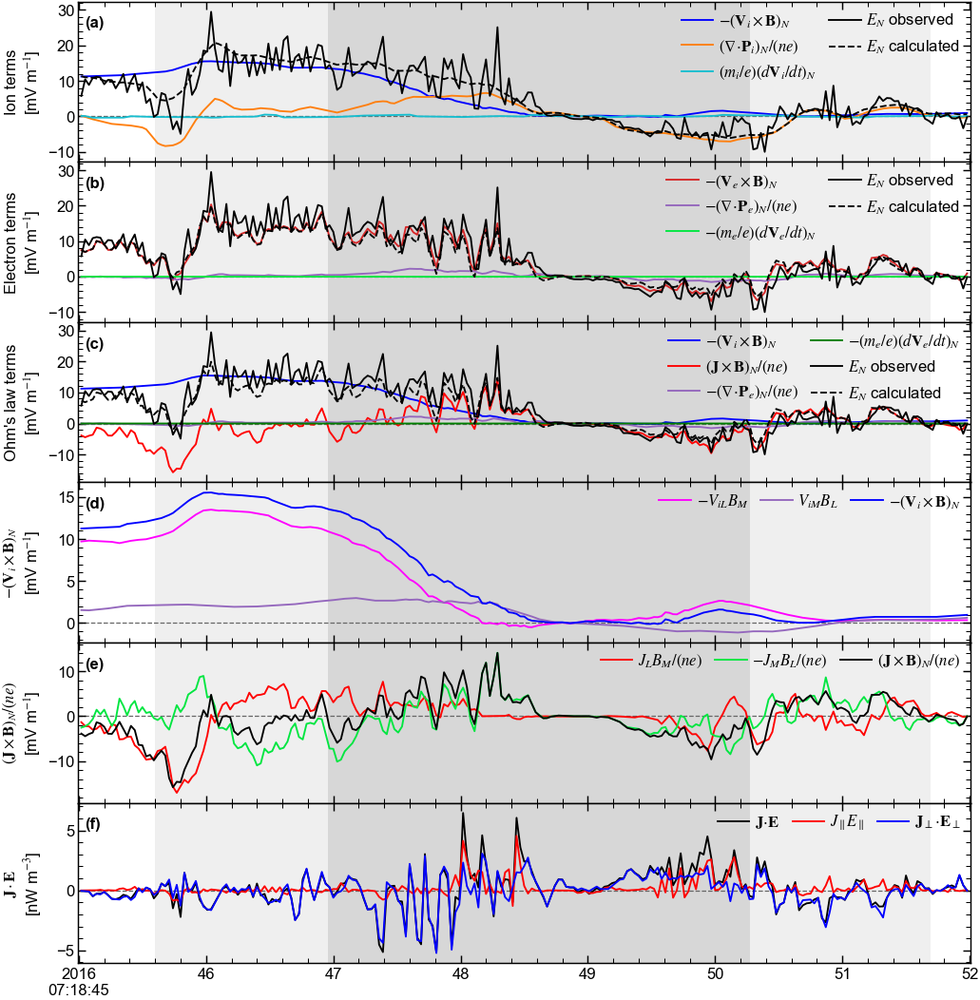

In [258]:
"""GRL-ready six-panel MMS4 Ohm's-law figure.

The original top LMN electric-field panel has been removed.  This cell assumes
that ``hall``, ``find``, and ``xticks`` already exist in the notebook.
"""

from pathlib import Path
import string
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


# GRL-friendly typography and line weights.  Keep text editable in PDF.
FS_LABEL = 8.0
FS_XTICK = 8.0
FS_YTICK = 8.0
FS_LEGEND = 8.0
FS_PANEL = 8.0
DATA_LW = 0.9
GUIDE_LW = 0.6

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": FS_LABEL,
    "xtick.labelsize": FS_XTICK,
    "ytick.labelsize": FS_YTICK,
    "legend.fontsize": FS_LEGEND,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.transparent": False,
})

# Exact colors from the user's original plotting code.
C = {
    "blue": "b", "orange": "tab:orange", "cyan": "tab:cyan",
    "tab_red": "tab:red", "red": "r", "purple": "tab:purple",
    "green": "g", "bright_green": (0 / 255, 230 / 255, 64 / 255),
    "magenta": "magenta", "black": "k", "gray": "#666666",
}


def _component(da, component, t1, t2):
    """Select one LMN component and the common plotting interval."""
    return da.sel(LMN=component, time=slice(t1, t2))


def _markers(hall_sc, t1, t2):
    """Return BL=0 and the left maximum, center minimum, right maximum of BM."""
    bl0 = find(hall_sc.lmn_b, LMN=0, d1=t1, d2=t2)[0]
    bm = _component(hall_sc.lmn_b, 1, t1, t2)
    left = bm.sel(time=slice(t1, bl0))
    right = bm.sel(time=slice(bl0, t2))
    return (
        bl0,
        left.time.isel(time=int(np.nanargmax(left.values))),
        bm.time.isel(time=int(np.nanargmin(bm.values))),
        right.time.isel(time=int(np.nanargmax(right.values))),
    )


def _plot_set(ax, series, labels, colors, styles=None, widths=None):
    styles = styles or ["-"] * len(series)
    widths = widths or [1.0] * len(series)
    for y, label, color, style, width in zip(series, labels, colors, styles, widths):
        ax.plot(y.time, y, label=label, color=color, ls=style, lw=width)


def _apply_original_y_ticks(ax):
    """Reproduce the y-axis scaling/tick algorithm in the supplied code."""
    if ax.get_yscale() == "log":
        return

    ymin, ymax = ax.get_ylim()
    data_min, data_max = sorted((ymin, ymax))
    data_range = data_max - data_min
    pad = 0.02 * data_range if data_range > 0 else 0.5
    ylow, yhigh = data_min - pad, data_max + pad
    span = yhigh - ylow

    allowed_steps = np.array(
        [2, 5, 10, 50, 100, 500, 1000], dtype=float
    )
    # Fewer labeled y ticks allow AGU's 8-point final-size lettering.
    target_step = span / 3.0
    major_step = allowed_steps[
        np.argmin(np.abs(allowed_steps - target_step))
    ]

    ax.set_ylim(ylow, yhigh)
    ax.yaxis.set_major_locator(MultipleLocator(major_step))
    ax.yaxis.set_minor_locator(MultipleLocator(major_step / 5.0))


def plot_ohms_grl(
    sc,
    times_dict,
    hall,
    ion_density,
    output_folder,
    file_stem,
    shaded_interval=None,
    bm_cross=None,
    show_feature_markers=True,
):
    """Create the six-panel GRL figure.

    Parameters
    ----------
    sc : str
        Spacecraft key, normally ``"mms4"``.
    times_dict : dict
        ``{sc: (start_time, end_time)}``.
    hall : dict
        Existing analysis container holding LMN fields and Ohm's-law terms.
    ion_density : xarray.DataArray or float
        Ion density in cm^-3, time aligned with current when it is a DataArray.
    output_folder : str or pathlib.Path
        Destination for vector PDF and 600-dpi PNG.
    file_stem : str
        Output name without extension.
    shaded_interval : tuple, optional
        ``(start, end)`` for the Hall-region shading; e.g. ``(zero_times[4],
        zero_times[7])``.  Use ``None`` for no shading.
    """
    hs = hall[sc]
    t1, t2 = times_dict[sc]
    bl0, bm_left, bm_min, bm_right = _markers(hs, t1, t2)
    q_e = 1.602176634e-19

    # Observed EN is intentionally retained in the balance panels although the
    # former standalone electric-field panel has been removed.
    e_obs = _component(hs.lmn_e, 2, t1, t2)
    ion_calc = hs["vib"] + hs["iDivP"] - hs["dvidt"]
    elec_calc = hs["veb"] - hs["eDivP"] - hs["dvedt"]
    macro_calc = hs["vib"] + hs["jxb"] - hs["eDivP"] - hs["dvedt"]

    # 7.08 in is AGU/GRL double-column width; PDF is the publication master.
    fig, axs = plt.subplots(6, 1, figsize=(7.08, 7.25), sharex=True,
                            gridspec_kw={"hspace": 0})

    _plot_set(
        axs[0],
        [_component(hs[k], 2, t1, t2) for k in ("vib", "iDivP", "dvidt")]
        + [e_obs, _component(ion_calc, 2, t1, t2)],
        [r"$-(\mathbf{V}_i\times\mathbf{B})_N$", r"$(\nabla\!\cdot\!\mathbf{P}_i)_N/(ne)$",
         r"$(m_i/e)(d\mathbf{V}_i/dt)_N$", r"$E_N$ observed", r"$E_N$ calculated"],
        [C["blue"], C["orange"], C["cyan"], C["black"], C["black"]],
        ["-", "-", "-", "-", "--"], [1, 1, 1, 1.25, 1.1],
    )
    

    _plot_set(
        axs[1],
        [_component(hs[k], 2, t1, t2) for k in ("veb", "eDivP", "dvedt")]
        + [e_obs, _component(elec_calc, 2, t1, t2)],
        [r"$-(\mathbf{V}_e\times\mathbf{B})_N$", r"$-(\nabla\!\cdot\!\mathbf{P}_e)_N/(ne)$",
         r"$-(m_e/e)(d\mathbf{V}_e/dt)_N$", r"$E_N$ observed", r"$E_N$ calculated"],
        [C["tab_red"], C["purple"], C["bright_green"], C["black"], C["black"]],
        ["-", "-", "-", "-", "--"], [1, 1, 1, 1.25, 1.1],
    )
  

    _plot_set(
        axs[2],
        [_component(hs[k], 2, t1, t2) for k in ("vib", "jxb", "eDivP", "dvedt")]
        + [e_obs, _component(macro_calc, 2, t1, t2)],
        [r"$-(\mathbf{V}_i\times\mathbf{B})_N$", r"$(\mathbf{J}\times\mathbf{B})_N/(ne)$",
         r"$-(\nabla\!\cdot\!\mathbf{P}_e)_N/(ne)$", r"$-(m_e/e)(d\mathbf{V}_e/dt)_N$",
         r"$E_N$ observed", r"$E_N$ calculated"],
        [C["blue"], C["red"], C["purple"], C["green"], C["black"], C["black"]],
        ["-", "-", "-", "-", "-", "--"], [1, 1, 1, 1, 1.25, 1.1],
    )
   

    bl = _component(hs.lmn_b, 0, t1, t2)
    bm = _component(hs.lmn_b, 1, t1, t2)
    vl = _component(hs.lmn_vi, 0, t1, t2)
    vm = _component(hs.lmn_vi, 1, t1, t2)
    _plot_set(
        axs[3], [-vl * bm * 1e-3, vm * bl * 1e-3, _component(hs["vib"], 2, t1, t2)],
        [r"$-V_{iL}B_M$", r"$V_{iM}B_L$", r"$-(\mathbf{V}_i\times\mathbf{B})_N$"],
        [C["magenta"], C["purple"], C["blue"]], widths=[1, 1, 1.25],
    )
    

    jl = _component(hs.lmn_j, 0, t1, t2)
    jm = _component(hs.lmn_j, 1, t1, t2)
    # J in nA m^-2, B in nT, n in cm^-3 -> mV m^-1.
    jlbm = jl * bm * 1e-21 / (ion_density * q_e)
    jmbl = -jm * bl * 1e-21 / (ion_density * q_e)
    _plot_set(
        axs[4], [jlbm, jmbl, _component(hs["jxb"], 2, t1, t2)],
        [r"$J_LB_M/(ne)$", r"$-J_MB_L/(ne)$", r"$(\mathbf{J}\times\mathbf{B})_N/(ne)$"],
        [C["red"], C["bright_green"], C["black"]], widths=[1, 1, 1.25],
    )
    axs[4].set_ylabel("Hall term\n[mV m$^{-1}$]")

    _plot_set(
        axs[5], [hs[k].sel(time=slice(t1, t2)) for k in
                 ("jdote1", "jdote_para1", "jdote_perp1")],
        [r"$\mathbf{J}\!\cdot\!\mathbf{E}$", r"$J_{\parallel}E_{\parallel}$",
         r"$\mathbf{J}_{\perp}\!\cdot\!\mathbf{E}_{\perp}$"],
        [C["black"], C["red"], C["blue"]], widths=[1.25, 1, 1],
    )
  
    major_ticks, minor_ticks, tick_labels = xticks(t1, t2)
    for i, ax in enumerate(axs):
        # Make every scientific curve identical in width before adding guides.
        for data_line in ax.lines:
            data_line.set_linewidth(DATA_LW)

        ax.axhline(0, color=C["gray"], lw=GUIDE_LW, ls="--", zorder=0)

        # Three overview-matched Hall regions when zero crossings are supplied.
        if bm_cross is not None:
            x1 = bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[0]
            x2 = bm_cross[sc]["left_two"]["zero_crossing_time"].iloc[1]
            x3 = bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[0]
            x4 = bm_cross[sc]["right_two"]["zero_crossing_time"].iloc[1]
            ax.axvspan(x1, x2, color="#D9D9D9", alpha=0.4, lw=0, zorder=-2)
            ax.axvspan(x2, x3, color="#BDBDBD", alpha=0.6, lw=0, zorder=-2)
            ax.axvspan(x3, x4, color="#D9D9D9", alpha=0.4, lw=0, zorder=-2)
        elif shaded_interval is not None:
            ax.axvspan(*shaded_interval, color="#D9D9D9", alpha=0.55,
                       lw=0, zorder=-2)

        # Same event markers as the overview: red BL=0 and three pink BM extrema.
        #ax.axvline(bl0.values, color="r", lw=GUIDE_LW, ls="--", zorder=2)
        #if show_feature_markers:
            #for marker in (bm_left, bm_min, bm_right):
                #ax.axvline(marker.values, color="#FF1493", lw=GUIDE_LW,
                           #ls="--", zorder=2)
        ax.set_xlim(hs.lmn_b.time.sel(time=t1, method="nearest"),
                    hs.lmn_b.time.sel(time=t2, method="nearest"))
        ax.set_xticks(major_ticks)
        ax.set_xticks(minor_ticks, minor=True)
        ax.set_xticklabels(tick_labels)
        _apply_original_y_ticks(ax)

        # Original x- and y-tick geometry; label sizes remain GRL appropriate.
        ax.tick_params(axis="x", which="major", direction="in", top=True,
                       bottom=True, length=4, width=0.7,
                       labelsize=FS_XTICK, pad=2)
        ax.tick_params(axis="x", which="minor", direction="in", top=True,
                       bottom=True, length=2.5, width=0.5)
        ax.tick_params(axis="y", which="major", direction="in", left=True,
                       right=True, length=4, width=0.7,
                       labelsize=FS_YTICK, pad=1.5)
        ax.tick_params(axis="y", which="minor", direction="in", left=True,
                       right=True, length=2.5, width=0.5)
        ax.text(0.008, 0.91, f"({string.ascii_lowercase[i]})",
                transform=ax.transAxes, ha="left", va="top",
                fontsize=FS_PANEL, fontweight="bold", zorder=20)
        ax.legend(loc="upper right", ncol=2 if i < 3 else 3,
                  frameon=False, handlelength=2.0, columnspacing=0.8,
                  handletextpad=0.35, borderaxespad=0.25)
        ax.yaxis.label.set_size(FS_LABEL)
        ax.yaxis.labelpad = 2.0
    axs[0].set_ylabel("Ion terms\n[mV m$^{-1}$]")
    axs[1].set_ylabel("Electron terms\n[mV m$^{-1}$]")
    axs[2].set_ylabel("Ohm's law terms\n[mV m$^{-1}$]")

    axs[3].set_ylabel(
        r"$-(\mathbf{V}_i\times\mathbf{B})_N$"
        "\n[mV m$^{-1}$]"
    )

    axs[4].set_ylabel(
        r"$(\mathbf{J}\times\mathbf{B})_N/(ne)$"
        "\n[mV m$^{-1}$]"
        )

    axs[5].set_ylabel(
        r"$\mathbf{J}\cdot\mathbf{E}$"
        "\n[nW m$^{-3}$]"
    )
    #axs[-1].set_xlabel("Time (UTC)")
    fig.align_ylabels(axs)
    fig.subplots_adjust(left=0.105, right=0.990, bottom=0.060,
                        top=0.990, hspace=0)

    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)
    pdf_path = output_folder / f"{file_stem}_Ohm_GRL.pdf"
    png_path = output_folder / f"{file_stem}_Ohm_GRL.png"
    # Preserve the exact 7.08 x 7.25 inch physical dimensions.
    fig.savefig(pdf_path, facecolor="white")
    fig.savefig(png_path, dpi=600, facecolor="white")
    plt.show()
    return fig, axs, pdf_path, png_path


# Example call -- edit only these values for your event.
fig, axs, pdf_path, png_path = plot_ohms_grl(
     sc="mms4",
     times_dict=times_dict,
     hall=hall,
     ion_density=ni,
     output_folder=output_folder,
     file_stem=taistarttime,
     bm_cross=bm_cross,
     shaded_interval=None,
 )



In [259]:
# -----------------------------
# Save all MMS spacecraft to one XLSX file
# -----------------------------
sc_list = ["mms1", "mms2", "mms3", "mms4"]

os.makedirs(output_folder, exist_ok=True)

output_xlsx = os.path.join(
    output_folder,
    f"{taistarttime}_all_mms_plot_data.xlsx"
)

failed = []

with pd.ExcelWriter(output_xlsx, engine="openpyxl") as writer:

    for sc_name in sc_list:
        try:
            print(f"Collecting data for {sc_name}...")

            df = collect_plot_data_as_dataframe(
                sc=sc_name,
                times_dict=times_dict,
                hall=hall,
                df_all=df_all,
                ni=ni,
                q_e=q_e
            )

            df.to_excel(
                writer,
                sheet_name=sc_name,
                index=False
            )

            print(f"Stored {sc_name}: {df.shape[0]} rows, {df.shape[1]} columns")

        except Exception as e:
            print(f"FAILED for {sc_name}: {e}")
            failed.append({
                "spacecraft": sc_name,
                "error": str(e)
            })

    if failed:
        pd.DataFrame(failed).to_excel(
            writer,
            sheet_name="failed_spacecraft",
            index=False
        )

print("Excel file saved to:")
print(output_xlsx)

print("File exists:", os.path.exists(output_xlsx))

Stored mms1: 233 rows, 22 columns
Stored mms2: 233 rows, 22 columns
Stored mms3: 233 rows, 22 columns
Stored mms4: 233 rows, 22 columns
Excel file saved to:
D:\hallsim\MMS\pydata\trial\Plots\20160122071714\20160122071714_all_mms_plot_data.xlsx
File exists: True


BM points = 300
JL points = 300
time points = 300


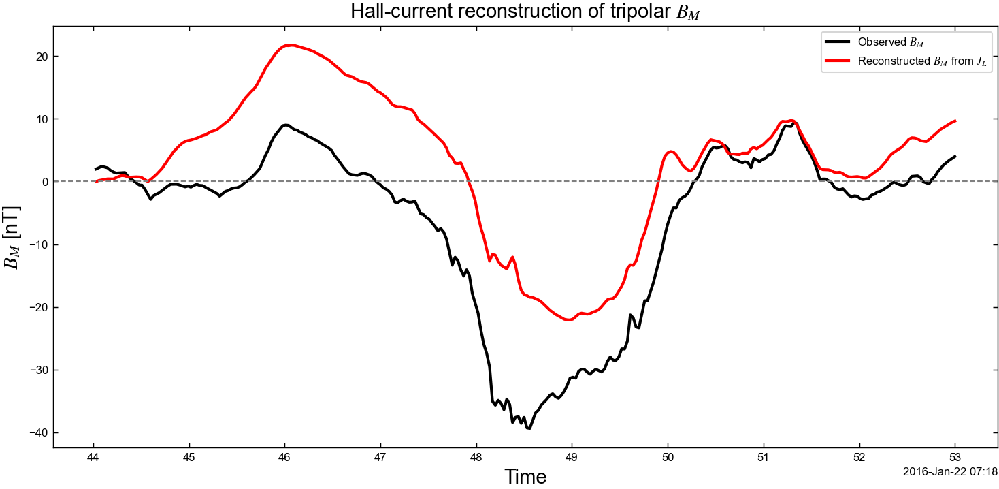

In [260]:
import numpy as np
import matplotlib.pyplot as plt


# =====================================================
# Hall current reconstruction of BM
# =====================================================

mu0 = 4*np.pi*1e-7


# -----------------------------
# Select data interval
# -----------------------------

B_g = df_all.loc[sc, "$B_g$"]

B = hall[sc].lmn_b.sel(time=slice(del3, del4))
B_hm = B - res_all[sc]['Bg_linear']
bg = B.sel(LMN=1) - B_g
bl = B.sel(LMN=0)
BM = B_hm.sel(LMN=1)          # B_M - B_g


JL = (
    (hall[sc]
    .lmn_j
    .sel(
        LMN=0,
        time=slice(del3, del4)
    ))
)


# remove extra dimensions
BM = BM.squeeze()
JL = JL.squeeze()



# -----------------------------
# Convert arrays
# -----------------------------

BM_array = np.asarray(
    BM.values,
    dtype=float
)


JL_array = np.asarray(
    JL.values,
    dtype=float
)



# -----------------------------
# Time in seconds
# relative time only
# -----------------------------

time = (
    JL.time.values
    .astype("datetime64[ns]")
    .astype(np.int64)
    /1e9
)


time = time-time[0]


dt = np.gradient(time)



print("BM points =",len(BM_array))
print("JL points =",len(JL_array))
print("time points =",len(time))


# -----------------------------
# Interpolate JL to BM time
# if needed
# -----------------------------

if len(BM_array)!=len(JL_array):

    JL_array = np.interp(
        np.arange(len(BM_array)),
        np.linspace(
            0,
            len(BM_array)-1,
            len(JL_array)
        ),
        JL_array
    )


# -----------------------------
# Structure velocity
# -----------------------------
# replace with MMS timing velocity later

VN = 46.8*1000   # m/s
#VN = 41.5*1000 


# -----------------------------
# Convert current
# nA/m2 --> A/m2
# -----------------------------

JL_A = JL_array*1e-9



# -----------------------------
# Integrate Ampere law
# -----------------------------

BM_rec = (
    -mu0 *
    np.cumsum(
        JL_A *
        VN *
        dt
    )
)



# Tesla -> nT

BM_rec = BM_rec*1e9



# remove arbitrary offset

BM_rec = BM_rec - BM_rec[0]



# -----------------------------
# Plot
# -----------------------------

plt.figure(figsize=(10,5))


plt.plot(
    BM.time,
    BM,
    color="black",
    lw=2,
    label="Observed $B_M$"
)


plt.plot(
    BM.time,
    BM_rec,
    color="red",
    lw=2,
    label="Reconstructed $B_M$ from $J_L$"
)


plt.axhline(
    0,
    color="gray",
    ls="--"
)


plt.ylabel(
    "$B_M$ [nT]",
    fontsize=14
)

plt.xlabel(
    "Time",
    fontsize=14
)


plt.title(
    "Hall-current reconstruction of tripolar $B_M$",
    fontsize=14
)


plt.legend()

plt.tight_layout()

plt.show()